# UC-RL Workflow V8 — UC + ED with REVISION

**Structure:**
1. Train 3 UC agents (Q-Learning, DQN, PPO) — binary ON/OFF only
2. Visualise UC decisions independently (before ED)
3. Apply 3 ED methods to each UC agent:
   - Merit-order discrete (0/10/20/.../100% × pmax)
   - Proportional loading discrete (0/10/20/.../100% × pmax)
   - QP solver via scipy.optimize.milp (discrete 10% steps)
4. Compare all 3×3 combinations on 50 test instances

**ED is deterministic — not learned by RL.**
**UC agent only decides ON/OFF. ED decides how much MW.**

In [15]:
from pathlib import Path
import json, gzip, re, pickle, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict, deque
from scipy.optimize import linprog, milp, LinearConstraint, Bounds

try:
    import gymnasium as gym
    from gymnasium import spaces
except Exception:
    import gym
    from gym import spaces

import torch
import torch.nn as nn
import torch.nn.functional as F

plt.style.use('seaborn-v0_8-whitegrid')
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

# Discrete ED levels: 0% to 100% in 10% steps
# ED_LEVELS = np.arange(10, 101, 10) / 100.0  # [0.1, 0.2, ..., 1.0]
ED_LEVELS = [round(x * 0.05, 2) for x in range(1, 21)]  # 0.05, 0.10, ..., 1.00
print(f"ED levels: {[f'{int(l*100)}%' for l in ED_LEVELS]}")

Device: cuda
ED levels: ['5%', '10%', '15%', '20%', '25%', '30%', '35%', '40%', '45%', '50%', '55%', '60%', '65%', '70%', '75%', '80%', '85%', '90%', '95%', '100%']


## 1. Data Loading

In [16]:
def _first_existing(folder, names, required=True):
    folder = Path(folder)
    for n in names:
        if (folder / n).exists(): return folder / n
    if required: raise FileNotFoundError(f"None of {names} in {folder}")
    return None

def _read_json(path):
    path = Path(path)
    opener = gzip.open if path.suffix == ".gz" else open
    with opener(path, "rt", encoding="utf-8") as f: return json.load(f)

def _norm_col(df, name):
    df = df.copy()
    if len(df.columns) > 0 and str(df.columns[0]).lower().startswith("unnamed"):
        df = df.rename(columns={df.columns[0]: name})
    return df

def _load_profiles_and_ic(folder):
    folder = Path(folder)
    if (folder / "profiles.csv").exists():
        return (_norm_col(pd.read_csv(folder/"profiles.csv"),"hour"),
                _norm_col(pd.read_csv(folder/"initial_conditions.csv"),"generator"))
    xls = pd.ExcelFile(folder/"explanatory_variables.xlsx")
    def find(kws):
        for k in kws:
            for s in xls.sheet_names:
                if all(x.lower() in s.lower() for x in k): return s
        return xls.sheet_names[0]
    return (_norm_col(pd.read_excel(folder/"explanatory_variables.xlsx",
                                    sheet_name=find([("profile",)])),"hour"),
            _norm_col(pd.read_excel(folder/"explanatory_variables.xlsx",
                                    sheet_name=find([("initial",)])),"generator"))

def get_profile_series(df):
    def fc(kws):
        for c in df.columns:
            if all(k in str(c).lower() for k in kws): return c
        return None
    d = pd.to_numeric(df[fc(["demand"])],errors="coerce").fillna(0).to_numpy(float)
    w = pd.to_numeric(df[fc(["wind"])],errors="coerce").fillna(0).to_numpy(float) if fc(["wind"]) else np.zeros_like(d)
    s = pd.to_numeric(df[fc(["solar"])],errors="coerce").fillna(0).to_numpy(float) if fc(["solar"]) else np.zeros_like(d)
    return d, w, s, d-w-s

def list_instance_dirs(root):
    dirs = sorted(p for p in Path(root).rglob("instance_*") if p.is_dir())
    if not dirs: raise FileNotFoundError(f"No instance_* under {root}")
    return dirs

def split_instance_dirs(dirs, val_quarters=None):
    val_quarters = val_quarters or set()
    train, valid = [], []
    for d in dirs:
        m = re.match(r"instance_(\d{4})_(Q[1-4])_(\d+)", d.name)
        if m and (int(m.group(1)), m.group(2)) in val_quarters: valid.append(d)
        else: train.append(d)
    return train, valid

def load_single_bundle(d):
    d = Path(d)
    profiles, ic = _load_profiles_and_ic(d)
    inp = _read_json(_first_existing(d,["InputData.json","InputData.json.gz"]))
    outp_path = _first_existing(d,["OutputData.json","OutputData.json.gz"],required=False)
    outp = _read_json(outp_path) if outp_path else None
    return {"instance_id":d.name,"profiles":profiles,"initial_conditions":ic,
            "input_json":inp,"output_json":outp}

def _as_float_array(v):
    if v is None: return np.array([], float)
    return pd.to_numeric(pd.Series(v if isinstance(v,list) else [v]),
                          errors="coerce").dropna().to_numpy(float)

def approx_marginal_cost(mw, cost):
    mw, cost = _as_float_array(mw), _as_float_array(cost)
    if len(mw) < 2: return 0.0
    return float((cost[1]-cost[0])/max(mw[1]-mw[0],1e-9))

def parse_generators(inp):
    gen = pd.DataFrame.from_dict(inp["Generators"],orient="index").reset_index().rename(columns={"index":"generator"})
    gen["Type_clean"] = gen["Type"].str.strip().str.lower()
    th = gen[gen["Type_clean"]=="thermal"].copy()
    if th.empty: raise ValueError("No thermal generators")
    th["cost_curve_mw"] = th["Production cost curve (MW)"].apply(_as_float_array)
    th["cost_curve_usd"] = th["Production cost curve ($)"].apply(_as_float_array)
    th["pmin"] = th["cost_curve_mw"].apply(lambda x: float(x[0]) if len(x) else 0.0)
    th["pmax"] = th["cost_curve_mw"].apply(lambda x: float(x[-1]) if len(x) else 0.0)
    th["marginal_cost"] = th.apply(lambda r: approx_marginal_cost(r["cost_curve_mw"],r["cost_curve_usd"]),axis=1)
    th["startup_cost"] = th["Startup costs ($)"].apply(
        lambda x: float(_as_float_array(x)[0]) if len(_as_float_array(x)) else 0.0)
    for src,tgt in [("Initial power (MW)","init_power"),("Initial status (h)","init_status"),
                    ("Minimum uptime (h)","min_up"),("Minimum downtime (h)","min_down"),
                    ("Ramp up limit (MW)","ramp_up"),("Ramp down limit (MW)","ramp_down")]:
        th[tgt] = pd.to_numeric(th.get(src,0),errors="coerce").fillna(0.0)
    th = th.sort_values(["marginal_cost","startup_cost","pmax"]).reset_index(drop=True)
    return th[["generator","cost_curve_mw","cost_curve_usd","pmin","pmax",
               "marginal_cost","startup_cost","init_power","init_status",
               "min_up","min_down","ramp_up","ramp_down"]]

def get_balance_penalty(inp, default=12533.0):
    params = inp.get("Parameters",{})
    for k in ["Power balance penalty ($/MW)","Power balance penalty"]:
        if k in params:
            v = pd.to_numeric(pd.Series([params[k]]),errors="coerce").iloc[0]
            if pd.notna(v): return float(v)
    return default

def bundle_to_episode(b):
    th = parse_generators(b["input_json"])
    d, w, s, nd = get_profile_series(b["profiles"])
    return {"instance_id":b["instance_id"],"thermal_df":th,
            "demand":d,"wind":w,"solar":s,"net_demand":nd,
            "output_json":b["output_json"],
            "balance_penalty":get_balance_penalty(b["input_json"])}

def validate_compat(eps):
    ref = eps[0]["thermal_df"]["generator"].tolist()
    for e in eps[1:]:
        if e["thermal_df"]["generator"].tolist() != ref:
            raise ValueError(f"Mismatch: {e['instance_id']}")
    return True

def load_episodes(dirs, max_n=None, seed=42, verbose=True):
    dirs = list(dirs)
    np.random.default_rng(seed).shuffle(dirs)
    if max_n: dirs = dirs[:max_n]
    eps, fails = [], []
    for d in dirs:
        try: eps.append(bundle_to_episode(load_single_bundle(d)))
        except Exception as e: fails.append((str(d),repr(e)))
    if not eps: raise RuntimeError(f"No episodes. Failures: {fails[:3]}")
    validate_compat(eps)
    if verbose:
        print(f"Loaded {len(eps)} | Failed {len(fails)} | "
              f"Generators: {len(eps[0]['thermal_df'])} | Horizon: {len(eps[0]['demand'])}h")
    return eps

In [17]:
# =============================================================================
# EDA — Generator fleet composition 
#
# Produces one file per panel so each can be placed as a subfigure with its
# own caption, plus a combined version if you prefer a single float.
#
# Requires: thermal_df with columns
#   generator, pmin, pmax, marginal_cost, startup_cost, min_up, min_down
# =============================================================================

thermal_df = train_episodes[0]["thermal_df"].reset_index(drop=True)
print(thermal_df.shape)
print(thermal_df.columns.tolist())
thermal_df.head()

FIGDIR = Path("figures/fleet"); FIGDIR.mkdir(parents=True, exist_ok=True)

# --- consistent styling across every figure in the dissertation -------------
plt.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "legend.fontsize": 9, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
})

C_MAIN, C_ALT, C_HL = "#2c7fb8", "#f0a202", "#d1495b"

th = thermal_df.copy().reset_index(drop=True)
th["capacity_share"] = th["pmax"] / th["pmax"].sum()
th["pmin_ratio"]     = th["pmin"] / th["pmax"]
th["startup_per_mw"] = th["startup_cost"] / th["pmax"]
th_sorted = th.sort_values("pmax", ascending=False).reset_index(drop=True)


def save(fig, name):
    fig.savefig(FIGDIR / f"{name}.png")
    fig.savefig(FIGDIR / f"{name}.pdf")      # vector version for the report
    print(f"  saved {name}")


# ---------------------------------------------------------------- panel (a)
# Capacity of all generators, sorted. Shows how concentrated the fleet is.
fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.arange(len(th_sorted))
ax.bar(x, th_sorted["pmax"], color=C_MAIN, label="Pmax")
ax.bar(x, th_sorted["pmin"], color=C_HL, label="Pmin")
ax.set_xlabel("Generator (ranked by capacity)")
ax.set_ylabel("Capacity (MW)")
ax.legend(frameon=False)
top3 = th_sorted["pmax"].head(3).sum() / th_sorted["pmax"].sum()
ax.set_title(f"Top 3 units hold {top3:.0%} of total capacity")
save(fig, "a_capacity_ranked"); plt.close(fig)


# ---------------------------------------------------------------- panel (b)
# Startup cost per unit, on the same ranking, so (a) and (b) read together.
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(x, th_sorted["startup_cost"] / 1000, color=C_ALT)
ax.set_xlabel("Generator (same order as panel a)")
ax.set_ylabel("Startup cost (k$)")
ratio = th_sorted["startup_cost"].max() / max(th_sorted["startup_cost"].min(), 1)
ax.set_title(f"Startup costs span a factor of {ratio:.0f} across the fleet")
save(fig, "b_startup_cost"); plt.close(fig)


# ---------------------------------------------------------------- panel (c)
# Capacity vs startup cost — is the expensive-to-start unit also the big one?
fig, ax = plt.subplots(figsize=(4.5, 3.6))
sc = ax.scatter(th["pmax"], th["startup_cost"] / 1000,
                c=th["marginal_cost"], cmap="viridis", s=45,
                edgecolor="white", linewidth=0.5)
plt.colorbar(sc, ax=ax, label="Marginal cost ($/MWh)")
ax.set_xlabel("Pmax (MW)"); ax.set_ylabel("Startup cost (k$)")
r = th["pmax"].corr(th["startup_cost"])
ax.set_title(f"Capacity vs startup cost (r = {r:.2f})")
save(fig, "c_capacity_vs_startup"); plt.close(fig)


# ---------------------------------------------------------------- panel (d)
# Min up / min down — the constraints the new state clocks encode.
fig, ax = plt.subplots(figsize=(4.5, 3.6))
w = 0.4
xi = np.arange(len(th_sorted))
ax.bar(xi - w/2, th_sorted["min_up"],   width=w, color=C_MAIN, label="Min uptime")
ax.bar(xi + w/2, th_sorted["min_down"], width=w, color=C_HL,  label="Min downtime")
ax.set_xlabel("Generator (same order as panel a)")
ax.set_ylabel("Hours")
ax.legend(frameon=False)
locked = ((th["min_up"] > 1) | (th["min_down"] > 1)).mean()
ax.set_title(f"{locked:.0%} of units carry a multi-hour commitment lock")
save(fig, "d_minup_mindown"); plt.close(fig)


# ---------------------------------------------------------------- panel (e)
# Pmin/Pmax ratio — how much output is forced once a unit is committed.
fig, ax = plt.subplots(figsize=(4.5, 3.6))
ax.hist(th["pmin_ratio"], bins=12, color=C_MAIN, edgecolor="white")
ax.axvline(th["pmin_ratio"].mean(), color=C_HL, ls="--",
           label=f"mean = {th['pmin_ratio'].mean():.2f}")
ax.set_xlabel("Pmin / Pmax"); ax.set_ylabel("Number of generators")
ax.legend(frameon=False)
ax.set_title("Committing a unit forces substantial minimum output")
save(fig, "e_pmin_ratio"); plt.close(fig)


# ---------------------------------------------------------------- panel (f)
# Merit order — the dispatch ordering the agent implicitly has to learn.
fig, ax = plt.subplots(figsize=(7, 3.2))
mo = th.sort_values("marginal_cost").reset_index(drop=True)
ax.step(np.concatenate([[0], mo["pmax"].cumsum()]) / 1000,
        np.concatenate([mo["marginal_cost"], [mo["marginal_cost"].iloc[-1]]]),
        where="post", color=C_MAIN, lw=1.8)
ax.set_xlabel("Cumulative capacity (GW)")
ax.set_ylabel("Marginal cost ($/MWh)")
ax.set_title(f"Merit order curve — total fleet {th['pmax'].sum()/1000:.1f} GW")
save(fig, "f_merit_order"); plt.close(fig)


# ---------------------------------------------------------------- summary
summary = pd.DataFrame({
    "Total capacity (MW)":      [th["pmax"].sum()],
    "Mean Pmax (MW)":           [th["pmax"].mean()],
    "Largest unit (MW)":        [th["pmax"].max()],
    "Smallest unit (MW)":       [th["pmax"].min()],
    "Mean Pmin/Pmax":           [th["pmin_ratio"].mean()],
    "Mean startup cost ($)":    [th["startup_cost"].mean()],
    "Mean marginal cost ($/MWh)": [th["marginal_cost"].mean()],
    "Mean min uptime (h)":      [th["min_up"].mean()],
    "Mean min downtime (h)":    [th["min_down"].mean()],
}).T.rename(columns={0: "Value"}).round(2)
summary.to_csv(FIGDIR / "fleet_summary.csv")
print("\n", summary)

NameError: name 'train_episodes' is not defined

## 2. UC Environment (ON/OFF only — no ED)

Agent only decides which generators to commit.
ED is applied separately after UC decisions are collected.

In [44]:
class UCOnlyEnv:
    """
    UC environment.

    state_version="v1": original layout (kept so the old baseline is reproducible)
        [t/T] + prev_on(n) + net_demand_full(H) + status_norm(n) + lookahead(4)

    state_version="v2": revised layout (supervisor email 2)
        [sin(2pi h/24), cos(2pi h/24), (T-t)/T]       3
        net_demand window, next W hours, padded       W
        lookahead stats [min,max,mean,slope]          4
        on_off(n)                                     n
        time_to_can_start(n)  normalised              n
        time_to_can_stop(n)   normalised              n

    NOTE on the two window parameters — they are deliberately separate:
      obs_window : how many future hours the AGENT SEES. This is the knob the
                   ablation study varies.
      lookahead  : used only by lookahead_penalty inside the reward. Held FIXED
                   at 8 so that the ablation changes the observation only and
                   not the objective. Do not tie these together.
    """

    def __init__(self, episodes, spill_penalty=8000.0, reward_scale=1e5,
                 random_reset=True, seed=42, lookahead=8,
                 state_version="v2", obs_window=72):
        validate_compat(episodes)
        self.episodes = list(episodes)
        self.spill_penalty = spill_penalty
        self.reward_scale = reward_scale
        self.random_reset = random_reset
        self.rng = np.random.default_rng(seed)
        self.lookahead = lookahead                  # reward only — keep fixed
        self.state_version = state_version
        self.obs_window = int(obs_window)           # observation only — ablated

        th = episodes[0]["thermal_df"].reset_index(drop=True)
        self.generator_names = th["generator"].tolist()
        self.n_gen = len(th)
        self.horizon = len(episodes[0]["demand"])
        self.pmin = th["pmin"].to_numpy(float)
        self.pmax = th["pmax"].to_numpy(float)
        self.marginal_cost = th["marginal_cost"].to_numpy(float)
        self.startup_cost_arr = th["startup_cost"].to_numpy(float)
        self.min_up = th["min_up"].to_numpy(float)
        self.min_down = th["min_down"].to_numpy(float)
        self.ramp_up = th["ramp_up"].to_numpy(float)
        self.ramp_down = th["ramp_down"].to_numpy(float)
        self.cost_curve_mw = th["cost_curve_mw"].tolist()
        self.cost_curve_usd = th["cost_curve_usd"].tolist()
        self.thermal_cap = float(self.pmax.sum())

        # Fleet-wide normalisers for the constraint clocks. Fleet-wide (not
        # per-unit) so the same numeric value means the same number of hours
        # for every generator — a per-unit scale would make the feature
        # incomparable across units for the shared Q-table / network.
        self._mu_scale = max(float(self.min_up.max()), 1.0)
        self._md_scale = max(float(self.min_down.max()), 1.0)

        if self.state_version == "v1":
            self.obs_dim = 1 + self.n_gen + self.horizon + self.n_gen + 4
        else:
            self.obs_dim = 3 + self.obs_window + 4 + 3 * self.n_gen

        self.reset(options={"episode_index": 0})

    # ---- layout description, so downstream code never hard-codes offsets ----
    @property
    def obs_layout(self):
        n, W = self.n_gen, self.obs_window
        if self.state_version == "v1":
            H = self.horizon
            return {"time": (0, 1), "prev_on": (1, 1 + n),
                    "net_demand": (1 + n, 1 + n + H),
                    "status": (1 + n + H, 1 + n + H + n),
                    "lookahead": (1 + n + H + n, 1 + n + H + n + 4)}
        o = 0
        lay = {}
        lay["time"] = (o, o + 3); o += 3
        lay["window"] = (o, o + W); o += W
        lay["lookahead"] = (o, o + 4); o += 4
        lay["on_off"] = (o, o + n); o += n
        lay["can_start"] = (o, o + n); o += n
        lay["can_stop"] = (o, o + n); o += n
        return lay

    def reset(self, seed=None, options=None):
        if seed: self.rng = np.random.default_rng(seed)
        options = options or {}
        idx = int(options.get("episode_index",
                  self.rng.integers(len(self.episodes)) if self.random_reset else 0))
        self.ep_idx = idx
        ep = self.episodes[idx]
        self.demand = np.asarray(ep["demand"], float)
        self.wind   = np.asarray(ep["wind"], float)
        self.solar  = np.asarray(ep["solar"], float)
        self.net_demand = self.demand - self.wind - self.solar
        self.balance_penalty = float(ep.get("balance_penalty", 12533.0))

        th = ep["thermal_df"]
        self.current_dispatch = th["init_power"].to_numpy(float).copy()
        self.status_duration  = th["init_status"].to_numpy(float).copy()
        self.prev_on = (self.current_dispatch > 1e-6).astype(int)
        self.t = 0
        return self._obs(), {"instance_id": ep["instance_id"]}

    # ------------------------------------------------------------------
    # NEW — constraint clocks (supervisor email 2)
    # ------------------------------------------------------------------
    def _constraint_clocks(self):
        """
        time_to_can_start[i] : 0 if unit i is ON or already free to start,
                               else hours remaining to satisfy min_down.
        time_to_can_stop[i]  : 0 if unit i is OFF or already free to stop,
                               else hours remaining to satisfy min_up.

        These make min-up / min-down observable. Under the old state the agent
        saw only prev_on, so "unit is OFF" and "unit is OFF and locked for
        another 5 hours" looked identical — the state was not Markov with
        respect to the constraints the environment then enforced in _legalise.
        """
        sd = self.status_duration
        is_on = (self.current_dispatch > 1e-6) | (sd > 0)

        hours_off = np.where(sd < 0, -sd, 0.0)
        can_start = np.where(is_on, 0.0, np.maximum(0.0, self.min_down - hours_off))

        hours_on = np.where(sd > 0, sd, 0.0)
        can_stop = np.where(~is_on, 0.0, np.maximum(0.0, self.min_up - hours_on))

        # can_start is gated by min_down, so normalise by the min_down scale;
        # can_stop is gated by min_up.
        return (can_start / self._md_scale,
                can_stop / self._mu_scale,
                is_on.astype(float))

    def _demand_window(self):
        """Next obs_window hours of net demand, normalised, padded at the end."""
        cap = max(self.thermal_cap, 1.0)
        W = self.obs_window
        seg = self.net_demand[self.t:self.t + W] / cap
        if len(seg) < W:
            pad = np.full(W - len(seg), seg[-1] if len(seg) else 0.0)
            seg = np.concatenate([seg, pad])
        return seg.astype(np.float32)

    def _lookahead_stats(self):
        """Min, max, mean, slope of net demand over the next L hours."""
        cap = max(self.thermal_cap, 1.0)
        L = self.lookahead
        window = self.net_demand[self.t:min(self.t + L, self.horizon)]
        if len(window) < 2:
            return np.zeros(4, dtype=np.float32)
        return np.array([
            float(window.min()) / cap,
            float(window.max()) / cap,
            float(window.mean()) / cap,
            float(window[-1] - window[0]) / (cap * L),
        ], dtype=np.float32)

    def _obs(self):
        cap = max(self.thermal_cap, 1.0)
        status_norm = np.clip(self.status_duration / 10.0, -1.0, 1.0)
        lookahead = self._lookahead_stats()
        return np.concatenate([
            [self.t / max(self.horizon-1, 1)],   # 1
            self.prev_on.astype(float),           # 51
            self.net_demand / cap,                # 72
            status_norm,                          # 51
            lookahead,                            # 4
        ]).astype(np.float32)                     # total = 179

    # def _obs(self):
    #     cap = max(self.thermal_cap, 1.0)

    #     if self.state_version == "v1":
    #         status_norm = np.clip(self.status_duration / 10.0, -1.0, 1.0)
    #         return np.concatenate([
    #             [self.t / max(self.horizon - 1, 1)],
    #             self.prev_on.astype(float),
    #             self.net_demand / cap,
    #             status_norm,
    #             self._lookahead_stats(),
    #         ]).astype(np.float32)

    #     # ---- v2 ----
    #     # Cyclical time: a 1..72 counter cannot express "hour 3 resembles hour
    #     # 27 resembles hour 51". sin/cos of hour mod 24 can.
    #     h = self.t % 24
    #     ang = 2.0 * np.pi * h / 24.0
    #     remaining = (self.horizon - self.t) / max(self.horizon, 1)

    #     can_start, can_stop, on_off = self._constraint_clocks()
    #     return np.concatenate([
    #         [np.sin(ang), np.cos(ang), remaining],
    #         self._demand_window(),
    #         self._lookahead_stats(),
    #         on_off,
    #         can_start,
    #         can_stop,
    #     ]).astype(np.float32)

    # ------------------------------------------------------------------
    # unchanged below
    # ------------------------------------------------------------------
    def _legalise(self, desired):
        on = np.asarray(desired, int).copy()
        cur_on = (self.current_dispatch > 1e-6) | (self.status_duration > 0)
        on[cur_on & (self.status_duration > 0) & (self.status_duration < self.min_up)] = 1
        on[(~cur_on) & (self.status_duration < 0) & (-self.status_duration < self.min_down)] = 0
        on[cur_on & (on == 0) & (self.current_dispatch > self.ramp_down + 1e-6)] = 1
        return on

    def _update_durations(self, on):
        nxt = np.zeros(self.n_gen, float)
        for i in range(self.n_gen):
            if on[i] == 1:
                nxt[i] = max(1.0, self.status_duration[i] + 1.0) if self.prev_on[i] == 1 else 1.0
            else:
                nxt[i] = min(-1.0, self.status_duration[i] - 1.0) if self.prev_on[i] == 0 else -1.0
        return nxt

    def step(self, action):
        raw = np.asarray(action, int).ravel()[:self.n_gen]
        on  = self._legalise(raw)

        nd_t     = float(self.net_demand[self.t])
        required = max(0.0, nd_t)

        total_pmin_on = float(self.pmin[on == 1].sum())
        total_pmax_on = float(self.pmax[on == 1].sum())

        cur_on = (self.current_dispatch > 1e-6) | (self.status_duration > 0)
        startup_cost = float(np.sum(((on == 1) & (~cur_on)) * self.startup_cost_arr))
        fuel_proxy = float(np.sum(on * self.pmin * self.marginal_cost))
        unserved = max(0.0, required - total_pmax_on)
        over_commit = max(0.0, total_pmin_on - required)

        spill_cost = self.spill_penalty * over_commit

        if required > 0:
            on_indices = np.where(on == 1)[0]
            sorted_by_pmin = on_indices[np.argsort(-self.pmax[on_indices])]
            cumsum = 0.0
            needed = set()
            for idx in sorted_by_pmin:
                if cumsum < required * 1.15:
                    cumsum += self.pmax[idx]
                    needed.add(idx)
            n_excess = len(on_indices) - len(needed)
            excess_unit_penalty = n_excess * 100.0
        else:
            excess_unit_penalty = float(on.sum()) * 500.0

        lookahead_penalty = 0.0
        L = self.lookahead                      # reward horizon — NOT obs_window
        t_end = min(self.t + L, self.horizon)
        future_min_demand = float(self.net_demand[self.t:t_end].min())
        if future_min_demand < required * 0.5 and over_commit > 0:
            lookahead_penalty = over_commit * 500.0

        cost = (fuel_proxy + startup_cost
                + self.balance_penalty * unserved
                + spill_cost + excess_unit_penalty + lookahead_penalty)
        reward = -cost / self.reward_scale

        dur_next = self._update_durations(on)
        self.current_dispatch = on.astype(float) * self.pmin

        info = {
            "instance_id": self.episodes[self.ep_idx]["instance_id"],
            "hour": self.t, "net_demand": nd_t,
            "on": on.copy(), "raw_action": raw.copy(),
            "n_overrides": int(np.sum(on != raw)),
            "startup_cost": startup_cost, "fuel_proxy": fuel_proxy,
            "cost": cost, "reward": reward,
            "unserved_proxy": unserved, "over_commit": over_commit,
            "n_startups": int(((on == 1) & (~cur_on)).sum()),
            "n_online": int(on.sum()),
        }
        self.prev_on = on.copy()
        self.status_duration = dur_next
        self.t += 1
        done = self.t >= self.horizon
        obs  = np.zeros(self.obs_dim, np.float32) if done else self._obs()
        return obs, reward, done, False, info


## 3. Load Data

In [19]:
DATA_ROOT  = Path(r"D:\UK\grads\Term 3 - Dissertation\rl_ready_competition_data")
TRAIN_ROOT = DATA_ROOT / "train"
N_TRAIN, N_VALID, N_TEST = 300, 25, 100

all_dirs = list_instance_dirs(TRAIN_ROOT)
train_dirs, valid_dirs = split_instance_dirs(all_dirs, {(2026,"Q4"),(2027,"Q4"),(2028,"Q4"),(2029,"Q4")})
train_episodes = load_episodes(train_dirs, max_n=N_TRAIN, seed=42)
valid_episodes = load_episodes(valid_dirs, max_n=N_VALID, seed=43)

used_ids  = {e["instance_id"] for e in train_episodes} | {e["instance_id"] for e in valid_episodes}
test_dirs = [d for d in all_dirs if d.name not in used_ids]
test_episodes = load_episodes(test_dirs, max_n=N_TEST, seed=99)

# # ✅ Enhanced env: higher spill_penalty + lookahead=8
# env = UCOnlyEnv(train_episodes, spill_penalty=1000, reward_scale=1e5,
#                 random_reset=True, seed=42, lookahead=8)
# print(f"Obs: {env.obs_dim} | Generators: {env.n_gen} | Horizon: {env.horizon}")

Loaded 300 | Failed 0 | Generators: 51 | Horizon: 72h
Loaded 25 | Failed 0 | Generators: 51 | Horizon: 72h
Loaded 100 | Failed 0 | Generators: 51 | Horizon: 72h


## 4. Shared Helpers

In [20]:
def _reset(env_obj, idx=None):
    out = env_obj.reset(options={"episode_index": idx}) if idx is not None else env_obj.reset()
    return out[0]

def _step(env_obj, action):
    obs, rew, term, trunc, info = env_obj.step(action)
    return obs, rew, bool(term or trunc), info

def collect_uc_trace(env_obj, policy_fn, instance_index=0):
    obs = _reset(env_obj, instance_index)
    done, trace = False, []
    while not done:
        a = policy_fn(obs)
        obs, rew, done, info = _step(env_obj, a)
        trace.append(info)
    return pd.DataFrame(trace)

def compact_state_for_gen(obs, gen_idx, n_gen, horizon=72, env_obj=None):
    """
    Per-generator features for tabular Q-learning.
    Slices are read from env_obj.obs_layout rather than hard-coded offsets,
    so this works for both v1 and v2 without edits.

    v2 features (11):
      0 sin_h      1 cos_h        2 remaining
      3 nd_now     4 nd_win_max   5 nd_win_mean
      6 frac_online
      7 gen_on     8 gen_can_start  9 gen_can_stop
     10 nd_future_min - nd_now   (negative = demand dropping)
    """
    e = env_obj if env_obj is not None else env
    lay = e.obs_layout

    if e.state_version == "v1":
        t = float(obs[0])
        prev_on = obs[slice(*lay["prev_on"])]
        nd_prof = obs[slice(*lay["net_demand"])]
        status  = obs[slice(*lay["status"])]
        look    = obs[slice(*lay["lookahead"])]
        t_idx   = min(int(t * (horizon - 1)), len(nd_prof) - 1)
        nd_now  = float(nd_prof[t_idx])
        fut     = nd_prof[t_idx:min(t_idx + 8, len(nd_prof))]
        fmin    = float(fut.min()) if len(fut) else nd_now
        return np.array([
            t, nd_now, float(nd_prof.max()), float(nd_prof.mean()),
            float(prev_on.sum()) / max(n_gen, 1),
            float(prev_on[gen_idx]), float(status[gen_idx]),
            fmin, float(look[3]),
            float(prev_on.sum()) / max(n_gen, 1),
            float(fmin - nd_now),
        ], dtype=float)

    sin_h, cos_h, remaining = obs[slice(*lay["time"])]
    win       = obs[slice(*lay["window"])]
    on_off    = obs[slice(*lay["on_off"])]
    can_start = obs[slice(*lay["can_start"])]
    can_stop  = obs[slice(*lay["can_stop"])]

    nd_now = float(win[0])
    fmin   = float(win.min())
    return np.array([
        float(sin_h), float(cos_h), float(remaining),
        nd_now, float(win.max()), float(win.mean()),
        float(on_off.sum()) / max(n_gen, 1),
        float(on_off[gen_idx]),
        float(can_start[gen_idx]),
        float(can_stop[gen_idx]),
        float(fmin - nd_now),
    ], dtype=float)


N_BINS = 6

def estimate_bounds(env_obj, n_samples=500):
    obs = _reset(env_obj)
    feats = []
    for _ in range(n_samples):
        a = np.random.randint(0, 2, env_obj.n_gen)
        obs, _, done, _ = _step(env_obj, a)
        feats.append(compact_state_for_gen(obs, 0, env_obj.n_gen, env_obj=env_obj))
        if done: obs = _reset(env_obj)
    arr = np.vstack(feats)
    lo  = np.quantile(arr, 0.02, axis=0)
    hi  = np.quantile(arr, 0.98, axis=0)
    return lo, np.where(hi <= lo + 1e-9, lo + 1.0, hi)


def discretize(x, lo, hi, n_bins=N_BINS):
    edges = np.linspace(lo, hi, n_bins + 1)[1:-1]
    return int(np.clip(np.digitize(x, edges), 0, n_bins - 1))


def discretize_state(obs, gen_idx):
    x = compact_state_for_gen(obs, gen_idx, env.n_gen, env_obj=env)
    return tuple(discretize(v, lo, hi) for v, lo, hi in zip(x, OBS_LO, OBS_HI))

In [21]:
env = UCOnlyEnv(train_episodes, spill_penalty=1000, reward_scale=1e5,
                random_reset=True, seed=42, lookahead=8,
                state_version="v2", obs_window=72)
print(f"Obs: {env.obs_dim} | Generators: {env.n_gen} | Horizon: {env.horizon}")

OBS_LO, OBS_HI = estimate_bounds(env)

Obs: 232 | Generators: 51 | Horizon: 72


## 5. Tabular Q-Learning (UC only)

In [8]:
def discretize_state(obs, gen_idx):
    x = compact_state_for_gen(obs, gen_idx, env.n_gen)
    return tuple(discretize(v, lo, hi) for v, lo, hi in zip(x, OBS_LO, OBS_HI))

def q_policy(obs, epsilon=0.0):
    action = np.zeros(env.n_gen, int)
    for i in range(env.n_gen):
        s = discretize_state(obs, i)
        action[i] = np.random.randint(2) if np.random.rand() < epsilon else int(np.argmax(Q_tables[i][s]))
    return action

In [11]:
# =========================FASTER Q-LEARNING===================================
# Replaces discretize_state / q_policy and the training loop.
# Same algorithm, same results (bit-for-bit given the same seed) — only the
# per-generator Python loop and the repeated np.linspace calls are removed.
# =============================================================================


# Bin edges are constant for the whole run. Build them ONCE instead of
# rebuilding them inside every call to discretize().
def build_edges(lo, hi, n_bins=N_BINS):
    return [np.linspace(l, h, n_bins + 1)[1:-1] for l, h in zip(lo, hi)]

EDGES = build_edges(OBS_LO, OBS_HI)


def discretize_all_gens(obs, env_obj=None):
    """
    Discretised state for ALL generators at once.

    Feature layout (v2) — indices 7,8,9 are per-generator, the rest are global:
        0 sin_h   1 cos_h   2 remaining
        3 nd_now  4 win_max 5 win_mean  6 frac_online
        7 gen_on  8 gen_can_start  9 gen_can_stop
       10 fmin - nd_now

    Returns a list of n_gen tuples, ready to index Q_tables.
    """
    e = env_obj if env_obj is not None else env
    lay = e.obs_layout
    n = e.n_gen

    sin_h, cos_h, remaining = obs[slice(*lay["time"])]
    win       = obs[slice(*lay["window"])]
    on_off    = obs[slice(*lay["on_off"])]
    can_start = obs[slice(*lay["can_start"])]
    can_stop  = obs[slice(*lay["can_stop"])]

    nd_now   = float(win[0])
    win_max  = float(win.max())
    win_mean = float(win.mean())
    fmin     = float(win.min())
    frac_on  = float(on_off.sum()) / max(n, 1)

    # --- global features: one digitize each, then broadcast ---
    g_vals = [float(sin_h), float(cos_h), float(remaining),
              nd_now, win_max, win_mean, frac_on]
    g_idx  = [0, 1, 2, 3, 4, 5, 6]
    g_bins = [int(np.clip(np.digitize(v, EDGES[k]), 0, N_BINS - 1))
              for v, k in zip(g_vals, g_idx)]

    delta = float(fmin - nd_now)
    d_bin = int(np.clip(np.digitize(delta, EDGES[10]), 0, N_BINS - 1))

    # --- per-generator features: ONE vectorised digitize over all 51 units ---
    b_on    = np.clip(np.digitize(on_off,    EDGES[7]), 0, N_BINS - 1)
    b_start = np.clip(np.digitize(can_start, EDGES[8]), 0, N_BINS - 1)
    b_stop  = np.clip(np.digitize(can_stop,  EDGES[9]), 0, N_BINS - 1)

    g0, g1, g2, g3, g4, g5, g6 = g_bins
    return [(g0, g1, g2, g3, g4, g5, g6,
             int(b_on[i]), int(b_start[i]), int(b_stop[i]), d_bin)
            for i in range(n)]


def discretize_state(obs, gen_idx):
    """Kept for compatibility with evaluation code. Slow path — do not use
    inside the training loop."""
    return discretize_all_gens(obs)[gen_idx]


def q_policy_from_states(states, epsilon=0.0):
    """Greedy/eps-greedy action given pre-computed discretised states."""
    n = len(states)
    action = np.empty(n, int)
    if epsilon > 0.0:
        explore = np.random.rand(n) < epsilon
        rand_a  = np.random.randint(0, 2, n)
    else:
        explore = np.zeros(n, bool); rand_a = None
    for i, s in enumerate(states):
        if explore[i]:
            action[i] = rand_a[i]
        else:
            q = Q_tables[i][s]
            action[i] = 0 if q[0] >= q[1] else 1
    return action


def q_policy(obs, epsilon=0.0):
    """Public policy used by evaluation / trace collection."""
    return q_policy_from_states(discretize_all_gens(obs), epsilon)


In [12]:
Q_tables = [defaultdict(lambda: np.zeros(2)) for _ in range(env.n_gen)]

ALPHA, GAMMA = 0.10, 0.99                      # was 0.95
EPS, EPS_MIN, EPS_DECAY = 0.30, 0.05, 0.998
N_EPOCHS = 5
N_Q = min(300, len(train_episodes))
q_rewards, q_costs, q_startups = [], [], []

print(f"Training Tabular Q-Learning — {N_EPOCHS} epochs x {N_Q} episodes "
      f"= {N_EPOCHS*N_Q} total...")
t0 = time.time()
global_ep = 0
n_gen = env.n_gen

for epoch in range(N_EPOCHS):
    for ep in range(N_Q):
        obs = _reset(env)
        states = discretize_all_gens(obs)        # computed once per timestep
        done = False
        er = ec = esu = 0.0

        while not done:
            a = q_policy_from_states(states, EPS)
            nobs, rew, done, info = _step(env, a)

            if done:
                for i in range(n_gen):
                    q = Q_tables[i][states[i]]
                    ai = int(a[i])
                    q[ai] += ALPHA * (rew - q[ai])
                next_states = None
            else:
                # REUSE: this becomes `states` for the next iteration, so the
                # next observation is discretised once, not twice.
                next_states = discretize_all_gens(nobs)
                for i in range(n_gen):
                    q  = Q_tables[i][states[i]]
                    ai = int(a[i])
                    q[ai] += ALPHA * (rew + GAMMA * Q_tables[i][next_states[i]].max() - q[ai])

            states = next_states
            er += rew; ec += info["cost"]; esu += info["startup_cost"]

        q_rewards.append(er); q_costs.append(ec); q_startups.append(esu)
        EPS = max(EPS_MIN, EPS * EPS_DECAY)
        global_ep += 1
        if global_ep % 50 == 0:
            print(f"  [{time.time()-t0:5.0f}s] epoch {epoch+1}/{N_EPOCHS} "
                  f"ep {ep+1:03d} | rew={er:.2f} | startup=${esu:,.0f} | eps={EPS:.3f}")

print(f"Done in {time.time()-t0:.0f}s — {global_ep} total episodes")

Training Tabular Q-Learning — 5 epochs x 300 episodes = 1500 total...


  [   11s] epoch 1/5 ep 050 | rew=-7989.65 | startup=$1,702,269 | eps=0.271
  [   20s] epoch 1/5 ep 100 | rew=-1170.48 | startup=$1,574,714 | eps=0.246
  [   28s] epoch 1/5 ep 150 | rew=-3760.33 | startup=$1,767,908 | eps=0.222
  [   35s] epoch 1/5 ep 200 | rew=-1607.09 | startup=$1,749,968 | eps=0.201
  [   41s] epoch 1/5 ep 250 | rew=-1616.98 | startup=$1,754,167 | eps=0.182
  [   48s] epoch 1/5 ep 300 | rew=-2171.30 | startup=$1,770,877 | eps=0.165
  [   54s] epoch 2/5 ep 050 | rew=-5198.78 | startup=$1,705,171 | eps=0.149
  [   61s] epoch 2/5 ep 100 | rew=-2454.81 | startup=$1,779,253 | eps=0.135
  [   67s] epoch 2/5 ep 150 | rew=-2235.10 | startup=$1,824,696 | eps=0.122
  [   74s] epoch 2/5 ep 200 | rew=-1806.87 | startup=$1,879,704 | eps=0.110
  [   80s] epoch 2/5 ep 250 | rew=-2481.85 | startup=$1,753,500 | eps=0.100
  [   87s] epoch 2/5 ep 300 | rew=-753.66 | startup=$1,742,755 | eps=0.090
  [   94s] epoch 3/5 ep 050 | rew=-1833.45 | startup=$1,728,062 | eps=0.082
  [  101s] ep

In [13]:
# =============================================================================
# OPTIONAL — if it is still too slow tonight
# =============================================================================
# In priority order, cheapest first:
#
# 1. N_EPOCHS = 3 instead of 5. Q-learning is not the headline result; PPO is.
#    Aidan explicitly said to pick ONE algorithm for the ablation.
#
# 2. Drop sin/cos from the Q-learning feature set only (keep them for PPO).
#    The tabular table is indexed by an 11-tuple at 6 bins each — that is a
#    huge state space for 1500 episodes, and most cells are visited once or
#    never. Fewer, better-chosen features usually learn FASTER and BETTER here.
#    To do it: delete indices 0,1 from discretize_all_gens and from
#    compact_state_for_gen, and rebuild OBS_LO/OBS_HI/EDGES.
#
# 3. N_BINS = 4 instead of 6. 6**11 vs 4**11 is a factor of ~130 in table size.
#
# Do NOT reduce train_episodes to speed this up — that changes the data the
# before/after comparison rests on.

## 6. DQN (UC only)

In [39]:
# =============================================================================
# FIX INCLUDED: gamma was hard-coded to 0.95 in the target. Now GAMMA_DQN=0.99
# to match Q-learning and PPO.
# =============================================================================

SEED = 42; np.random.seed(SEED); random.seed(SEED); torch.manual_seed(SEED)

GAMMA_DQN   = 0.99      # was 0.95, hard-coded in the target line
BATCH_SIZE  = 64
TRAIN_EVERY = 2         # gradient step every N env steps (was every step)
WARMUP      = 1000
TGT_SYNC    = 500


class DQN(nn.Module):
    """
    Identical function class to the ModuleList version: a shared trunk feeding
    n_gen independent 2-way heads. The heads are fused into a single
    Linear(hidden, 2*n_gen) then reshaped, which is the same parameterisation
    (each output pair reads the full hidden vector) but one matmul instead of
    51 sequential ones.
    """
    def __init__(self, state_dim, n_gen, hidden=256):
        super().__init__()
        self.n_gen = n_gen
        self.shared = nn.Sequential(
            nn.Linear(state_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU())
        self.head = nn.Linear(hidden, n_gen * 2)

    def forward(self, x):
        h = self.shared(x)
        return self.head(h).view(-1, self.n_gen, 2)

    @torch.no_grad()
    def get_action(self, obs_np, epsilon=0.0):
        if np.random.rand() < epsilon:
            return np.random.randint(0, 2, self.n_gen)
        x = torch.as_tensor(obs_np, dtype=torch.float32, device=DEVICE).unsqueeze(0)
        return self.forward(x).squeeze(0).argmax(dim=1).cpu().numpy()


STATE_DIM = env.obs_dim
pol_net = DQN(STATE_DIM, env.n_gen).to(DEVICE)
tgt_net = DQN(STATE_DIM, env.n_gen).to(DEVICE)
tgt_net.load_state_dict(pol_net.state_dict()); tgt_net.eval()
optimizer = torch.optim.Adam(pol_net.parameters(), lr=3e-4)


class ReplayBuf:
    """
    Pre-allocated numpy ring buffer.

    The deque version used random.sample(deque, k), which is O(k*n) because a
    deque has no random access — at 50k entries that is a real cost on every
    single gradient step. Here sampling is one fancy-index into contiguous
    arrays.
    """
    def __init__(self, cap, state_dim, n_gen):
        self.cap = cap
        self.s  = np.zeros((cap, state_dim), np.float32)
        self.a  = np.zeros((cap, n_gen), np.int64)
        self.r  = np.zeros((cap, 1), np.float32)
        self.ns = np.zeros((cap, state_dim), np.float32)
        self.d  = np.zeros((cap, 1), np.float32)
        self.ptr = 0
        self.full = False

    def push(self, s, a, r, ns, d):
        i = self.ptr
        self.s[i]  = s
        self.a[i]  = a
        self.r[i]  = r
        self.ns[i] = ns
        self.d[i]  = d
        self.ptr = (i + 1) % self.cap
        if self.ptr == 0: self.full = True

    def __len__(self):
        return self.cap if self.full else self.ptr

    def sample(self, bs):
        idx = np.random.randint(0, len(self), bs)
        return (torch.as_tensor(self.s[idx],  device=DEVICE),
                torch.as_tensor(self.a[idx],  device=DEVICE),
                torch.as_tensor(self.r[idx],  device=DEVICE),
                torch.as_tensor(self.ns[idx], device=DEVICE),
                torch.as_tensor(self.d[idx],  device=DEVICE))

In [ ]:
rb = ReplayBuf(50000, STATE_DIM, env.n_gen)
gstep = 0; eps_d = 1.0
dqn_rewards, dqn_costs, dqn_startups, dqn_losses = [], [], [], []

N_EPOCHS_DQN = 5
ZERO_NS = np.zeros(STATE_DIM, np.float32)

print(f"Training DQN — {N_EPOCHS_DQN} epochs x 300 = {N_EPOCHS_DQN*300} episodes...")
t0 = time.time()
global_ep = 0

for epoch in range(N_EPOCHS_DQN):
    for ep in range(300):
        obs = _reset(env)
        done = False
        er = ec = esu = 0.0
        loss_sum = 0.0; loss_n = 0

        while not done:
            a = pol_net.get_action(obs, eps_d)
            nobs, rew, done, info = _step(env, a)
            ns = nobs if not done else ZERO_NS
            rb.push(obs, a, rew, ns, done)
            er += rew; ec += info["cost"]; esu += info["startup_cost"]
            obs = nobs; gstep += 1

            if len(rb) >= WARMUP and gstep % TRAIN_EVERY == 0:
                s_b, a_t, r_t, ns_t, d_t = rb.sample(BATCH_SIZE)
                q_sa = pol_net(s_b).gather(2, a_t.unsqueeze(2)).squeeze(2)
                with torch.no_grad():
                    target = r_t + GAMMA_DQN * (1 - d_t) * tgt_net(ns_t).max(2)[0]
                loss = F.mse_loss(q_sa, target)
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                nn.utils.clip_grad_norm_(pol_net.parameters(), 5.0)
                optimizer.step()
                # loss.item() forces a GPU sync. Accumulate on-device and read
                # once per episode instead of ~72 times.
                loss_sum += loss.detach(); loss_n += 1

            if gstep % TGT_SYNC == 0:
                tgt_net.load_state_dict(pol_net.state_dict())

        dqn_rewards.append(er); dqn_costs.append(ec); dqn_startups.append(esu)
        dqn_losses.append(float(loss_sum / loss_n) if loss_n else np.nan)
        eps_d = max(0.05, eps_d * 0.998)
        global_ep += 1
        if global_ep % 50 == 0:
            print(f"  [{time.time()-t0:5.0f}s] epoch {epoch+1}/{N_EPOCHS_DQN} "
                  f"ep {ep+1:03d} | rew={er:.2f} | startup=${esu:,.0f} | eps={eps_d:.3f}")

print(f"Done in {time.time()-t0:.0f}s")


def dqn_policy(obs):
    return pol_net.get_action(obs, 0.0)


# =============================================================================
# NOTE — TRAIN_EVERY is the one change that is NOT behaviour-preserving
# =============================================================================
# Everything else above gives the same learning dynamics, just faster.
# TRAIN_EVERY=2 halves the number of gradient steps, so the agent sees half as
# many updates per environment step. In practice DQN at 1 update/step on a
# 72-step episode is heavily over-trained on a small buffer, and 1-in-2 usually
# learns as well or better. But if the DQN curve looks worse than your V8 run,
# set TRAIN_EVERY = 1 first before blaming the new state vector — that is the
# only knob here that could explain a regression.

## 7. PPO (UC only)

In [87]:
from stable_baselines3 import PPO as SB3_PPO
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.vec_env import DummyVecEnv
from stable_baselines3.common.callbacks import BaseCallback

class StatsCB(BaseCallback):
    def __init__(self, tag="", every=100):
        super().__init__()
        self.tag, self.every = tag, every
        self.ep_r, self.ep_c, self.ep_su = [], [], []
        self._r, self._c, self._su = 0, 0, 0
        self.t0 = time.time()
    def _on_step(self):
        self._r  += float(self.locals["rewards"][0])
        self._c  += float(self.locals["infos"][0].get("cost", 0))
        self._su += float(self.locals["infos"][0].get("startup_cost", 0))
        if bool(self.locals["dones"][0]):
            self.ep_r.append(self._r); self.ep_c.append(self._c); self.ep_su.append(self._su)
            n = len(self.ep_r)
            if n % self.every == 0:
                print(f"  [{time.time()-self.t0:5.0f}s] {self.tag} ep {n:04d} | "
                      f"rew={self._r:.2f} | startup=${self._su:,.0f}")
            self._r, self._c, self._su = 0, 0, 0
        return True

class UCGymWrapper(gym.Env):
    metadata = {"render_modes": []}
    def __init__(self, episodes, seed=42, state_version="v2", obs_window=72, spill_penalty=1000):
        super().__init__()
        self.base = UCOnlyEnv(episodes, spill_penalty=spill_penalty, reward_scale=1e5,
                              random_reset=True, seed=seed, lookahead=8,
                              state_version=state_version, obs_window=obs_window)
        self.observation_space = spaces.Box(-np.inf, np.inf,
                                            shape=(self.base.obs_dim,), dtype=np.float32)
        self.action_space = spaces.MultiBinary(self.base.n_gen)
    def reset(self, *, seed=None, options=None):
        if seed: super().reset(seed=seed)
        return self.base.reset(options=options)
    def step(self, action): return self.base.step(action)


def train_ppo(episodes, state_version="v2", obs_window=72, gamma=0.99,
              n_epochs_data=5, seed=42, verbose_tag=""):
    """One PPO run. Returns (model, StatsCB) so the caller can keep the curves."""
    cb = StatsCB()
    venv = DummyVecEnv([lambda: Monitor(
        UCGymWrapper(episodes, seed=seed,
                     state_version=state_version, obs_window=obs_window))])
    total_ts = 300 * 72 * n_epochs_data
    model = SB3_PPO("MlpPolicy", venv, verbose=0,
                    n_steps=256, batch_size=64, gamma=gamma,
                    gae_lambda=0.95, learning_rate=3e-4, ent_coef=0.01,
                    clip_range=0.2, n_epochs=10, seed=seed, device=str(DEVICE))
    print(f"Training PPO [{verbose_tag}] — state={state_version} | W={obs_window} | "
          f"gamma={gamma} | {total_ts:,} timesteps (~{total_ts//72} episodes)...")
    t0 = time.time()
    model.learn(total_timesteps=total_ts, callback=cb)
    print(f"Done in {time.time()-t0:.0f}s | {len(cb.ep_r)} episodes")
    return model, cb

In [ ]:
# 1. perbaiki UCGymWrapper -> spill_penalty=1000
# 2. baseline v2
ppo_v2, cb_v2 = train_ppo(train_episodes, "v2", 72, 0.99,
                          n_epochs_data=5, seed=42, verbose_tag="v2-1000")
ppo_v2.save("saved_models_v9/ppo_uc")

# 3. ablation ulang
df_abl, curves = run_window_ablation(train_episodes, test_episodes,
                                     windows=[1,4,8,24,72], n_epochs_data=3)


# # ---------- OLD version below -------------------
# N_EPOCHS_PPO = 5
# TOTAL_TS = 300 * env.horizon * N_EPOCHS_PPO

# ppo_cb = StatsCB()
# ppo_env = DummyVecEnv([lambda: Monitor(UCGymWrapper(train_episodes, seed=42))])
# ppo_model = SB3_PPO("MlpPolicy", ppo_env, verbose=0,
#                      n_steps=256, batch_size=64, gamma=0.95,
#                      gae_lambda=0.95, learning_rate=3e-4, ent_coef=0.01,
#                      clip_range=0.2, n_epochs=10, device=str(DEVICE))
# print(f"Training PPO — {TOTAL_TS:,} timesteps (~{TOTAL_TS//72} episodes)...")
# t0 = time.time()
# ppo_model.learn(total_timesteps=TOTAL_TS, callback=ppo_cb)
# print(f"Done in {time.time()-t0:.0f}s | {len(ppo_cb.ep_r)} episodes")

# def ppo_policy(obs):
#     a, _ = ppo_model.predict(obs, deterministic=True)
#     return np.asarray(a).ravel()

## Save Models & Results

In [18]:
SAVE_DIR = Path("saved_models_v8"); SAVE_DIR.mkdir(exist_ok=True)

with open(SAVE_DIR/"q_tables.pkl","wb") as f:
    pickle.dump({"Q_tables":[dict(q) for q in Q_tables],
                 "OBS_LO":OBS_LO,"OBS_HI":OBS_HI}, f)

torch.save({"state_dict":pol_net.state_dict(),
            "state_dim":STATE_DIM,"n_gen":env.n_gen},
           SAVE_DIR/"dqn.pt")

ppo_model.save(SAVE_DIR/"ppo_uc")
# res_df.to_csv(SAVE_DIR/"results_3x3_50instances.csv", index=False)

print("Saved:")
for f in sorted(SAVE_DIR.iterdir()):
    print(f"  {f.name:40s} {f.stat().st_size/1024:.0f} KB")

Saved:
  dqn.pt                                   853 KB
  ppo_uc.zip                               527 KB
  q_tables.pkl                             101238 KB


## 8. Training Curves — UC agents

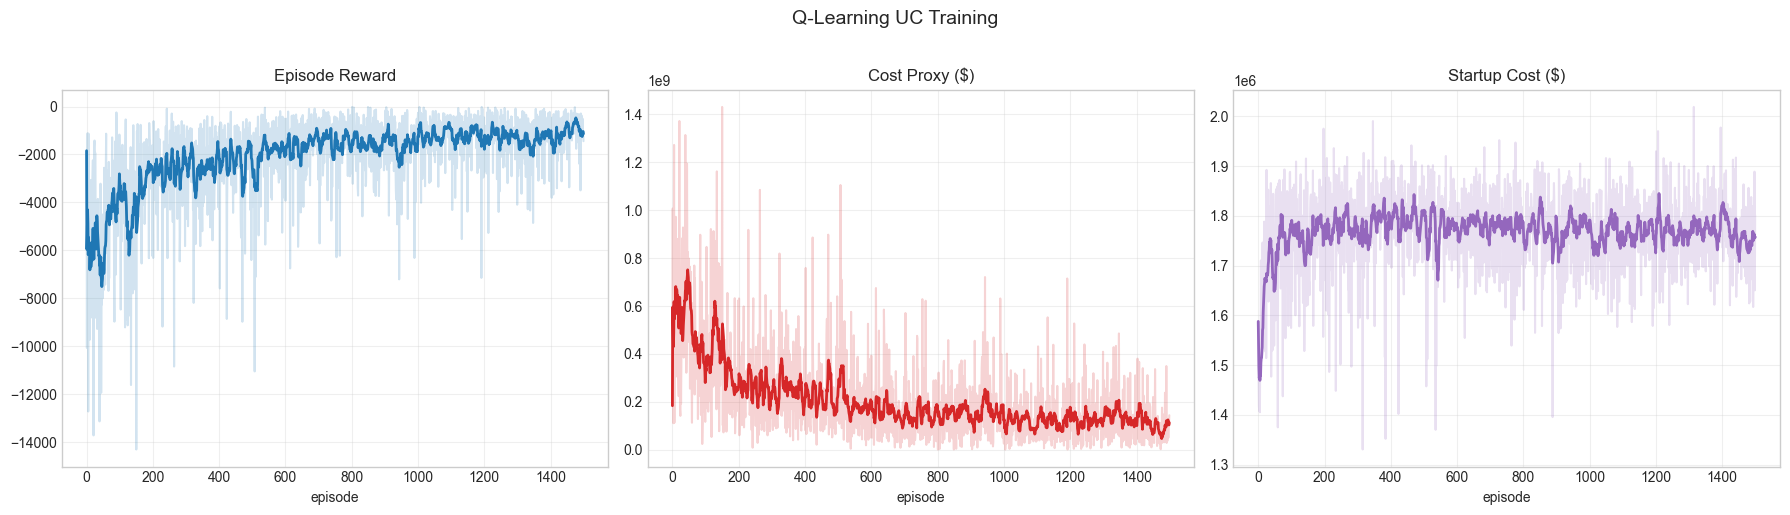

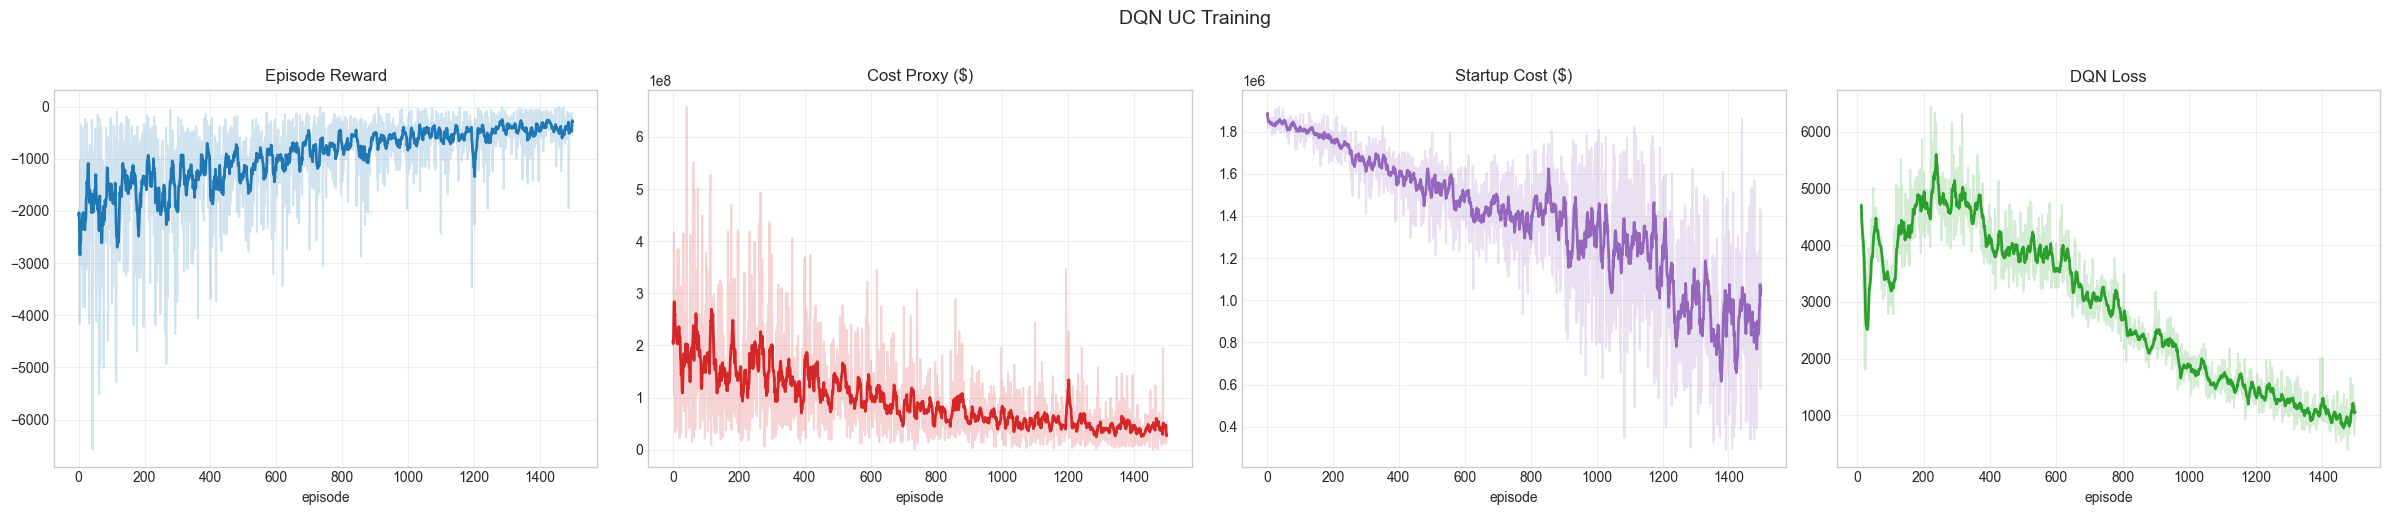

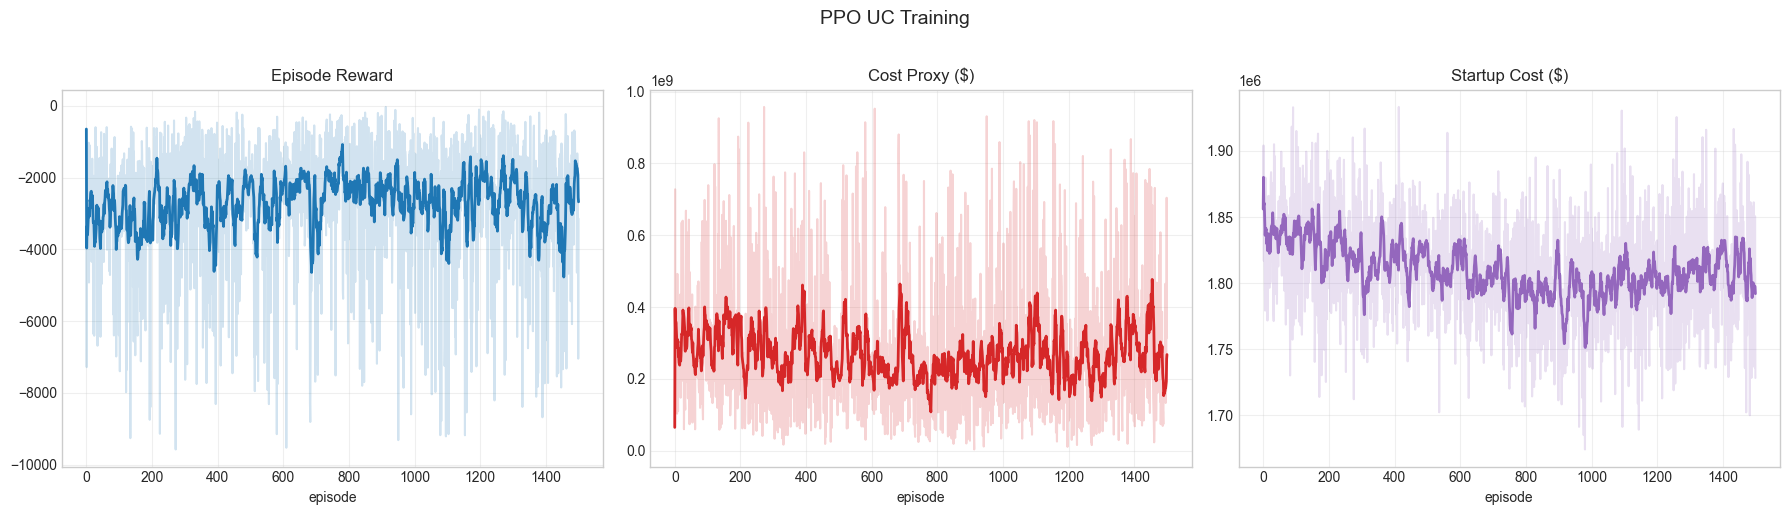

In [19]:
def plot_training_curves(rewards, costs, startups, title, losses=None, window=10):
    n = 4 if losses is not None else 3
    fig, axes = plt.subplots(1, n, figsize=(6*n, 5))
    fig.suptitle(title, fontsize=14, y=1.02)
    for ax, (data, lbl, clr) in zip(axes, [
        (rewards,"Episode Reward","tab:blue"),
        (costs,"Cost Proxy ($)","tab:red"),
        (startups,"Startup Cost ($)","tab:purple"),
    ]):
        ax.plot(data, alpha=0.2, color=clr)
        ax.plot(pd.Series(data).rolling(window, min_periods=1).mean(), color=clr, lw=2)
        ax.set_title(lbl); ax.set_xlabel("episode"); ax.grid(True, alpha=0.3)
    if losses is not None:
        ax = axes[3]
        ax.plot(losses, alpha=0.2, color="tab:green")
        ax.plot(pd.Series(losses).rolling(window, min_periods=1).mean(), color="tab:green", lw=2)
        ax.set_title("DQN Loss"); ax.set_xlabel("episode"); ax.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()

plot_training_curves(q_rewards, q_costs, q_startups, "Q-Learning UC Training")
plot_training_curves(dqn_rewards, dqn_costs, dqn_startups, "DQN UC Training", dqn_losses)
plot_training_curves(ppo_cb.ep_r, ppo_cb.ep_c, ppo_cb.ep_su, "PPO UC Training")

In [20]:
def collect_gen_usage(env_obj, policy_fn, episodes, n_instances=20):
    """
    Rollout policy on n_instances, hitung berapa jam tiap generator ON.
    Returns: on_freq (n_gen,) = % hours ON averaged across instances
    """
    n_gen = env_obj.n_gen
    total_on  = np.zeros(n_gen, int)
    total_hrs = 0

    for vi in range(min(n_instances, len(episodes))):
        tr = collect_uc_trace(env_obj, policy_fn, vi)
        on_mat = np.vstack(tr["on"].values)   # (72, n_gen)
        total_on  += on_mat.sum(axis=0)
        total_hrs += len(tr)

    return total_on / max(total_hrs, 1) * 100  # % hours ON


# Jalankan setelah semua model selesai training
print("Collecting generator usage...")
q_gen_freq   = collect_gen_usage(env, lambda o: q_policy(o, 0.0), train_episodes, 20)
dqn_gen_freq = collect_gen_usage(env, dqn_policy,  train_episodes, 20)
ppo_gen_freq = collect_gen_usage(env, ppo_policy,  train_episodes, 20)

print(f"Done. Shape: {q_gen_freq.shape}")

Done. Shape: (51,)


In [21]:
def plot_generator_selection_heatmap(gen_freqs_dict, env_obj):
    """
    Heatmap: rows = UC models, cols = generators
    Cell = % hours generator ON
    """
    gen_names = env_obj.generator_names
    n_gen     = env_obj.n_gen
    models    = list(gen_freqs_dict.keys())

    # Build matrix: (n_models, n_gen)
    mat = np.vstack([gen_freqs_dict[m] for m in models])

    # Sort generators by average usage across all models
    avg_usage = mat.mean(axis=0)
    sort_idx  = np.argsort(-avg_usage)  # most used first

    mat_sorted   = mat[:, sort_idx]
    names_sorted = [gen_names[i] for i in sort_idx]

    fig, ax = plt.subplots(figsize=(22, 3 + len(models)))
    im = ax.imshow(mat_sorted, aspect="auto", cmap="YlOrRd",
                   vmin=0, vmax=100)

    ax.set_yticks(range(len(models)))
    ax.set_yticklabels(models, fontsize=11)
    ax.set_xticks(range(n_gen))
    ax.set_xticklabels(names_sorted, rotation=90, fontsize=6)
    ax.set_title("Generator selection frequency — % hours ON per model", fontsize=13)

    # Annotate cells
    for i in range(len(models)):
        for j in range(n_gen):
            v = mat_sorted[i, j]
            if v > 1:
                ax.text(j, i, f"{v:.0f}", ha="center", va="center",
                        fontsize=5, color="white" if v > 60 else "black")

    fig.colorbar(im, ax=ax, shrink=0.6, label="% hours ON")
    plt.tight_layout()
    plt.show()


def plot_generator_selection_bar(gen_freqs_dict, env_obj):
    """
    Side-by-side bar chart per generator — 3 models compared.
    Sorted by PPO usage (highest first).
    """
    gen_names = env_obj.generator_names
    n_gen     = env_obj.n_gen
    models    = list(gen_freqs_dict.keys())
    colors    = ["tab:blue", "tab:orange", "tab:green"]

    # Sort by first model's usage
    first_freq = list(gen_freqs_dict.values())[0]
    sort_idx   = np.argsort(-first_freq)

    fig, ax = plt.subplots(figsize=(22, 6))
    x = np.arange(n_gen)
    w = 0.25

    for j, (model, clr) in enumerate(zip(models, colors)):
        freq = gen_freqs_dict[model][sort_idx]
        ax.bar(x + j*w, freq, w, label=model, color=clr, alpha=0.8)

    ax.set_xticks(x + w)
    ax.set_xticklabels([gen_names[i] for i in sort_idx],
                        rotation=90, fontsize=6)
    ax.set_ylabel("% hours ON")
    ax.set_title("Generator selection frequency per model (sorted by usage)")
    ax.legend(); ax.grid(True, alpha=0.3, axis="y")
    plt.tight_layout()
    plt.show()

In [22]:
gen_freqs = {
    "Q-Learning": q_gen_freq,
    "DQN":        dqn_gen_freq,
    "PPO":        ppo_gen_freq,
}

In [23]:
gen_freqs_df = pd.DataFrame(gen_freqs, index=env.generator_names)
gen_freqs_df

,Q-Learning,DQN,PPO
gen_204e519c,99.652778,100.000000,96.250000
gen_b972a1dc,66.388889,79.166667,81.458333
gen_3ee144ad,65.208333,72.500000,76.875000
gen_f8b856d4,63.958333,72.777778,4.166667
gen_a7876643,63.611111,29.930556,99.583333
gen_b4eba0b8,63.819444,73.263889,19.583333
gen_d5aea532,65.208333,77.708333,62.847222
gen_ff58fdf4,66.736111,71.527778,95.486111
gen_3223a28b,65.694444,73.541667,98.263889
gen_bc3de19e,65.625000,76.111111,99.861111


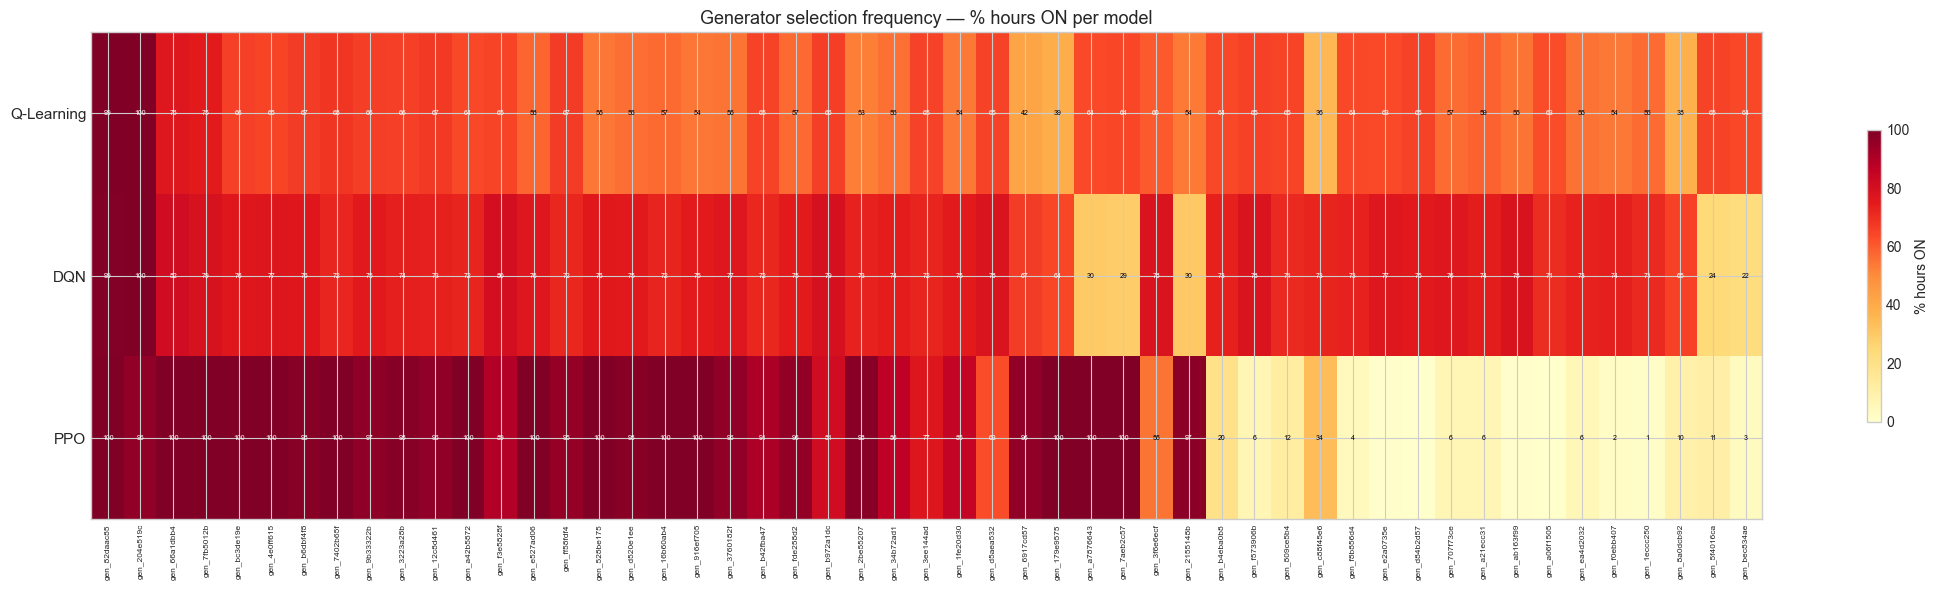

In [24]:
plot_generator_selection_heatmap(gen_freqs, env)

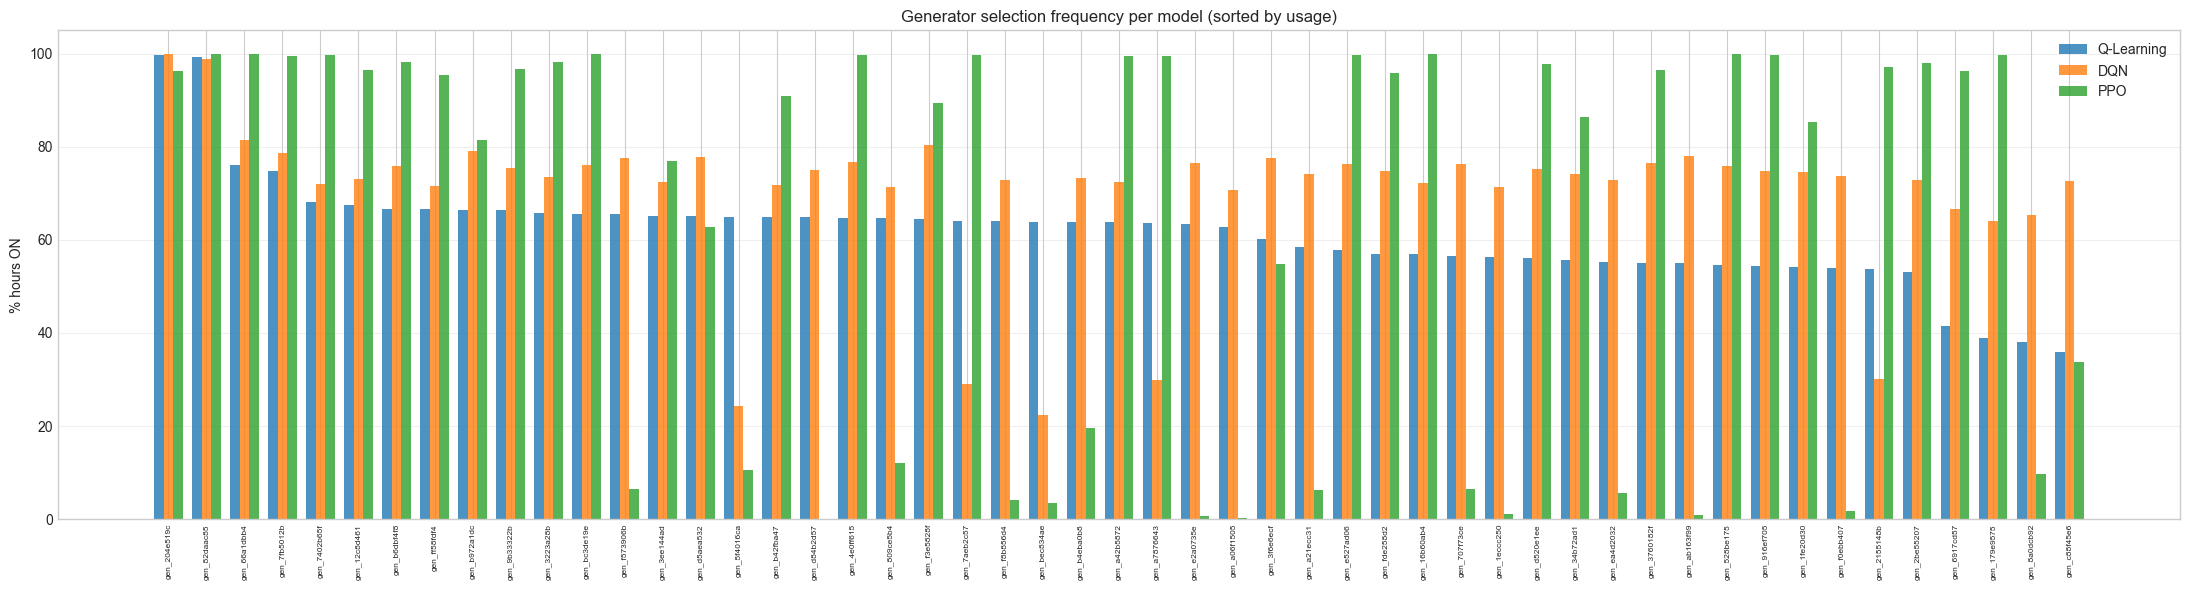

In [25]:
plot_generator_selection_bar(gen_freqs, env)

In [26]:
def collect_hourly_gen_frequency(env_obj, policy_fn, episodes, 
                                  n_instances=20, method_name="RL"):
    """
    Untuk tiap jam (0-71) dan tiap generator (0-50),
    hitung berapa % instances generator itu ON di jam tersebut.
    
    Result: matrix (n_gen, 72) — % instances ON per hour per generator
    """
    n_gen    = env_obj.n_gen
    horizon  = env_obj.horizon
    on_count = np.zeros((n_gen, horizon), int)
    n_inst   = min(n_instances, len(episodes))

    for vi in range(n_inst):
        tr     = collect_uc_trace(env_obj, policy_fn, vi)
        on_mat = np.vstack(tr["on"].values)  # (72, n_gen)
        on_count += on_mat.T                 # (n_gen, 72)

        if (vi+1) % 50 == 0:
            print(f"  {method_name}: {vi+1}/{n_inst} instances")

    freq_pct = on_count / n_inst * 100
    return freq_pct  # (n_gen, 72)


def plot_hourly_gen_heatmap(freq_dict, env_obj):
    """
    3 heatmaps stacked — one per model.
    y-axis: generator (sorted by avg frequency), labels on ALL panels
    x-axis: hour 0-71
    cell: % instances generator ON at that hour
    Right side: avg ON% bar showing high-commitment generators
    """
    gen_names = env_obj.generator_names
    n_gen     = env_obj.n_gen
    models    = list(freq_dict.keys())

    # Sort generators by average frequency across all models and hours
    stacked  = np.stack([freq_dict[m] for m in models], axis=0)  # (n_model, n_gen, 72)
    avg_freq = stacked.mean(axis=(0, 2))  # (n_gen,)
    sort_idx = np.argsort(-avg_freq)      # most used first

    # Labels with Pmin and avg ON%
    gen_labels = [
        f"{gen_names[i][:16]}  ({avg_freq[i]:.0f}%)"
        for i in sort_idx
    ]

    fig, axes = plt.subplots(len(models), 2, figsize=(max(14, n_gen * 0.35), 24),
                              gridspec_kw={"width_ratios": [5, 1], "wspace": 0.02},
                              sharey=True)

    fig.suptitle(
        "Generator ON Frequency per Hour — % of instances\n"
        "(sorted by avg usage, right bar = avg ON%)",
        fontsize=14, y=1.01,
    )

    for row, model_name in enumerate(models):
        ax_heat = axes[row, 0]
        ax_bar  = axes[row, 1]
        mat = freq_dict[model_name][sort_idx, :]  # (n_gen, 72)

        # ── Heatmap ──
        im = ax_heat.imshow(mat, aspect="auto", cmap="YlOrRd",
                            vmin=0, vmax=100,
                            extent=[-0.5, 71.5, n_gen - 0.5, -0.5])

        ax_heat.set_title(model_name, fontsize=13, fontweight="bold")
        ax_heat.set_xticks([0, 12, 24, 36, 48, 60, 71])

        # y-axis labels on ALL panels (no ylabel text, just generator names)
        ax_heat.set_yticks(range(n_gen))
        ax_heat.set_yticklabels(gen_labels, fontsize=6, family="monospace")
        ax_heat.grid(False)

        if row == len(models) - 1:
            ax_heat.set_xlabel("Hour", fontsize=11)

        # ── Side bar: avg ON% per generator for this model ──
        avg_per_gen = mat.mean(axis=1)  # (n_gen,)
        y_pos = np.arange(n_gen)

        # Color bars by commitment level
        bar_colors = []
        for val in avg_per_gen:
            if val >= 90:
                bar_colors.append("#d32f2f")   # always ON — red
            elif val >= 60:
                bar_colors.append("#f57c00")   # high — orange
            elif val >= 30:
                bar_colors.append("#fbc02d")   # medium — yellow
            else:
                bar_colors.append("#81c784")   # low — green

        ax_bar.barh(y_pos, avg_per_gen, color=bar_colors, edgecolor="none",
                    height=0.8)
        ax_bar.set_xlim(0, 105)
        ax_bar.axvline(90, ls=":", color="red", alpha=0.5, lw=1)
        ax_bar.axvline(50, ls=":", color="orange", alpha=0.4, lw=1)
        ax_bar.set_title("Avg ON%", fontsize=10)
        ax_bar.tick_params(left=False, labelleft=False)
        ax_bar.grid(True, alpha=0.15, axis="x")

        if row == len(models) - 1:
            ax_bar.set_xlabel("%", fontsize=10)

        # ── Annotate high-commitment generators (≥90%) ──
        high_commit = np.where(avg_per_gen >= 90)[0]
        for hc in high_commit:
            ax_bar.text(avg_per_gen[hc] + 1, hc, f"{avg_per_gen[hc]:.0f}%",
                        va="center", fontsize=6, color="#d32f2f", fontweight="bold")

    # Single colorbar for all heatmaps
    fig.colorbar(im, ax=axes[:, 0].tolist(), shrink=0.4, pad=0.01,
                 label="% instances ON")

    plt.tight_layout()
    plt.show()

    # ── Print high-commitment generators table ──
    print(f"\n{'='*85}")
    print(f"  HIGH-COMMITMENT GENERATORS (avg ON% ≥ 80 in any agent)")
    print(f"{'='*85}")
    print(f"  {'Generator':20s} {'Pmin':>6s} {'Pmax':>6s} {'MC($/MW)':>8s} "
          f"{'SC($)':>10s} | ", end="")
    for m in models:
        print(f" {m:>10s}", end="")
    print()
    print(f"  {'─'*83}")

    for rank, gi in enumerate(sort_idx):
        vals = [freq_dict[m][gi, :].mean() for m in models]
        if max(vals) >= 80:
            print(f"  {gen_names[gi]:20s} {env_obj.pmin[gi]:>6.0f} "
                  f"{env_obj.pmax[gi]:>6.0f} {env_obj.marginal_cost[gi]:>8.1f} "
                  f"${env_obj.startup_cost_arr[gi]:>9,.0f} | ", end="")
            for v in vals:
                marker = "██" if v >= 90 else "▓▓" if v >= 70 else "░░" if v >= 50 else "  "
                print(f" {v:>6.1f}%{marker}", end="")
            print()

In [27]:
# ── Collect ──
N_TRAIN_INSTANCES = 1500

print("Collecting hourly frequency — Q-Learning...")
q_hourly = collect_hourly_gen_frequency(
    env, lambda o: q_policy(o, 0.0),
    train_episodes, n_instances=N_TRAIN_INSTANCES, method_name="Q-Learning")

print("Collecting hourly frequency — DQN...")
dqn_hourly = collect_hourly_gen_frequency(
    env, dqn_policy,
    train_episodes, n_instances=N_TRAIN_INSTANCES, method_name="DQN")

print("Collecting hourly frequency — PPO...")
ppo_hourly = collect_hourly_gen_frequency(
    env, ppo_policy,
    train_episodes, n_instances=N_TRAIN_INSTANCES, method_name="PPO")

  Q-Learning: 50/300 instances
  Q-Learning: 100/300 instances
  Q-Learning: 150/300 instances
  Q-Learning: 200/300 instances
  Q-Learning: 250/300 instances
  Q-Learning: 300/300 instances
  DQN: 50/300 instances
  DQN: 100/300 instances
  DQN: 150/300 instances
  DQN: 200/300 instances
  DQN: 250/300 instances
  DQN: 300/300 instances
  PPO: 50/300 instances
  PPO: 100/300 instances
  PPO: 150/300 instances
  PPO: 200/300 instances
  PPO: 250/300 instances
  PPO: 300/300 instances


C:\Users\HP\AppData\Local\Temp\ipykernel_49936\1459618019.py:118: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


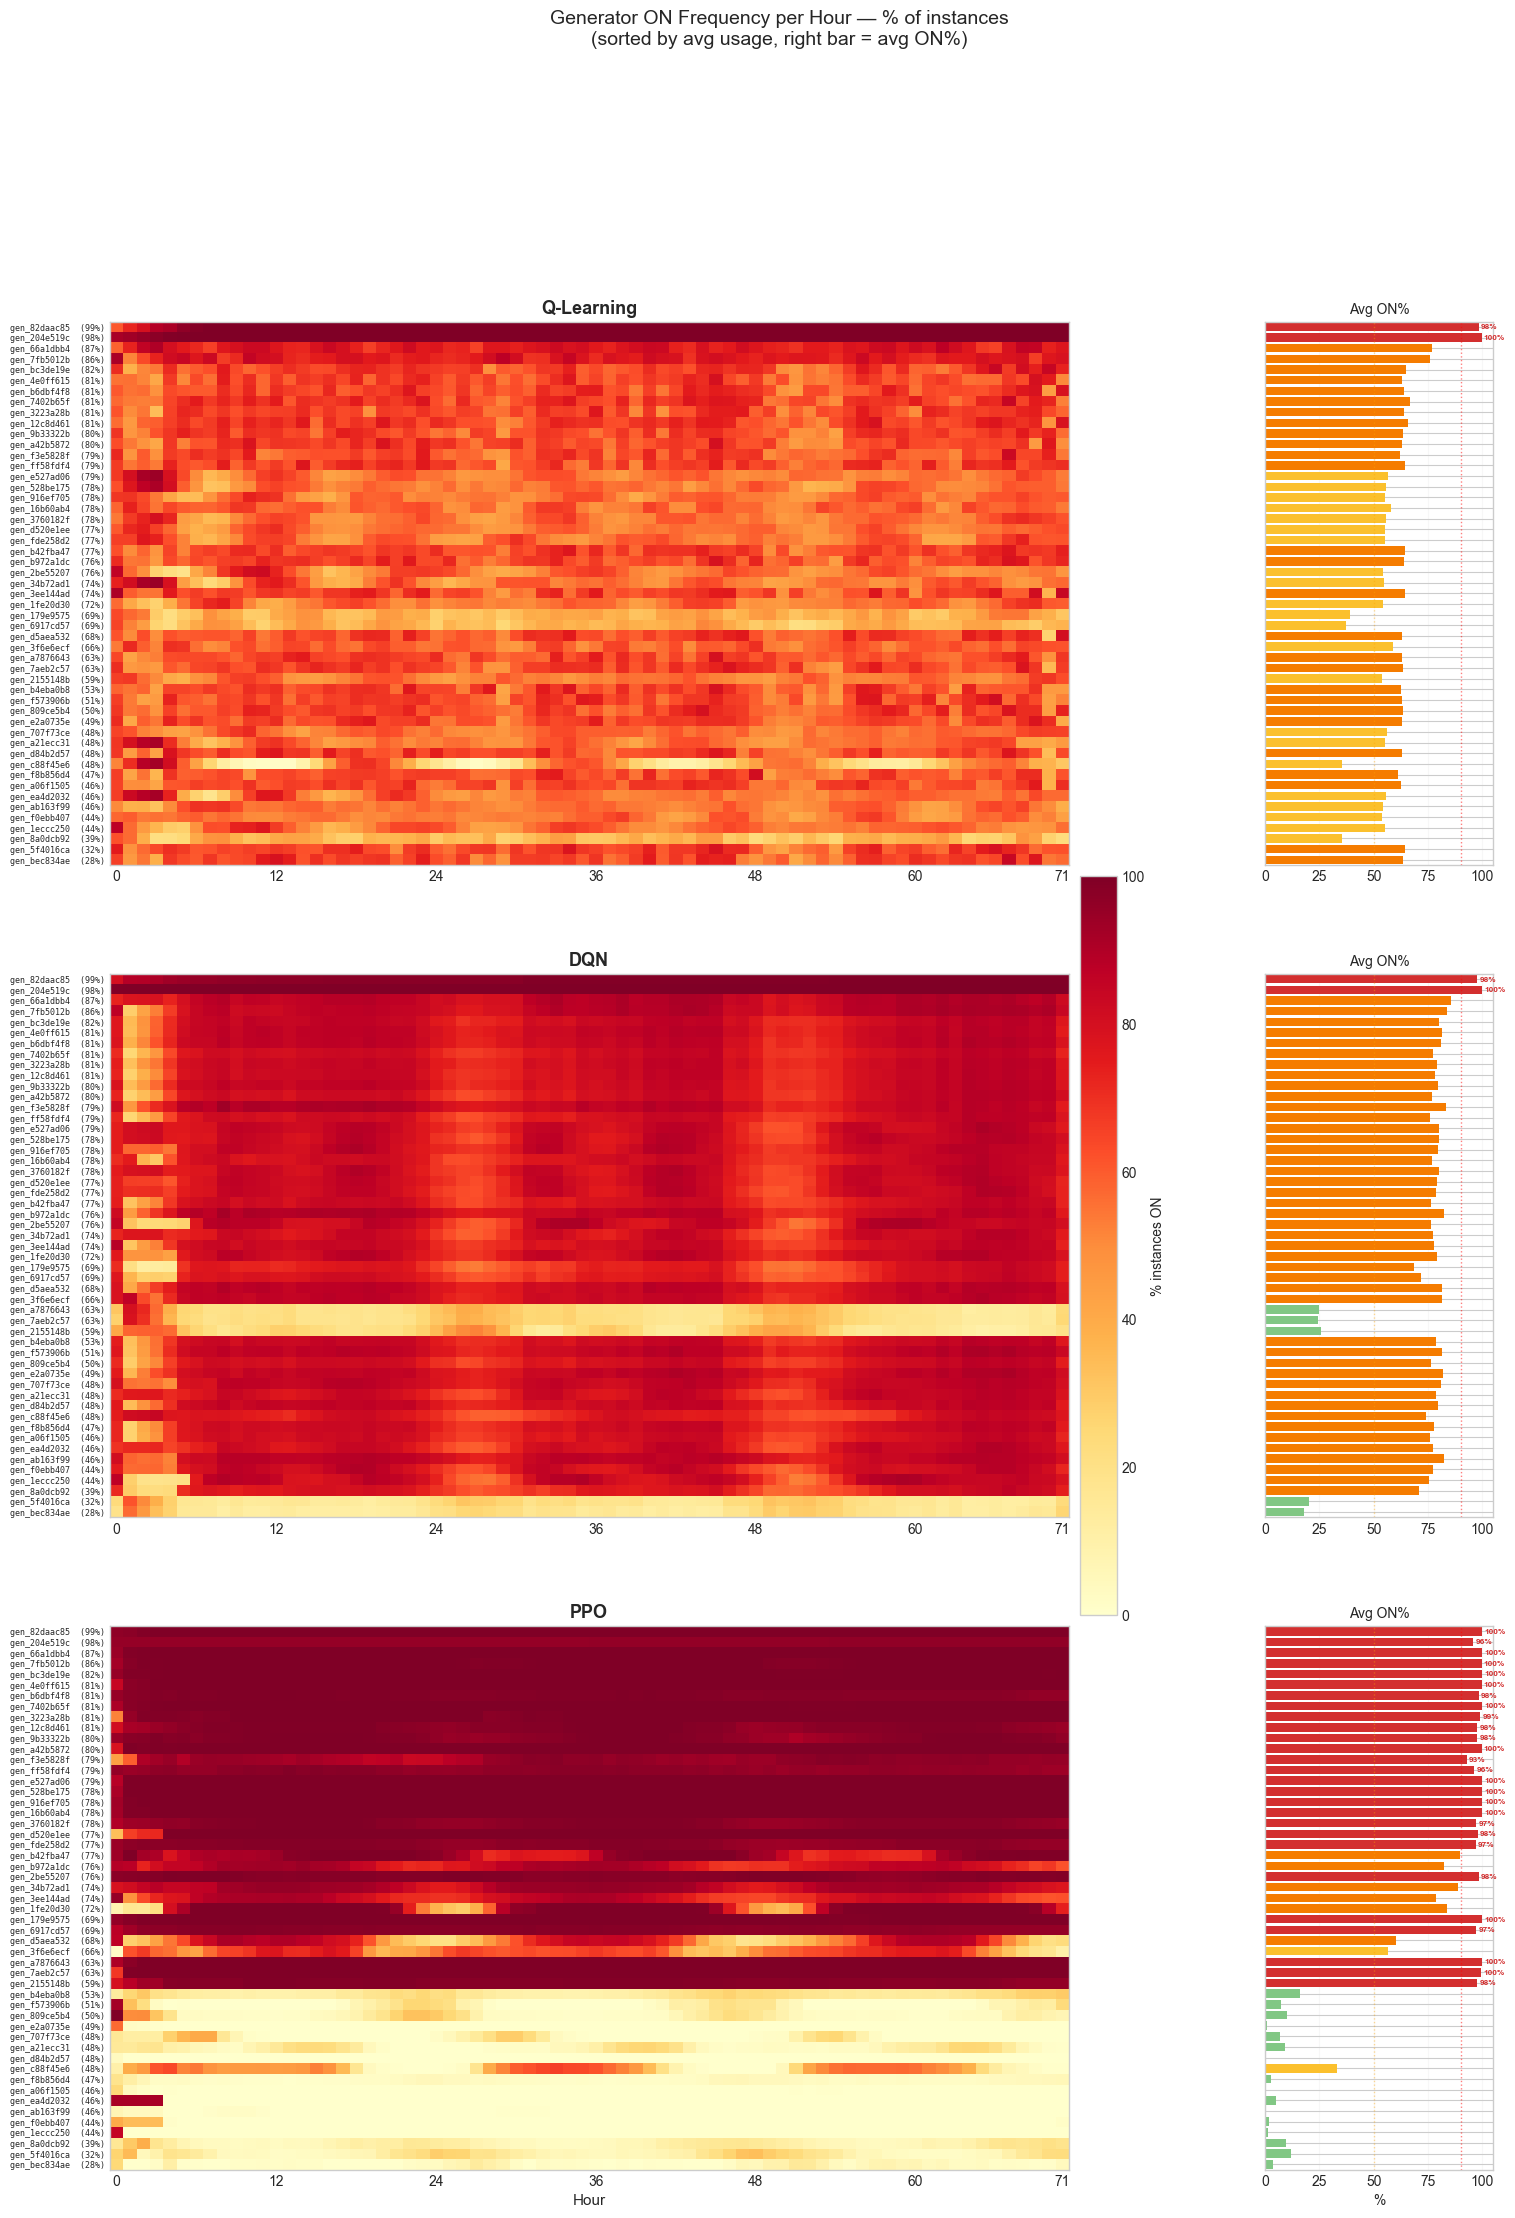


  HIGH-COMMITMENT GENERATORS (avg ON% ≥ 80 in any agent)
  Generator              Pmin   Pmax MC($/MW)      SC($) |  Q-Learning        DQN        PPO
  ───────────────────────────────────────────────────────────────────────────────────
  gen_82daac85             99    285      0.0 $   46,015 |    98.4%██   97.7%██   99.9%██
  gen_204e519c             13     18      0.0 $        0 |    99.7%██  100.0%██   95.8%██
  gen_66a1dbb4             93    238      0.0 $    9,506 |    76.6%▓▓   85.6%▓▓   99.9%██
  gen_7fb5012b             41    118      0.0 $    1,090 |    75.9%▓▓   83.6%▓▓   99.6%██
  gen_bc3de19e             13     42      0.0 $      130 |    65.0%░░   80.0%▓▓   99.8%██
  gen_4e0ff615             15     90      0.0 $      601 |    63.1%░░   81.3%▓▓   99.7%██
  gen_b6dbf4f8             10     58      0.0 $      382 |    64.2%░░   81.2%▓▓   98.5%██
  gen_7402b65f            130    350      0.0 $    1,675 |    66.7%░░   77.1%▓▓   99.7%██
  gen_3223a28b              8     58      0

In [28]:
hourly_freqs = {
    "Q-Learning": q_hourly,
    "DQN":        dqn_hourly,
    "PPO":        ppo_hourly,
}
plot_hourly_gen_heatmap(hourly_freqs, env)

## 9. Visualise UC Decisions (before ED)

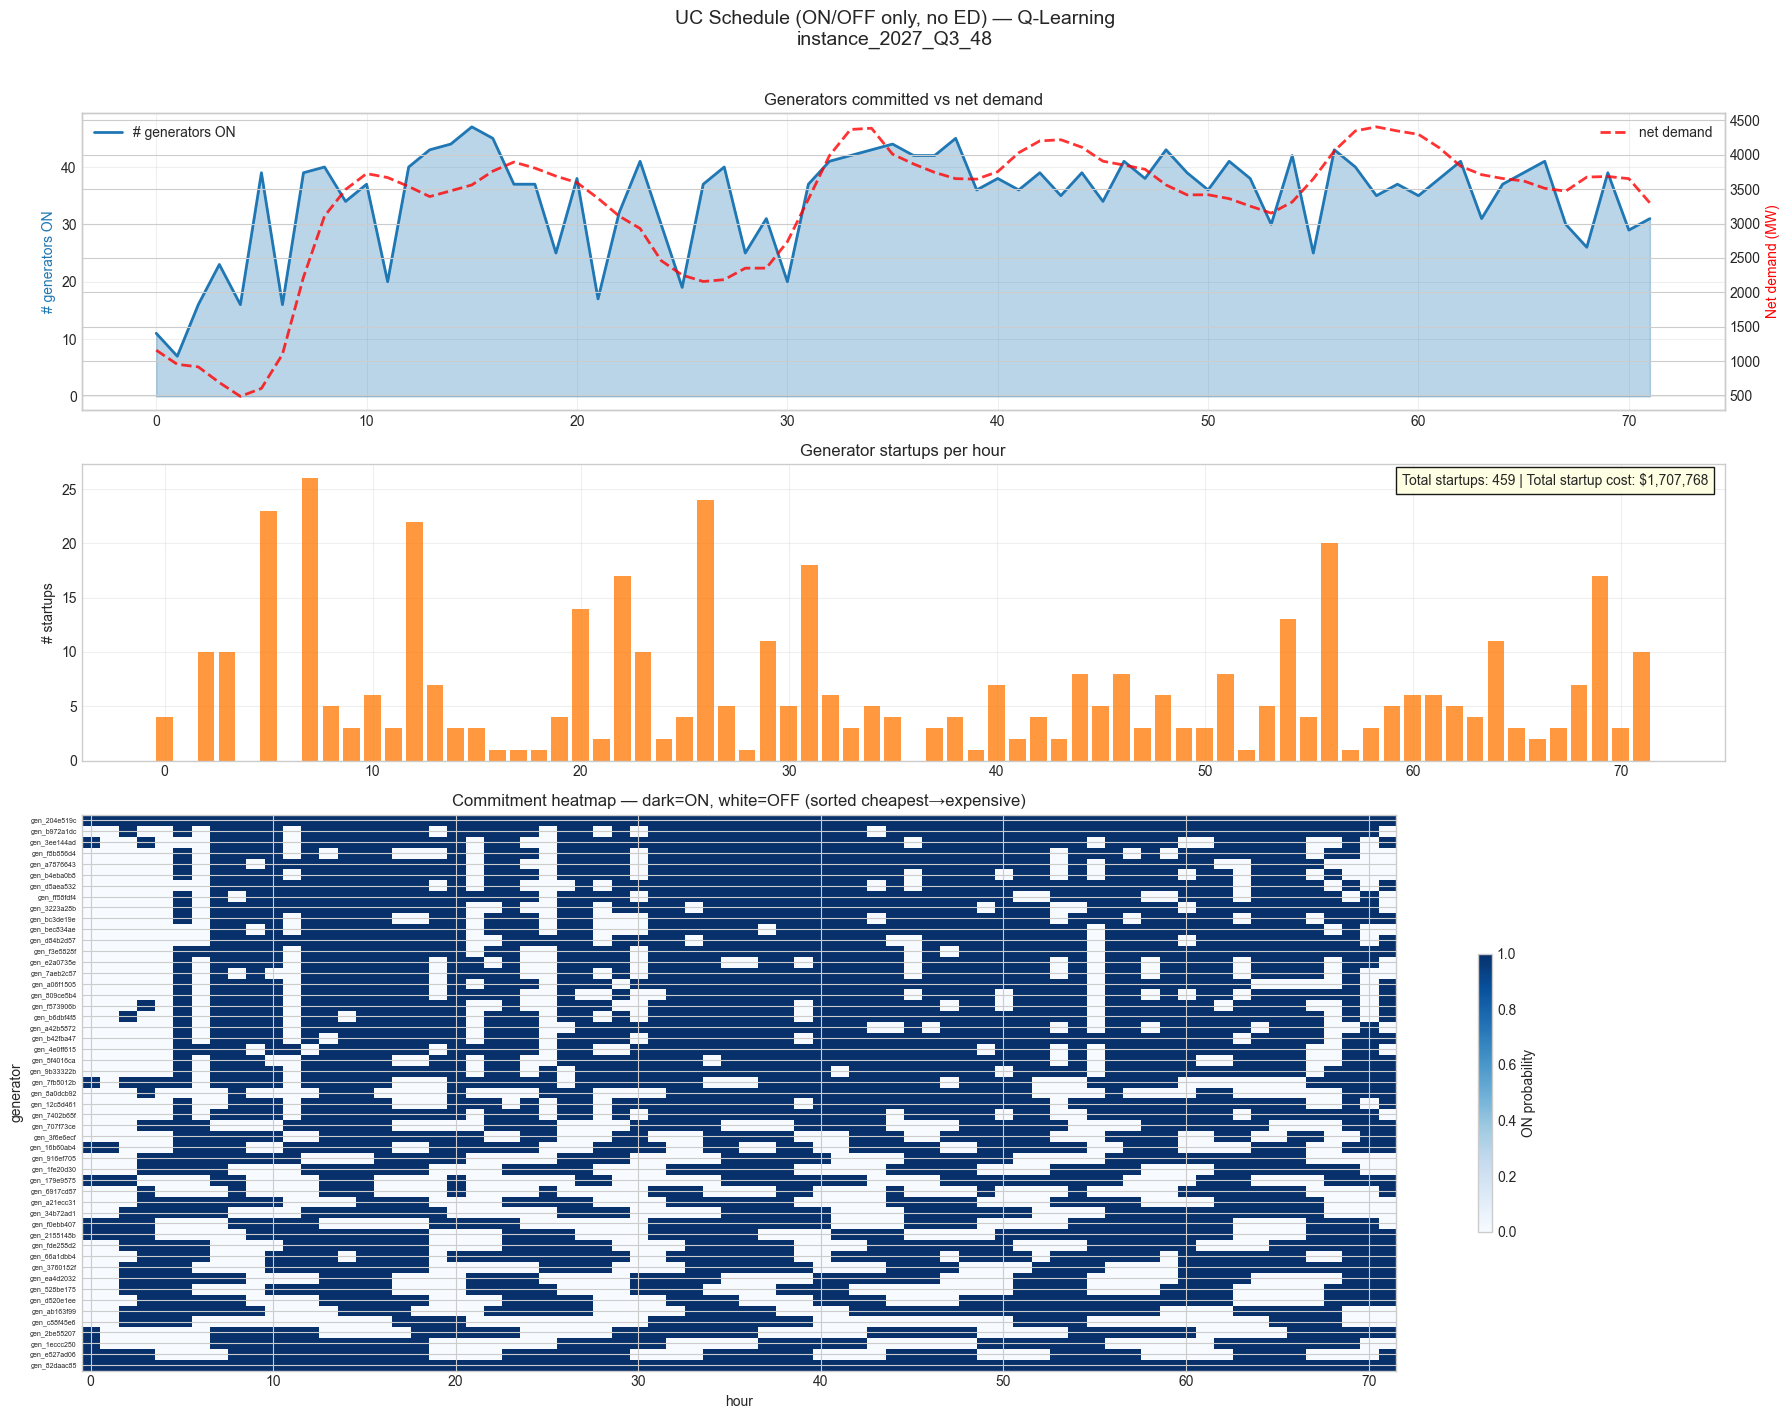

UC Summary — Q-Learning
  Avg online:      34.5/72 generators
  Total startups:  459
  Total su cost:   $1,707,768
  Hours all zero:  0
  Max online:      47


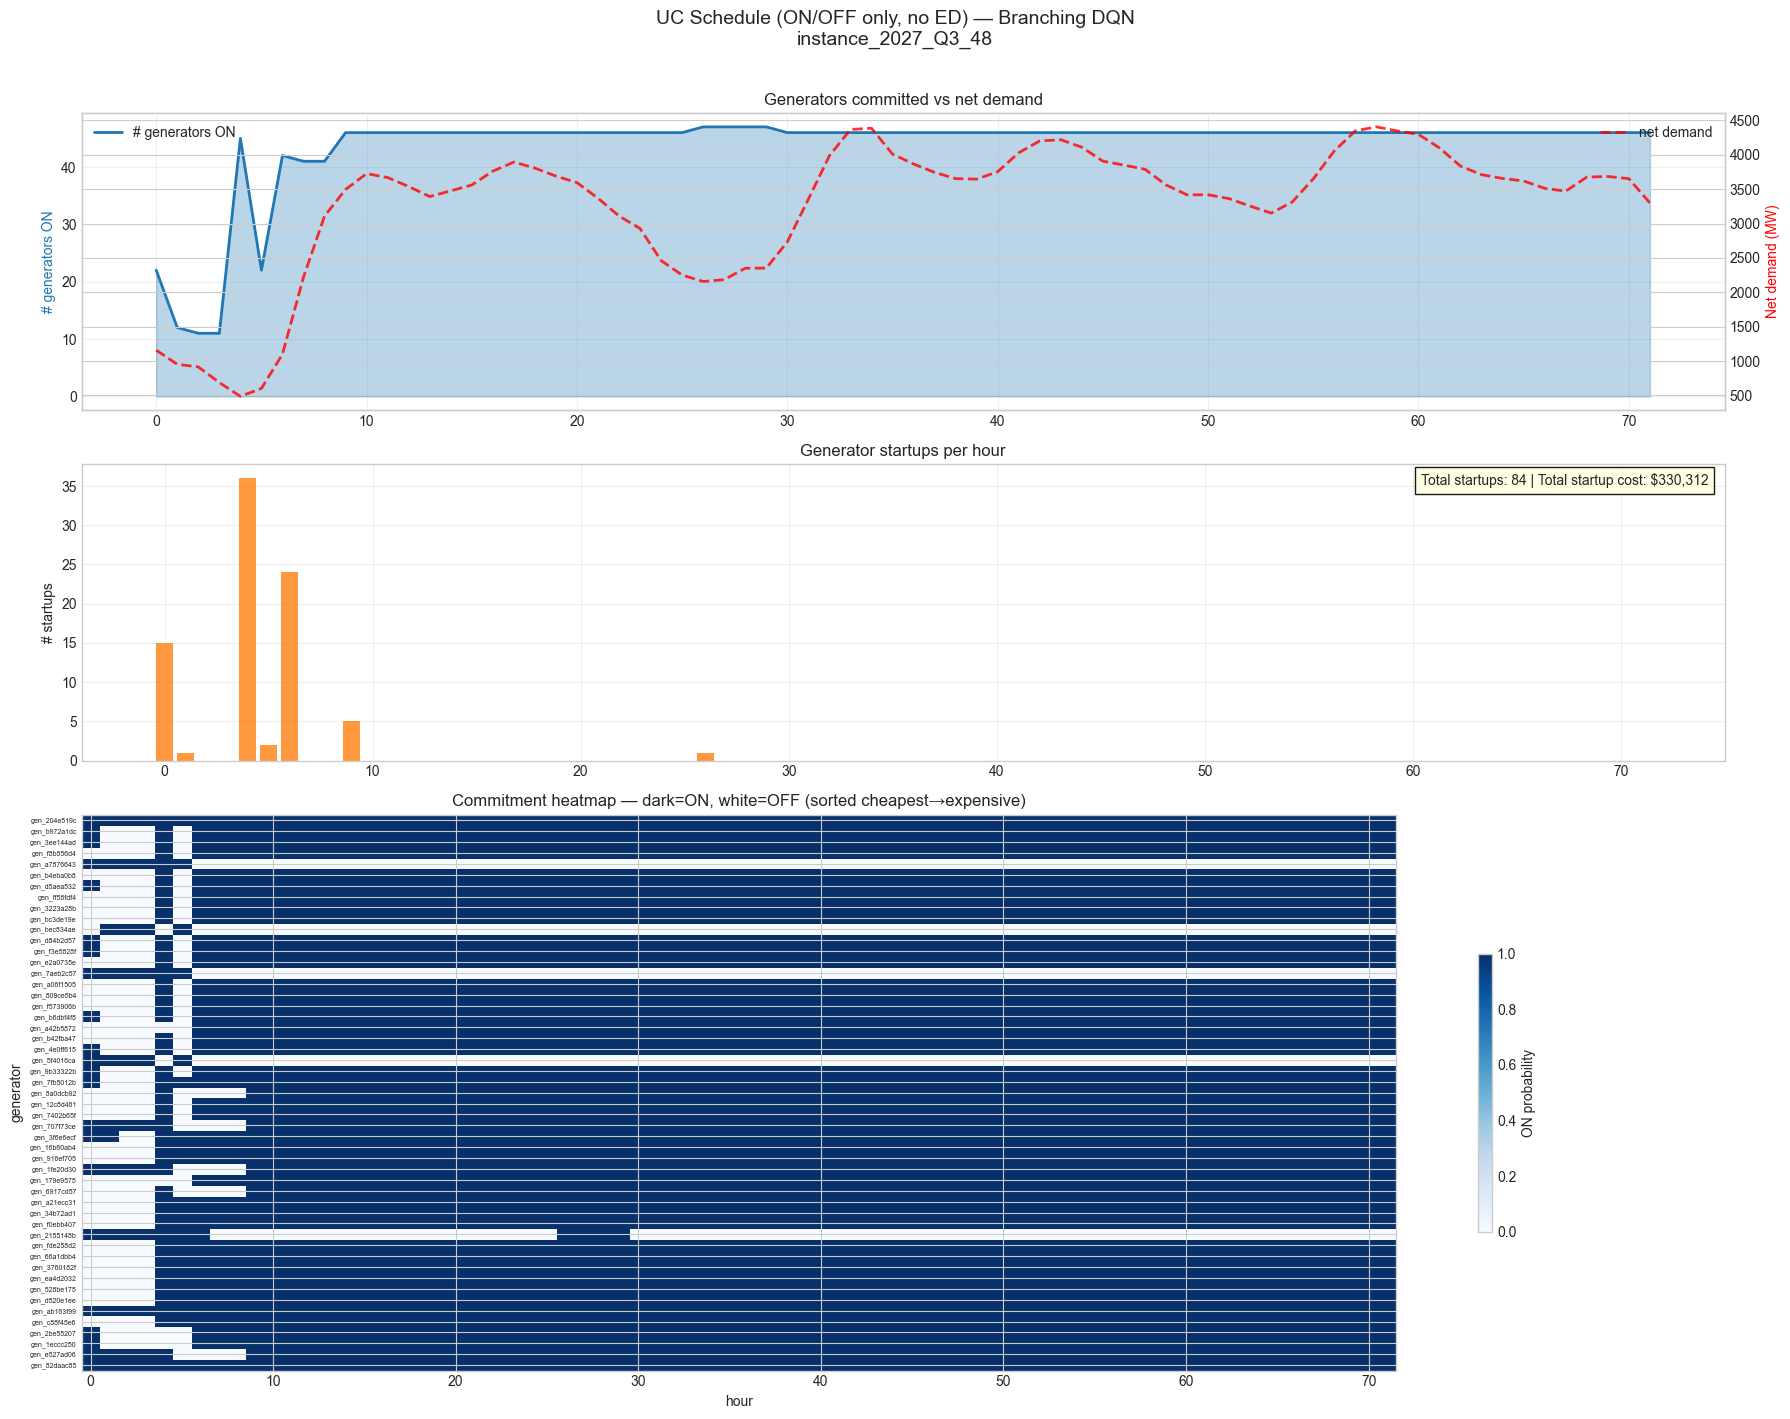

UC Summary — Branching DQN
  Avg online:      43.7/72 generators
  Total startups:  84
  Total su cost:   $330,312
  Hours all zero:  0
  Max online:      47


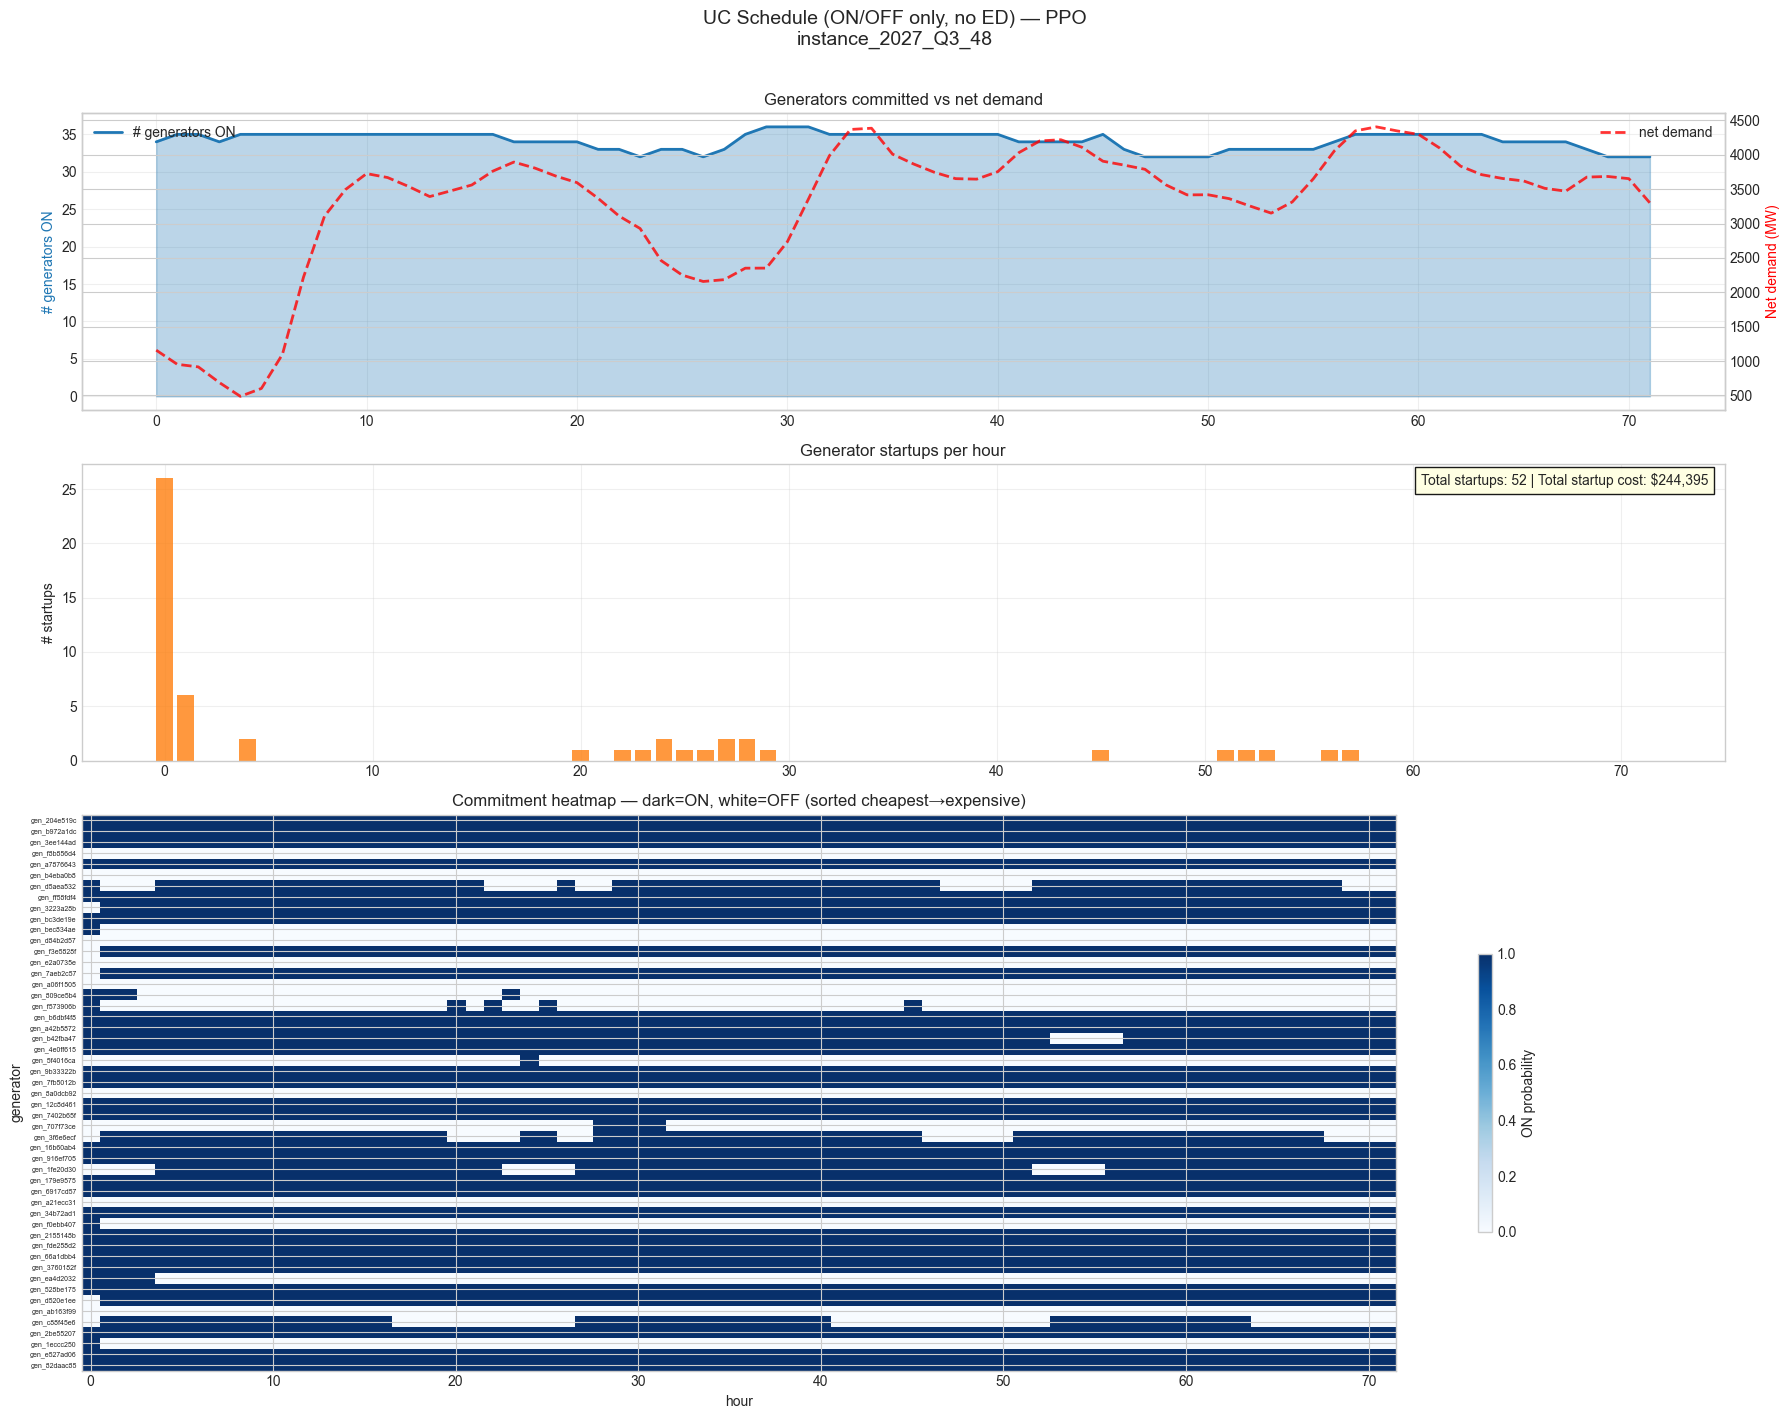

UC Summary — PPO
  Avg online:      34.1/72 generators
  Total startups:  52
  Total su cost:   $244,395
  Hours all zero:  0
  Max online:      36


In [29]:
def plot_uc_only(uc_trace, env_obj, title=""):
    """
    Visualise pure UC schedule — ON/OFF decisions only.
    No dispatch amounts shown (ED not applied yet).
    """
    on_mat  = np.vstack(uc_trace["on"].values)    # (72, 51)
    hours   = uc_trace["hour"].values
    n_h, n_g = on_mat.shape
    n_online  = on_mat.sum(axis=1)

    fig, axes = plt.subplots(3, 1, figsize=(18, 14),
                              gridspec_kw={"height_ratios": [0.8, 0.8, 1.5]})
    fig.suptitle(f"UC Schedule (ON/OFF only, no ED) — {title}\n"
                 f"{uc_trace['instance_id'].iloc[0]}", fontsize=14, y=1.01)

    # Panel 1: # generators ON vs net demand
    ax = axes[0]
    ax.fill_between(hours, n_online, alpha=0.3, color="tab:blue")
    ax.plot(hours, n_online, lw=2, color="tab:blue", label="# generators ON")
    ax.set_ylabel("# generators ON", color="tab:blue")
    ax2 = ax.twinx()
    nd = uc_trace["net_demand"].values
    ax2.plot(hours, nd, "r--", lw=2, alpha=0.8, label="net demand")
    ax2.set_ylabel("Net demand (MW)", color="red")
    ax.set_title("Generators committed vs net demand")
    ax.legend(loc="upper left"); ax2.legend(loc="upper right")
    ax.grid(True, alpha=0.3)

    # Panel 2: startups per hour
    ax = axes[1]
    startups = uc_trace["n_startups"].values
    ax.bar(hours, startups, color="tab:orange", alpha=0.8)
    ax.set_ylabel("# startups"); ax.set_title("Generator startups per hour")
    ax.grid(True, alpha=0.3)
    ax.text(0.99, 0.97, f"Total startups: {startups.sum()} | "
            f"Total startup cost: ${uc_trace['startup_cost'].sum():,.0f}",
            transform=ax.transAxes, va="top", ha="right", fontsize=10,
            bbox=dict(facecolor="lightyellow", alpha=0.9))

    # Panel 3: commitment heatmap
    ax = axes[2]
    im = ax.imshow(on_mat.T, aspect="auto", cmap="Blues",
                   origin="upper", vmin=0, vmax=1,
                   extent=[hours[0]-0.5, hours[-1]+0.5, n_g-0.5, -0.5])
    ax.set_title("Commitment heatmap — dark=ON, white=OFF (sorted cheapest→expensive)")
    ax.set_xlabel("hour"); ax.set_ylabel("generator")
    if n_g <= 55:
        ax.set_yticks(range(n_g))
        ax.set_yticklabels(env_obj.generator_names, fontsize=5)
    fig.colorbar(im, ax=ax, shrink=0.5, label="ON probability")
    plt.tight_layout(); plt.show()

    print(f"UC Summary — {title}")
    print(f"  Avg online:      {n_online.mean():.1f}/72 generators")
    print(f"  Total startups:  {startups.sum()}")
    print(f"  Total su cost:   ${uc_trace['startup_cost'].sum():,.0f}")
    print(f"  Hours all zero:  {(n_online==0).sum()}")
    print(f"  Max online:      {n_online.max()}")

# Collect UC traces (no ED)
q_uc   = collect_uc_trace(env, lambda o: q_policy(o, 0.0), 0)
dqn_uc = collect_uc_trace(env, dqn_policy, 0)
ppo_uc = collect_uc_trace(env, ppo_policy, 0)

plot_uc_only(q_uc,   env, "Q-Learning")
plot_uc_only(dqn_uc, env, "Branching DQN")
plot_uc_only(ppo_uc, env, "PPO")

In [30]:
len(q_uc), len(dqn_uc), len(ppo_uc)

(72, 72, 72)

## 10. UC-only Comparison Table

In [31]:
def summarise_uc(traces_dict):
    rows = []
    for name, tr in traces_dict.items():
        on_mat = np.vstack(tr["on"].values)
        rows.append({
            "UC Agent": name,
            "Avg ON time/hr": round(on_mat.sum(axis=1).mean(), 1),
            "Total Startups": int(tr["n_startups"].sum()),
            "Startup Cost ($)": int(tr["startup_cost"].sum()),
            "Overrides": int(tr["n_overrides"].sum()),
            "Min ON time": int(on_mat.sum(axis=1).min()),
            "Max ON time": int(on_mat.sum(axis=1).max()),
        })
    return pd.DataFrame(rows)

uc_traces = {"Q-Learning": q_uc, "DQN": dqn_uc, "PPO": ppo_uc}
print("UC-only comparison (before ED):")
display(summarise_uc(uc_traces))

UC-only comparison (before ED):


,UC Agent,Avg ON time/hr,Total Startups,Startup Cost ($),Overrides,Min ON time,Max ON time
0,Q-Learning,34.5,459,1707768,548,7,47
1,DQN,43.7,84,330312,121,11,47
2,PPO,34.1,52,244394,39,32,36


## 11. ED Solvers — 3 Methods (Discrete 10-100%, 10% steps)

All three methods receive the same UC schedule (ON/OFF array) and return
dispatch in MW for each generator. Levels: 10%, 20%, ..., 100% × pmax.


In [57]:
def _ed_bounds(on, pmin, pmax, current_dispatch, ramp_up, ramp_down, status_duration):
    """Compute ramp-constrained [lower, upper] for each ON generator."""
    lower = np.zeros(len(on), float)
    upper = np.zeros(len(on), float)
    cur_on = (current_dispatch > 1e-6) | (status_duration > 0)
    for i in range(len(on)):
        if on[i] == 0: continue
        if cur_on[i]:
            lower[i] = max(pmin[i], current_dispatch[i] - ramp_down[i])
            upper[i] = min(pmax[i], current_dispatch[i] + ramp_up[i])
        else:
            lower[i] = pmin[i]
            upper[i] = min(pmax[i], ramp_up[i])
        if upper[i] < lower[i]: upper[i] = lower[i]
    return lower, upper


def dispatch_merit_order(required_mw, on, pmin, pmax, marginal_cost,
                          current_dispatch, ramp_up, ramp_down, status_duration,
                          levels=ED_LEVELS):
    """
    Merit-order discrete ED:
    Fill cheapest generators first. Each gets highest discrete level
    within [lower, upper] that doesn't exceed remaining demand.
    Fleet must be pre-sorted by marginal cost.
    """
    lower, upper = _ed_bounds(on, pmin, pmax, current_dispatch,
                               ramp_up, ramp_down, status_duration)
    dispatch  = np.zeros(len(on), float)
    remaining = float(required_mw)

    for i in range(len(on)):  # sorted cheapest first
        if on[i] == 0: continue
        lo, hi = lower[i], upper[i]
        best = lo  # at minimum, output lower bound
        for lv in sorted(levels):
            candidate = lv * pmax[i]
            if candidate < lo - 1e-6: continue
            if candidate > hi + 1e-6: continue
            if candidate <= remaining + 1e-6: best = candidate
        if best > 1e-6: best = max(best, pmin[i])
        dispatch[i] = best
        remaining  -= best
    return dispatch


def dispatch_proportional(required_mw, on, pmin, pmax, marginal_cost,
                           current_dispatch, ramp_up, ramp_down, status_duration,
                           levels=ED_LEVELS):
    """
    Proportional loading discrete ED:
    All ON generators share load proportionally to their available headroom.
    Output snapped to nearest discrete level.
    More realistic — avoids stack-loading on cheapest units.
    """
    lower, upper = _ed_bounds(on, pmin, pmax, current_dispatch,
                               ramp_up, ramp_down, status_duration)
    dispatch = lower.copy()
    remaining = max(0.0, float(required_mw) - float(dispatch.sum()))

    headroom = np.maximum(upper - lower, 0.0) * on
    total_h  = headroom.sum()

    if total_h > 1e-9:
        for i in range(len(on)):
            if on[i] == 0: continue
            frac = headroom[i] / total_h
            add  = min(frac * remaining, headroom[i])
            dispatch[i] += add

    # Snap to nearest discrete level within [lower, upper]
    dispatch_snapped = np.zeros(len(on), float)
    for i in range(len(on)):
        if on[i] == 0: continue
        lo, hi = lower[i], upper[i]
        target = dispatch[i]
        # Find nearest level within bounds
        best_level, best_dist = lo, float("inf")
        for lv in levels:
            candidate = lv * pmax[i]
            if candidate < lo - 1e-6 or candidate > hi + 1e-6: continue
            dist = abs(candidate - target)
            if dist < best_dist:
                best_dist = dist
                best_level = candidate
        if best_level > 1e-6: best_level = max(best_level, pmin[i])
        dispatch_snapped[i] = best_level

    return dispatch_snapped


def dispatch_qp_milp(required_mw, on, pmin, pmax, marginal_cost,
                      current_dispatch, ramp_up, ramp_down, status_duration,
                      levels=ED_LEVELS):
    """
    QP/MILP discrete ED via scipy.optimize.milp:
    Minimise sum(marginal_cost × dispatch) subject to:
    - sum(dispatch) >= required_mw (meet demand)
    - dispatch[i] in {lv × pmax[i] for lv in levels} ∩ [lower[i], upper[i]]
    
    Implementation: enumerate feasible levels per generator,
    use MILP to pick one level per generator minimising total cost.
    """
    from scipy.optimize import milp, LinearConstraint, Bounds

    lower, upper = _ed_bounds(on, pmin, pmax, current_dispatch,
                               ramp_up, ramp_down, status_duration)
    on_idx = np.where(on == 1)[0]
    n_on   = len(on_idx)

    if n_on == 0:
        return np.zeros(len(on))

    # For each ON generator, enumerate feasible discrete MW values
    feasible_mw = []
    for i in on_idx:
        lo, hi = lower[i], upper[i]
        gen_levels = []
        for lv in levels:
            candidate = lv * pmax[i]
            if candidate < lo - 1e-6 or candidate > hi + 1e-6: continue
            gen_levels.append(candidate)
        if not gen_levels:
            gen_levels = [lo]  # fallback to lower bound
        feasible_mw.append(gen_levels)

    # Decision variables: x[i,k] = 1 if generator i uses level k
    # Objective: minimise sum(marginal_cost[i] × mw[i,k] × x[i,k])
    var_list = []  # (gen_local_idx, level_mw, marginal_cost)
    for i_local, (i_global, mw_options) in enumerate(zip(on_idx, feasible_mw)):
        for mw in mw_options:
            var_list.append((i_local, i_global, mw, marginal_cost[i_global]))

    n_vars = len(var_list)
    c_obj  = np.array([v[2] * v[3] for v in var_list])  # cost per variable

    # Constraint 1: each generator picks exactly 1 level
    rows_pick, cols_pick, data_pick = [], [], []
    for vi, (i_local, i_global, mw, mc) in enumerate(var_list):
        rows_pick.append(i_local)
        cols_pick.append(vi)
        data_pick.append(1.0)

    from scipy.sparse import csr_matrix
    A_pick = csr_matrix((data_pick, (rows_pick, cols_pick)),
                         shape=(n_on, n_vars))
    b_lo_pick = np.ones(n_on)
    b_hi_pick = np.ones(n_on)

    # Constraint 2: sum(dispatch) >= required_mw
    mw_vals  = np.array([v[2] for v in var_list])
    A_demand = csr_matrix(mw_vals.reshape(1, -1))
    b_lo_dem = np.array([max(0.0, float(required_mw))])
    b_hi_dem = np.array([float(pmax[on_idx].sum())])  # max possible

    # Combine constraints
    from scipy.sparse import vstack as sp_vstack
    A_all  = sp_vstack([A_pick, A_demand])
    b_lo_all = np.concatenate([b_lo_pick, b_lo_dem])
    b_hi_all = np.concatenate([b_hi_pick, b_hi_dem])

    constraints = LinearConstraint(A_all, b_lo_all, b_hi_all)
    integrality = np.ones(n_vars)  # all binary
    bounds_milp = Bounds(lb=np.zeros(n_vars), ub=np.ones(n_vars))

    result = milp(c_obj, constraints=constraints,
                  integrality=integrality, bounds=bounds_milp)

    dispatch = np.zeros(len(on), float)
    if result.success:
        for vi, (i_local, i_global, mw, mc) in enumerate(var_list):
            if result.x[vi] > 0.5:
                dispatch[i_global] = mw
    else:
        # Fallback to merit-order if MILP fails
        dispatch = dispatch_merit_order(required_mw, on, pmin, pmax, marginal_cost,
                                         current_dispatch, ramp_up, ramp_down,
                                         status_duration, levels)
    return dispatch

def dispatch_with_decommit(required_mw, on, pmin, pmax, marginal_cost,
                            current_dispatch, ramp_up, ramp_down,
                            status_duration, min_up, min_down,
                            ed_fn, levels=ED_LEVELS):
    """
    Wrapper: decommit dulu, baru dispatch pakai ed_fn.
    1. Kalau sum(pmin ON) > demand → matikan generator termahal yang boleh
    2. Setelah balance, dispatch sisa ON units pakai ed_fn
    """
    on = np.asarray(on, int).copy()
    n_gen = len(on)
    cur_on = (current_dispatch > 1e-6) | (status_duration > 0)

    # ── Economic decommitment ──
    for _ in range(n_gen):
        total_pmin_on = float(np.sum(on * pmin))
        if total_pmin_on <= float(required_mw) + 1e-6:
            break

        candidates = []
        for i in range(n_gen):
            if on[i] == 0: continue
            min_up_met = (status_duration[i] <= 0 or
                          status_duration[i] >= min_up[i])
            ramp_ok = (current_dispatch[i] <= ramp_down[i] + 1e-6) or (not cur_on[i])
            if min_up_met and ramp_ok:
                candidates.append((marginal_cost[i], i))

        if not candidates:
            break

        _, kill_idx = max(candidates)
        on[kill_idx] = 0

    # ── Dispatch remaining ON units ──
    dispatch = ed_fn(
        required_mw=required_mw, on=on, pmin=pmin, pmax=pmax,
        marginal_cost=marginal_cost, current_dispatch=current_dispatch,
        ramp_up=ramp_up, ramp_down=ramp_down,
        status_duration=status_duration, levels=levels,
    )

    return dispatch, on


# Map names to functions
ED_METHODS = {
    "merit_order":   dispatch_merit_order,
    "proportional":  dispatch_proportional,
    "qp_milp":       dispatch_qp_milp,
    # "decommit":      dispatch_with_decommit,
}

print("ED methods ready:")
for name in ED_METHODS: print(f"  {name}")

ED methods ready:
  merit_order
  proportional
  qp_milp


## 12. Apply ED to UC Decisions — collect full trace

In [59]:
def apply_ed_to_uc(uc_env, policy_fn, ed_fn, episodes,
                    instance_index=0, levels=ED_LEVELS,
                    use_decommit=False):       # ← NEW flag
    obs = _reset(uc_env, instance_index)
    ep  = episodes[instance_index]

    n_gen            = uc_env.n_gen
    current_dispatch = ep["thermal_df"]["init_power"].to_numpy(float).copy()
    status_duration  = ep["thermal_df"]["init_status"].to_numpy(float).copy()

    done, trace = False, []
    while not done:
        a  = policy_fn(obs)
        obs, rew_uc, done, info_uc = _step(uc_env, a)
        on = info_uc["on"]

        nd_t     = float(ep["net_demand"][info_uc["hour"]])
        required = max(0.0, nd_t)

        if use_decommit:
            dispatch, on = dispatch_with_decommit(
                required_mw=required, on=on,
                pmin=uc_env.pmin, pmax=uc_env.pmax,
                marginal_cost=uc_env.marginal_cost,
                current_dispatch=current_dispatch,
                ramp_up=uc_env.ramp_up, ramp_down=uc_env.ramp_down,
                status_duration=status_duration,
                min_up=uc_env.min_up, min_down=uc_env.min_down,
                ed_fn=ed_fn, levels=levels,
            )
        else:
            dispatch = ed_fn(
                required_mw=required, on=on,
                pmin=uc_env.pmin, pmax=uc_env.pmax,
                marginal_cost=uc_env.marginal_cost,
                current_dispatch=current_dispatch,
                ramp_up=uc_env.ramp_up, ramp_down=uc_env.ramp_down,
                status_duration=status_duration, levels=levels,
            )

        # Cost calculation (same as before)
        fuel_cost = sum(float(np.interp(dispatch[i],
                       np.asarray(uc_env.cost_curve_mw[i], float),
                       np.asarray(uc_env.cost_curve_usd[i], float)))
                       if dispatch[i] > 1e-9 else 0.0
                       for i in range(n_gen))
        prev_on_flag = (current_dispatch > 1e-6) | (status_duration > 0)
        startup_cost = float(np.sum(((on==1) & (~prev_on_flag)) * uc_env.startup_cost_arr))

        thermal_supply = float(dispatch.sum())
        unserved = max(0.0, required - thermal_supply)
        spill    = max(0.0, thermal_supply - required) + max(0.0, -nd_t)
        cost     = fuel_cost + startup_cost + uc_env.balance_penalty*unserved + 500.0*spill

        # Update state
        current_dispatch = dispatch.copy()
        new_status = np.zeros(n_gen, float)
        for i in range(n_gen):
            cur = prev_on_flag[i]
            if on[i] == 1:
                new_status[i] = max(1.0, status_duration[i]+1.0) if cur else 1.0
            else:
                new_status[i] = min(-1.0, status_duration[i]-1.0) if not cur else -1.0
        status_duration = new_status

        trace.append({
            "instance_id":  ep["instance_id"],
            "hour":         info_uc["hour"],
            "net_demand":   nd_t,
            "required_mw":  required,
            "on":           on.copy(),
            "dispatch":     dispatch.copy(),
            "fuel_cost":    fuel_cost,
            "startup_cost": startup_cost,
            "cost":         cost,
            "unserved":     unserved,
            "spill":        spill,
            "n_startups":   info_uc["n_startups"],
            "n_online":     int(on.sum()),
            "feasible":     unserved < 1.0,
        })

    return pd.DataFrame(trace)

# Quick test
print("Testing ED application...")
print(ED_LEVELS)
test_tr = apply_ed_to_uc(env, ppo_policy, dispatch_merit_order,
                          train_episodes, instance_index=0, use_decommit=False)
print(f"  PPO + merit_order: cost=${test_tr['cost'].sum():,.0f} | "
      f"unserved={test_tr['unserved'].sum():,.0f} | spill={test_tr['spill'].sum():,.0f}")

Testing ED application...
[0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
  PPO + merit_order: cost=$64,387,737 | unserved=0 | spill=74,056


# New Test

## 13. Single Instance — All 3×3 Combinations

In [47]:
# ── Load data + create env ──
DATA_ROOT  = Path(r"D:\UK\grads\Term 3 - Dissertation\rl_ready_competition_data")
TRAIN_ROOT = DATA_ROOT / "train"
N_TRAIN, N_VALID, N_TEST = 300, 25, 100

all_dirs = list_instance_dirs(TRAIN_ROOT)
train_dirs, valid_dirs = split_instance_dirs(all_dirs, {(2026,"Q4"),(2027,"Q4"),(2028,"Q4"),(2029,"Q4")})
train_episodes = load_episodes(train_dirs, max_n=N_TRAIN, seed=42)
valid_episodes = load_episodes(valid_dirs, max_n=N_VALID, seed=43)

used_ids  = {e["instance_id"] for e in train_episodes} | {e["instance_id"] for e in valid_episodes}
test_dirs = [d for d in all_dirs if d.name not in used_ids]
test_episodes = load_episodes(test_dirs, max_n=N_TEST, seed=99)

env = UCOnlyEnv(train_episodes, spill_penalty=1000, reward_scale=1e5,
                random_reset=True, seed=42, lookahead=8)
print(f"Obs: {env.obs_dim}")  # harus print 179

Loaded 300 | Failed 0 | Generators: 51 | Horizon: 72h
Loaded 25 | Failed 0 | Generators: 51 | Horizon: 72h
Loaded 100 | Failed 0 | Generators: 51 | Horizon: 72h
Obs: 232


In [48]:
SEED = 42; np.random.seed(SEED); random.seed(SEED); torch.manual_seed(SEED)

GAMMA_DQN   = 0.99      # was 0.95, hard-coded in the target line
BATCH_SIZE  = 64
TRAIN_EVERY = 2         # gradient step every N env steps (was every step)
WARMUP      = 1000
TGT_SYNC    = 500


class DQN(nn.Module):
    def __init__(self, state_dim, n_gen, hidden=256):
        super().__init__()
        self.n_gen = n_gen
        self.shared = nn.Sequential(
            nn.Linear(state_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU())
        self.heads = nn.ModuleList([nn.Linear(hidden, 2) for _ in range(n_gen)])

    def forward(self, x):
        h = self.shared(x)
        return torch.stack([head(h) for head in self.heads], dim=1)

    @torch.no_grad()
    def get_action(self, obs_np, epsilon=0.0):
        if np.random.rand() < epsilon:
            return np.random.randint(0, 2, self.n_gen)
        x = torch.as_tensor(obs_np, dtype=torch.float32, device=DEVICE).unsqueeze(0)
        return self.forward(x).squeeze(0).argmax(dim=1).cpu().numpy()

In [53]:
def compact_state_for_gen(obs, gen_idx, n_gen, env_obj=None):
    t        = float(obs[0])
    prev_on  = obs[1:1+n_gen]
    nd_prof  = obs[1+n_gen:1+n_gen+72]
    status   = obs[1+n_gen+72:1+n_gen+72+n_gen]
    lookahead = obs[1+n_gen+72+n_gen:]  # last 4

    t_idx = min(int(t * 71), 71)
    nd_now = float(nd_prof[t_idx])
    
    t_end = min(t_idx + 8, 72)
    future_window = nd_prof[t_idx:t_end]
    nd_future_min = float(future_window.min()) if len(future_window) > 0 else nd_now
    nd_future_slope = float(lookahead[3]) if len(lookahead) >= 4 else 0.0

    total_pmin_on = float(prev_on.sum()) / max(n_gen, 1)

    return np.array([
        t, nd_now,
        float(np.max(nd_prof)), float(np.mean(nd_prof)),
        float(prev_on.sum()) / max(n_gen, 1),
        float(prev_on[gen_idx]), float(status[gen_idx]),
        nd_future_min,
        nd_future_slope,
        total_pmin_on,
        float(nd_future_min - nd_now),
    ], dtype=float)

def discretize_state(obs, gen_idx):
    x = compact_state_for_gen(obs, gen_idx, env.n_gen)
    return tuple(discretize(v, lo, hi) for v, lo, hi in zip(x, OBS_LO, OBS_HI))

In [54]:
from pathlib import Path
import pickle

# ── Load saved models ──
SAVE_DIR = Path("saved_models_v7new")

# ── Q-Learning ──
with open(SAVE_DIR / "q_tables.pkl", "rb") as f:
    q_data = pickle.load(f)

Q_tables = [defaultdict(lambda: np.zeros(2)) for _ in range(env.n_gen)]
for i, q_dict in enumerate(q_data["Q_tables"]):
    Q_tables[i].update(q_dict)
OBS_LO = q_data["OBS_LO"]
OBS_HI = q_data["OBS_HI"]

def q_policy(obs, epsilon=0.0):
    action = np.zeros(env.n_gen, int)
    for i in range(env.n_gen):
        s = discretize_state(obs, i)
        action[i] = np.random.randint(2) if np.random.rand() < epsilon \
                    else int(np.argmax(Q_tables[i][s]))
    return action

print(f"Q-Learning loaded | Q-tables: {len(Q_tables)} | "
      f"States visited (gen0): {len(Q_tables[0])}")

# ── DQN ──
dqn_data = torch.load(SAVE_DIR / "dqn.pt", map_location=DEVICE)
STATE_DIM = dqn_data["state_dim"]

pol_net = DQN(STATE_DIM, dqn_data["n_gen"]).to(DEVICE)
pol_net.load_state_dict(dqn_data["state_dict"])
pol_net.eval()

def dqn_policy(obs):
    return pol_net.get_action(obs, 0.0)

print(f"DQN loaded | state_dim={STATE_DIM} | n_gen={dqn_data['n_gen']}")

# ── PPO ──
from stable_baselines3 import PPO as SB3_PPO
ppo_model = SB3_PPO.load(SAVE_DIR / "ppo_uc", device=str(DEVICE))

def ppo_policy(obs):
    a, _ = ppo_model.predict(obs, deterministic=True)
    return np.asarray(a).ravel()

print(f"PPO loaded | policy: {ppo_model.policy.__class__.__name__}")

# ── Verify ──
print("\nVerifying policies...")
obs = _reset(env, 0)
print(f"  Q-Learning: {q_policy(obs, 0.0).sum()} generators ON")
print(f"  DQN:        {dqn_policy(obs).sum()} generators ON")
print(f"  PPO:        {ppo_policy(obs).sum()} generators ON")

# ── UC_POLICIES dict ──
UC_POLICIES = {
    "Q-Learning": lambda o: q_policy(o, 0.0),
    "DQN":        dqn_policy,
    "PPO":        ppo_policy,
}
print("\nUC_POLICIES ready:", list(UC_POLICIES.keys()))

Q-Learning loaded | Q-tables: 51 | States visited (gen0): 24639
DQN loaded | state_dim=179 | n_gen=51
PPO loaded | policy: ActorCriticPolicy

Verifying policies...
  Q-Learning: 3 generators ON
  DQN:        25 generators ON
  PPO:        31.0 generators ON

UC_POLICIES ready: ['Q-Learning', 'DQN', 'PPO']


In [51]:
d7 = torch.load("saved_models_v7new/dqn.pt", map_location="cpu")
d8 = torch.load("saved_models_v8/dqn.pt", map_location="cpu")
print("v7new keys:", [k for k in d7["state_dict"].keys()][:5])
print("v8    keys:", [k for k in d8["state_dict"].keys()][:5])
print(f"v7new state_dim={d7['state_dim']}, v8 state_dim={d8['state_dim']}")

v7new keys: ['shared.0.weight', 'shared.0.bias', 'shared.2.weight', 'shared.2.bias', 'shared.4.weight']
v8    keys: ['shared.0.weight', 'shared.0.bias', 'shared.2.weight', 'shared.2.bias', 'shared.4.weight']
v7new state_dim=179, v8 state_dim=232


In [ ]:
dqn_data = torch.load(SAVE_DIR / "dqn.pt", map_location=DEVICE)
print(f"Model expects: {dqn_data['state_dim']} features")
print(f"Env produces:  {env.obs_dim} features")

Model expects: 179 features
Env produces:  232 features


In [60]:
ED_LEVELS = [round(x * 0.1, 1) for x in range(1, 11)]  # [0.1, 0.2, ..., 1.0]

ED_METHODS = {
    "merit_order":   dispatch_merit_order,
    "proportional":  dispatch_proportional,
    "qp_milp":       dispatch_qp_milp,
}

UC_POLICIES = {
    "Q-Learning": lambda o: q_policy(o, 0.0),
    "DQN"       :        dqn_policy,
    "PPO"       :        ppo_policy,
}

INSTANCE_IDX = 0
print(f"Running 3×3 on instance {train_episodes[INSTANCE_IDX]['instance_id']}...")
print(f"{'='*70}")

traces_3x3 = {}
for uc_name, uc_pol in UC_POLICIES.items():
    for ed_name, ed_fn in ED_METHODS.items():
        key = (uc_name, ed_name)
        tr  = apply_ed_to_uc(env, uc_pol, ed_fn, train_episodes, INSTANCE_IDX)
        traces_3x3[key] = tr
        cost = tr["fuel_cost"].sum() + tr["startup_cost"].sum()
        feas = "✅" if tr["unserved"].sum() < 1.0 else "❌"
        print(f"  {uc_name:15s} + {ed_name:14s} | "
              f"cost=${cost:>12,.0f} | "
              f"unserved={tr['unserved'].sum():>8,.0f} | "
              f"spill={tr['spill'].sum():>8,.0f} | {feas}")

# Summary table
rows = []
for (uc,ed), tr in traces_3x3.items():
    cost = tr["fuel_cost"].sum() + tr["startup_cost"].sum()
    rows.append({"UC Agent":uc, "ED Method":ed,
                 "Fuel+Startup ($)": int(cost),
                 "Unserved (MW)": round(tr["unserved"].sum(),1),
                 "Spill (MW)": round(tr["spill"].sum(),1),
                 "Feasible": tr["unserved"].sum() < 1.0})
summary_df = pd.DataFrame(rows)
display(summary_df.pivot_table(index="UC Agent", columns="ED Method",
                                values="Fuel+Startup ($)", aggfunc="first"))

Running 3×3 on instance instance_2027_Q3_48...
  Q-Learning      + merit_order    | cost=$  23,673,251 | unserved=  21,892 | spill=  34,295 | ❌
  Q-Learning      + proportional   | cost=$  21,212,073 | unserved=  21,243 | spill=   9,183 | ❌
  Q-Learning      + qp_milp        | cost=$  21,937,066 | unserved=  20,588 | spill=  14,615 | ❌
  DQN             + merit_order    | cost=$  29,079,322 | unserved=       0 | spill= 103,980 | ✅
  DQN             + proportional   | cost=$  21,792,412 | unserved=     735 | spill=  10,165 | ❌
  DQN             + qp_milp        | cost=$  23,252,914 | unserved=       0 | spill=  31,449 | ✅
  PPO             + merit_order    | cost=$  27,359,545 | unserved=       0 | spill=  74,056 | ✅
  PPO             + proportional   | cost=$  22,115,856 | unserved=     618 | spill=  13,187 | ❌
  PPO             + qp_milp        | cost=$  23,307,809 | unserved=       0 | spill=  24,933 | ✅


ED Method,merit_order,proportional,qp_milp
UC Agent,,,
DQN,29079321,21792412,23252913
PPO,27359545,22115856,23307808
Q-Learning,23673250,21212073,21937066


In [36]:
UC_POLICIES = {
    "Q-Learning": lambda o: q_policy(o, 0.0),
    "DQN":        dqn_policy,
    "PPO":        ppo_policy,
}

print(ED_LEVELS)

INSTANCE_IDX = 0
print(f"Running 3×3 on instance {test_episodes[INSTANCE_IDX]['instance_id']}...")
print(f"{'='*70}")

traces_3x3 = {}
for uc_name, uc_pol in UC_POLICIES.items():
    for ed_name, ed_fn in ED_METHODS.items():
        key = (uc_name, ed_name)
        tr  = apply_ed_to_uc(env, uc_pol, ed_fn, train_episodes, INSTANCE_IDX)
        traces_3x3[key] = tr
        cost = tr["fuel_cost"].sum() + tr["startup_cost"].sum()
        feas = "✅" if tr["unserved"].sum() < 1.0 else "❌"
        print(f"  {uc_name:15s} + {ed_name:14s} | "
              f"cost=${cost:>12,.0f} | "
              f"unserved={tr['unserved'].sum():>8,.0f} | "
              f"spill={tr['spill'].sum():>8,.0f} | {feas}")

# Summary table
rows = []
for (uc,ed), tr in traces_3x3.items():
    cost = tr["fuel_cost"].sum() + tr["startup_cost"].sum()
    rows.append({"UC Agent":uc, "ED Method":ed,
                 "Fuel+Startup ($)": int(cost),
                 "Unserved (MW)": round(tr["unserved"].sum(),1),
                 "Spill (MW)": round(tr["spill"].sum(),1),
                 "Feasible": tr["unserved"].sum() < 1.0})
summary_test_df = pd.DataFrame(rows)
display(summary_test_df.pivot_table(index="UC Agent", columns="ED Method",
                                    values="Fuel+Startup ($)", aggfunc="first"))

[0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0]
Running 3×3 on instance instance_2026_Q3_8...
  Q-Learning      + merit_order    | cost=$  26,968,992 | unserved=   2,905 | spill=  48,584 | ❌
  Q-Learning      + proportional   | cost=$  22,841,518 | unserved=   3,075 | spill=   6,287 | ❌
  Q-Learning      + qp_milp        | cost=$  24,161,240 | unserved=   2,740 | spill=  12,707 | ❌
  DQN             + merit_order    | cost=$  30,601,515 | unserved=       0 | spill= 113,160 | ✅
  DQN             + proportional   | cost=$  22,306,928 | unserved=     623 | spill=  10,684 | ❌
  DQN             + qp_milp        | cost=$  23,149,083 | unserved=       0 | spill=  19,119 | ✅
  PPO             + merit_order    | cost=$  26,511,443 | unserved=       0 | spill=  70,799 | ✅
  PPO             + proportional   | cost=$  21,437,733 | unserved=     615 | spill=  11,200 | ❌
  PPO             + qp_milp        | cost=$  22,381,142 | unserved=

ED Method,merit_order,proportional,qp_milp
UC Agent,,,
DQN,30601514,22306928,23149083
PPO,26511443,21437732,22381141
Q-Learning,26968992,22841518,24161239


In [ ]:
# # Same policy, compare decommit vs no decommit
# for uc_name, uc_pol in UC_POLICIES.items():
#     tr_no  = apply_ed_to_uc(env, uc_pol, dispatch_merit_order,
#                              train_episodes, 0, use_decommit=False)
#     tr_yes = apply_ed_to_uc(env, uc_pol, dispatch_merit_order,
#                              train_episodes, 0, use_decommit=True)

#     print(f"\n{uc_name}:")
#     print(f"  Without decommit: spill={tr_no['spill'].sum():,.0f} MW | "
#           f"unserved={tr_no['unserved'].sum():,.0f} MW")
#     print(f"  With decommit:    spill={tr_yes['spill'].sum():,.0f} MW | "
#           f"unserved={tr_yes['unserved'].sum():,.0f} MW")

In [61]:
traces_3x3.keys()

dict_keys([('Q-Learning', 'merit_order'), ('Q-Learning', 'proportional'), ('Q-Learning', 'qp_milp'), ('DQN', 'merit_order'), ('DQN', 'proportional'), ('DQN', 'qp_milp'), ('PPO', 'merit_order'), ('PPO', 'proportional'), ('PPO', 'qp_milp')])

## 14. Stacked Dispatch Visualisation

In [62]:
def plot_dispatch_full(trace_df, env_obj, title=""):
    """Full dispatch visualisation after ED is applied."""
    hours = trace_df["hour"].values
    dm    = np.vstack(trace_df["dispatch"].values)
    on_m  = np.vstack(trace_df["on"].values)
    n_h, n_g = dm.shape
    cmap   = plt.cm.tab20
    colors = [cmap(i%20/20) for i in range(n_g)]

    fig, axes = plt.subplots(3, 1, figsize=(18,14),
                              gridspec_kw={"height_ratios":[0.7,1.3,1]})
    fig.suptitle(f"{title}\n{trace_df['instance_id'].iloc[0]}", fontsize=13, y=1.01)

    # Net demand
    ax = axes[0]
    nd = trace_df["net_demand"].values
    ax.fill_between(hours, nd, alpha=0.15, color="tab:orange")
    ax.plot(hours, nd, lw=2, color="tab:orange", label="net demand")
    ax.plot(hours, trace_df["required_mw"], "r--", lw=1.5, alpha=0.7, label="required")
    ax.set_ylabel("MW"); ax.legend(); ax.grid(True, alpha=0.3)
    ax.set_title("Net demand")

    # Stacked dispatch
    ax = axes[1]
    bottom = np.zeros(n_h)
    for i in range(n_g):
        ax.bar(hours, dm[:,i], bottom=bottom, width=0.9, color=colors[i], edgecolor="none")
        bottom += dm[:,i]
    ax.plot(hours, trace_df["required_mw"], "k--", lw=2, label="required")
    met  = int(np.sum(dm.sum(axis=1) >= trace_df["required_mw"].values - 1))
    cost = trace_df["fuel_cost"].sum() + trace_df["startup_cost"].sum()
    ax.text(0.01, 0.97, f"Hours balanced: {met}/{n_h}",
            transform=ax.transAxes, va="top", fontsize=10,
            bbox=dict(facecolor="white", alpha=0.8))
    ax.text(0.01, 0.87,
            f"Cost: ${trace_df['cost'].sum():,.0f} | Fuel+SU: ${cost:,.0f} | "
            f"Unserved: {trace_df['unserved'].sum():,.0f} | Spill: {trace_df['spill'].sum():,.0f}",
            transform=ax.transAxes, va="top", fontsize=9,
            bbox=dict(facecolor="lightyellow", alpha=0.8))
    ax.set_ylabel("MW"); ax.set_title("Stacked dispatch (after ED)"); ax.grid(True, alpha=0.3)

    # Load factor heatmap
    ax = axes[2]
    ratio_mat = np.zeros_like(dm)
    for i in range(n_g):
        if env_obj.pmax[i] > 1e-6:
            ratio_mat[:,i] = dm[:,i] / env_obj.pmax[i]
    im = ax.imshow(ratio_mat.T, aspect="auto", cmap="YlOrRd",
                   origin="upper", vmin=0, vmax=1,
                   extent=[hours[0]-0.5, hours[-1]+0.5, n_g-0.5, -0.5])
    ax.set_title("Dispatch/Pmax ratio (load factor heatmap)")
    ax.set_xlabel("hour"); ax.set_ylabel("generator")
    if n_g <= 55:
        ax.set_yticks(range(n_g)); ax.set_yticklabels(env_obj.generator_names, fontsize=5)
    fig.colorbar(im, ax=ax, shrink=0.6, label="dispatch/pmax")
    plt.tight_layout(); plt.show()

In [73]:
def plot_3x3_dispatch(traces_3x3, env_obj, instance_id="", data_label="Training Data"):
    """3×3 grid: UC Agent (rows) × ED Method (columns) with proper titles."""
    uc_agents = ["Q-Learning", "DQN", "PPO"]
    ed_methods = ["merit_order", "proportional", "qp_milp"]
    labels = "abcdefghi"

    fig, axes = plt.subplots(3, 3, figsize=(24, 18), sharex=True, sharey=True)
    fig.suptitle(f"{data_label} | 3×3 Comparison: UC Agent × ED Method\n"
                 f"Instance: {instance_id}", fontsize=20, y=1.02)

    for row, uc in enumerate(uc_agents):
        for col, ed in enumerate(ed_methods):
            ax = axes[row, col]
            key = (uc, ed)

            if key not in traces_3x3:
                ax.text(0.5, 0.5, "No data", transform=ax.transAxes,
                        ha="center", va="center")
                continue

            tr = traces_3x3[key]
            hours = tr["hour"].values
            dm = np.vstack(tr["dispatch"].values)
            n_h, n_g = dm.shape

            # Stacked bar
            cmap = plt.cm.tab20
            colors = [cmap(i % 20 / 20) for i in range(n_g)]
            bottom = np.zeros(n_h)
            for i in range(n_g):
                ax.bar(hours, dm[:, i], bottom=bottom, width=0.9,
                       color=colors[i], edgecolor="none")
                bottom += dm[:, i]

            # Demand line
            ax.plot(hours, tr["net_demand"].values, "k--", lw=1.5, alpha=0.8)

            # Metrics
            cost = tr["fuel_cost"].sum() + tr["startup_cost"].sum()
            spill = tr["spill"].sum()
            unserved = tr["unserved"].sum()

            # Title with label (a), (b), etc
            idx = row * 3 + col
            ax.set_title(f"({labels[idx]}) {uc} + {ed}\n"
                         f"${cost/1e6:.1f}M | spill={spill:,.0f}MW | "
                         f"unserved={unserved:,.0f}MW",
                         fontsize=16, fontweight="bold")

            if col == 0:
                ax.set_ylabel("MW")
            if row == 2:
                ax.set_xlabel("Hour")
            ax.grid(True, alpha=0.15)

    plt.tight_layout()
    plt.show()

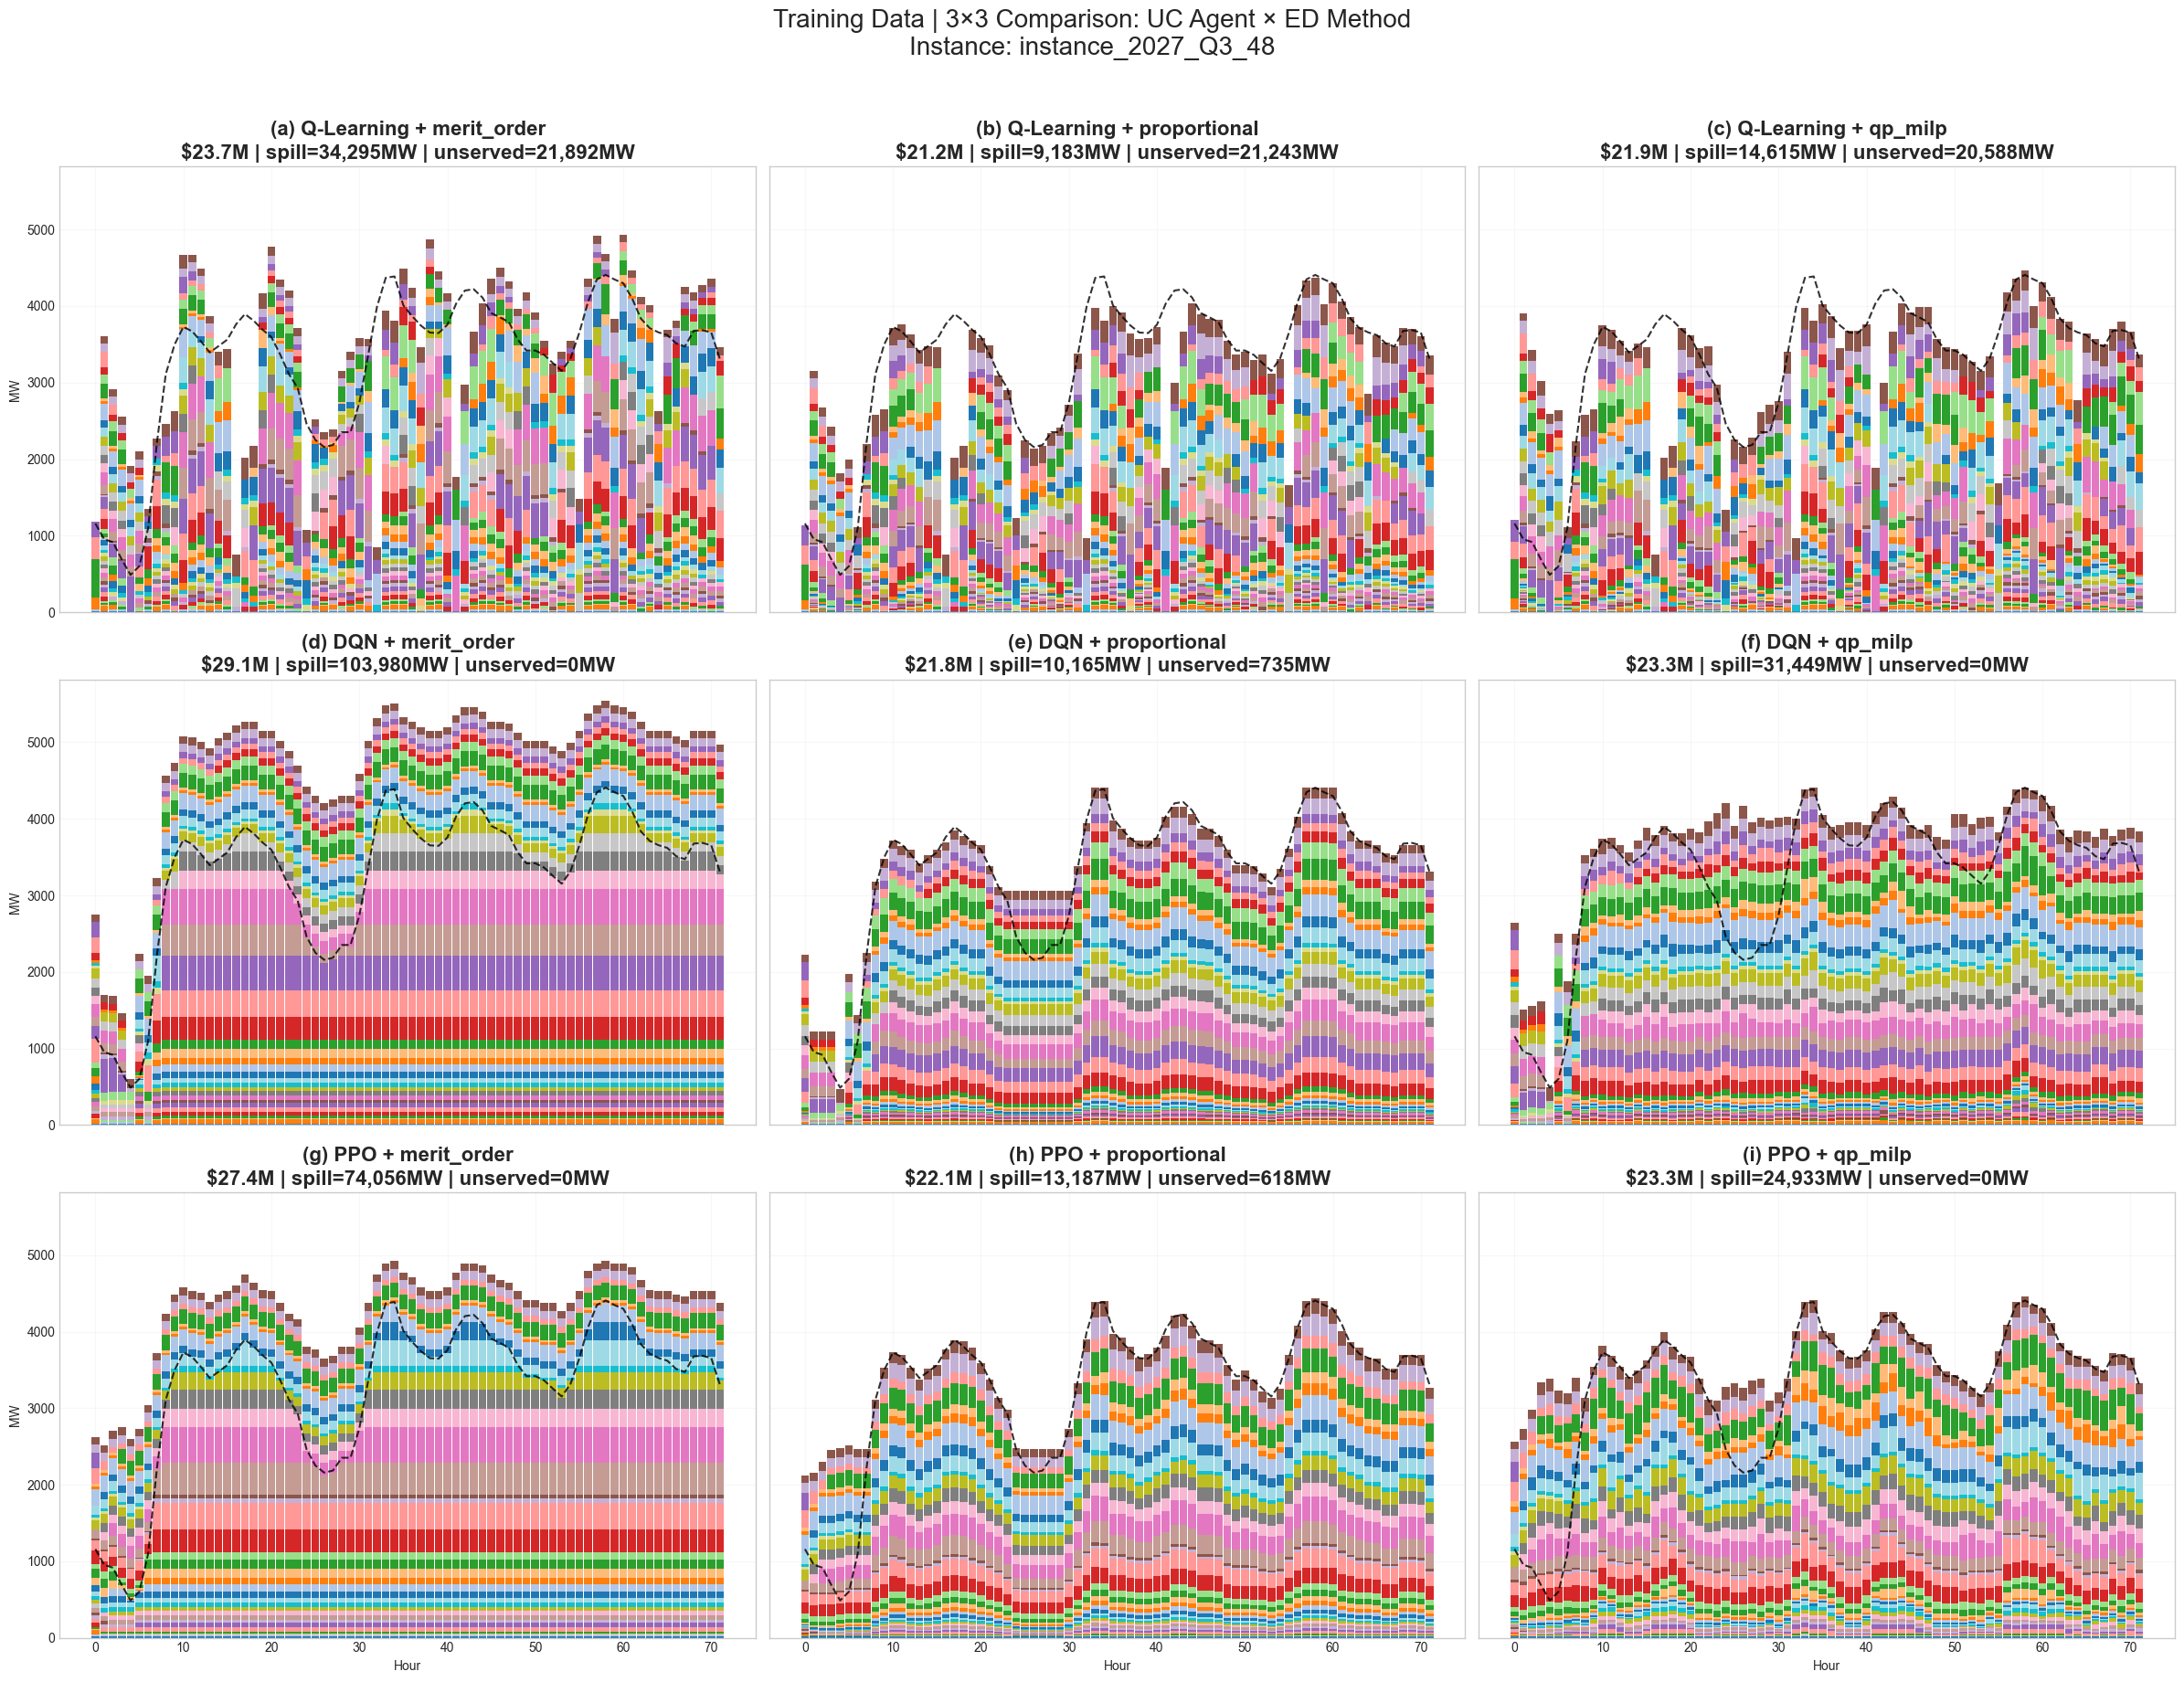

In [74]:
# ── Run ──
instance_id = traces_3x3[list(traces_3x3.keys())[0]]["instance_id"].iloc[0]
plot_3x3_dispatch(traces_3x3, env, instance_id=instance_id, data_label="Training Data")

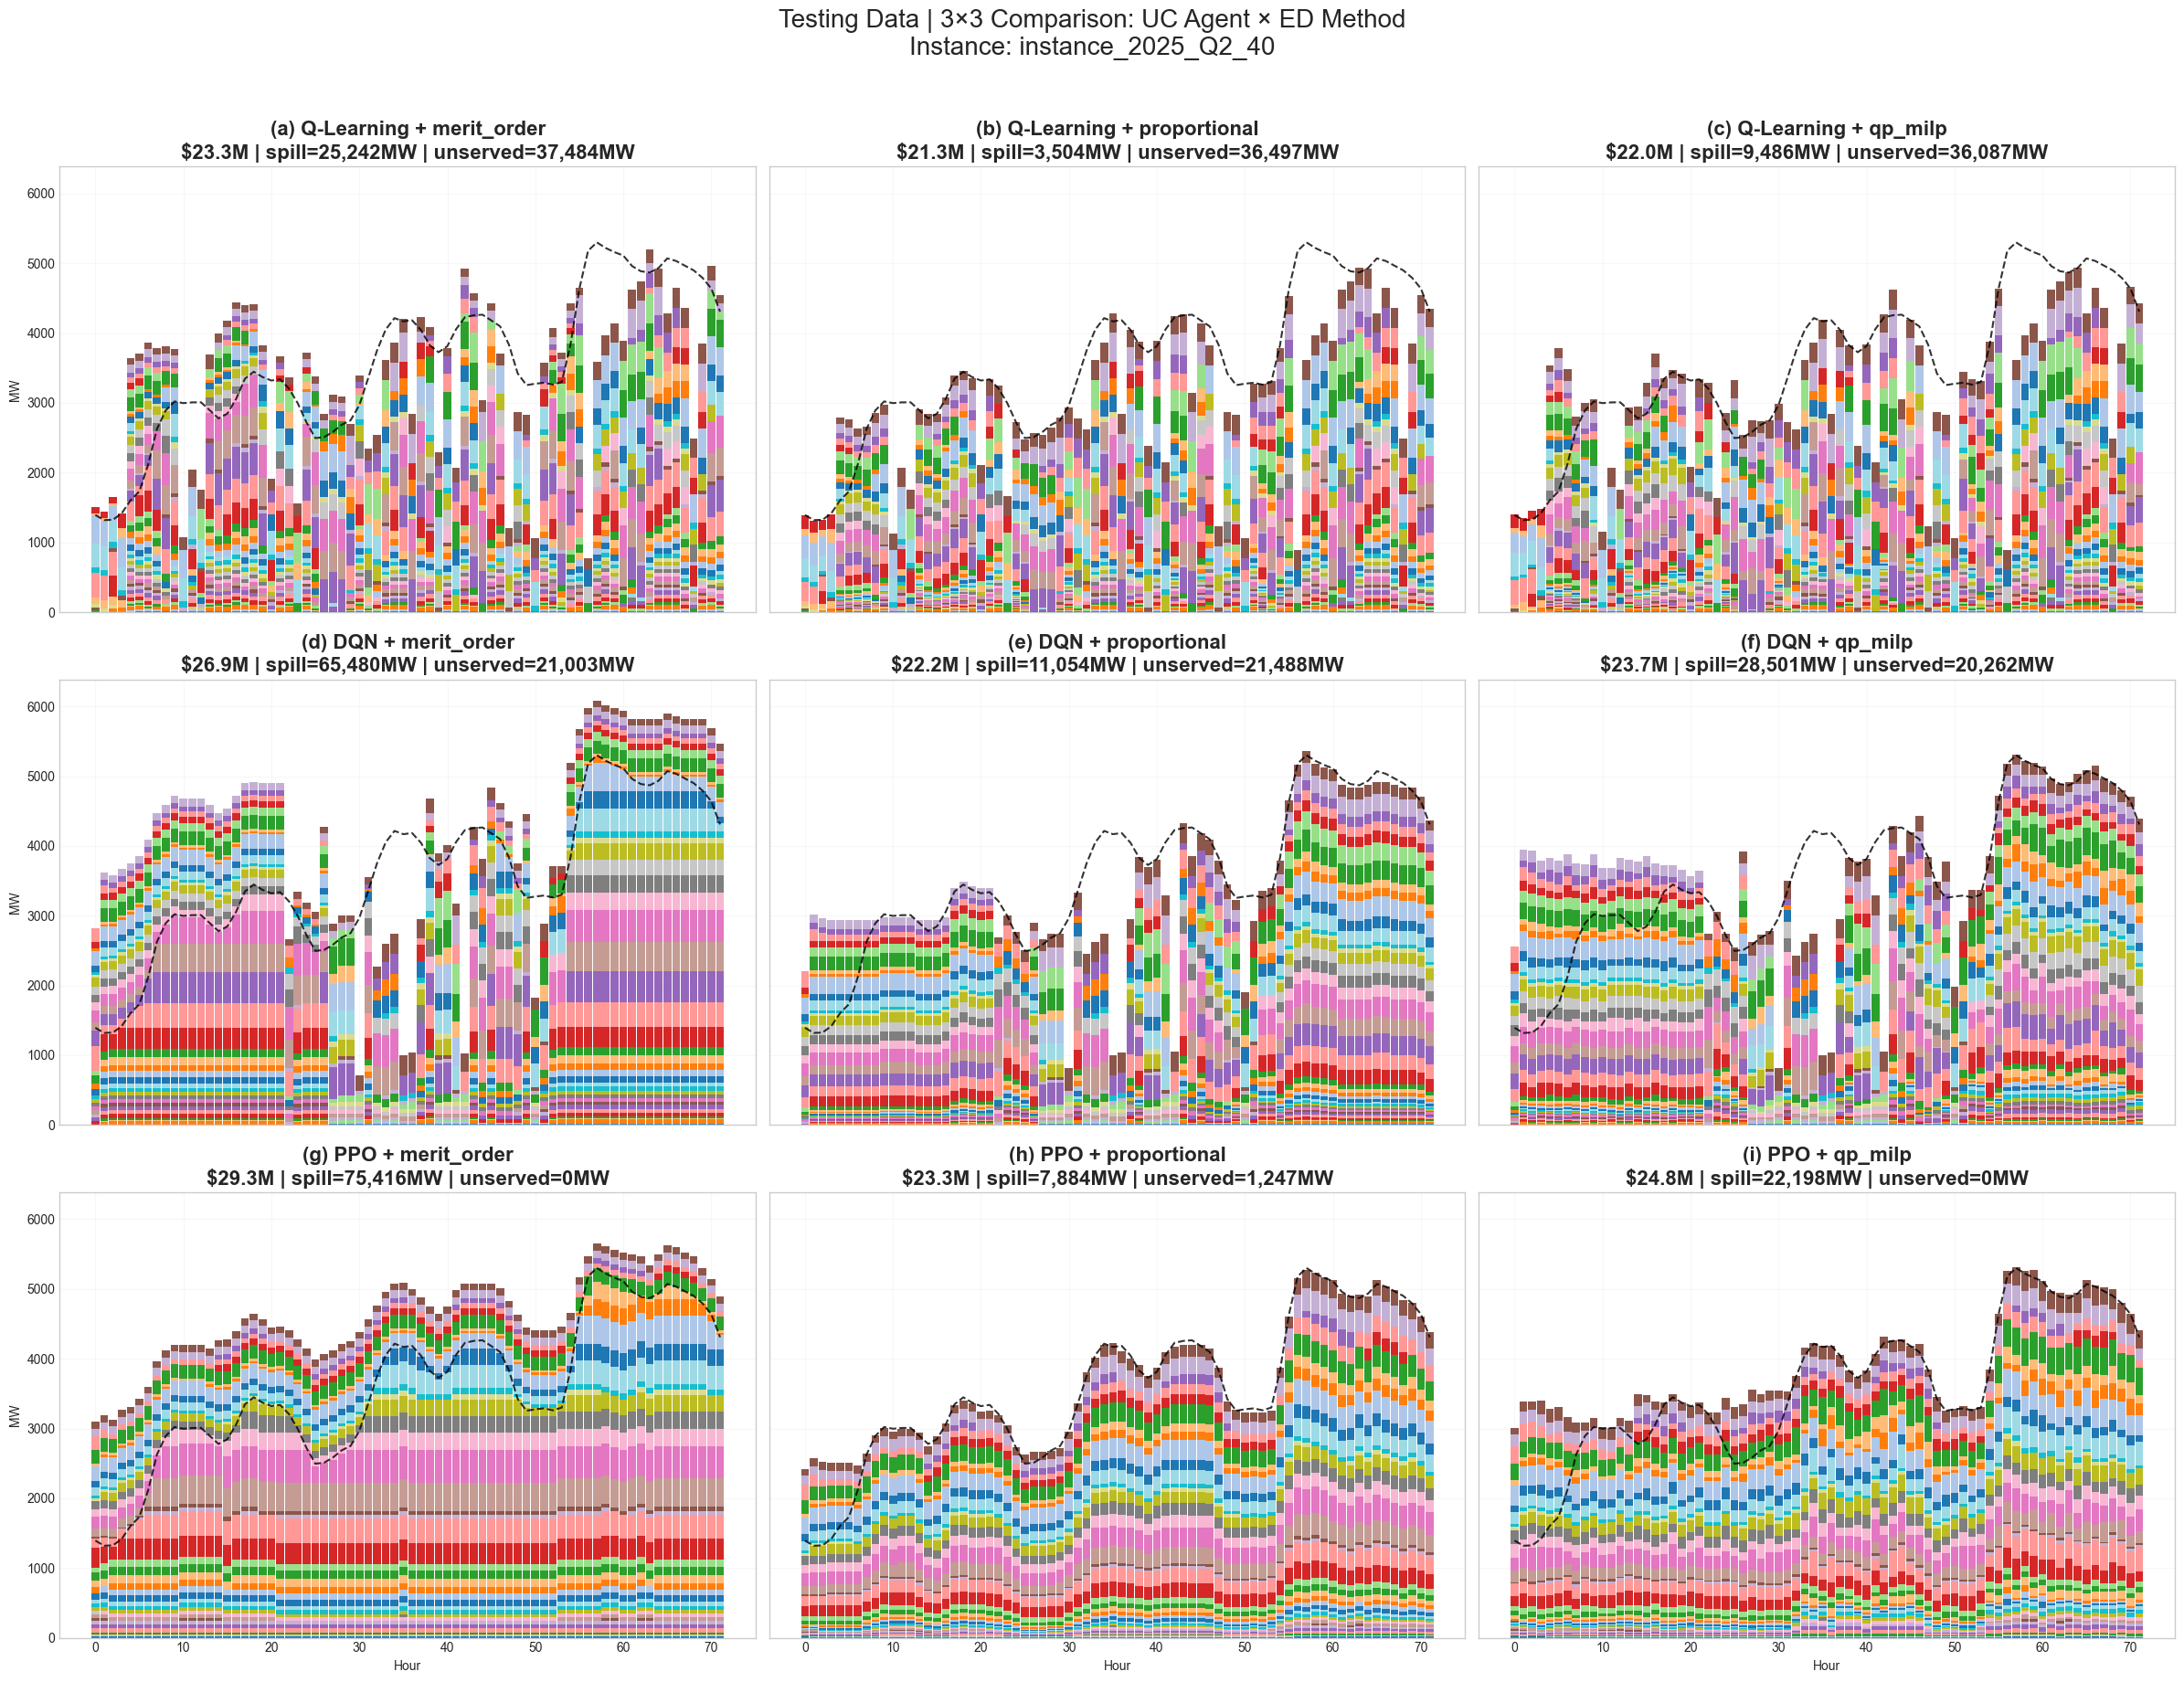

In [78]:
# ── Test data 3x3 ──
TEST_IDX = 15

traces_3x3_test = {}
for uc_name, uc_pol in UC_POLICIES.items():
    for ed_name, ed_fn in ED_METHODS.items():
        tr = apply_ed_to_uc(env, uc_pol, ed_fn, test_episodes, TEST_IDX)
        traces_3x3_test[(uc_name, ed_name)] = tr

instance_id = traces_3x3_test[list(traces_3x3_test.keys())[0]]["instance_id"].iloc[0]
plot_3x3_dispatch(traces_3x3_test, env, instance_id=instance_id, data_label="Testing Data")

## 15. Stacked Dispatch — 3×3 Grid

In [38]:
train_episodes[0]['instance_id'], test_episodes[0]['instance_id']

('instance_2027_Q3_48', 'instance_2026_Q3_8')

In [39]:
traces_3x3[(list(UC_POLICIES.keys())[0], list(ED_METHODS.keys())[0])].head()

,instance_id,hour,net_demand,required_mw,on,dispatch,fuel_cost,startup_cost,cost,unserved,spill,n_startups,n_online,feasible
0,instance_2027_Q3_48,0,1158.671604,1158.671604,"[1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[17.6, 0.0, 61.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...",84529.876450,79450.10631,2.678192e+05,0.0,207.678396,4,11,True
1,instance_2027_Q3_48,1,953.180067,953.180067,"[1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[17.6, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",73964.227240,0.00000,9.417419e+04,0.0,40.419933,0,7,True
2,instance_2027_Q3_48,2,915.595281,915.595281,"[1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[17.6, 21.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...",126235.391081,76465.98511,5.880037e+05,0.0,770.604719,10,16,True
3,instance_2027_Q3_48,3,688.096269,688.096269,"[1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[17.6, 0.0, 51.85, 0.0, 0.0, 0.0, 0.0, 0.0, 0....",189396.964531,47337.35835,1.146711e+06,0.0,1819.953731,10,23,True
4,instance_2027_Q3_48,4,487.164087,487.164087,"[1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[17.6, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",152306.767363,0.00000,9.081247e+05,0.0,1511.635913,0,16,True


In [40]:
# # ── Load saved models ──
# SAVE_DIR = Path("saved_models_v7new")

# # ── Q-Learning ──
# with open(SAVE_DIR/"q_factored.pkl","rb") as f:
#     q_data = pickle.load(f)

# Q_tables = [defaultdict(lambda: np.zeros(2)) for _ in range(env.n_gen)]
# for i, q_dict in enumerate(q_data["Q_tables"]):
#     Q_tables[i].update(q_dict)
# OBS_LO = q_data["OBS_LO"]
# OBS_HI = q_data["OBS_HI"]

# def q_policy(obs, epsilon=0.0):
#     action = np.zeros(env.n_gen, int)
#     for i in range(env.n_gen):
#         s = discretize_state(obs, i)
#         action[i] = np.random.randint(2) if np.random.rand() < epsilon \
#                     else int(np.argmax(Q_tables[i][s]))
#     return action

# print(f"Q-Learning loaded | Q-tables: {len(Q_tables)} | "
#       f"States visited (gen0): {len(Q_tables[0])}")

# # ── Branching DQN ──
# dqn_data = torch.load(SAVE_DIR/"branching_dqn.pt", map_location="cpu")
# STATE_DIM = dqn_data["state_dim"]

# pol_net = DQN(STATE_DIM, dqn_data["n_gen"]).to(DEVICE)
# pol_net.load_state_dict(dqn_data["state_dict"])
# pol_net.eval()

# def dqn_policy(obs):
#     return pol_net.get_action(obs, 0.0)

# print(f"DQN loaded | state_dim={STATE_DIM} | n_gen={dqn_data['n_gen']}")

# # ── PPO ──
# from stable_baselines3 import PPO as SB3_PPO
# ppo_model = SB3_PPO.load(SAVE_DIR/"ppo_uc", device=str(DEVICE))

# def ppo_policy(obs):
#     a, _ = ppo_model.predict(obs, deterministic=True)
#     return np.asarray(a).ravel()

# print(f"PPO loaded | policy: {ppo_model.policy.__class__.__name__}")

# # ── Results CSV ──
# res_df = pd.read_csv(SAVE_DIR/"results_3x3_50instances.csv")
# print(f"Results loaded | {len(res_df)} rows | "
#       f"columns: {list(res_df.columns)}")

# # ── Verify all policies work ──
# print("\nVerifying policies...")
# obs = _reset(env, 0)
# print(f"  Q-Learning action: {q_policy(obs, 0.0).sum()} generators ON")
# print(f"  DQN action:        {dqn_policy(obs).sum()} generators ON")
# print(f"  PPO action:        {ppo_policy(obs).sum()} generators ON")

# # ── Rebuild UC_POLICIES dict ──
# UC_POLICIES = {
#     "Q-Learning": lambda o: q_policy(o, 0.0),
#     "DQN":        dqn_policy,
#     "PPO":        ppo_policy,
# }
# print("\nUC_POLICIES ready:", list(UC_POLICIES.keys()))

C:\Users\HP\AppData\Local\Temp\ipykernel_49936\4227552264.py:69: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\HP\AppData\Local\Temp\ipykernel_49936\4227552264.py:69: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) Arial.
  plt.tight_layout()
c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


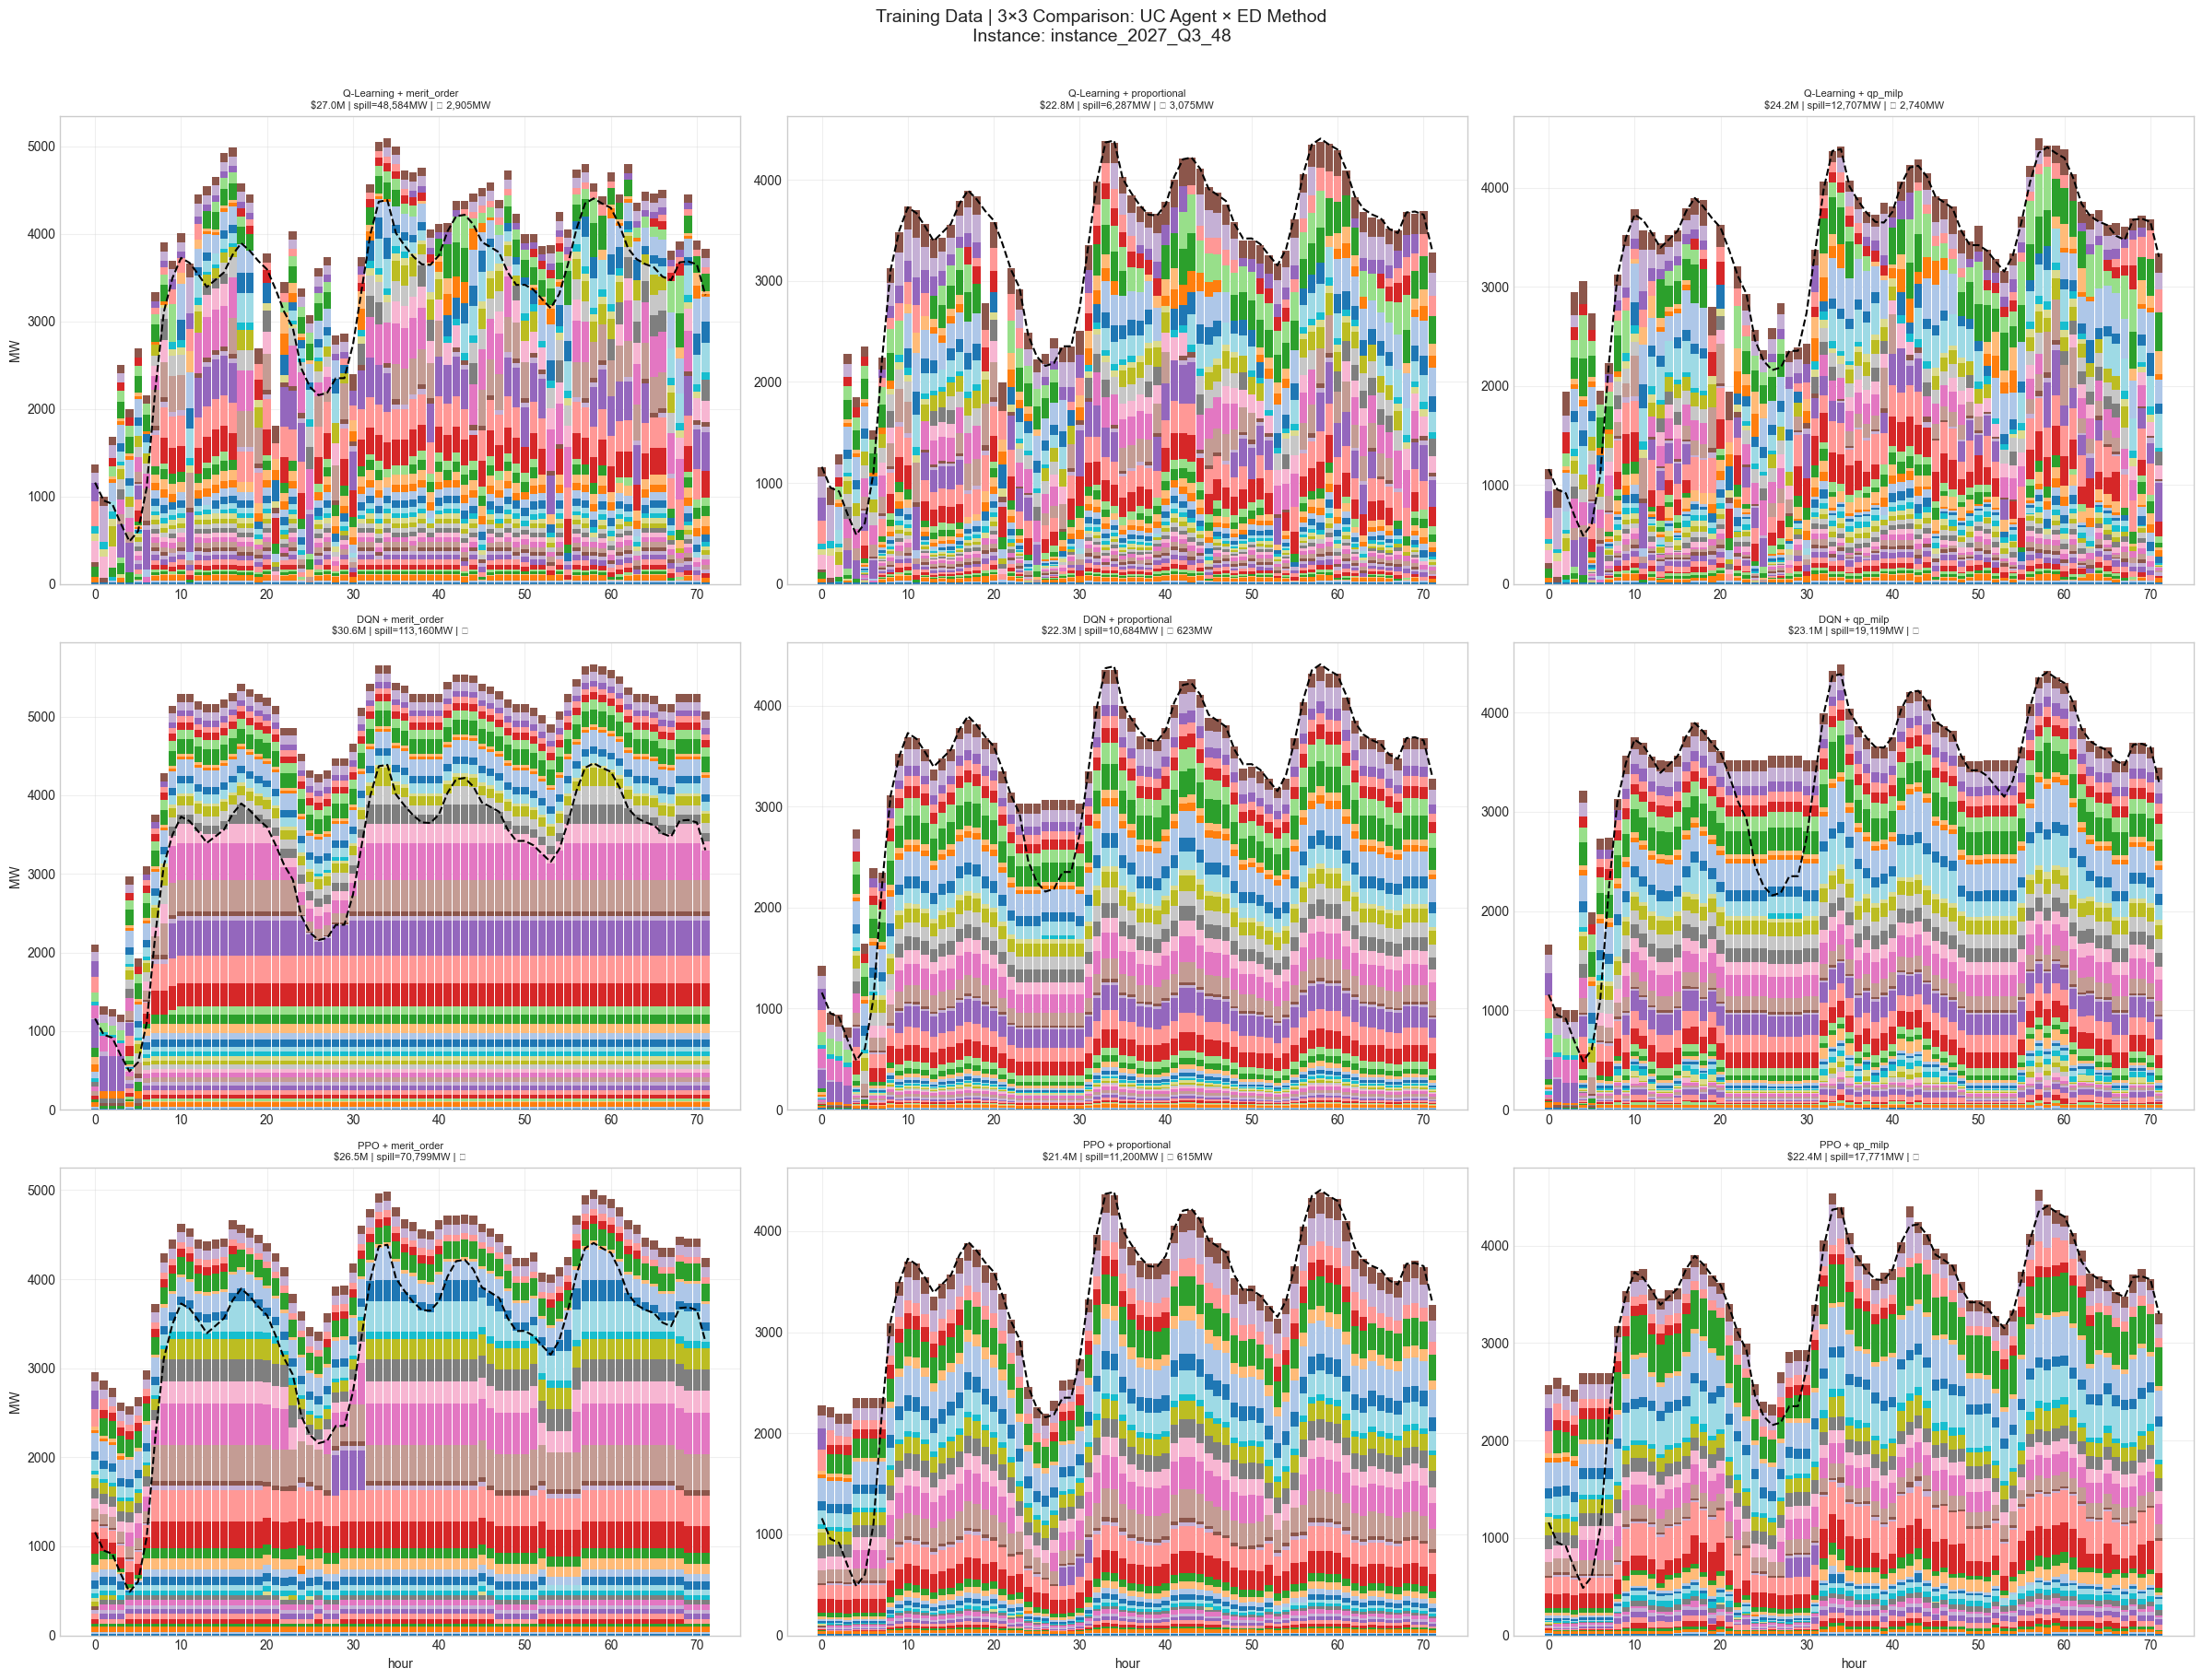

In [41]:
# ── Collect traces untuk instance yang mau dilihat ──
INSTANCE_IDX = 0

traces_3x3 = {}
for uc_name, uc_pol in UC_POLICIES.items():
    for ed_name, ed_fn in ED_METHODS.items():
        traces_3x3[(uc_name, ed_name)] = apply_ed_to_uc(
            env, uc_pol, ed_fn,
            train_episodes,          # ganti test_episodes kalau mau test set
            instance_index=INSTANCE_IDX,
            levels=ED_LEVELS,
        )

instance_id = train_episodes[INSTANCE_IDX]["instance_id"]

# ── Plot 3×3 ──
fig, axes = plt.subplots(3, 3, figsize=(24, 18))
fig.suptitle(f"Training Data | 3×3 Comparison: UC Agent × ED Method\nInstance: {instance_id}",
             fontsize=14, y=1.01)

cmap   = plt.cm.tab20
colors = [cmap(i % 20 / 20) for i in range(env.n_gen)]

ed_names = list(ED_METHODS.keys())
uc_names = list(UC_POLICIES.keys())

for row, uc_name in enumerate(uc_names):
    for col, ed_name in enumerate(ed_names):
        ax  = axes[row, col]
        tr  = traces_3x3[(uc_name, ed_name)]
        hours = tr["hour"].values
        dm    = np.vstack(tr["dispatch"].values)
        n_h   = len(hours)

        # Net demand — ambil dari episodes langsung
        nd = train_episodes[INSTANCE_IDX]["net_demand"][:n_h]

        bottom_pos = np.zeros(n_h)
        bottom_neg = np.zeros(n_h)
        for i in range(env.n_gen):
            pos = np.clip(dm[:, i], 0, None)
            neg = np.clip(dm[:, i], None, 0)
            if pos.any():
                ax.bar(hours, pos, bottom=bottom_pos, width=0.9,
                    color=colors[i], edgecolor="none")
                bottom_pos += pos
            if neg.any():
                ax.bar(hours, neg, bottom=bottom_neg, width=0.9,
                    color=colors[i], edgecolor="none")
                bottom_neg += neg
        ax.plot(hours, nd, "k--", lw=1.5, label="net demand")

        cost = tr["fuel_cost"].sum() + tr["startup_cost"].sum()
        spill = tr["spill"].sum()
        uns   = tr["unserved"].sum()
        feas  = "✅" if uns < 1.0 else f"❌ {uns:,.0f}MW"

        ax.set_title(
            f"{uc_name} + {ed_name}\n"
            f"${cost/1e6:.1f}M | spill={spill:,.0f}MW | {feas}",
            fontsize=8)
        ax.set_ylabel("MW" if col == 0 else "")
        ax.set_xlabel("hour" if row == 2 else "")
        ax.grid(True, alpha=0.3)

        # Y-axis limit consistent per row
        axes[row, 0].set_ylim(bottom=0)

plt.tight_layout()
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_49936\2251841415.py:69: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) Arial.
  plt.tight_layout()


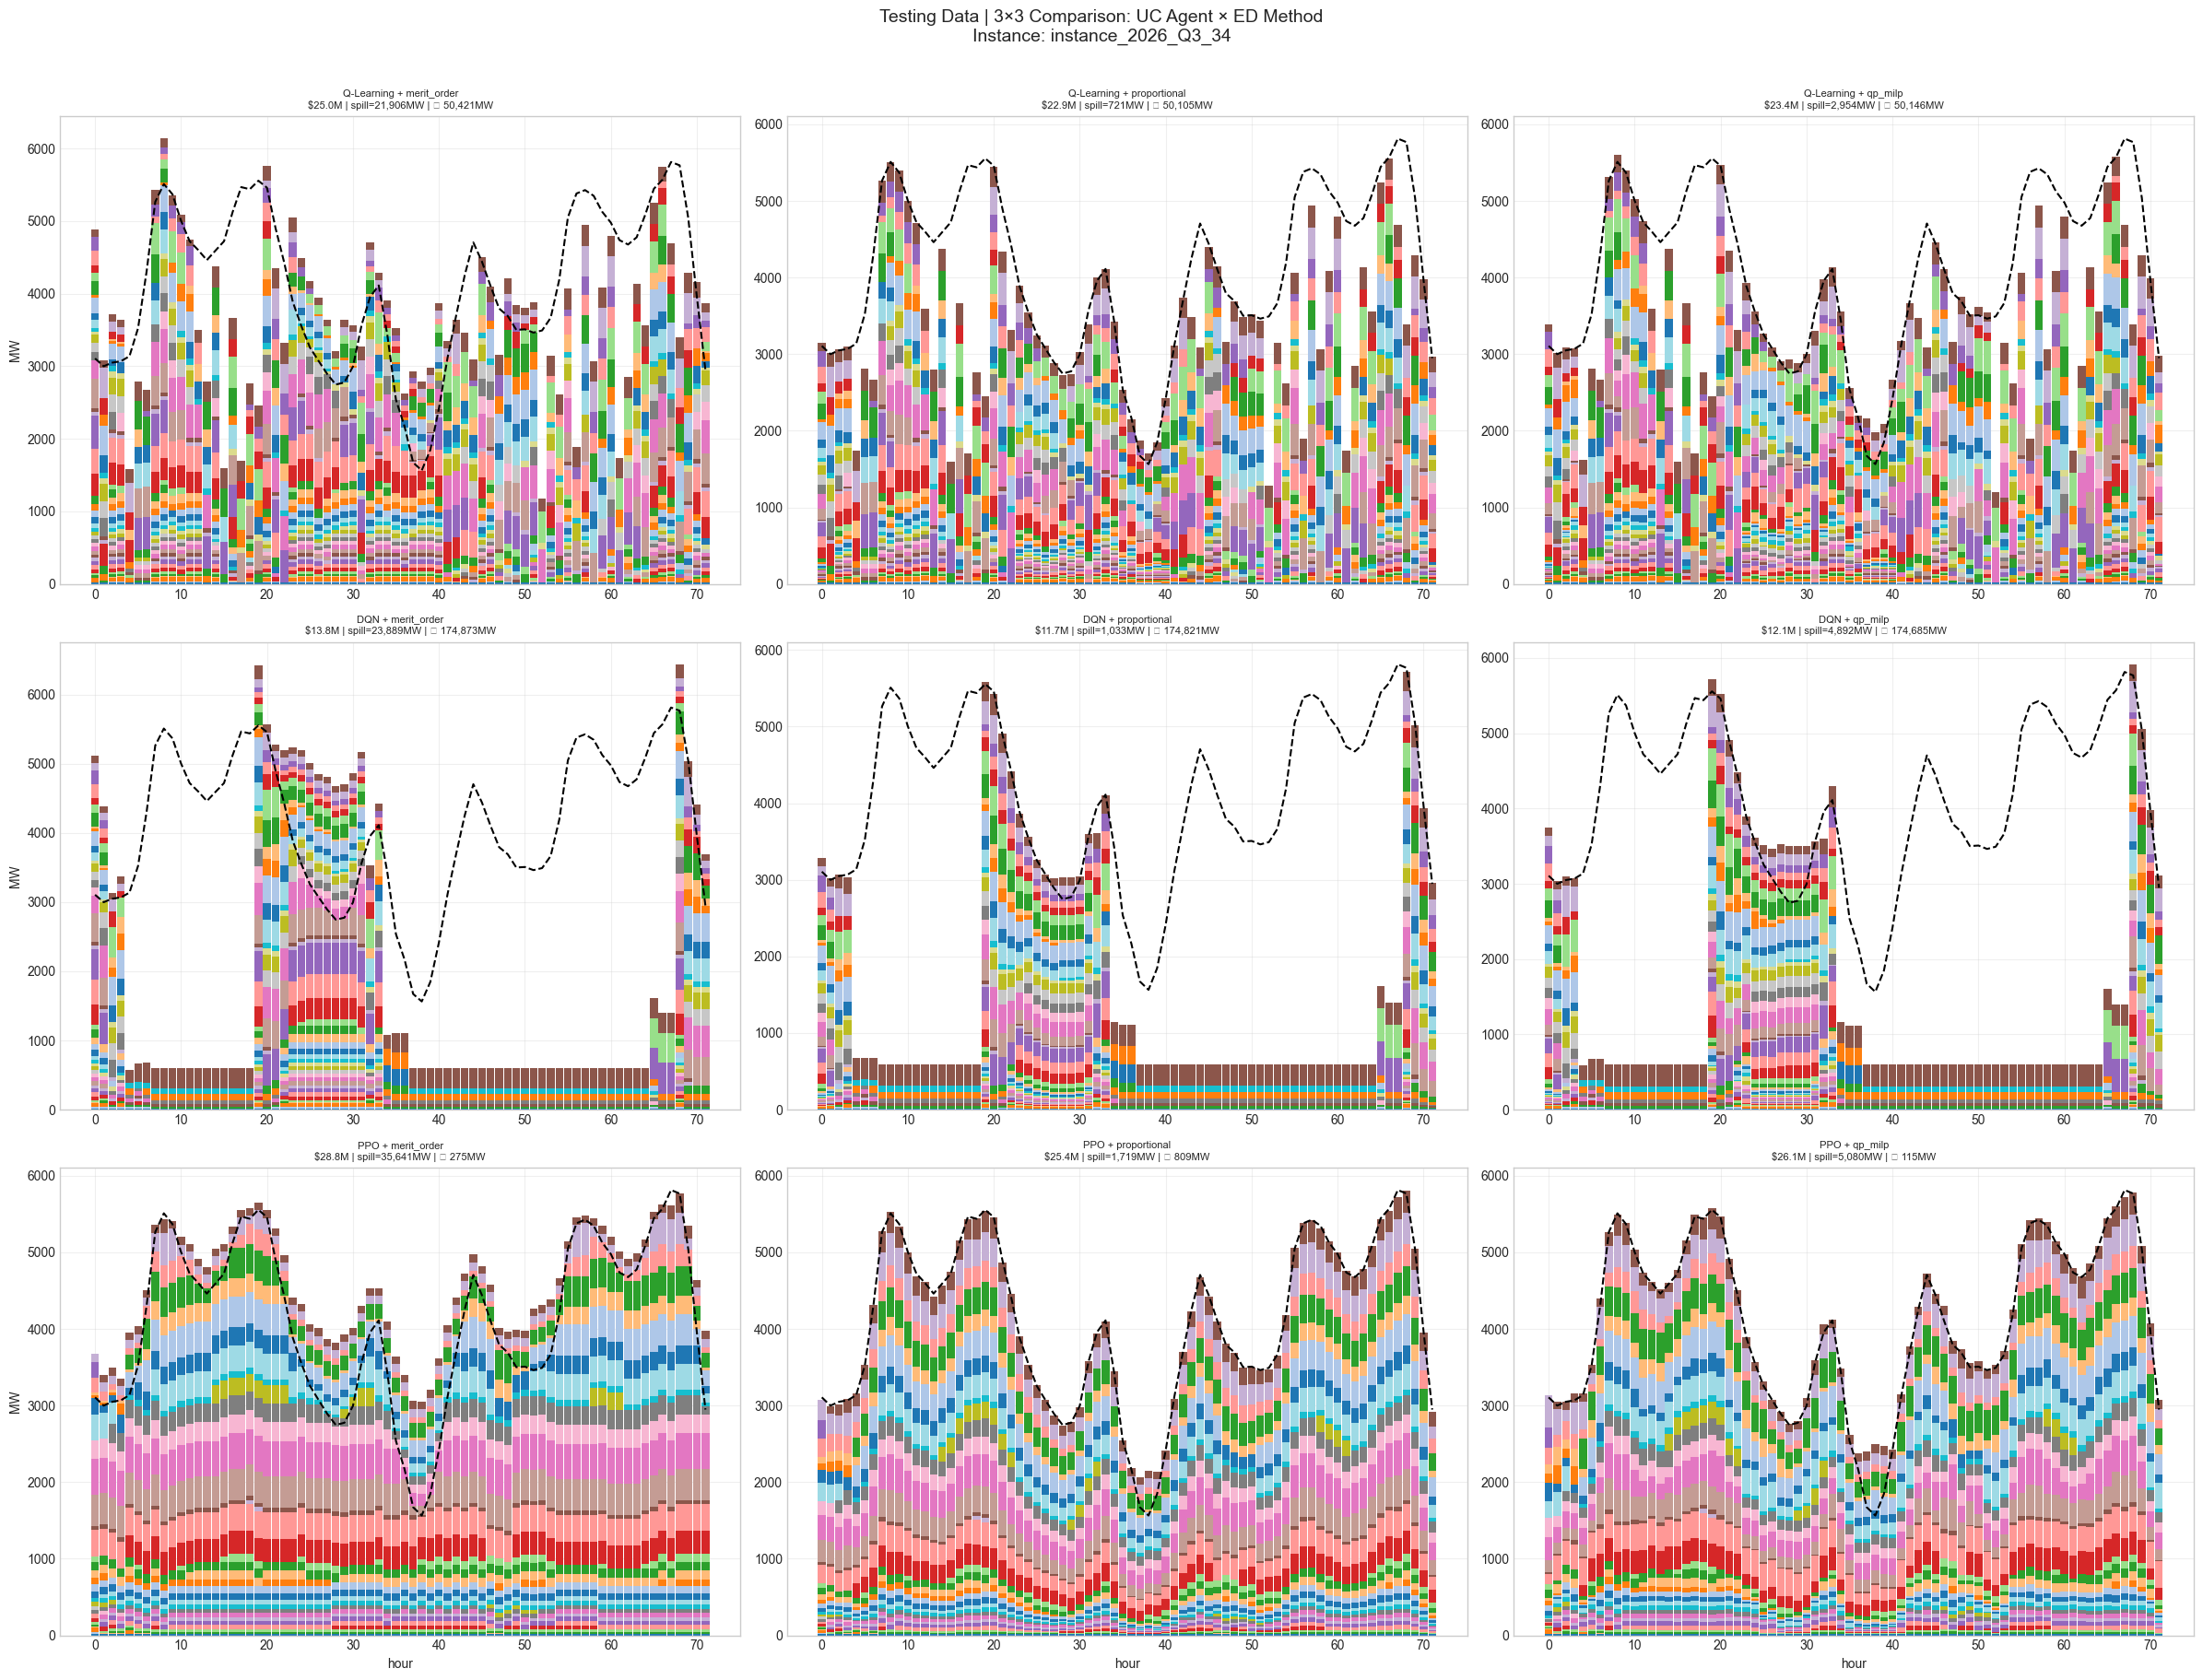

In [42]:
# ── Collect traces untuk instance yang mau dilihat ──
INSTANCE_IDX = 20

traces_3x3 = {}
for uc_name, uc_pol in UC_POLICIES.items():
    for ed_name, ed_fn in ED_METHODS.items():
        traces_3x3[(uc_name, ed_name)] = apply_ed_to_uc(
            env, uc_pol, ed_fn,
            test_episodes,          # ganti test_episodes kalau mau test set
            instance_index=INSTANCE_IDX,
            levels=ED_LEVELS,
        )

instance_id = test_episodes[INSTANCE_IDX]["instance_id"]

# ── Plot 3×3 ──
fig, axes = plt.subplots(3, 3, figsize=(24, 18))
fig.suptitle(f"Testing Data | 3×3 Comparison: UC Agent × ED Method\nInstance: {instance_id}",
             fontsize=14, y=1.01)

cmap   = plt.cm.tab20
colors = [cmap(i % 20 / 20) for i in range(env.n_gen)]

ed_names = list(ED_METHODS.keys())
uc_names = list(UC_POLICIES.keys())

for row, uc_name in enumerate(uc_names):
    for col, ed_name in enumerate(ed_names):
        ax  = axes[row, col]
        tr  = traces_3x3[(uc_name, ed_name)]
        hours = tr["hour"].values
        dm    = np.vstack(tr["dispatch"].values)
        n_h   = len(hours)

        # Net demand — ambil dari episodes langsung
        nd = test_episodes[INSTANCE_IDX]["net_demand"][:n_h]

        bottom_pos = np.zeros(n_h)
        bottom_neg = np.zeros(n_h)
        for i in range(env.n_gen):
            pos = np.clip(dm[:, i], 0, None)
            neg = np.clip(dm[:, i], None, 0)
            if pos.any():
                ax.bar(hours, pos, bottom=bottom_pos, width=0.9,
                    color=colors[i], edgecolor="none")
                bottom_pos += pos
            if neg.any():
                ax.bar(hours, neg, bottom=bottom_neg, width=0.9,
                    color=colors[i], edgecolor="none")
                bottom_neg += neg
        ax.plot(hours, nd, "k--", lw=1.5, label="net demand")

        cost = tr["fuel_cost"].sum() + tr["startup_cost"].sum()
        spill = tr["spill"].sum()
        uns   = tr["unserved"].sum()
        feas  = "✅" if uns < 1.0 else f"❌ {uns:,.0f}MW"

        ax.set_title(
            f"{uc_name} + {ed_name}\n"
            f"${cost/1e6:.1f}M | spill={spill:,.0f}MW | {feas}",
            fontsize=8)
        ax.set_ylabel("MW" if col == 0 else "")
        ax.set_xlabel("hour" if row == 2 else "")
        ax.grid(True, alpha=0.3)

        # Y-axis limit consistent per row
        axes[row, 0].set_ylim(bottom=0)

plt.tight_layout()
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_49936\2124721059.py:69: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\HP\AppData\Local\Temp\ipykernel_49936\2124721059.py:69: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) Arial.
  plt.tight_layout()


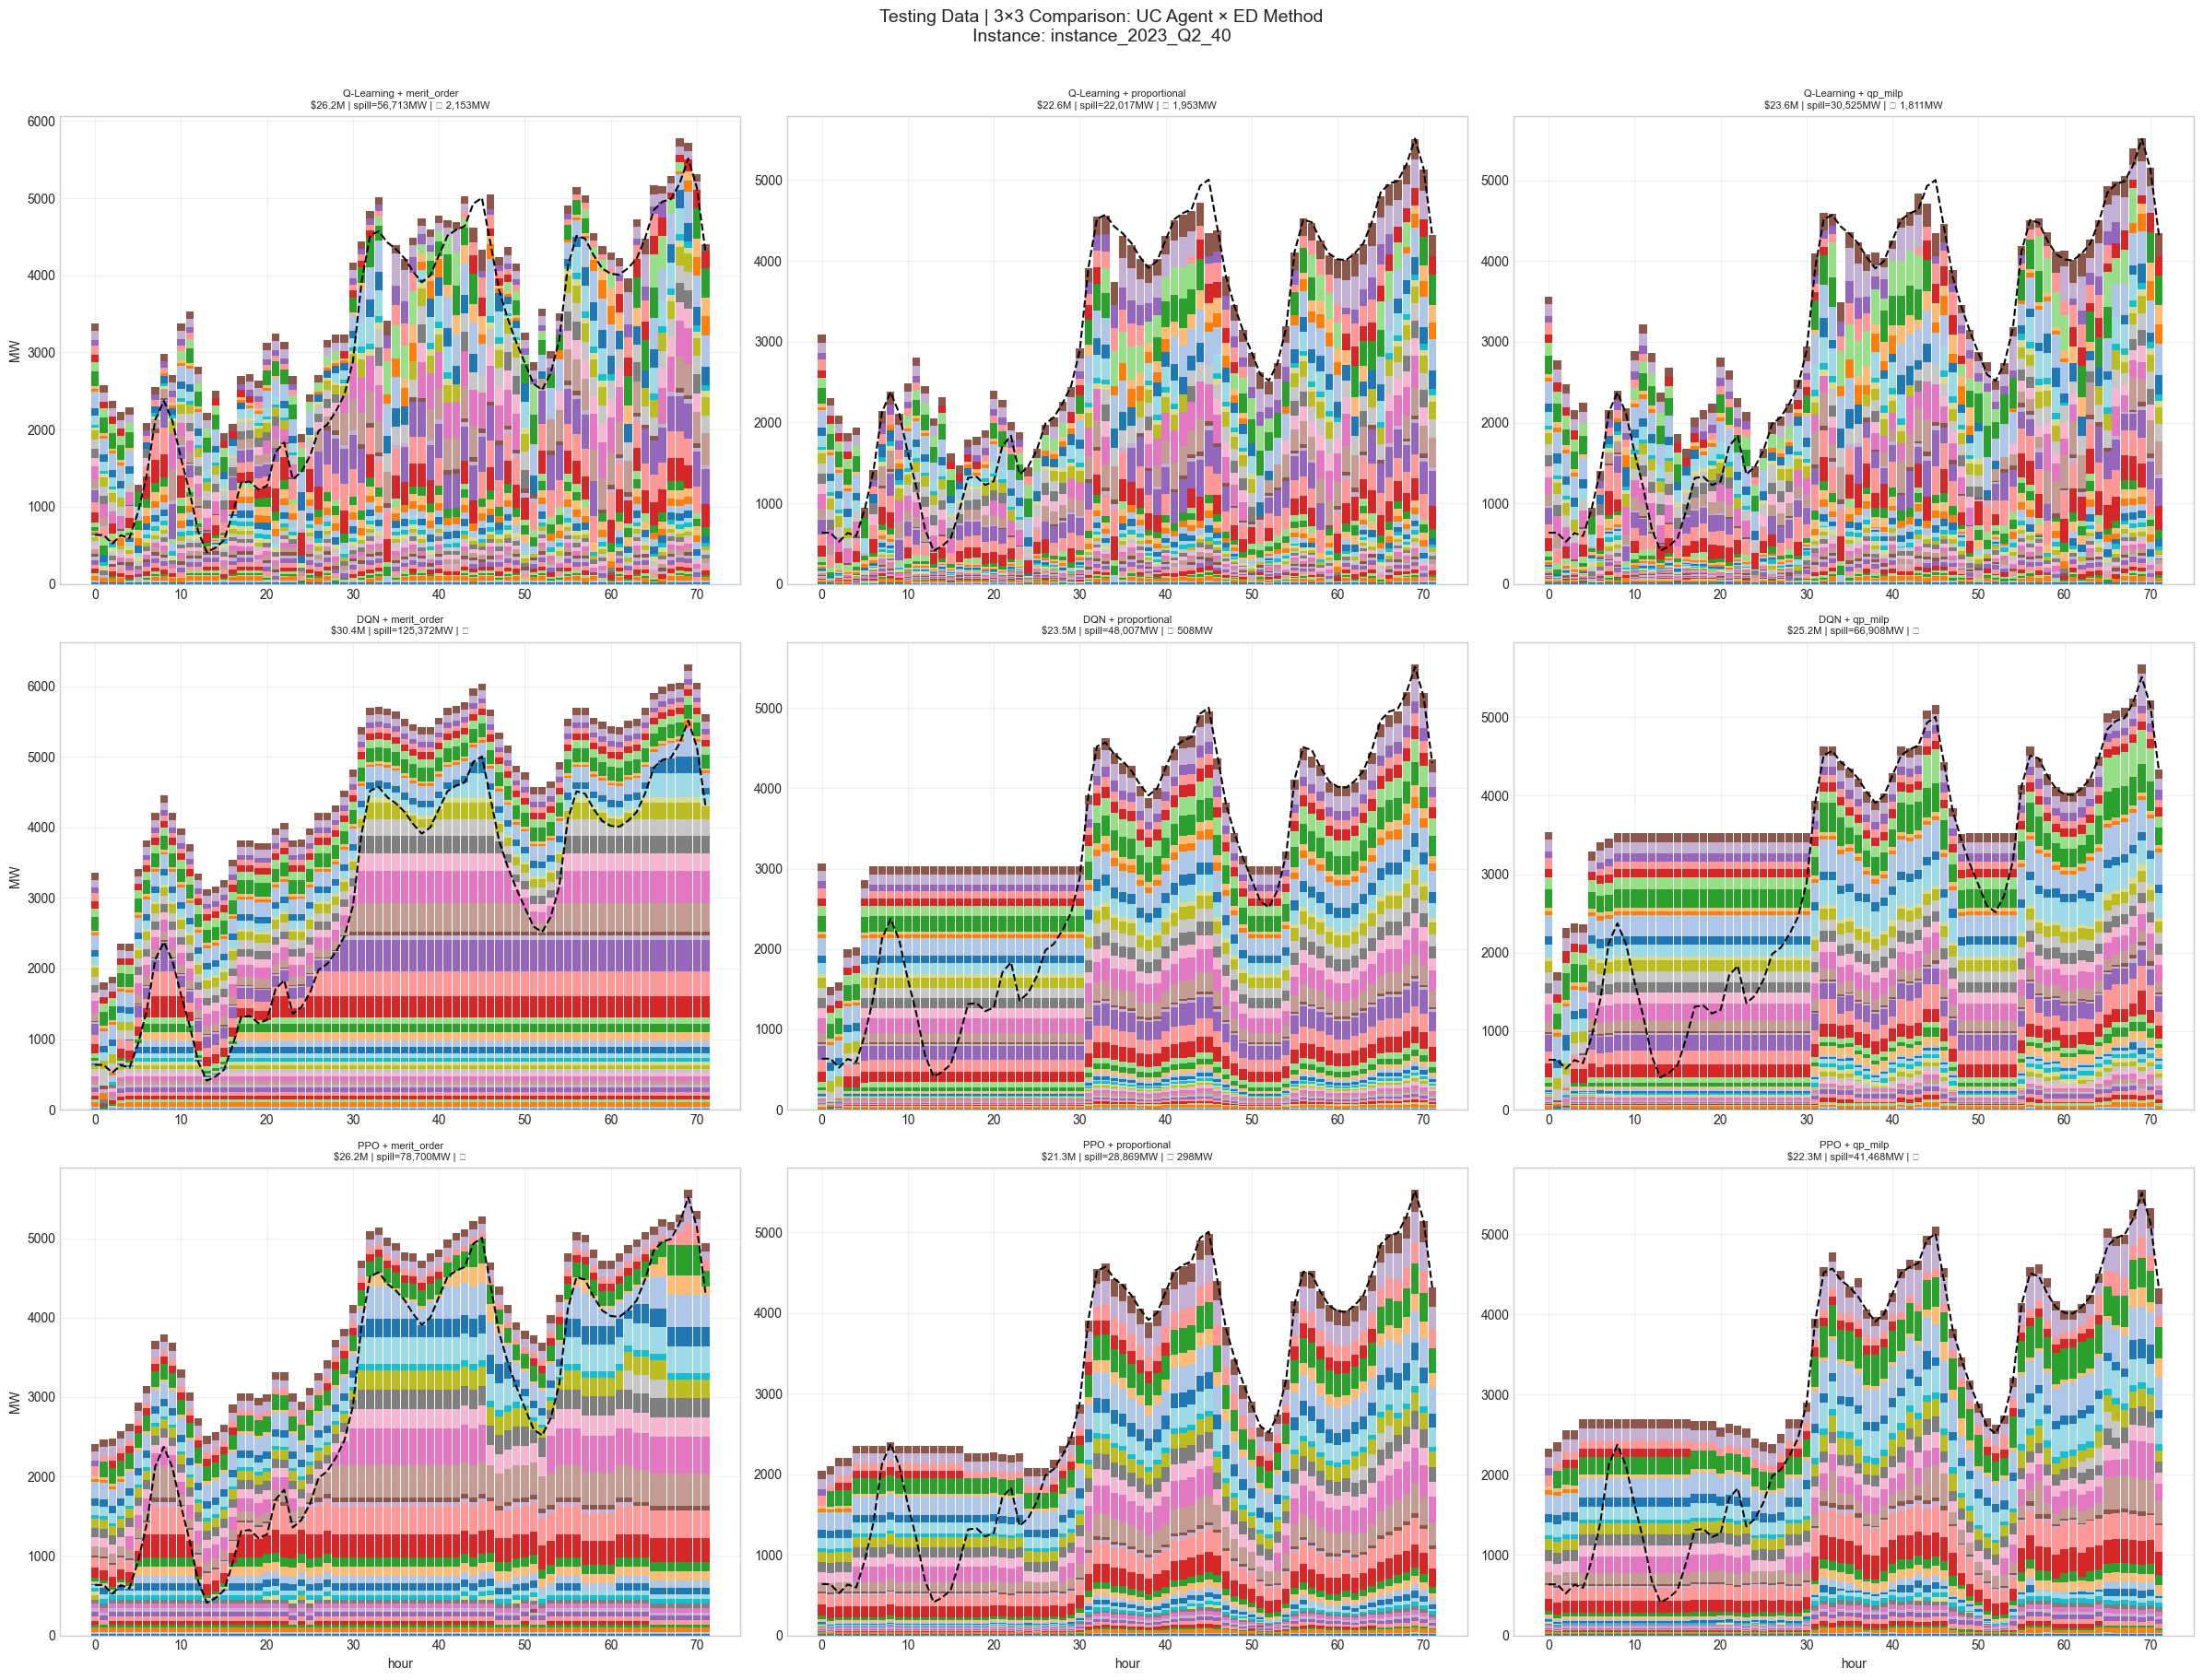

In [43]:
# ── Collect traces untuk instance yang mau dilihat ──
INSTANCE_IDX = 9

traces_3x3 = {}
for uc_name, uc_pol in UC_POLICIES.items():
    for ed_name, ed_fn in ED_METHODS.items():
        traces_3x3[(uc_name, ed_name)] = apply_ed_to_uc(
            env, uc_pol, ed_fn,
            test_episodes,          # ganti test_episodes kalau mau test set
            instance_index=INSTANCE_IDX,
            levels=ED_LEVELS,
        )

instance_id = test_episodes[INSTANCE_IDX]["instance_id"]

# ── Plot 3×3 ──
fig, axes = plt.subplots(3, 3, figsize=(24, 18))
fig.suptitle(f"Testing Data | 3×3 Comparison: UC Agent × ED Method\nInstance: {instance_id}",
             fontsize=14, y=1.01)

cmap   = plt.cm.tab20
colors = [cmap(i % 20 / 20) for i in range(env.n_gen)]

ed_names = list(ED_METHODS.keys())
uc_names = list(UC_POLICIES.keys())

for row, uc_name in enumerate(uc_names):
    for col, ed_name in enumerate(ed_names):
        ax  = axes[row, col]
        tr  = traces_3x3[(uc_name, ed_name)]
        hours = tr["hour"].values
        dm    = np.vstack(tr["dispatch"].values)
        n_h   = len(hours)

        # Net demand — ambil dari episodes langsung
        nd = test_episodes[INSTANCE_IDX]["net_demand"][:n_h]

        bottom_pos = np.zeros(n_h)
        bottom_neg = np.zeros(n_h)
        for i in range(env.n_gen):
            pos = np.clip(dm[:, i], 0, None)
            neg = np.clip(dm[:, i], None, 0)
            if pos.any():
                ax.bar(hours, pos, bottom=bottom_pos, width=0.9,
                    color=colors[i], edgecolor="none")
                bottom_pos += pos
            if neg.any():
                ax.bar(hours, neg, bottom=bottom_neg, width=0.9,
                    color=colors[i], edgecolor="none")
                bottom_neg += neg
        ax.plot(hours, nd, "k--", lw=1.5, label="net demand")

        cost = tr["fuel_cost"].sum() + tr["startup_cost"].sum()
        spill = tr["spill"].sum()
        uns   = tr["unserved"].sum()
        feas  = "✅" if uns < 1.0 else f"❌ {uns:,.0f}MW"

        ax.set_title(
            f"{uc_name} + {ed_name}\n"
            f"${cost/1e6:.1f}M | spill={spill:,.0f}MW | {feas}",
            fontsize=8)
        ax.set_ylabel("MW" if col == 0 else "")
        ax.set_xlabel("hour" if row == 2 else "")
        ax.grid(True, alpha=0.3)

        # Y-axis limit consistent per row
        axes[row, 0].set_ylim(bottom=0)

plt.tight_layout()
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_49936\3409650838.py:69: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\HP\AppData\Local\Temp\ipykernel_49936\3409650838.py:69: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) Arial.
  plt.tight_layout()


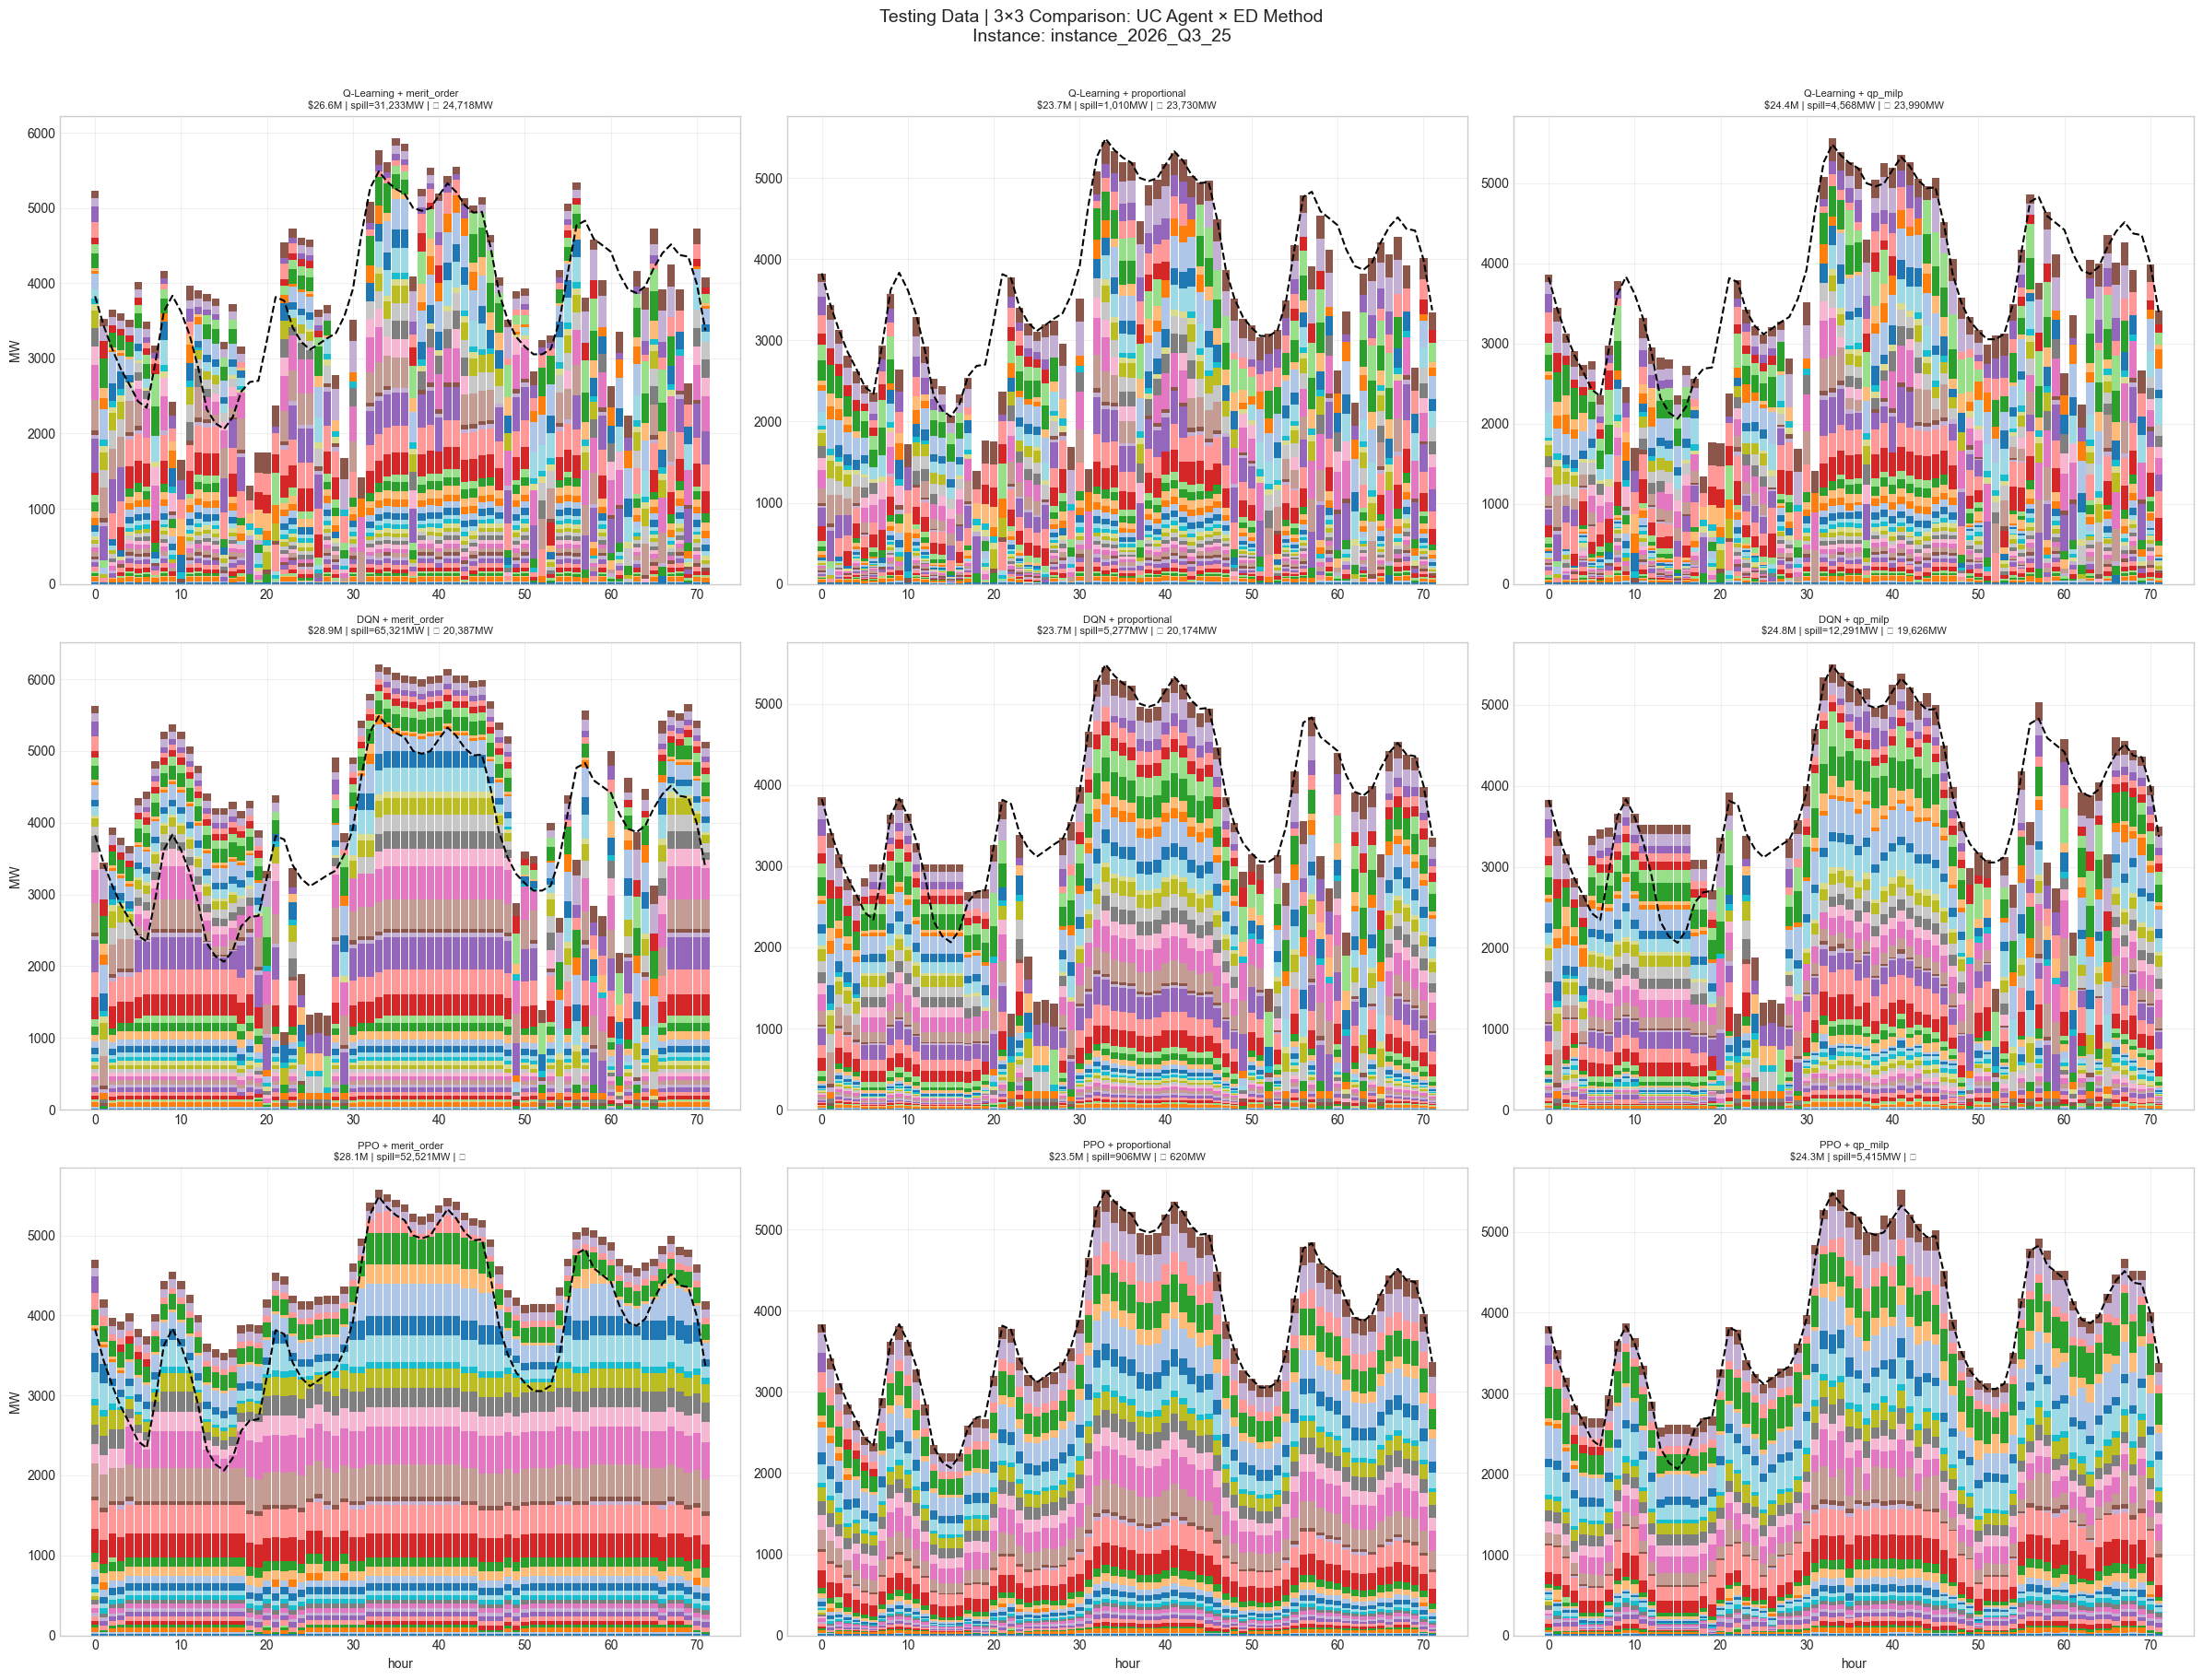

In [44]:
# ── Collect traces untuk instance yang mau dilihat ──
INSTANCE_IDX = 35

traces_3x3 = {}
for uc_name, uc_pol in UC_POLICIES.items():
    for ed_name, ed_fn in ED_METHODS.items():
        traces_3x3[(uc_name, ed_name)] = apply_ed_to_uc(
            env, uc_pol, ed_fn,
            test_episodes,          # ganti test_episodes kalau mau test set
            instance_index=INSTANCE_IDX,
            levels=ED_LEVELS,
        )

instance_id = test_episodes[INSTANCE_IDX]["instance_id"]

# ── Plot 3×3 ──
fig, axes = plt.subplots(3, 3, figsize=(24, 18))
fig.suptitle(f"Testing Data | 3×3 Comparison: UC Agent × ED Method\nInstance: {instance_id}",
             fontsize=14, y=1.01)

cmap   = plt.cm.tab20
colors = [cmap(i % 20 / 20) for i in range(env.n_gen)]

ed_names = list(ED_METHODS.keys())
uc_names = list(UC_POLICIES.keys())

for row, uc_name in enumerate(uc_names):
    for col, ed_name in enumerate(ed_names):
        ax  = axes[row, col]
        tr  = traces_3x3[(uc_name, ed_name)]
        hours = tr["hour"].values
        dm    = np.vstack(tr["dispatch"].values)
        n_h   = len(hours)

        # Net demand — ambil dari episodes langsung
        nd = test_episodes[INSTANCE_IDX]["net_demand"][:n_h]

        bottom_pos = np.zeros(n_h)
        bottom_neg = np.zeros(n_h)
        for i in range(env.n_gen):
            pos = np.clip(dm[:, i], 0, None)
            neg = np.clip(dm[:, i], None, 0)
            if pos.any():
                ax.bar(hours, pos, bottom=bottom_pos, width=0.9,
                    color=colors[i], edgecolor="none")
                bottom_pos += pos
            if neg.any():
                ax.bar(hours, neg, bottom=bottom_neg, width=0.9,
                    color=colors[i], edgecolor="none")
                bottom_neg += neg
        ax.plot(hours, nd, "k--", lw=1.5, label="net demand")

        cost = tr["fuel_cost"].sum() + tr["startup_cost"].sum()
        spill = tr["spill"].sum()
        uns   = tr["unserved"].sum()
        feas  = "✅" if uns < 1.0 else f"❌ {uns:,.0f}MW"

        ax.set_title(
            f"{uc_name} + {ed_name}\n"
            f"${cost/1e6:.1f}M | spill={spill:,.0f}MW | {feas}",
            fontsize=8)
        ax.set_ylabel("MW" if col == 0 else "")
        ax.set_xlabel("hour" if row == 2 else "")
        ax.grid(True, alpha=0.3)

        # Y-axis limit consistent per row
        axes[row, 0].set_ylim(bottom=0)

plt.tight_layout()
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_49936\130517473.py:69: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\HP\AppData\Local\Temp\ipykernel_49936\130517473.py:69: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) Arial.
  plt.tight_layout()


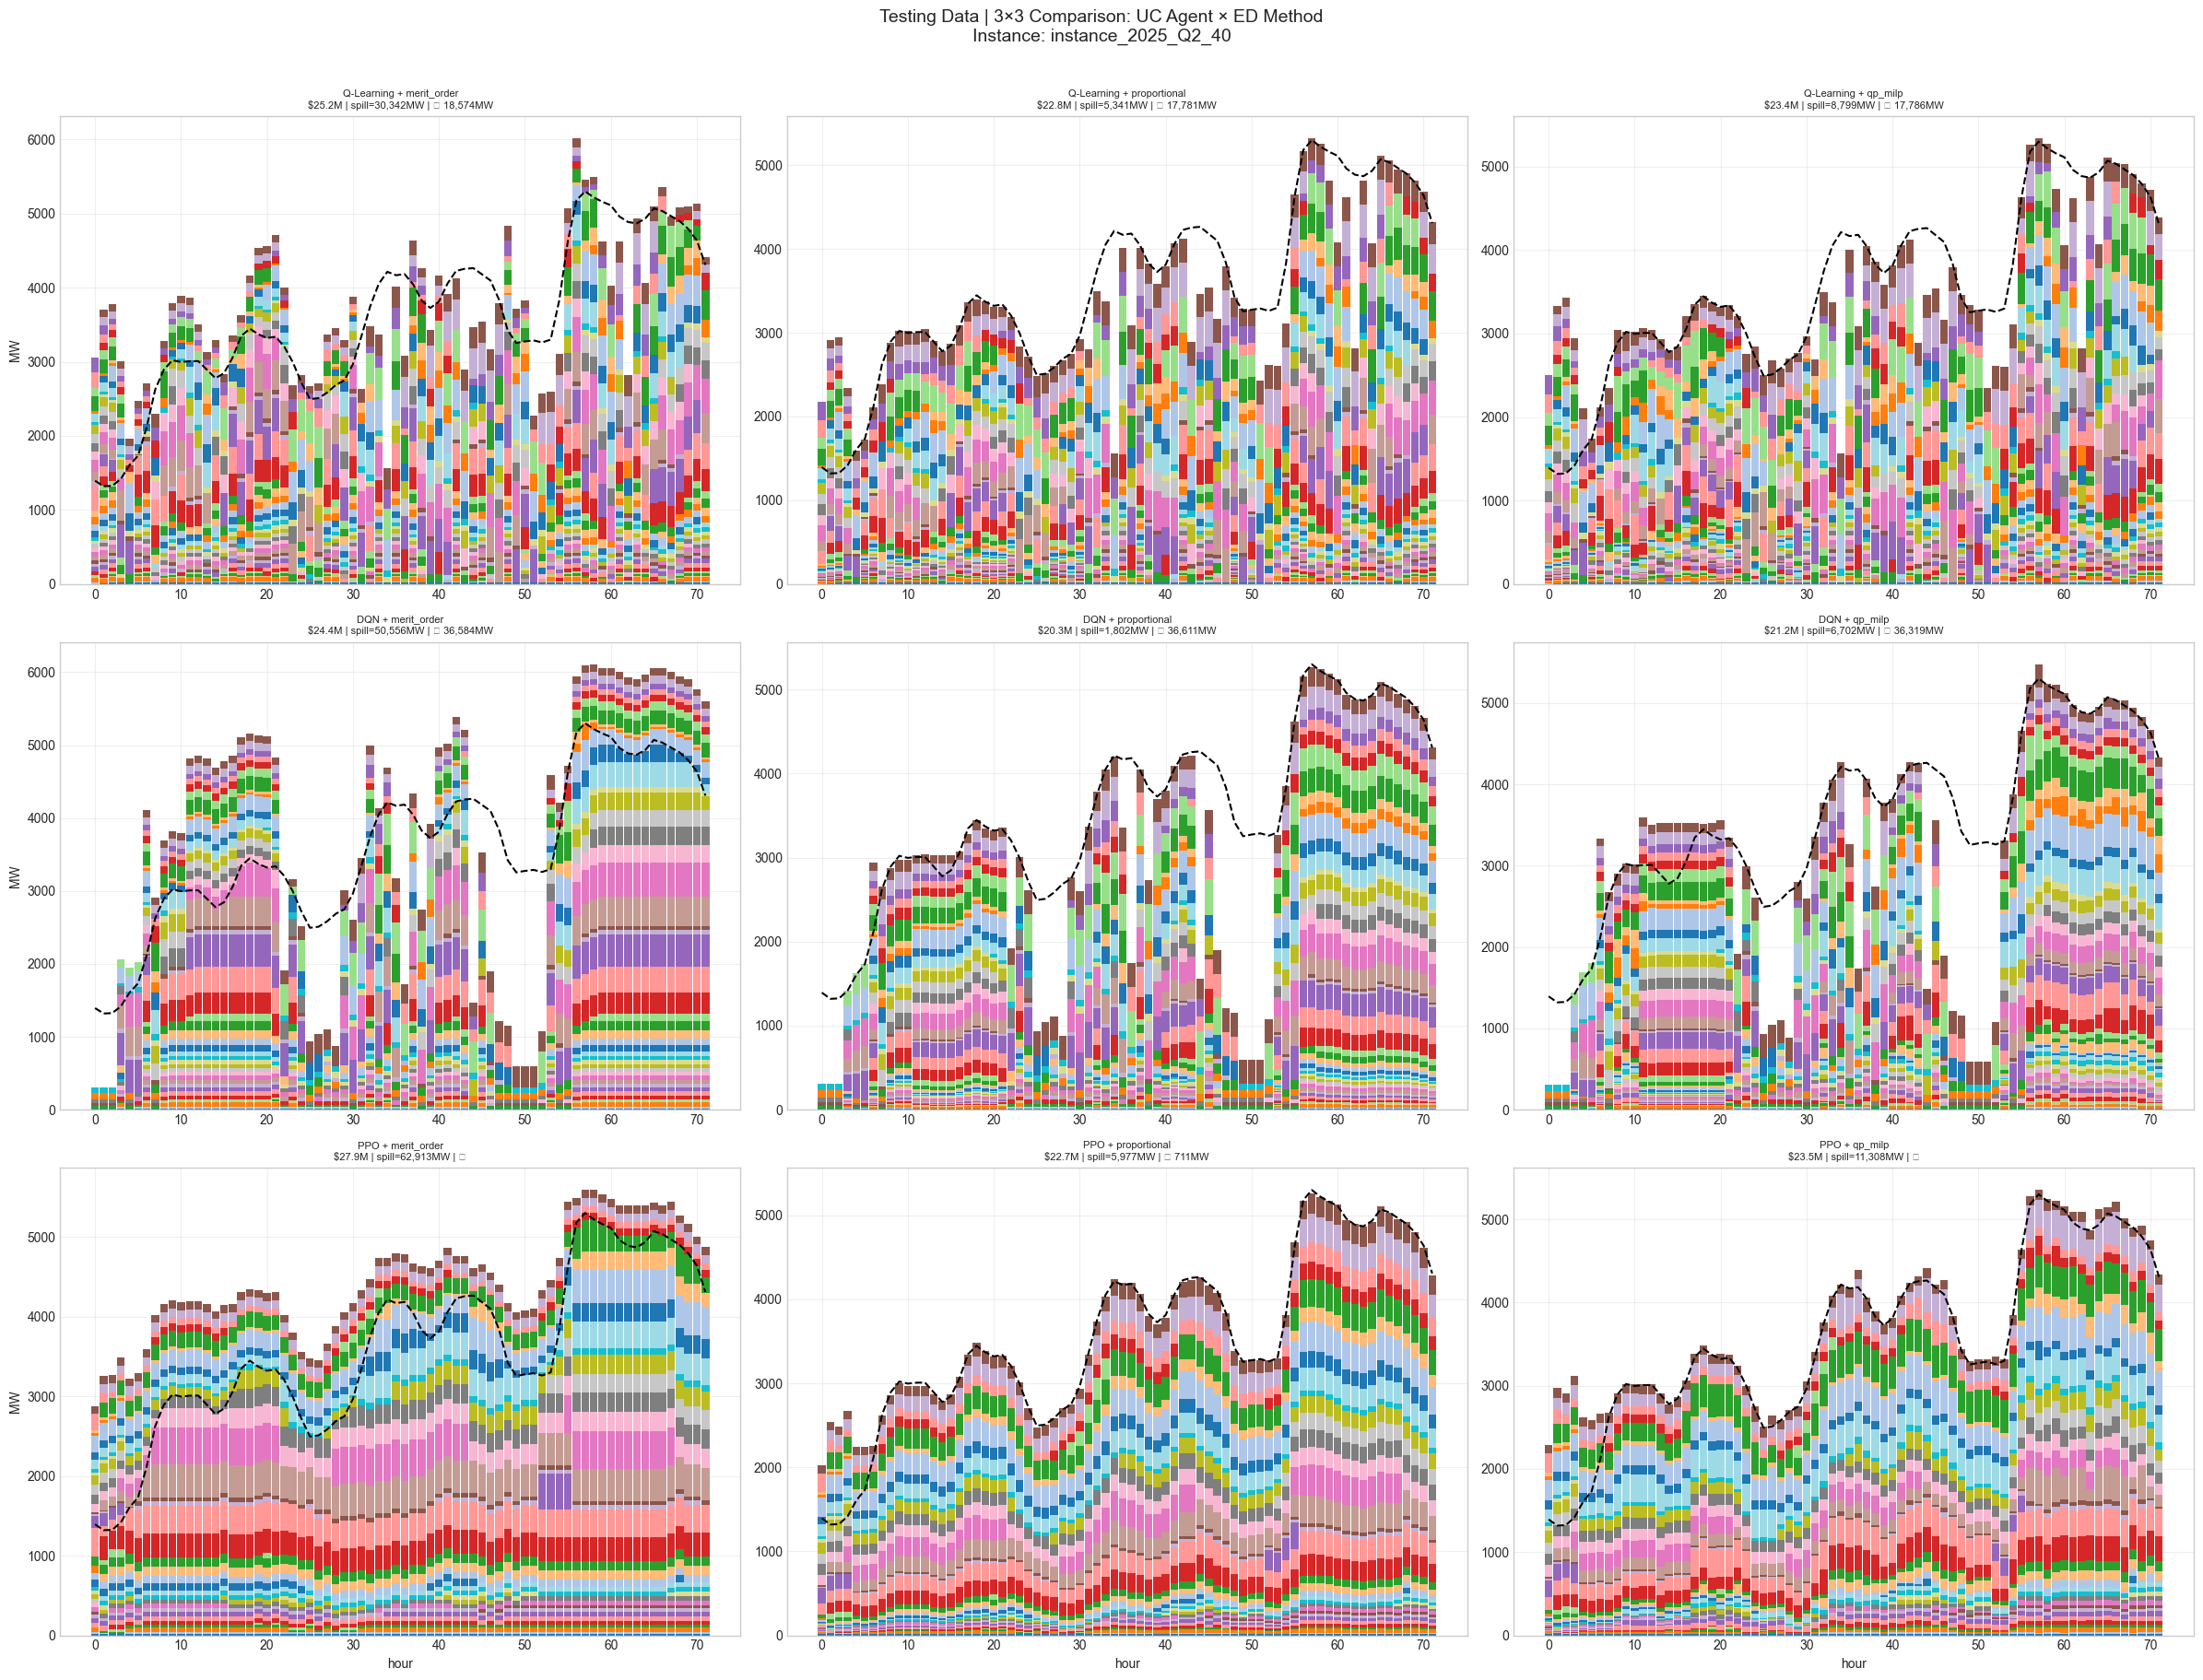

In [45]:
# ── Collect traces untuk instance yang mau dilihat ──
INSTANCE_IDX = 15

traces_3x3 = {}
for uc_name, uc_pol in UC_POLICIES.items():
    for ed_name, ed_fn in ED_METHODS.items():
        traces_3x3[(uc_name, ed_name)] = apply_ed_to_uc(
            env, uc_pol, ed_fn,
            test_episodes,          # ganti test_episodes kalau mau test set
            instance_index=INSTANCE_IDX,
            levels=ED_LEVELS,
        )

instance_id = test_episodes[INSTANCE_IDX]["instance_id"]

# ── Plot 3×3 ──
fig, axes = plt.subplots(3, 3, figsize=(24, 18))
fig.suptitle(f"Testing Data | 3×3 Comparison: UC Agent × ED Method\nInstance: {instance_id}",
             fontsize=14, y=1.01)

cmap   = plt.cm.tab20
colors = [cmap(i % 20 / 20) for i in range(env.n_gen)]

ed_names = list(ED_METHODS.keys())
uc_names = list(UC_POLICIES.keys())

for row, uc_name in enumerate(uc_names):
    for col, ed_name in enumerate(ed_names):
        ax  = axes[row, col]
        tr  = traces_3x3[(uc_name, ed_name)]
        hours = tr["hour"].values
        dm    = np.vstack(tr["dispatch"].values)
        n_h   = len(hours)

        # Net demand — ambil dari episodes langsung
        nd = test_episodes[INSTANCE_IDX]["net_demand"][:n_h]

        bottom_pos = np.zeros(n_h)
        bottom_neg = np.zeros(n_h)
        for i in range(env.n_gen):
            pos = np.clip(dm[:, i], 0, None)
            neg = np.clip(dm[:, i], None, 0)
            if pos.any():
                ax.bar(hours, pos, bottom=bottom_pos, width=0.9,
                    color=colors[i], edgecolor="none")
                bottom_pos += pos
            if neg.any():
                ax.bar(hours, neg, bottom=bottom_neg, width=0.9,
                    color=colors[i], edgecolor="none")
                bottom_neg += neg
        ax.plot(hours, nd, "k--", lw=1.5, label="net demand")

        cost = tr["fuel_cost"].sum() + tr["startup_cost"].sum()
        spill = tr["spill"].sum()
        uns   = tr["unserved"].sum()
        feas  = "✅" if uns < 1.0 else f"❌ {uns:,.0f}MW"

        ax.set_title(
            f"{uc_name} + {ed_name}\n"
            f"${cost/1e6:.1f}M | spill={spill:,.0f}MW | {feas}",
            fontsize=8)
        ax.set_ylabel("MW" if col == 0 else "")
        ax.set_xlabel("hour" if row == 2 else "")
        ax.grid(True, alpha=0.3)

        # Y-axis limit consistent per row
        axes[row, 0].set_ylim(bottom=0)

plt.tight_layout()
plt.show()

In [46]:
ED_LEVELS

[0.05,
 0.1,
 0.15,
 0.2,
 0.25,
 0.3,
 0.35,
 0.4,
 0.45,
 0.5,
 0.55,
 0.6,
 0.65,
 0.7,
 0.75,
 0.8,
 0.85,
 0.9,
 0.95,
 1.0]

In [ ]:
def trace_overcommit(uc_env, policy_fn, ed_fn, episodes, instance_index,
                     levels=ED_LEVELS):
    """
    Like apply_ed_to_uc, but also records WHY each generator is ON:
      - 'agent'   : agent wanted it ON, no constraint forced it
      - 'min_up'  : agent wanted OFF, but min_up constraint forced ON
      - 'ramp'    : agent wanted OFF, but ramp_down constraint forced ON
      - 'off'     : generator is OFF
    """
    obs = _reset(uc_env, instance_index)
    ep  = episodes[instance_index]

    n_gen = uc_env.n_gen
    current_dispatch = ep["thermal_df"]["init_power"].to_numpy(float).copy()
    status_duration  = ep["thermal_df"]["init_status"].to_numpy(float).copy()

    done, trace = False, []
    while not done:
        a = policy_fn(obs)
        raw_action = np.asarray(a, int).ravel()[:n_gen]

        # ── Reproduce _legalise logic to tag each generator ──
        on = raw_action.copy()
        cur_on = (current_dispatch > 1e-6) | (status_duration > 0)
        reason = np.array(["off"] * n_gen, dtype=object)

        for i in range(n_gen):
            if on[i] == 1:
                reason[i] = "agent"  # agent chose ON (may also be forced)

            # min_up: was ON, hasn't run long enough → forced ON
            if cur_on[i] and status_duration[i] > 0 and status_duration[i] < uc_env.min_up[i]:
                if raw_action[i] == 0:
                    reason[i] = "min_up"
                on[i] = 1

            # min_down: was OFF, hasn't been off long enough → forced OFF
            if (not cur_on[i]) and status_duration[i] < 0 and (-status_duration[i] < uc_env.min_down[i]):
                on[i] = 0
                reason[i] = "off"

            # ramp: was ON with high output, can't ramp down fast enough
            if cur_on[i] and on[i] == 0 and current_dispatch[i] > uc_env.ramp_down[i] + 1e-6:
                on[i] = 1
                if raw_action[i] == 0:
                    reason[i] = "ramp"

            # Final: if ON but we didn't set a reason yet
            if on[i] == 1 and reason[i] == "off":
                reason[i] = "agent"

        # ── ED dispatch ──
        obs, rew_uc, done, info_uc = _step(uc_env, raw_action)
        on_actual = info_uc["on"]

        # Re-tag based on actual on (in case _step._legalise differs)
        for i in range(n_gen):
            if on_actual[i] == 1 and raw_action[i] == 0:
                # Overridden to ON — figure out why
                if cur_on[i] and status_duration[i] > 0 and status_duration[i] < uc_env.min_up[i]:
                    reason[i] = "min_up"
                elif cur_on[i] and current_dispatch[i] > uc_env.ramp_down[i] + 1e-6:
                    reason[i] = "ramp"
                else:
                    reason[i] = "min_up"  # fallback
            elif on_actual[i] == 1 and raw_action[i] == 1:
                reason[i] = "agent"
            elif on_actual[i] == 0:
                reason[i] = "off"

        nd_t = float(ep["net_demand"][info_uc["hour"]])
        required = max(0.0, nd_t)

        dispatch = ed_fn(
            required_mw=required, on=on_actual,
            pmin=uc_env.pmin, pmax=uc_env.pmax,
            marginal_cost=uc_env.marginal_cost,
            current_dispatch=current_dispatch,
            ramp_up=uc_env.ramp_up, ramp_down=uc_env.ramp_down,
            status_duration=status_duration, levels=levels,
        )

        total_pmin_on = float(uc_env.pmin[on_actual == 1].sum())
        spill = max(0.0, total_pmin_on - required)

        # Update state
        prev_on_flag = cur_on.copy()
        current_dispatch = dispatch.copy()
        new_status = np.zeros(n_gen, float)
        for i in range(n_gen):
            cur = prev_on_flag[i]
            if on_actual[i] == 1:
                new_status[i] = max(1.0, status_duration[i] + 1.0) if cur else 1.0
            else:
                new_status[i] = min(-1.0, status_duration[i] - 1.0) if not cur else -1.0
        status_duration = new_status

        trace.append({
            "hour": info_uc["hour"],
            "net_demand": nd_t,
            "required": required,
            "on": on_actual.copy(),
            "raw_action": raw_action.copy(),
            "reason": reason.copy(),
            "dispatch": dispatch.copy(),
            "pmin_on": total_pmin_on,
            "spill": spill,
            "n_online": int(on_actual.sum()),
            "n_forced_min_up": int((reason == "min_up").sum()),
            "n_forced_ramp":   int((reason == "ramp").sum()),
            "n_agent_choice":  int((reason == "agent").sum()),
            "status_duration": status_duration.copy(),
        })

    return trace

In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  Over & Undercommit Envelope — Pmin / Pmax / Demand / Dispatch             ║
# ║  Replace Plot 1 in the overcommit diagnostic cell.                         ║
# ║  Shows the FULL dispatch envelope so you see both failure modes:            ║
# ║    • Overcommit  (Σ Pmin > demand) → forced spill                          ║
# ║    • Undercommit (Σ Pmax < demand) → unserved energy                       ║
# ║    • Feasible band in between                                              ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

# Uses diag_results from the overcommit diagnostic cell (run that first).
# Also needs traces_3x3 OR we re-collect dispatch traces here.

# ── Collect actual dispatch traces (proportional ED) for same instance ──
dispatch_traces = {}
for uc_name, uc_pol in UC_POLICIES.items():
    dispatch_traces[uc_name] = apply_ed_to_uc(
        env, uc_pol, dispatch_proportional, episodes_diag,
        instance_index=INSTANCE_IDX, levels=ED_LEVELS,
    )

# ═══════════════════════════════════════════════════════════════════════
# PLOT: Commitment Envelope — one panel per agent
# ═══════════════════════════════════════════════════════════════════════
n_agents = len(diag_results)
fig, axes = plt.subplots(n_agents, 1,
                          figsize=(22, 6 * n_agents), sharex=True)
if n_agents == 1:
    axes = [axes]

for ax, (uc_name, trace) in zip(axes, diag_results.items()):
    hours = np.array([t["hour"] for t in trace])
    nd    = np.array([t["required"] for t in trace])

    # Compute Pmin and Pmax of committed generators per hour
    pmin_on = np.zeros(len(trace))
    pmax_on = np.zeros(len(trace))
    for t_idx, t in enumerate(trace):
        on_mask = (t["on"] == 1)
        pmin_on[t_idx] = env.pmin[on_mask].sum()
        pmax_on[t_idx] = env.pmax[on_mask].sum()

    # Actual total dispatch from ED
    tr_disp = dispatch_traces[uc_name]
    total_dispatch = np.array([
        np.asarray(tr_disp["dispatch"].iloc[h]).sum() for h in range(len(hours))
    ])

    # ── Stacked dispatch bars (same as 3×3 plot) ──
    dm = np.vstack(tr_disp["dispatch"].values)
    cmap_gen = plt.cm.tab20
    colors_gen = [cmap_gen(i % 20 / 20) for i in range(env.n_gen)]

    bottom = np.zeros(len(hours))
    for g in range(env.n_gen):
        vals = dm[:, g]
        if vals.sum() > 0:
            ax.bar(hours, vals, bottom=bottom, width=0.85,
                   color=colors_gen[g], alpha=0.5, edgecolor="none")
            bottom += vals

    # ── Envelope lines ──
    ax.plot(hours, nd, "k--", lw=2.5, label="Net Demand", zorder=5)
    ax.plot(hours, pmin_on, color="tab:red", lw=2, ls="-",
            label="Σ Pmin (ON)", zorder=4)
    ax.plot(hours, pmax_on, color="tab:blue", lw=2, ls="-",
            label="Σ Pmax (ON)", zorder=4)

    # ── Shade zones ──
    # Overcommit: Pmin > demand → forced spill (red)
    oc_mask = pmin_on > nd
    ax.fill_between(hours, nd, pmin_on, where=oc_mask,
                     alpha=0.3, color="red", hatch="//",
                     label="Overcommit (Pmin > Demand)", zorder=3)

    # Undercommit: Pmax < demand → unserved (purple)
    uc_mask = pmax_on < nd
    ax.fill_between(hours, pmax_on, nd, where=uc_mask,
                     alpha=0.3, color="purple", hatch="\\\\",
                     label="Undercommit (Pmax < Demand)", zorder=3)

    # Feasible band: Pmin ≤ demand ≤ Pmax (light green, subtle)
    feas_mask = (~oc_mask) & (~uc_mask)
    ax.fill_between(hours, pmin_on, np.minimum(pmax_on, nd),
                     where=feas_mask, alpha=0.08, color="green", zorder=1)

    # ── Stats ──
    n_oc = int(oc_mask.sum())
    n_uc = int(uc_mask.sum())
    n_feas = int(feas_mask.sum())

    total_spill_mw = float(np.maximum(pmin_on - nd, 0).sum())
    total_unserved_mw = float(np.maximum(nd - pmax_on, 0).sum())

    avg_pmin_ratio = float((pmin_on / np.maximum(nd, 1)).mean())
    avg_pmax_ratio = float((pmax_on / np.maximum(nd, 1)).mean())

    # Reason breakdown during overcommit (from diag_results)
    forced_oc = sum(1 for t in trace if t["pmin_on"] > t["required"]
                    for g in range(env.n_gen)
                    if t["on"][g] == 1 and t["reason"][g] in ("min_up", "ramp"))
    agent_oc  = sum(1 for t in trace if t["pmin_on"] > t["required"]
                    for g in range(env.n_gen)
                    if t["on"][g] == 1 and t["reason"][g] == "agent")

    stats_text = (
        f"Overcommit:  {n_oc}/72h  ({total_spill_mw:,.0f} MW forced spill)\n"
        f"Undercommit: {n_uc}/72h  ({total_unserved_mw:,.0f} MW unserved)\n"
        f"Feasible:    {n_feas}/72h\n"
        f"─────────────────────────\n"
        f"Avg Pmin/Demand: {avg_pmin_ratio:.2f}\n"
        f"Avg Pmax/Demand: {avg_pmax_ratio:.2f}\n"
        f"─────────────────────────\n"
        f"Overcommit cause:\n"
        f"  Forced (min_up/ramp): {forced_oc} gen-hrs\n"
        f"  Agent choice:         {agent_oc} gen-hrs"
    )

    ax.text(0.01, 0.98, stats_text,
            transform=ax.transAxes, fontsize=9, va="top",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.9),
            family="monospace", zorder=6)

    ax.set_ylabel("MW", fontsize=11)
    ax.set_title(f"{uc_name}", fontsize=13, fontweight="bold")
    ax.legend(loc="upper right", fontsize=9, ncol=2)
    ax.grid(True, alpha=0.2)
    ax.set_xlim(-0.5, 71.5)

axes[-1].set_xlabel("Hour", fontsize=11)
fig.suptitle(
    f"Commitment Envelope: Overcommit vs Undercommit Analysis\n"
    f"Instance: {ep['instance_id']}  |  "
    f"Stacked bars = actual dispatch  |  "
    f"Red line = Σ Pmin  |  Blue line = Σ Pmax",
    fontsize=14, y=1.01,
)
plt.tight_layout()
plt.show()

# ═══════════════════════════════════════════════════════════════════════
# SUMMARY TABLE: Over vs Undercommit balance per agent
# ═══════════════════════════════════════════════════════════════════════
print(f"\n{'='*95}")
print(f"  COMMITMENT BALANCE SCORECARD — Instance: {ep['instance_id']}")
print(f"{'='*95}")
print(f"  {'Agent':12s} | {'Overcommit':>10s} {'Undercommit':>12s} {'Feasible':>8s} | "
      f"{'Spill(MW)':>10s} {'Unserved(MW)':>12s} | "
      f"{'Pmin/D':>7s} {'Pmax/D':>7s} | {'Verdict':20s}")
print(f"  {'─'*93}")

for uc_name, trace in diag_results.items():
    hours_arr = np.array([t["hour"] for t in trace])
    nd_arr    = np.array([t["required"] for t in trace])

    pmin_arr = np.zeros(len(trace))
    pmax_arr = np.zeros(len(trace))
    for t_idx, t in enumerate(trace):
        on_mask = (t["on"] == 1)
        pmin_arr[t_idx] = env.pmin[on_mask].sum()
        pmax_arr[t_idx] = env.pmax[on_mask].sum()

    n_oc   = int((pmin_arr > nd_arr).sum())
    n_uc   = int((pmax_arr < nd_arr).sum())
    n_feas = 72 - n_oc - n_uc

    spill_mw    = float(np.maximum(pmin_arr - nd_arr, 0).sum())
    unserved_mw = float(np.maximum(nd_arr - pmax_arr, 0).sum())

    avg_pmin_r = float((pmin_arr / np.maximum(nd_arr, 1)).mean())
    avg_pmax_r = float((pmax_arr / np.maximum(nd_arr, 1)).mean())

    # Verdict
    if n_uc > 10:
        verdict = "⚠️ Heavy undercommit"
    elif n_oc > 40:
        verdict = "⚠️ Heavy overcommit"
    elif n_oc > n_uc and n_oc > 15:
        verdict = "↑ Conservative (spill)"
    elif n_uc > n_oc and n_uc > 5:
        verdict = "↓ Aggressive (unserved)"
    elif n_feas > 50:
        verdict = "✅ Well-balanced"
    else:
        verdict = "⚖️ Mixed"

    print(f"  {uc_name:12s} | {n_oc:>7d}/72 {n_uc:>9d}/72 {n_feas:>5d}/72 | "
          f"{spill_mw:>10,.0f} {unserved_mw:>12,.0f} | "
          f"{avg_pmin_r:>7.2f} {avg_pmax_r:>7.2f} | {verdict}")

print(f"\n  Interpretation:")
print(f"    Pmin/D > 1.0 means agent commits more Pmin than needed on average (over-conservative)")
print(f"    Pmax/D < 1.0 means agent can't cover demand even at full output (under-committed)")
print(f"    Ideal: Pmin/D ≈ 0.4–0.7, Pmax/D ≈ 1.2–1.5 (enough headroom, minimal spill)")

In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  Over & Undercommit Envelope — Pmin / Pmax / Demand / Dispatch             ║
# ║  Replace Plot 1 in the overcommit diagnostic cell.                         ║
# ║  Shows the FULL dispatch envelope so you see both failure modes:            ║
# ║    • Overcommit  (Σ Pmin > demand) → forced spill                          ║
# ║    • Undercommit (Σ Pmax < demand) → unserved energy                       ║
# ║    • Feasible band in between                                              ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

# Uses diag_results from the overcommit diagnostic cell (run that first).
# Also needs traces_3x3 OR we re-collect dispatch traces here.

# ── Collect actual dispatch traces (proportional ED) for same instance ──
INSTANCE_IDX = 20
USE_TEST = True
episodes_diag = test_episodes if USE_TEST else train_episodes
ep = episodes_diag[INSTANCE_IDX]

print(f"Diagnosing overcommit on instance: {ep['instance_id']}\n")

diag_results = {}
for uc_name, uc_pol in UC_POLICIES.items():
    diag_results[uc_name] = trace_overcommit(
        env, uc_pol, dispatch_proportional, episodes_diag,
        INSTANCE_IDX, levels=ED_LEVELS,
    )

dispatch_traces = {}
for uc_name, uc_pol in UC_POLICIES.items():
    dispatch_traces[uc_name] = apply_ed_to_uc(
        env, uc_pol, dispatch_proportional, episodes_diag,
        instance_index=INSTANCE_IDX, levels=ED_LEVELS,
    )



# ═══════════════════════════════════════════════════════════════════════
# PLOT: Commitment Envelope — one panel per agent
# ═══════════════════════════════════════════════════════════════════════
n_agents = len(diag_results)
fig, axes = plt.subplots(n_agents, 1,
                          figsize=(22, 6 * n_agents), sharex=True)
if n_agents == 1:
    axes = [axes]

for ax, (uc_name, trace) in zip(axes, diag_results.items()):
    hours = np.array([t["hour"] for t in trace])
    nd    = np.array([t["required"] for t in trace])

    # Compute Pmin and Pmax of committed generators per hour
    pmin_on = np.zeros(len(trace))
    pmax_on = np.zeros(len(trace))
    for t_idx, t in enumerate(trace):
        on_mask = (t["on"] == 1)
        pmin_on[t_idx] = env.pmin[on_mask].sum()
        pmax_on[t_idx] = env.pmax[on_mask].sum()

    # Actual total dispatch from ED
    tr_disp = dispatch_traces[uc_name]
    total_dispatch = np.array([
        np.asarray(tr_disp["dispatch"].iloc[h]).sum() for h in range(len(hours))
    ])

    # ── Stacked dispatch bars (same as 3×3 plot) ──
    dm = np.vstack(tr_disp["dispatch"].values)
    cmap_gen = plt.cm.tab20
    colors_gen = [cmap_gen(i % 20 / 20) for i in range(env.n_gen)]

    bottom = np.zeros(len(hours))
    for g in range(env.n_gen):
        vals = dm[:, g]
        if vals.sum() > 0:
            ax.bar(hours, vals, bottom=bottom, width=0.85,
                   color=colors_gen[g], alpha=0.5, edgecolor="none")
            bottom += vals

    # ── Envelope lines ──
    ax.plot(hours, nd, "k--", lw=2.5, label="Net Demand", zorder=5)
    ax.plot(hours, pmin_on, color="tab:red", lw=2, ls="-",
            label="Σ Pmin (ON)", zorder=4)
    ax.plot(hours, pmax_on, color="tab:blue", lw=2, ls="-",
            label="Σ Pmax (ON)", zorder=4)

    # ── Shade zones ──
    # Overcommit: Pmin > demand → forced spill (red)
    oc_mask = pmin_on > nd
    ax.fill_between(hours, nd, pmin_on, where=oc_mask,
                     alpha=0.3, color="red", hatch="//",
                     label="Overcommit (Pmin > Demand)", zorder=3)

    # Undercommit: Pmax < demand → unserved (purple)
    uc_mask = pmax_on < nd
    ax.fill_between(hours, pmax_on, nd, where=uc_mask,
                     alpha=0.3, color="purple", hatch="\\\\",
                     label="Undercommit (Pmax < Demand)", zorder=3)

    # Feasible band: Pmin ≤ demand ≤ Pmax (light green, subtle)
    feas_mask = (~oc_mask) & (~uc_mask)
    ax.fill_between(hours, pmin_on, np.minimum(pmax_on, nd),
                     where=feas_mask, alpha=0.08, color="green", zorder=1)

    # ── Stats ──
    n_oc = int(oc_mask.sum())
    n_uc = int(uc_mask.sum())
    n_feas = int(feas_mask.sum())

    total_spill_mw = float(np.maximum(pmin_on - nd, 0).sum())
    total_unserved_mw = float(np.maximum(nd - pmax_on, 0).sum())

    avg_pmin_ratio = float((pmin_on / np.maximum(nd, 1)).mean())
    avg_pmax_ratio = float((pmax_on / np.maximum(nd, 1)).mean())

    # Reason breakdown during overcommit (from diag_results)
    forced_oc = sum(1 for t in trace if t["pmin_on"] > t["required"]
                    for g in range(env.n_gen)
                    if t["on"][g] == 1 and t["reason"][g] in ("min_up", "ramp"))
    agent_oc  = sum(1 for t in trace if t["pmin_on"] > t["required"]
                    for g in range(env.n_gen)
                    if t["on"][g] == 1 and t["reason"][g] == "agent")

    stats_text = (
        f"Overcommit:  {n_oc}/72h  ({total_spill_mw:,.0f} MW forced spill)\n"
        f"Undercommit: {n_uc}/72h  ({total_unserved_mw:,.0f} MW unserved)\n"
        f"Feasible:    {n_feas}/72h\n"
        f"─────────────────────────\n"
        f"Avg Pmin/Demand: {avg_pmin_ratio:.2f}\n"
        f"Avg Pmax/Demand: {avg_pmax_ratio:.2f}\n"
        f"─────────────────────────\n"
        f"Overcommit cause:\n"
        f"  Forced (min_up/ramp): {forced_oc} gen-hrs\n"
        f"  Agent choice:         {agent_oc} gen-hrs"
    )

    ax.text(0.01, 0.98, stats_text,
            transform=ax.transAxes, fontsize=9, va="top",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.9),
            family="monospace", zorder=6)

    ax.set_ylabel("MW", fontsize=11)
    ax.set_title(f"{uc_name}", fontsize=13, fontweight="bold")
    ax.legend(loc="upper right", fontsize=9, ncol=2)
    ax.grid(True, alpha=0.2)
    ax.set_xlim(-0.5, 71.5)

axes[-1].set_xlabel("Hour", fontsize=11)
fig.suptitle(
    f"Commitment Envelope: Overcommit vs Undercommit Analysis\n"
    f"Instance: {ep['instance_id']}  |  "
    f"Stacked bars = actual dispatch  |  "
    f"Red line = Σ Pmin  |  Blue line = Σ Pmax",
    fontsize=14, y=1.01,
)
plt.tight_layout()
plt.show()

# ═══════════════════════════════════════════════════════════════════════
# SUMMARY TABLE: Over vs Undercommit balance per agent
# ═══════════════════════════════════════════════════════════════════════
print(f"\n{'='*95}")
print(f"  COMMITMENT BALANCE SCORECARD — Instance: {ep['instance_id']}")
print(f"{'='*95}")
print(f"  {'Agent':12s} | {'Overcommit':>10s} {'Undercommit':>12s} {'Feasible':>8s} | "
      f"{'Spill(MW)':>10s} {'Unserved(MW)':>12s} | "
      f"{'Pmin/D':>7s} {'Pmax/D':>7s} | {'Verdict':20s}")
print(f"  {'─'*93}")

for uc_name, trace in diag_results.items():
    hours_arr = np.array([t["hour"] for t in trace])
    nd_arr    = np.array([t["required"] for t in trace])

    pmin_arr = np.zeros(len(trace))
    pmax_arr = np.zeros(len(trace))
    for t_idx, t in enumerate(trace):
        on_mask = (t["on"] == 1)
        pmin_arr[t_idx] = env.pmin[on_mask].sum()
        pmax_arr[t_idx] = env.pmax[on_mask].sum()

    n_oc   = int((pmin_arr > nd_arr).sum())
    n_uc   = int((pmax_arr < nd_arr).sum())
    n_feas = 72 - n_oc - n_uc

    spill_mw    = float(np.maximum(pmin_arr - nd_arr, 0).sum())
    unserved_mw = float(np.maximum(nd_arr - pmax_arr, 0).sum())

    avg_pmin_r = float((pmin_arr / np.maximum(nd_arr, 1)).mean())
    avg_pmax_r = float((pmax_arr / np.maximum(nd_arr, 1)).mean())

    # Verdict
    if n_uc > 10:
        verdict = "⚠️ Heavy undercommit"
    elif n_oc > 40:
        verdict = "⚠️ Heavy overcommit"
    elif n_oc > n_uc and n_oc > 15:
        verdict = "↑ Conservative (spill)"
    elif n_uc > n_oc and n_uc > 5:
        verdict = "↓ Aggressive (unserved)"
    elif n_feas > 50:
        verdict = "✅ Well-balanced"
    else:
        verdict = "⚖️ Mixed"

    print(f"  {uc_name:12s} | {n_oc:>7d}/72 {n_uc:>9d}/72 {n_feas:>5d}/72 | "
          f"{spill_mw:>10,.0f} {unserved_mw:>12,.0f} | "
          f"{avg_pmin_r:>7.2f} {avg_pmax_r:>7.2f} | {verdict}")

print(f"\n  Interpretation:")
print(f"    Pmin/D > 1.0 means agent commits more Pmin than needed on average (over-conservative)")
print(f"    Pmax/D < 1.0 means agent can't cover demand even at full output (under-committed)")
print(f"    Ideal: Pmin/D ≈ 0.4–0.7, Pmax/D ≈ 1.2–1.5 (enough headroom, minimal spill)")

In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  Over & Undercommit Envelope — Pmin / Pmax / Demand / Dispatch             ║
# ║  Replace Plot 1 in the overcommit diagnostic cell.                         ║
# ║  Shows the FULL dispatch envelope so you see both failure modes:            ║
# ║    • Overcommit  (Σ Pmin > demand) → forced spill                          ║
# ║    • Undercommit (Σ Pmax < demand) → unserved energy                       ║
# ║    • Feasible band in between                                              ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

# Uses diag_results from the overcommit diagnostic cell (run that first).
# Also needs traces_3x3 OR we re-collect dispatch traces here.

# ── Collect actual dispatch traces (proportional ED) for same instance ──
INSTANCE_IDX = 35
USE_TEST = True
episodes_diag = test_episodes if USE_TEST else train_episodes
ep = episodes_diag[INSTANCE_IDX]

print(f"Diagnosing overcommit on instance: {ep['instance_id']}\n")

diag_results = {}
for uc_name, uc_pol in UC_POLICIES.items():
    diag_results[uc_name] = trace_overcommit(
        env, uc_pol, dispatch_proportional, episodes_diag,
        INSTANCE_IDX, levels=ED_LEVELS,
    )

dispatch_traces = {}
for uc_name, uc_pol in UC_POLICIES.items():
    dispatch_traces[uc_name] = apply_ed_to_uc(
        env, uc_pol, dispatch_proportional, episodes_diag,
        instance_index=INSTANCE_IDX, levels=ED_LEVELS,
    )



# ═══════════════════════════════════════════════════════════════════════
# PLOT: Commitment Envelope — one panel per agent
# ═══════════════════════════════════════════════════════════════════════
n_agents = len(diag_results)
fig, axes = plt.subplots(n_agents, 1,
                          figsize=(22, 6 * n_agents), sharex=True)
if n_agents == 1:
    axes = [axes]

for ax, (uc_name, trace) in zip(axes, diag_results.items()):
    hours = np.array([t["hour"] for t in trace])
    nd    = np.array([t["required"] for t in trace])

    # Compute Pmin and Pmax of committed generators per hour
    pmin_on = np.zeros(len(trace))
    pmax_on = np.zeros(len(trace))
    for t_idx, t in enumerate(trace):
        on_mask = (t["on"] == 1)
        pmin_on[t_idx] = env.pmin[on_mask].sum()
        pmax_on[t_idx] = env.pmax[on_mask].sum()

    # Actual total dispatch from ED
    tr_disp = dispatch_traces[uc_name]
    total_dispatch = np.array([
        np.asarray(tr_disp["dispatch"].iloc[h]).sum() for h in range(len(hours))
    ])

    # ── Stacked dispatch bars (same as 3×3 plot) ──
    dm = np.vstack(tr_disp["dispatch"].values)
    cmap_gen = plt.cm.tab20
    colors_gen = [cmap_gen(i % 20 / 20) for i in range(env.n_gen)]

    bottom = np.zeros(len(hours))
    for g in range(env.n_gen):
        vals = dm[:, g]
        if vals.sum() > 0:
            ax.bar(hours, vals, bottom=bottom, width=0.85,
                   color=colors_gen[g], alpha=0.5, edgecolor="none")
            bottom += vals

    # ── Envelope lines ──
    ax.plot(hours, nd, "k--", lw=2.5, label="Net Demand", zorder=5)
    ax.plot(hours, pmin_on, color="tab:red", lw=2, ls="-",
            label="Σ Pmin (ON)", zorder=4)
    ax.plot(hours, pmax_on, color="tab:blue", lw=2, ls="-",
            label="Σ Pmax (ON)", zorder=4)

    # ── Shade zones ──
    # Overcommit: Pmin > demand → forced spill (red)
    oc_mask = pmin_on > nd
    ax.fill_between(hours, nd, pmin_on, where=oc_mask,
                     alpha=0.3, color="red", hatch="//",
                     label="Overcommit (Pmin > Demand)", zorder=3)

    # Undercommit: Pmax < demand → unserved (purple)
    uc_mask = pmax_on < nd
    ax.fill_between(hours, pmax_on, nd, where=uc_mask,
                     alpha=0.3, color="purple", hatch="\\\\",
                     label="Undercommit (Pmax < Demand)", zorder=3)

    # Feasible band: Pmin ≤ demand ≤ Pmax (light green, subtle)
    feas_mask = (~oc_mask) & (~uc_mask)
    ax.fill_between(hours, pmin_on, np.minimum(pmax_on, nd),
                     where=feas_mask, alpha=0.08, color="green", zorder=1)

    # ── Stats ──
    n_oc = int(oc_mask.sum())
    n_uc = int(uc_mask.sum())
    n_feas = int(feas_mask.sum())

    total_spill_mw = float(np.maximum(pmin_on - nd, 0).sum())
    total_unserved_mw = float(np.maximum(nd - pmax_on, 0).sum())

    avg_pmin_ratio = float((pmin_on / np.maximum(nd, 1)).mean())
    avg_pmax_ratio = float((pmax_on / np.maximum(nd, 1)).mean())

    # Reason breakdown during overcommit (from diag_results)
    forced_oc = sum(1 for t in trace if t["pmin_on"] > t["required"]
                    for g in range(env.n_gen)
                    if t["on"][g] == 1 and t["reason"][g] in ("min_up", "ramp"))
    agent_oc  = sum(1 for t in trace if t["pmin_on"] > t["required"]
                    for g in range(env.n_gen)
                    if t["on"][g] == 1 and t["reason"][g] == "agent")

    stats_text = (
        f"Overcommit:  {n_oc}/72h  ({total_spill_mw:,.0f} MW forced spill)\n"
        f"Undercommit: {n_uc}/72h  ({total_unserved_mw:,.0f} MW unserved)\n"
        f"Feasible:    {n_feas}/72h\n"
        f"─────────────────────────\n"
        f"Avg Pmin/Demand: {avg_pmin_ratio:.2f}\n"
        f"Avg Pmax/Demand: {avg_pmax_ratio:.2f}\n"
        f"─────────────────────────\n"
        f"Overcommit cause:\n"
        f"  Forced (min_up/ramp): {forced_oc} gen-hrs\n"
        f"  Agent choice:         {agent_oc} gen-hrs"
    )

    ax.text(0.01, 0.98, stats_text,
            transform=ax.transAxes, fontsize=9, va="top",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.9),
            family="monospace", zorder=6)

    ax.set_ylabel("MW", fontsize=11)
    ax.set_title(f"{uc_name}", fontsize=13, fontweight="bold")
    ax.legend(loc="upper right", fontsize=9, ncol=2)
    ax.grid(True, alpha=0.2)
    ax.set_xlim(-0.5, 71.5)

axes[-1].set_xlabel("Hour", fontsize=11)
fig.suptitle(
    f"Commitment Envelope: Overcommit vs Undercommit Analysis\n"
    f"Instance: {ep['instance_id']}  |  "
    f"Stacked bars = actual dispatch  |  "
    f"Red line = Σ Pmin  |  Blue line = Σ Pmax",
    fontsize=14, y=1.01,
)
plt.tight_layout()
plt.show()

# ═══════════════════════════════════════════════════════════════════════
# SUMMARY TABLE: Over vs Undercommit balance per agent
# ═══════════════════════════════════════════════════════════════════════
print(f"\n{'='*95}")
print(f"  COMMITMENT BALANCE SCORECARD — Instance: {ep['instance_id']}")
print(f"{'='*95}")
print(f"  {'Agent':12s} | {'Overcommit':>10s} {'Undercommit':>12s} {'Feasible':>8s} | "
      f"{'Spill(MW)':>10s} {'Unserved(MW)':>12s} | "
      f"{'Pmin/D':>7s} {'Pmax/D':>7s} | {'Verdict':20s}")
print(f"  {'─'*93}")

for uc_name, trace in diag_results.items():
    hours_arr = np.array([t["hour"] for t in trace])
    nd_arr    = np.array([t["required"] for t in trace])

    pmin_arr = np.zeros(len(trace))
    pmax_arr = np.zeros(len(trace))
    for t_idx, t in enumerate(trace):
        on_mask = (t["on"] == 1)
        pmin_arr[t_idx] = env.pmin[on_mask].sum()
        pmax_arr[t_idx] = env.pmax[on_mask].sum()

    n_oc   = int((pmin_arr > nd_arr).sum())
    n_uc   = int((pmax_arr < nd_arr).sum())
    n_feas = 72 - n_oc - n_uc

    spill_mw    = float(np.maximum(pmin_arr - nd_arr, 0).sum())
    unserved_mw = float(np.maximum(nd_arr - pmax_arr, 0).sum())

    avg_pmin_r = float((pmin_arr / np.maximum(nd_arr, 1)).mean())
    avg_pmax_r = float((pmax_arr / np.maximum(nd_arr, 1)).mean())

    # Verdict
    if n_uc > 10:
        verdict = "⚠️ Heavy undercommit"
    elif n_oc > 40:
        verdict = "⚠️ Heavy overcommit"
    elif n_oc > n_uc and n_oc > 15:
        verdict = "↑ Conservative (spill)"
    elif n_uc > n_oc and n_uc > 5:
        verdict = "↓ Aggressive (unserved)"
    elif n_feas > 50:
        verdict = "✅ Well-balanced"
    else:
        verdict = "⚖️ Mixed"

    print(f"  {uc_name:12s} | {n_oc:>7d}/72 {n_uc:>9d}/72 {n_feas:>5d}/72 | "
          f"{spill_mw:>10,.0f} {unserved_mw:>12,.0f} | "
          f"{avg_pmin_r:>7.2f} {avg_pmax_r:>7.2f} | {verdict}")

print(f"\n  Interpretation:")
print(f"    Pmin/D > 1.0 means agent commits more Pmin than needed on average (over-conservative)")
print(f"    Pmax/D < 1.0 means agent can't cover demand even at full output (under-committed)")
print(f"    Ideal: Pmin/D ≈ 0.4–0.7, Pmax/D ≈ 1.2–1.5 (enough headroom, minimal spill)")

In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  Over & Undercommit Envelope — Pmin / Pmax / Demand / Dispatch             ║
# ║  Replace Plot 1 in the overcommit diagnostic cell.                         ║
# ║  Shows the FULL dispatch envelope so you see both failure modes:            ║
# ║    • Overcommit  (Σ Pmin > demand) → forced spill                          ║
# ║    • Undercommit (Σ Pmax < demand) → unserved energy                       ║
# ║    • Feasible band in between                                              ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

# Uses diag_results from the overcommit diagnostic cell (run that first).
# Also needs traces_3x3 OR we re-collect dispatch traces here.

# ── Collect actual dispatch traces (proportional ED) for same instance ──
INSTANCE_IDX = 15
USE_TEST = True
episodes_diag = test_episodes if USE_TEST else train_episodes
ep = episodes_diag[INSTANCE_IDX]

print(f"Diagnosing overcommit on instance: {ep['instance_id']}\n")

diag_results = {}
for uc_name, uc_pol in UC_POLICIES.items():
    diag_results[uc_name] = trace_overcommit(
        env, uc_pol, dispatch_proportional, episodes_diag,
        INSTANCE_IDX, levels=ED_LEVELS,
    )

dispatch_traces = {}
for uc_name, uc_pol in UC_POLICIES.items():
    dispatch_traces[uc_name] = apply_ed_to_uc(
        env, uc_pol, dispatch_proportional, episodes_diag,
        instance_index=INSTANCE_IDX, levels=ED_LEVELS,
    )



# ═══════════════════════════════════════════════════════════════════════
# PLOT: Commitment Envelope — one panel per agent
# ═══════════════════════════════════════════════════════════════════════
n_agents = len(diag_results)
fig, axes = plt.subplots(n_agents, 1,
                          figsize=(22, 6 * n_agents), sharex=True)
if n_agents == 1:
    axes = [axes]

for ax, (uc_name, trace) in zip(axes, diag_results.items()):
    hours = np.array([t["hour"] for t in trace])
    nd    = np.array([t["required"] for t in trace])

    # Compute Pmin and Pmax of committed generators per hour
    pmin_on = np.zeros(len(trace))
    pmax_on = np.zeros(len(trace))
    for t_idx, t in enumerate(trace):
        on_mask = (t["on"] == 1)
        pmin_on[t_idx] = env.pmin[on_mask].sum()
        pmax_on[t_idx] = env.pmax[on_mask].sum()

    # Actual total dispatch from ED
    tr_disp = dispatch_traces[uc_name]
    total_dispatch = np.array([
        np.asarray(tr_disp["dispatch"].iloc[h]).sum() for h in range(len(hours))
    ])

    # ── Stacked dispatch bars (same as 3×3 plot) ──
    dm = np.vstack(tr_disp["dispatch"].values)
    cmap_gen = plt.cm.tab20
    colors_gen = [cmap_gen(i % 20 / 20) for i in range(env.n_gen)]

    bottom = np.zeros(len(hours))
    for g in range(env.n_gen):
        vals = dm[:, g]
        if vals.sum() > 0:
            ax.bar(hours, vals, bottom=bottom, width=0.85,
                   color=colors_gen[g], alpha=0.5, edgecolor="none")
            bottom += vals

    # ── Envelope lines ──
    ax.plot(hours, nd, "k--", lw=2.5, label="Net Demand", zorder=5)
    ax.plot(hours, pmin_on, color="tab:red", lw=2, ls="-",
            label="Σ Pmin (ON)", zorder=4)
    ax.plot(hours, pmax_on, color="tab:blue", lw=2, ls="-",
            label="Σ Pmax (ON)", zorder=4)

    # ── Shade zones ──
    # Overcommit: Pmin > demand → forced spill (red)
    oc_mask = pmin_on > nd
    ax.fill_between(hours, nd, pmin_on, where=oc_mask,
                     alpha=0.3, color="red", hatch="//",
                     label="Overcommit (Pmin > Demand)", zorder=3)

    # Undercommit: Pmax < demand → unserved (purple)
    uc_mask = pmax_on < nd
    ax.fill_between(hours, pmax_on, nd, where=uc_mask,
                     alpha=0.3, color="purple", hatch="\\\\",
                     label="Undercommit (Pmax < Demand)", zorder=3)

    # Feasible band: Pmin ≤ demand ≤ Pmax (light green, subtle)
    feas_mask = (~oc_mask) & (~uc_mask)
    ax.fill_between(hours, pmin_on, np.minimum(pmax_on, nd),
                     where=feas_mask, alpha=0.08, color="green", zorder=1)

    # ── Stats ──
    n_oc = int(oc_mask.sum())
    n_uc = int(uc_mask.sum())
    n_feas = int(feas_mask.sum())

    total_spill_mw = float(np.maximum(pmin_on - nd, 0).sum())
    total_unserved_mw = float(np.maximum(nd - pmax_on, 0).sum())

    avg_pmin_ratio = float((pmin_on / np.maximum(nd, 1)).mean())
    avg_pmax_ratio = float((pmax_on / np.maximum(nd, 1)).mean())

    # Reason breakdown during overcommit (from diag_results)
    forced_oc = sum(1 for t in trace if t["pmin_on"] > t["required"]
                    for g in range(env.n_gen)
                    if t["on"][g] == 1 and t["reason"][g] in ("min_up", "ramp"))
    agent_oc  = sum(1 for t in trace if t["pmin_on"] > t["required"]
                    for g in range(env.n_gen)
                    if t["on"][g] == 1 and t["reason"][g] == "agent")

    stats_text = (
        f"Overcommit:  {n_oc}/72h  ({total_spill_mw:,.0f} MW forced spill)\n"
        f"Undercommit: {n_uc}/72h  ({total_unserved_mw:,.0f} MW unserved)\n"
        f"Feasible:    {n_feas}/72h\n"
        f"─────────────────────────\n"
        f"Avg Pmin/Demand: {avg_pmin_ratio:.2f}\n"
        f"Avg Pmax/Demand: {avg_pmax_ratio:.2f}\n"
        f"─────────────────────────\n"
        f"Overcommit cause:\n"
        f"  Forced (min_up/ramp): {forced_oc} gen-hrs\n"
        f"  Agent choice:         {agent_oc} gen-hrs"
    )

    ax.text(0.01, 0.98, stats_text,
            transform=ax.transAxes, fontsize=9, va="top",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.9),
            family="monospace", zorder=6)

    ax.set_ylabel("MW", fontsize=11)
    ax.set_title(f"{uc_name}", fontsize=13, fontweight="bold")
    ax.legend(loc="upper right", fontsize=9, ncol=2)
    ax.grid(True, alpha=0.2)
    ax.set_xlim(-0.5, 71.5)

axes[-1].set_xlabel("Hour", fontsize=11)
fig.suptitle(
    f"Commitment Envelope: Overcommit vs Undercommit Analysis\n"
    f"Instance: {ep['instance_id']}  |  "
    f"Stacked bars = actual dispatch  |  "
    f"Red line = Σ Pmin  |  Blue line = Σ Pmax",
    fontsize=14, y=1.01,
)
plt.tight_layout()
plt.show()

# ═══════════════════════════════════════════════════════════════════════
# SUMMARY TABLE: Over vs Undercommit balance per agent
# ═══════════════════════════════════════════════════════════════════════
print(f"\n{'='*95}")
print(f"  COMMITMENT BALANCE SCORECARD — Instance: {ep['instance_id']}")
print(f"{'='*95}")
print(f"  {'Agent':12s} | {'Overcommit':>10s} {'Undercommit':>12s} {'Feasible':>8s} | "
      f"{'Spill(MW)':>10s} {'Unserved(MW)':>12s} | "
      f"{'Pmin/D':>7s} {'Pmax/D':>7s} | {'Verdict':20s}")
print(f"  {'─'*93}")

for uc_name, trace in diag_results.items():
    hours_arr = np.array([t["hour"] for t in trace])
    nd_arr    = np.array([t["required"] for t in trace])

    pmin_arr = np.zeros(len(trace))
    pmax_arr = np.zeros(len(trace))
    for t_idx, t in enumerate(trace):
        on_mask = (t["on"] == 1)
        pmin_arr[t_idx] = env.pmin[on_mask].sum()
        pmax_arr[t_idx] = env.pmax[on_mask].sum()

    n_oc   = int((pmin_arr > nd_arr).sum())
    n_uc   = int((pmax_arr < nd_arr).sum())
    n_feas = 72 - n_oc - n_uc

    spill_mw    = float(np.maximum(pmin_arr - nd_arr, 0).sum())
    unserved_mw = float(np.maximum(nd_arr - pmax_arr, 0).sum())

    avg_pmin_r = float((pmin_arr / np.maximum(nd_arr, 1)).mean())
    avg_pmax_r = float((pmax_arr / np.maximum(nd_arr, 1)).mean())

    # Verdict
    if n_uc > 10:
        verdict = "⚠️ Heavy undercommit"
    elif n_oc > 40:
        verdict = "⚠️ Heavy overcommit"
    elif n_oc > n_uc and n_oc > 15:
        verdict = "↑ Conservative (spill)"
    elif n_uc > n_oc and n_uc > 5:
        verdict = "↓ Aggressive (unserved)"
    elif n_feas > 50:
        verdict = "✅ Well-balanced"
    else:
        verdict = "⚖️ Mixed"

    print(f"  {uc_name:12s} | {n_oc:>7d}/72 {n_uc:>9d}/72 {n_feas:>5d}/72 | "
          f"{spill_mw:>10,.0f} {unserved_mw:>12,.0f} | "
          f"{avg_pmin_r:>7.2f} {avg_pmax_r:>7.2f} | {verdict}")

print(f"\n  Interpretation:")
print(f"    Pmin/D > 1.0 means agent commits more Pmin than needed on average (over-conservative)")
print(f"    Pmax/D < 1.0 means agent can't cover demand even at full output (under-committed)")
print(f"    Ideal: Pmin/D ≈ 0.4–0.7, Pmax/D ≈ 1.2–1.5 (enough headroom, minimal spill)")

In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  Overcommit Diagnostic — WHY are generators ON during low demand?          ║
# ║  Traces back each ON generator to its root cause:                          ║
# ║    • min_up constraint (can't shut down yet)                               ║
# ║    • min_down constraint (just restarted, locked ON)                       ║
# ║    • ramp constraint (output too high to ramp down in 1 step)              ║
# ║    • agent choice (agent chose to keep it ON — no constraint forcing it)   ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

INSTANCE_IDX = 1     # ← same index as your 3×3 plot
USE_TEST = True
episodes_diag = test_episodes if USE_TEST else train_episodes
ep = episodes_diag[INSTANCE_IDX]

# ── Run a DETAILED trace that tracks constraints per generator per hour ──
def trace_overcommit(uc_env, policy_fn, ed_fn, episodes, instance_index,
                     levels=ED_LEVELS):
    """
    Like apply_ed_to_uc, but also records WHY each generator is ON:
      - 'agent'   : agent wanted it ON, no constraint forced it
      - 'min_up'  : agent wanted OFF, but min_up constraint forced ON
      - 'ramp'    : agent wanted OFF, but ramp_down constraint forced ON
      - 'off'     : generator is OFF
    """
    obs = _reset(uc_env, instance_index)
    ep  = episodes[instance_index]

    n_gen = uc_env.n_gen
    current_dispatch = ep["thermal_df"]["init_power"].to_numpy(float).copy()
    status_duration  = ep["thermal_df"]["init_status"].to_numpy(float).copy()

    done, trace = False, []
    while not done:
        a = policy_fn(obs)
        raw_action = np.asarray(a, int).ravel()[:n_gen]

        # ── Reproduce _legalise logic to tag each generator ──
        on = raw_action.copy()
        cur_on = (current_dispatch > 1e-6) | (status_duration > 0)
        reason = np.array(["off"] * n_gen, dtype=object)

        for i in range(n_gen):
            if on[i] == 1:
                reason[i] = "agent"  # agent chose ON (may also be forced)

            # min_up: was ON, hasn't run long enough → forced ON
            if cur_on[i] and status_duration[i] > 0 and status_duration[i] < uc_env.min_up[i]:
                if raw_action[i] == 0:
                    reason[i] = "min_up"
                on[i] = 1

            # min_down: was OFF, hasn't been off long enough → forced OFF
            if (not cur_on[i]) and status_duration[i] < 0 and (-status_duration[i] < uc_env.min_down[i]):
                on[i] = 0
                reason[i] = "off"

            # ramp: was ON with high output, can't ramp down fast enough
            if cur_on[i] and on[i] == 0 and current_dispatch[i] > uc_env.ramp_down[i] + 1e-6:
                on[i] = 1
                if raw_action[i] == 0:
                    reason[i] = "ramp"

            # Final: if ON but we didn't set a reason yet
            if on[i] == 1 and reason[i] == "off":
                reason[i] = "agent"

        # ── ED dispatch ──
        obs, rew_uc, done, info_uc = _step(uc_env, raw_action)
        on_actual = info_uc["on"]

        # Re-tag based on actual on (in case _step._legalise differs)
        for i in range(n_gen):
            if on_actual[i] == 1 and raw_action[i] == 0:
                # Overridden to ON — figure out why
                if cur_on[i] and status_duration[i] > 0 and status_duration[i] < uc_env.min_up[i]:
                    reason[i] = "min_up"
                elif cur_on[i] and current_dispatch[i] > uc_env.ramp_down[i] + 1e-6:
                    reason[i] = "ramp"
                else:
                    reason[i] = "min_up"  # fallback
            elif on_actual[i] == 1 and raw_action[i] == 1:
                reason[i] = "agent"
            elif on_actual[i] == 0:
                reason[i] = "off"

        nd_t = float(ep["net_demand"][info_uc["hour"]])
        required = max(0.0, nd_t)

        dispatch = ed_fn(
            required_mw=required, on=on_actual,
            pmin=uc_env.pmin, pmax=uc_env.pmax,
            marginal_cost=uc_env.marginal_cost,
            current_dispatch=current_dispatch,
            ramp_up=uc_env.ramp_up, ramp_down=uc_env.ramp_down,
            status_duration=status_duration, levels=levels,
        )

        total_pmin_on = float(uc_env.pmin[on_actual == 1].sum())
        spill = max(0.0, total_pmin_on - required)

        # Update state
        prev_on_flag = cur_on.copy()
        current_dispatch = dispatch.copy()
        new_status = np.zeros(n_gen, float)
        for i in range(n_gen):
            cur = prev_on_flag[i]
            if on_actual[i] == 1:
                new_status[i] = max(1.0, status_duration[i] + 1.0) if cur else 1.0
            else:
                new_status[i] = min(-1.0, status_duration[i] - 1.0) if not cur else -1.0
        status_duration = new_status

        trace.append({
            "hour": info_uc["hour"],
            "net_demand": nd_t,
            "required": required,
            "on": on_actual.copy(),
            "raw_action": raw_action.copy(),
            "reason": reason.copy(),
            "dispatch": dispatch.copy(),
            "pmin_on": total_pmin_on,
            "spill": spill,
            "n_online": int(on_actual.sum()),
            "n_forced_min_up": int((reason == "min_up").sum()),
            "n_forced_ramp":   int((reason == "ramp").sum()),
            "n_agent_choice":  int((reason == "agent").sum()),
            "status_duration": status_duration.copy(),
        })

    return trace


# ── Run for all 3 agents ──
print(f"Diagnosing overcommit on instance: {ep['instance_id']}\n")

diag_results = {}
for uc_name, uc_pol in UC_POLICIES.items():
    diag_results[uc_name] = trace_overcommit(
        env, uc_pol, dispatch_proportional, episodes_diag,
        INSTANCE_IDX, levels=ED_LEVELS,
    )

# ═══════════════════════════════════════════════════════════════════════
# PLOT 1: Stacked Pmin breakdown by REASON (agent / min_up / ramp)
# ═══════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(len(diag_results), 1,
                          figsize=(20, 5.5 * len(diag_results)), sharex=True)
if len(diag_results) == 1:
    axes = [axes]

reason_colors = {"agent": "tab:blue", "min_up": "tab:red", "ramp": "tab:orange"}
reason_labels = {"agent": "Agent Choice (voluntary)",
                 "min_up": "Min-Up Constraint (forced)",
                 "ramp":   "Ramp Constraint (forced)"}

for ax, (uc_name, trace) in zip(axes, diag_results.items()):
    hours = [t["hour"] for t in trace]
    nd    = [t["required"] for t in trace]

    # Compute Pmin contribution by reason
    pmin_by_reason = {r: np.zeros(len(trace)) for r in ["agent", "min_up", "ramp"]}
    for t_idx, t in enumerate(trace):
        for g in range(env.n_gen):
            if t["on"][g] == 1:
                r = t["reason"][g]
                if r in pmin_by_reason:
                    pmin_by_reason[r][t_idx] += env.pmin[g]

    # Stacked bar: agent (bottom) → min_up → ramp
    bottom = np.zeros(len(hours))
    for reason_key in ["agent", "min_up", "ramp"]:
        vals = pmin_by_reason[reason_key]
        if vals.sum() > 0:
            ax.bar(hours, vals, bottom=bottom, width=0.85,
                   color=reason_colors[reason_key], alpha=0.7,
                   label=reason_labels[reason_key], edgecolor="none")
            bottom += vals

    # Net demand line
    ax.plot(hours, nd, "k--", lw=2.5, label="Net Demand", zorder=5)

    # Shade overcommit zone
    pmin_total = np.array([t["pmin_on"] for t in trace])
    nd_arr = np.array(nd)
    overcommit_mask = pmin_total > nd_arr
    ax.fill_between(hours, nd_arr, pmin_total, where=overcommit_mask,
                     alpha=0.15, color="red", hatch="//",
                     label="Overcommit (Pmin > Demand)")

    # Stats
    n_overcommit = int(overcommit_mask.sum())
    avg_forced = np.mean([t["n_forced_min_up"] + t["n_forced_ramp"] for t in trace])
    avg_agent  = np.mean([t["n_agent_choice"] for t in trace])
    total_forced_pmin = sum(pmin_by_reason["min_up"]) + sum(pmin_by_reason["ramp"])
    total_agent_pmin  = sum(pmin_by_reason["agent"])
    pct_forced = total_forced_pmin / max(total_forced_pmin + total_agent_pmin, 1) * 100

    ax.text(0.02, 0.97,
            f"Overcommit hours: {n_overcommit}/72\n"
            f"Avg forced ON: {avg_forced:.1f} gens/h\n"
            f"Avg agent ON:  {avg_agent:.1f} gens/h\n"
            f"Forced Pmin share: {pct_forced:.0f}%",
            transform=ax.transAxes, fontsize=10, va="top",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.85),
            family="monospace", zorder=6)

    ax.set_ylabel("MW", fontsize=11)
    ax.set_title(f"{uc_name} — Pmin Breakdown by Commitment Reason", fontsize=12)
    ax.legend(loc="upper right", fontsize=9)
    ax.grid(True, alpha=0.2)

axes[-1].set_xlabel("Hour", fontsize=11)
fig.suptitle(f"Overcommit Root Cause Analysis\nInstance: {ep['instance_id']}",
             fontsize=14, y=1.01)
plt.tight_layout()
plt.show()


# ═══════════════════════════════════════════════════════════════════════
# PLOT 2: Top overcommitting generators — WHO causes the most spill?
# ═══════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, len(diag_results), figsize=(7 * len(diag_results), 7))
if len(diag_results) == 1:
    axes = [axes]

for ax, (uc_name, trace) in zip(axes, diag_results.items()):
    # Count hours each generator is ON during overcommit hours
    overcommit_hours_on = np.zeros(env.n_gen)
    overcommit_pmin_contribution = np.zeros(env.n_gen)
    overcommit_reason_count = {r: np.zeros(env.n_gen) for r in ["agent", "min_up", "ramp"]}

    for t in trace:
        if t["pmin_on"] > t["required"]:  # overcommit hour
            for g in range(env.n_gen):
                if t["on"][g] == 1:
                    overcommit_hours_on[g] += 1
                    overcommit_pmin_contribution[g] += env.pmin[g]
                    r = t["reason"][g]
                    if r in overcommit_reason_count:
                        overcommit_reason_count[r][g] += 1

    # Top 15 by Pmin contribution during overcommit
    sorted_idx = np.argsort(-overcommit_pmin_contribution)[:15]
    gen_labels = [f"{env.generator_names[i][:14]}\n({env.pmin[i]:.0f}MW)"
                  for i in sorted_idx]

    x = np.arange(len(sorted_idx))
    w = 0.6
    bottom = np.zeros(len(sorted_idx))
    for reason_key in ["agent", "min_up", "ramp"]:
        vals = np.array([overcommit_reason_count[reason_key][i] for i in sorted_idx])
        if vals.sum() > 0:
            ax.bar(x, vals, bottom=bottom, width=w,
                   color=reason_colors[reason_key], alpha=0.7,
                   label=reason_labels[reason_key], edgecolor="none")
            bottom += vals

    ax.set_xticks(x)
    ax.set_xticklabels(gen_labels, rotation=60, ha="right", fontsize=7)
    ax.set_ylabel("Hours ON during overcommit")
    ax.set_title(f"{uc_name}", fontsize=12)
    ax.legend(fontsize=8, loc="upper right")
    ax.grid(True, alpha=0.2, axis="y")

fig.suptitle(f"Top Overcommitting Generators — Who's ON when demand is low?\n"
             f"Instance: {ep['instance_id']}",
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


# ═══════════════════════════════════════════════════════════════════════
# PLOT 3 (PATCHED): Hour-by-hour heatmap — ALL AGENTS
# Replace the original Plot 3 section with this.
# ═══════════════════════════════════════════════════════════════════════

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

cmap_reason = ListedColormap(["white", "#4A90D9", "#E74C3C", "#F5A623"])
reason_map  = {"off": 0, "agent": 1, "min_up": 2, "ramp": 3}

legend_elements = [
    Patch(facecolor="#4A90D9", label="Agent Choice"),
    Patch(facecolor="#E74C3C", label="Min-Up Forced"),
    Patch(facecolor="#F5A623", label="Ramp Forced"),
    Patch(facecolor="white", edgecolor="gray", label="OFF"),
]

# ── Find generator subset: union of all gens ever ON during overcommit across all agents ──
ever_on_oc_all = np.zeros(env.n_gen, bool)
oc_pmin_all    = np.zeros(env.n_gen)

for uc_name, trace in diag_results.items():
    for t in trace:
        if t["pmin_on"] > t["required"]:
            mask = (t["on"] == 1)
            ever_on_oc_all |= mask
            oc_pmin_all[mask] += env.pmin[mask]

gen_subset = np.where(ever_on_oc_all)[0]
gen_subset = gen_subset[np.argsort(-oc_pmin_all[gen_subset])][:25]

# ── One subplot per agent ──
n_agents = len(diag_results)
fig, axes = plt.subplots(n_agents, 1,
                          figsize=(22, max(5, len(gen_subset) * 0.32) * n_agents),
                          sharex=True, sharey=True)
if n_agents == 1:
    axes = [axes]

for ax, (uc_name, trace) in zip(axes, diag_results.items()):
    # Build reason matrix
    reason_matrix = np.zeros((env.n_gen, 72))
    for t in trace:
        h = t["hour"]
        for g in range(env.n_gen):
            reason_matrix[g, h] = reason_map.get(t["reason"][g], 0)

    mat = reason_matrix[gen_subset, :]
    im = ax.imshow(mat, aspect="auto", cmap=cmap_reason, vmin=0, vmax=3,
                   interpolation="nearest")

    # Mark overcommit hours with red shading
    oc_hours = [t["hour"] for t in trace if t["pmin_on"] > t["required"]]
    for h in oc_hours:
        ax.axvline(h, color="red", alpha=0.12, lw=4)

    ax.set_yticks(range(len(gen_subset)))
    ax.set_yticklabels(
        [f"{env.generator_names[g][:16]} "
         f"(Pmin={env.pmin[g]:.0f}, MinUp={env.min_up[g]:.0f}h)"
         for g in gen_subset],
        fontsize=7)

    n_oc = len(oc_hours)
    n_forced = sum(1 for t in trace if t["pmin_on"] > t["required"]
                   for g in range(env.n_gen)
                   if t["on"][g] == 1 and t["reason"][g] in ("min_up", "ramp"))
    n_agent  = sum(1 for t in trace if t["pmin_on"] > t["required"]
                   for g in range(env.n_gen)
                   if t["on"][g] == 1 and t["reason"][g] == "agent")

    ax.set_title(f"{uc_name}  —  Overcommit: {n_oc}/72h  |  "
                 f"Forced gen-hrs: {n_forced}  |  Agent gen-hrs: {n_agent}",
                 fontsize=11, fontweight="bold")
    ax.legend(handles=legend_elements, loc="upper right", fontsize=8,
              ncol=2, framealpha=0.9)

axes[-1].set_xlabel("Hour", fontsize=11)
fig.suptitle(f"Generator Commitment Heatmap — All Agents\n"
             f"Instance: {ep['instance_id']}  |  "
             f"Red columns = overcommit hours (Σ Pmin > Net Demand)",
             fontsize=13, y=1.01)
plt.tight_layout()
plt.show()


# ═══════════════════════════════════════════════════════════════════════
# TABLE: Detailed summary per agent
# ═══════════════════════════════════════════════════════════════════════
print(f"\n{'='*90}")
print(f"  OVERCOMMIT ROOT CAUSE SUMMARY — Instance: {ep['instance_id']}")
print(f"{'='*90}")

for uc_name, trace in diag_results.items():
    n_oc = sum(1 for t in trace if t["pmin_on"] > t["required"])
    total_spill = sum(t["spill"] for t in trace)

    # Aggregate reason counts during overcommit hours only
    reason_hrs = {"agent": 0, "min_up": 0, "ramp": 0}
    reason_pmin = {"agent": 0.0, "min_up": 0.0, "ramp": 0.0}
    for t in trace:
        if t["pmin_on"] > t["required"]:
            for g in range(env.n_gen):
                if t["on"][g] == 1:
                    r = t["reason"][g]
                    if r in reason_hrs:
                        reason_hrs[r] += 1
                        reason_pmin[r] += env.pmin[g]

    total_pmin_oc = sum(reason_pmin.values())

    print(f"\n  {uc_name}:")
    print(f"    Overcommit hours: {n_oc}/72  |  Total spill: {total_spill:,.0f} MW")
    print(f"    During overcommit hours, generators are ON because of:")
    for r in ["agent", "min_up", "ramp"]:
        pct = reason_pmin[r] / max(total_pmin_oc, 1) * 100
        print(f"      {reason_labels[r]:35s}: {reason_hrs[r]:5d} gen-hours  "
              f"({pct:5.1f}% of committed Pmin)")

    # Top 5 generators causing most overcommit Pmin
    gen_oc_pmin = np.zeros(env.n_gen)
    gen_oc_reason = np.array([""] * env.n_gen, dtype=object)
    for t in trace:
        if t["pmin_on"] > t["required"]:
            for g in range(env.n_gen):
                if t["on"][g] == 1:
                    gen_oc_pmin[g] += env.pmin[g]
                    gen_oc_reason[g] = t["reason"][g]  # last reason

    top5 = np.argsort(-gen_oc_pmin)[:5]
    print(f"\n    Top 5 generators contributing to overcommit:")
    for rank, g in enumerate(top5):
        if gen_oc_pmin[g] > 0:
            # Count reason breakdown for this generator
            r_counts = {"agent": 0, "min_up": 0, "ramp": 0}
            for t in trace:
                if t["pmin_on"] > t["required"] and t["on"][g] == 1:
                    r = t["reason"][g]
                    if r in r_counts:
                        r_counts[r] += 1
            dominant = max(r_counts, key=r_counts.get)
            print(f"      {rank+1}. {env.generator_names[g]:20s}  "
                  f"Pmin={env.pmin[g]:>6.0f} MW  "
                  f"MinUp={env.min_up[g]:>2.0f}h  "
                  f"SC=${env.startup_cost_arr[g]:>8,.0f}  "
                  f"OC-hours={int(gen_oc_pmin[g]/env.pmin[g]):>3d}  "
                  f"Dominant: {dominant}")

In [ ]:
INSTANCE_IDX = 15
instance_id = test_episodes[INSTANCE_IDX]["instance_id"]
ep = test_episodes[INSTANCE_IDX]
th = ep["thermal_df"]

print("Initial conditions:", instance_id)
print(th[["generator","init_power","init_status","min_down","ramp_down","pmin"]].to_string())

print(f"\nNet demand jam 0-10: {ep['net_demand'][:10]}")
print(f"Total pmin generators ON at t=0: {th[th['init_power']>0]['pmin'].sum():.0f} MW")
print(f"N generators ON at t=0: {(th['init_power']>0).sum()}")

In [ ]:
# Diagnose spills
for uc_name in ["Q-Learning", "DQN", "PPO"]:
    tr = traces_3x3[(uc_name, "merit_order")]
    on_mat = np.vstack(tr["on"].values)
    dispatch_mat = np.vstack(tr["dispatch"].values)
    
    total_pmin_on = (on_mat * env.pmin).sum(axis=1)
    net_demand    = tr["net_demand"].values
    
    # Jam dimana pmin ON saja sudah melebihi demand
    forced_spill_hours = int(np.sum(total_pmin_on > net_demand))
    agent_spill_hours  = int(np.sum(
        (dispatch_mat.sum(axis=1) > net_demand) & 
        (total_pmin_on <= net_demand)
    ))
    
    print(f"\n{uc_name}:")
    print(f"  Forced spill (pmin > demand):  {forced_spill_hours}/72 hours")
    print(f"  Agent spill (over-committed):  {agent_spill_hours}/72 hours")
    print(f"  Total online avg:              {on_mat.sum(axis=1).mean():.1f} generators")
    print(f"  Total pmin when all ON:        {env.pmin[on_mat[-1]==1].sum():.0f} MW")
    print(f"  Avg net demand:                {net_demand.mean():.0f} MW")

In [ ]:
len(traces_3x3), len(UC_POLICIES), len(ED_METHODS)

In [ ]:
len(traces_3x3[(list(UC_POLICIES.keys())[0], list(ED_METHODS.keys())[0])])

In [ ]:
def analyze_generator_capacity_levels(
    env_obj,
    policy_fn=None,
    episodes=None,
    n_instances=20,
    method_name="RL",
    trace_dfs=None,
    normalize=True,
    sort_by="energy_mwh",
):
    """Analyze generator dispatch at 0/25/50/75/100% of Pmax.

    The stacked bar uses all generator-hours. Therefore, 0% means the unit was
    OFF (or dispatched at zero), while the other segments describe its loading
    level when used. Pass precomputed traces with ``trace_dfs`` or collect them
    from ``policy_fn`` and ``episodes``.
    """
    levels = np.array([0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100], dtype=int)
    n_gen = env_obj.n_gen
    gen_names = list(env_obj.generator_names)
    pmax = np.asarray(env_obj.pmax, dtype=float)

    if len(pmax) != n_gen or np.any(pmax <= 0):
        raise ValueError("env_obj.pmax must contain one positive value per generator.")

    if trace_dfs is None:
        if policy_fn is None or episodes is None:
            raise ValueError("Provide trace_dfs, or provide both policy_fn and episodes.")
        n_available = min(n_instances, len(episodes))
        traces = []
        for instance_idx in range(n_available):
            traces.append(collect_trace(env_obj, policy_fn, instance_idx))
            if (instance_idx + 1) % 10 == 0 or instance_idx + 1 == n_available:
                print(f"  Collected {instance_idx + 1}/{n_available}")
    else:
        traces = list(trace_dfs)[:n_instances]

    if not traces:
        raise ValueError("No traces are available for analysis.")

    level_counts = np.zeros((n_gen, len(levels)), dtype=int)
    dispatch_sum = np.zeros(n_gen, dtype=float)
    on_hours = np.zeros(n_gen, dtype=int)
    startup_counts = np.zeros(n_gen, dtype=int)
    total_hours = 0
    rows = []

    for instance_idx, trace_df in enumerate(traces):
        if "dispatch" not in trace_df.columns:
            raise KeyError("Every trace DataFrame must contain a 'dispatch' column.")

        dispatch = np.vstack(trace_df["dispatch"].to_numpy()).astype(float)
        if dispatch.shape[1] != n_gen:
            raise ValueError(
                f"Trace {instance_idx} has {dispatch.shape[1]} generators; expected {n_gen}."
            )

        if "on" in trace_df.columns:
            on = np.vstack(trace_df["on"].to_numpy()).astype(int) > 0
        else:
            on = dispatch > 1e-9

        # Assign every dispatch ratio to the nearest allowed discrete level.
        loading_pct = np.clip(dispatch / pmax[None, :] * 100.0, 0, 100)
        level_index = np.abs(loading_pct[..., None] - levels).argmin(axis=2)
        assigned_levels = levels[level_index]
        assigned_levels[~on] = 0

        for gen_idx in range(n_gen):
            level_counts[gen_idx] += np.bincount(
                np.searchsorted(levels, assigned_levels[:, gen_idx]),
                minlength=len(levels),
            )

            for hour in range(len(dispatch)):
                rows.append(
                    {
                        "instance": instance_idx,
                        "hour": hour,
                        "generator": gen_names[gen_idx],
                        "dispatch_mw": dispatch[hour, gen_idx],
                        "loading_pct_raw": loading_pct[hour, gen_idx],
                        "capacity_level_pct": int(assigned_levels[hour, gen_idx]),
                        "on": int(on[hour, gen_idx]),
                    }
                )

        dispatch_sum += dispatch.sum(axis=0)
        on_hours += on.sum(axis=0)
        previous_on = np.vstack([np.zeros((1, n_gen), dtype=bool), on[:-1]])
        startup_counts += (on & ~previous_on).sum(axis=0)
        total_hours += len(dispatch)

    count_df = pd.DataFrame(
        level_counts,
        index=pd.Index(gen_names, name="generator"),
        columns=[f"{level}%" for level in levels],
    )
    pct_df = count_df.div(count_df.sum(axis=1).replace(0, np.nan), axis=0).fillna(0) * 100

    summary = pd.DataFrame(
        {
            "on_hours": on_hours,
            "on_pct": on_hours / max(total_hours, 1) * 100,
            "energy_mwh": dispatch_sum,
            "avg_mw_when_on": dispatch_sum / np.maximum(on_hours, 1),
            "avg_loading_pct_when_on": (
                dispatch_sum / np.maximum(on_hours, 1) / pmax * 100
            ),
            "startups": startup_counts,
        },
        index=pd.Index(gen_names, name="generator"),
    )
    summary["dominant_capacity_level"] = count_df.idxmax(axis=1)

    if sort_by not in summary.columns:
        raise ValueError(f"sort_by must be one of: {list(summary.columns)}")
    order = summary.sort_values(sort_by, ascending=True).index
    plot_df = pct_df.loc[order] if normalize else count_df.loc[order]

    # colors = ["#e5e7eb", "#fee08b", "#fdae61", "#f46d43", "#a50026"]
    colors = [
        "#e5e7eb",  # 0%   — abu (OFF)
        "#eff6ff",  # 10%  — putih biru
        "#dbeafe",  # 20%
        "#bfdbfe",  # 30%
        "#93c5fd",  # 40%
        "#60a5fa",  # 50%  — biru sedang
        "#3b82f6",  # 60%
        "#2563eb",  # 70%
        "#1d4ed8",  # 80%
        "#1e40af",  # 90%
        "#1e3a8a",  # 100% — biru gelap
    ]
    fig_height = max(8, 0.26 * n_gen)
    fig, ax = plt.subplots(figsize=(16, fig_height))
    left = np.zeros(n_gen)
    for column, color in zip(plot_df.columns, colors):
        values = plot_df[column].to_numpy()
        ax.barh(
            plot_df.index,
            values,
            left=left,
            label=column,
            color=color,
            edgecolor="white",
            linewidth=0.25,
        )
        left += values

    unit = "% of generator-hours" if normalize else "generator-hour count"
    ax.set_title(f"Generator dispatch capacity levels — {method_name}", fontsize=14)
    ax.set_xlabel(unit)
    ax.set_ylabel("generator")
    ax.tick_params(axis="y", labelsize=6)
    ax.grid(axis="x", alpha=0.2)
    ax.legend(title="Pmax level", ncol=11, loc="lower center", bbox_to_anchor=(0.5, 1.03), fontsize=8)
    if normalize:
        ax.set_xlim(0, 100)
    plt.tight_layout()
    plt.show()

    return {
        "capacity_level_counts": count_df,
        "capacity_level_pct": pct_df,
        "generator_summary": summary,
        "dispatch_long": pd.DataFrame(rows),
        "n_instances": len(traces),
        "total_hours": total_hours,
    }

In [ ]:
# ── Cell 16: Capacity Level Analysis per UC Agent ──
# Untuk tiap UC agent, pakai ED method terbaik (QP MILP)
print("Q-Learning — capacity levels (ED proportional):")
q_cap = analyze_generator_capacity_levels(
    env_obj=env,
    trace_dfs=[traces_3x3[("Q-Learning", "proportional")]],
    n_instances=1,
    method_name="Q-Learning (ED proportional)",
    sort_by="energy_mwh",
)

In [ ]:
print("DQN — capacity levels (ED proportional):")
dqn_cap = analyze_generator_capacity_levels(
    env_obj=env,
    trace_dfs=[traces_3x3[("DQN", "proportional")]],
    n_instances=1,
    method_name="DQN (ED proportional)",
    sort_by="energy_mwh",
)

In [ ]:
print("PPO — capacity levels (ED proportional):")
ppo_cap = analyze_generator_capacity_levels(
    env_obj=env,
    trace_dfs=[traces_3x3[("PPO", "proportional")]],
    n_instances=1,
    method_name="PPO (ED proportional)",
    sort_by="energy_mwh",
)

## 16. Multi-Instance Test — 50 instances, all 3×3

In [ ]:
def multi_instance_3x3(uc_policies, ed_methods, episodes, env_obj,
                          n_instances=50, verbose=True):
    """
    Run all UC×ED combinations on n_instances test episodes.
    Progress indicator every 10 instances.
    """
    results = []
    total_runs = n_instances * len(uc_policies) * len(ed_methods)
    run_count  = 0
    t0 = time.time()

    for vi in range(min(n_instances, len(episodes))):
        ep = episodes[vi]

        # Benchmark cost from OutputData.json
        oj = ep.get("output_json")
        bench_cost = 0.0
        gen_to_idx = {g: i for i, g in enumerate(env_obj.generator_names)}
        if oj:
            bt = pd.DataFrame(oj.get("Thermal production (MW)", {}))
            bo = pd.DataFrame(oj.get("Is on", {}))
            gc = [c for c in bt.columns if c.lower() != "hour"]
            if gc:
                bdisp = bt[gc].to_numpy(float)
                bon   = bo[gc].to_numpy(float)
                for t in range(len(bdisp)):
                    for j, col in enumerate(gc):
                        if col in gen_to_idx:
                            idx = gen_to_idx[col]
                            mw  = bdisp[t,j]
                            if mw > 1e-9:
                                mw_c = np.asarray(env_obj.cost_curve_mw[idx], float)
                                c_c  = np.asarray(env_obj.cost_curve_usd[idx], float)
                                bench_cost += float(np.interp(mw, mw_c, c_c))
                            if t > 0 and bon[t,j]>0.5 and bon[t-1,j]<0.5:
                                bench_cost += env_obj.startup_cost_arr[idx]

        for uc_name, uc_pol in uc_policies.items():
            for ed_name, ed_fn in ed_methods.items():
                tr = apply_ed_to_uc(env_obj, uc_pol, ed_fn, episodes, vi)
                rl_cost = tr["fuel_cost"].sum() + tr["startup_cost"].sum()
                OR = rl_cost / bench_cost if bench_cost > 1 else np.nan
                total_demand = tr["required_mw"].sum()
                
                results.append({
                    "instance":     ep["instance_id"],
                    "uc_agent":     uc_name,
                    "ed_method":    ed_name,
                    "fuel_startup": rl_cost,
                    "total_cost":   tr["cost"].sum(),
                    "unserved":     tr["unserved"].sum(),
                    "spill":        tr["spill"].sum(),
                    "feasible":     tr["unserved"].sum() < 1.0,  
                    "feasibility_pct": max(0, (1 - tr["unserved"].sum() / max(total_demand, 1e-6))) * 100,
                    "OR":           OR,
                    "n_startups":   tr["n_startups"].sum(),
                    "spill_pct":    (tr["spill"].sum() / max(total_demand, 1e-6)) * 100,
                    "total_demand": total_demand, 
                })
                run_count += 1

        if verbose and (vi+1) % 10 == 0:
            elapsed = time.time()-t0
            rate    = run_count / elapsed
            eta     = (total_runs - run_count) / max(rate, 1e-9)
            print(f"  [{elapsed:5.0f}s] Instance {vi+1:2d}/{n_instances} | "
                  f"runs={run_count}/{total_runs} | "
                  f"ETA {eta:.0f}s")

    print(f"  Done in {time.time()-t0:.0f}s — {len(results)} traces")
    return pd.DataFrame(results)

test_env = UCOnlyEnv(test_episodes, spill_penalty=1000,
                      reward_scale=1e5, random_reset=False, seed=99)

print("Running 100 test instances × 3 UC × 3 ED = 900 rollouts...")
res_df = multi_instance_3x3(UC_POLICIES, ED_METHODS, test_episodes,
                              test_env, n_instances=100, verbose=True)

Running 100 test instances × 3 UC × 3 ED = 900 rollouts...
  [   43s] Instance 10/100 | runs=90/900 | ETA 387s
  [   87s] Instance 20/100 | runs=180/900 | ETA 348s
  [  131s] Instance 30/100 | runs=270/900 | ETA 305s
  [  173s] Instance 40/100 | runs=360/900 | ETA 259s
  [  216s] Instance 50/100 | runs=450/900 | ETA 216s
  [  263s] Instance 60/100 | runs=540/900 | ETA 175s
  [  307s] Instance 70/100 | runs=630/900 | ETA 131s
  [  352s] Instance 80/100 | runs=720/900 | ETA 88s
  [  398s] Instance 90/100 | runs=810/900 | ETA 44s
  [  443s] Instance 100/100 | runs=900/900 | ETA 0s
  Done in 443s — 900 traces


In [48]:
# Average feasibility % per UC×ED
feas_pct = res_df.groupby(["uc_agent", "ed_method"])["feasibility_pct"].mean()
print(feas_pct.unstack().round(2))

# Juga keep binary rate (% instances yg fully feasible)
feas_binary = res_df.groupby(["uc_agent", "ed_method"])["feasible"].mean() * 100
print(feas_binary.unstack().round(1))

ed_method   merit_order  proportional  qp_milp
uc_agent                                      
DQN               99.33         99.16    99.37
PPO               99.92         99.75    99.93
Q-Learning        86.02         86.17    86.28
ed_method   merit_order  proportional  qp_milp
uc_agent                                      
DQN                40.0           0.0     45.0
PPO                80.0           0.0     87.0
Q-Learning          0.0           0.0      0.0


In [49]:
# Avg spill MW and % per UC×ED
spill_summary = res_df.groupby(["uc_agent", "ed_method"]).agg(
    spill_mw=("spill", "mean"),
    spill_pct=("spill_pct", "mean"),
).unstack()
print("\nAvg Spill (MW):")
print(spill_mw := spill_summary["spill_mw"].round(0))
print("\nAvg Spill (%):")
print(spill_pct := spill_summary["spill_pct"].round(2))


Avg Spill (MW):
ed_method   merit_order  proportional  qp_milp
uc_agent                                      
DQN             97416.0       24135.0  36125.0
PPO             86098.0       37396.0  48590.0
Q-Learning      48341.0       19435.0  27868.0

Avg Spill (%):
ed_method   merit_order  proportional  qp_milp
uc_agent                                      
DQN               53.80         16.98    23.94
PPO               55.16         28.89    36.42
Q-Learning        30.21         15.05    20.63


## 17. Results Analysis — 100 test instances


  OPTIMALITY RATIO — 100 test instances
  Q-Learning   + merit_order    | O.R.(25)=1.824 | O.R.(50)=1.979 | O.R.(75)=2.301 | Feas=86.02% | Spill=    48,341MW (30.2%)
  Q-Learning   + proportional   | O.R.(25)=1.610 | O.R.(50)=1.700 | O.R.(75)=1.934 | Feas=86.17% | Spill=    19,435MW (15.1%)
  Q-Learning   + qp_milp        | O.R.(25)=1.668 | O.R.(50)=1.776 | O.R.(75)=2.056 | Feas=86.28% | Spill=    27,868MW (20.6%)
  DQN          + merit_order    | O.R.(25)=2.210 | O.R.(50)=2.471 | O.R.(75)=2.964 | Feas=99.33% | Spill=    97,416MW (53.8%)
  DQN          + proportional   | O.R.(25)=1.674 | O.R.(50)=1.874 | O.R.(75)=2.302 | Feas=99.16% | Spill=    24,135MW (17.0%)
  DQN          + qp_milp        | O.R.(25)=1.748 | O.R.(50)=1.978 | O.R.(75)=2.458 | Feas=99.37% | Spill=    36,125MW (23.9%)
  PPO          + merit_order    | O.R.(25)=1.958 | O.R.(50)=2.268 | O.R.(75)=3.068 | Feas=99.92% | Spill=    86,098MW (55.2%)
  PPO          + proportional   | O.R.(25)=1.628 | O.R.(50)=1.880 | O.R.(75)=

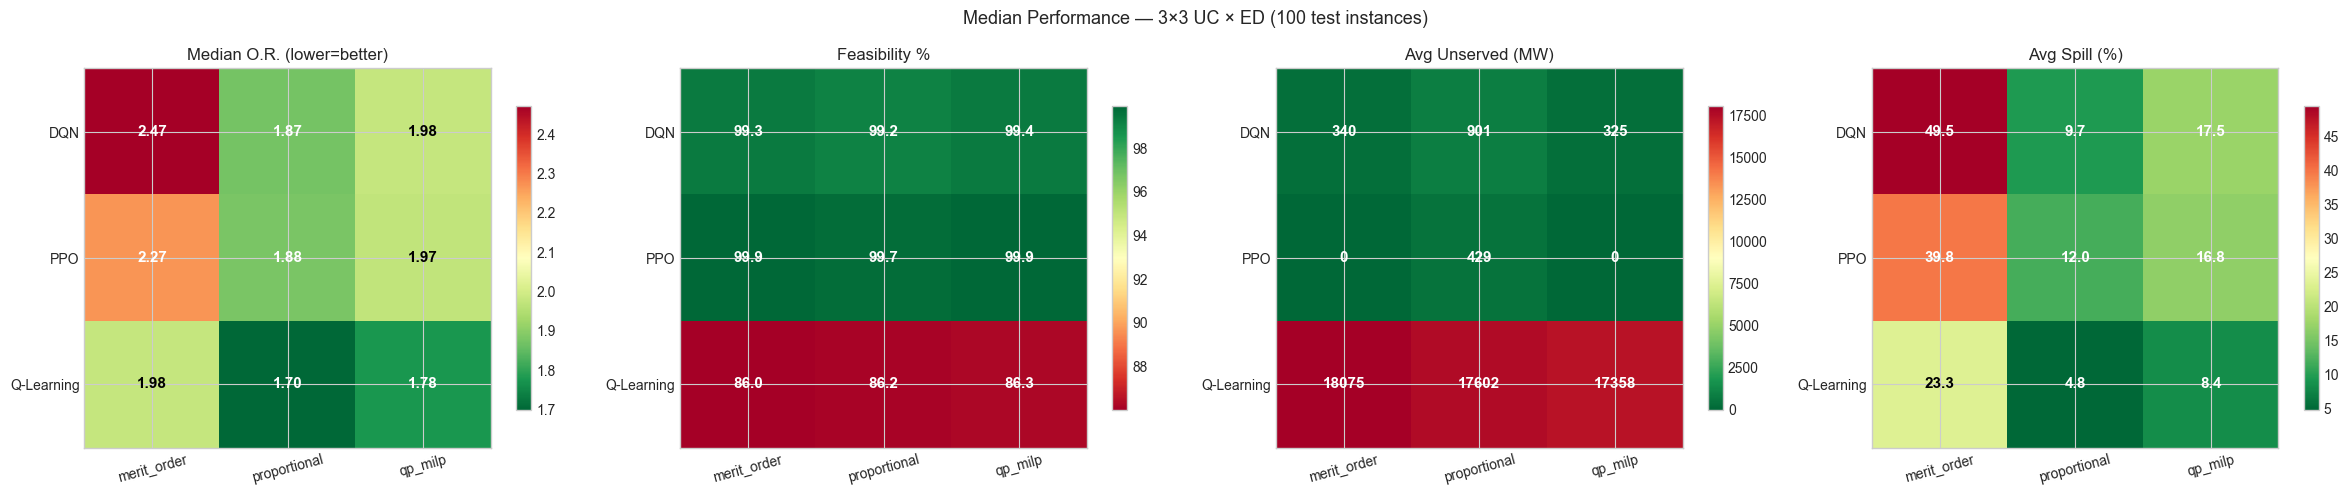

C:\Users\HP\AppData\Local\Temp\ipykernel_49936\195588272.py:57: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=labels, patch_artist=True)
C:\Users\HP\AppData\Local\Temp\ipykernel_49936\195588272.py:57: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=labels, patch_artist=True)
C:\Users\HP\AppData\Local\Temp\ipykernel_49936\195588272.py:57: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=labels, patch_artist=True)


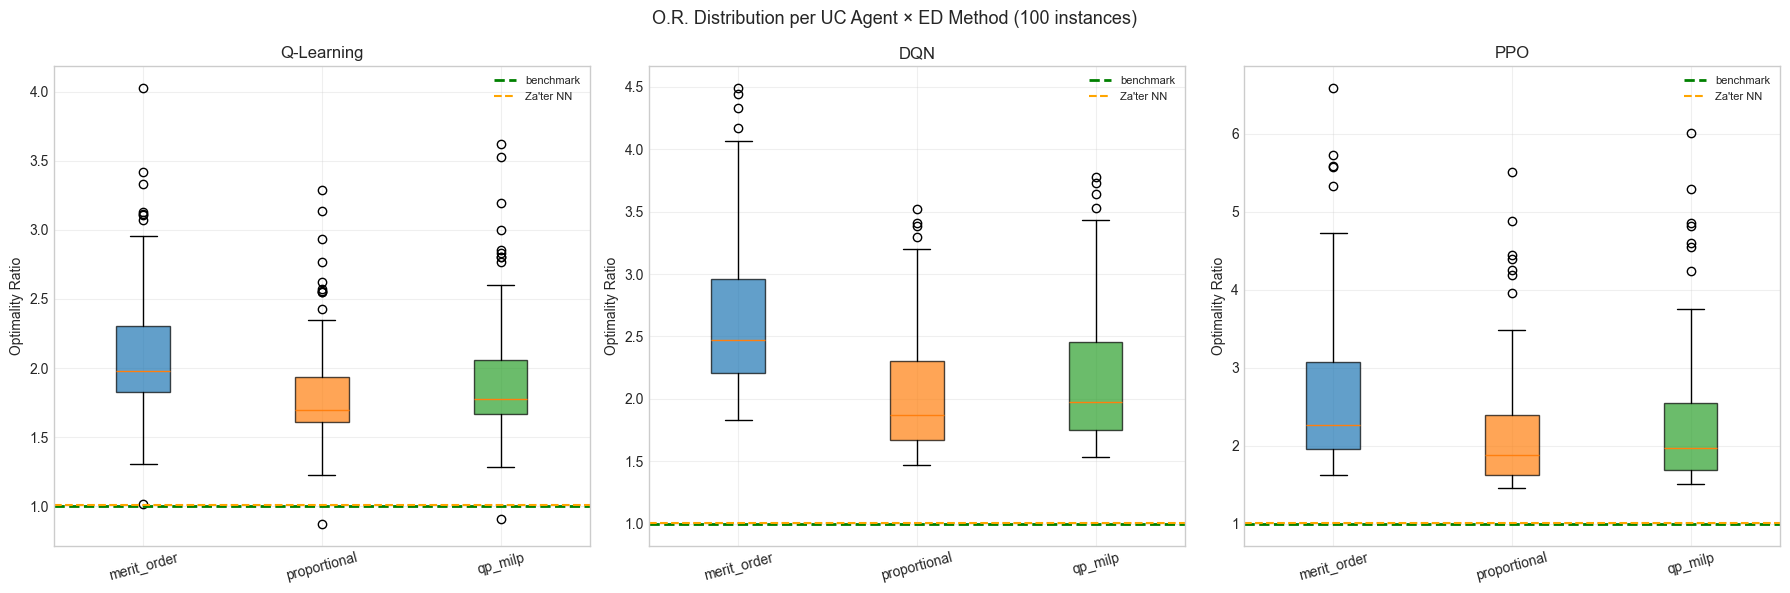

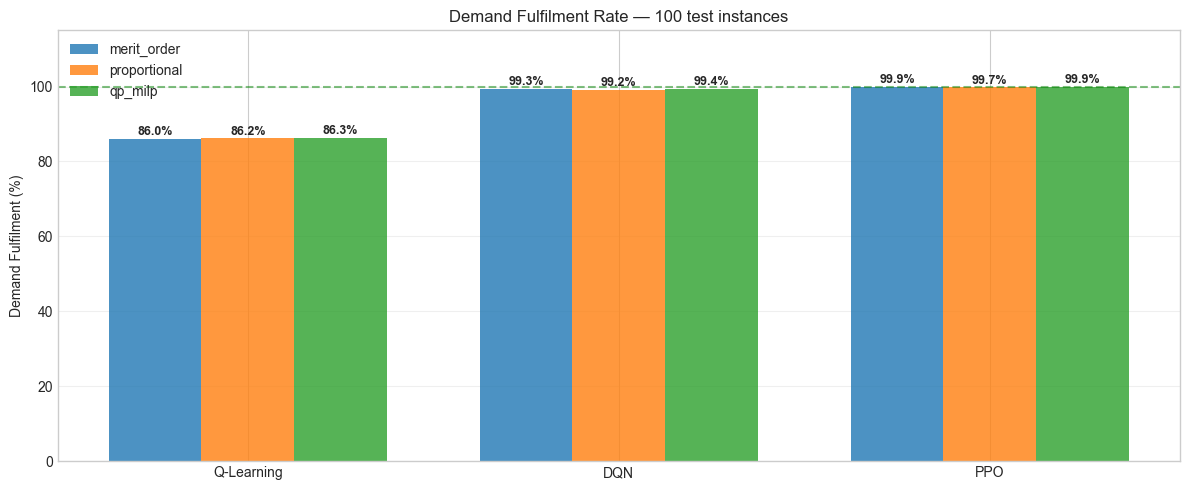

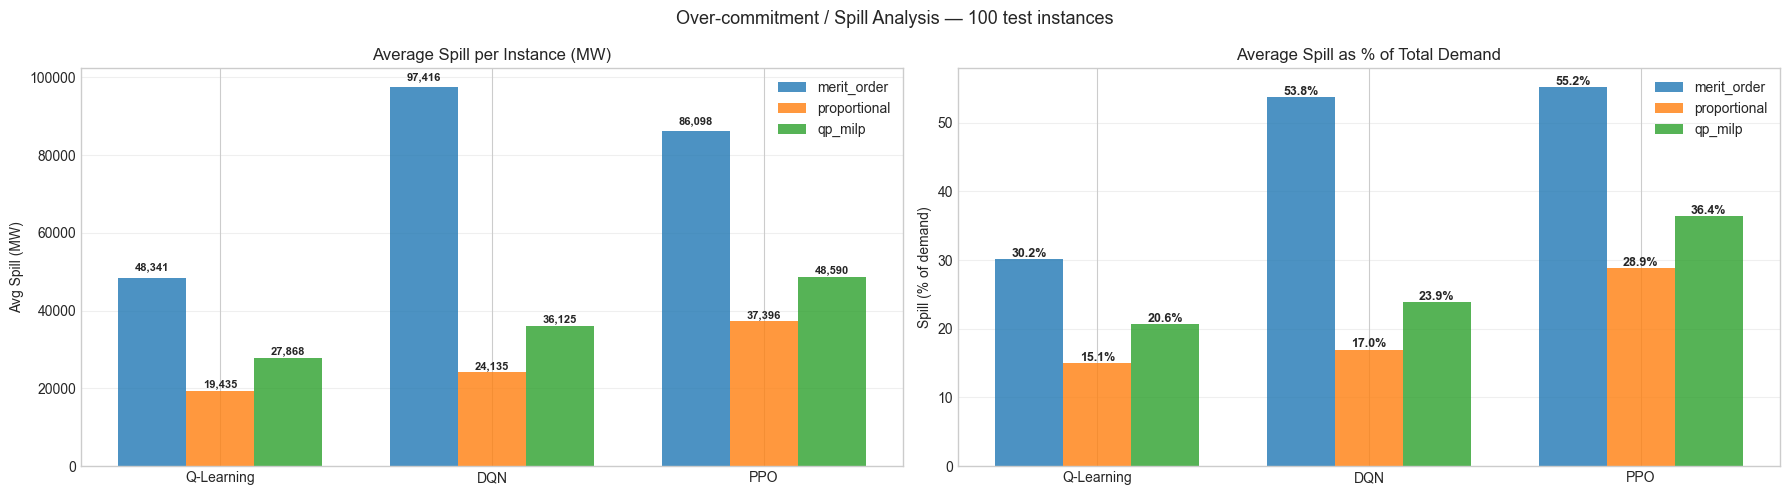

In [50]:
# ── Summary table: OR, feasibility, and spill ──
print("\n" + "="*100)
print("  OPTIMALITY RATIO — 100 test instances")
print("="*100)
for uc in ["Q-Learning","DQN","PPO"]:
    for ed in ["merit_order","proportional","qp_milp"]:
        sub = res_df[(res_df.uc_agent==uc) & (res_df.ed_method==ed)].dropna(subset=["OR"])
        q   = sub["OR"].quantile([0.25,0.5,0.75])
        f   = sub["feasibility_pct"].mean()
        sp  = sub["spill"].mean()
        sp_pct = sub["spill_pct"].mean()
        print(f"  {uc:12s} + {ed:14s} | "
              f"O.R.(25)={q.iloc[0]:.3f} | O.R.(50)={q.iloc[1]:.3f} | "
              f"O.R.(75)={q.iloc[2]:.3f} | Feas={f:.2f}% | "
              f"Spill={sp:>10,.0f}MW ({sp_pct:.1f}%)")
print(f"{'Za\'ter M6 (ref)':28s} | "
      f"O.R.(25)=1.000 | O.R.(50)=1.001 | O.R.(75)=1.002 | Feas=100%  | Spill=0MW (0.0%)")

# ── OR heatmap (now 4 panels) ──
fig, axes = plt.subplots(1, 4, figsize=(24, 5))
fig.suptitle("Median Performance — 3×3 UC × ED (100 test instances)", fontsize=13)

metrics = ["OR", "feasibility_pct", "unserved", "spill_pct"]
titles  = ["Median O.R. (lower=better)", "Feasibility %", "Avg Unserved (MW)", "Avg Spill (%)"]
cmaps   = ["RdYlGn_r", "RdYlGn", "RdYlGn_r", "RdYlGn_r"]
fmts    = [".2f", ".1f", ".0f", ".1f"]

for ax, metric, title, cmap, fmt in zip(axes, metrics, titles, cmaps, fmts):
    if metric == "feasibility_pct":
        pivot = res_df.groupby(["uc_agent","ed_method"])[metric].mean().unstack()
    else:
        pivot = res_df.groupby(["uc_agent","ed_method"])[metric].median().unstack()
    im = ax.imshow(pivot.values, cmap=cmap, aspect="auto")
    ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns, rotation=15)
    ax.set_yticks(range(len(pivot.index)));   ax.set_yticklabels(pivot.index)
    ax.set_title(title)
    for i in range(len(pivot.index)):
        for j in range(len(pivot.columns)):
            v = pivot.values[i,j]
            vmin, vmax = pivot.values.min(), pivot.values.max()
            norm_v = (v - vmin) / max(vmax - vmin, 1e-9)
            use_black = 0.35 < norm_v < 0.65
            ax.text(j, i, f"{v:{fmt}}", ha="center", va="center",
                    fontsize=11, fontweight="bold",
                    color="black" if use_black else "white")
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

# ── Boxplot OR per UC agent ──
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("O.R. Distribution per UC Agent × ED Method (100 instances)", fontsize=13)

for ax, uc_name in zip(axes, ["Q-Learning","DQN","PPO"]):
    sub = res_df[res_df.uc_agent==uc_name]
    data   = [sub[sub.ed_method==ed]["OR"].dropna().values for ed in ED_METHODS]
    labels = list(ED_METHODS.keys())
    bp = ax.boxplot(data, labels=labels, patch_artist=True)
    colors_box = ["tab:blue","tab:orange","tab:green"]
    for patch, clr in zip(bp["boxes"], colors_box):
        patch.set_facecolor(clr); patch.set_alpha(0.7)
    ax.axhline(1.0, color="green", ls="--", lw=2, label="benchmark")
    ax.axhline(1.0057, color="orange", ls="--", lw=1.5, label="Za'ter NN")
    ax.set_title(uc_name); ax.set_ylabel("Optimality Ratio")
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

# ── Feasibility bar chart ──
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(3)
w = 0.25
colors_ed = ["tab:blue","tab:orange","tab:green"]
for j, (ed_name, clr) in enumerate(zip(ED_METHODS, colors_ed)):
    feas = [res_df[(res_df.uc_agent==uc) & (res_df.ed_method==ed_name)]["feasibility_pct"].mean()
            for uc in ["Q-Learning","DQN","PPO"]]
    bars = ax.bar(x + j*w, feas, w, label=ed_name, color=clr, alpha=0.8)
    for bar, f in zip(bars, feas):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1,
                f"{f:.1f}%", ha="center", fontsize=9, fontweight="bold")
ax.set_xticks(x + w); ax.set_xticklabels(["Q-Learning","DQN","PPO"])
ax.set_ylabel("Demand Fulfilment (%)"); ax.set_ylim(0, 115)
ax.set_title("Demand Fulfilment Rate — 100 test instances")
ax.axhline(100, color="green", ls="--", lw=1.5, alpha=0.5)
ax.legend(); ax.grid(True, alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

# ── NEW: Spill bar chart ──
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
fig.suptitle("Over-commitment / Spill Analysis — 100 test instances", fontsize=13)

# Left: Spill in MW
ax = axes[0]
x = np.arange(3)
for j, (ed_name, clr) in enumerate(zip(ED_METHODS, colors_ed)):
    spill_mw = [res_df[(res_df.uc_agent==uc) & (res_df.ed_method==ed_name)]["spill"].mean()
                for uc in ["Q-Learning","DQN","PPO"]]
    bars = ax.bar(x + j*w, spill_mw, w, label=ed_name, color=clr, alpha=0.8)
    for bar, s in zip(bars, spill_mw):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height() + max(spill_mw)*0.02,
                f"{s:,.0f}", ha="center", fontsize=8, fontweight="bold", rotation=0)
ax.set_xticks(x + w); ax.set_xticklabels(["Q-Learning","DQN","PPO"])
ax.set_ylabel("Avg Spill (MW)"); ax.set_title("Average Spill per Instance (MW)")
ax.legend(); ax.grid(True, alpha=0.3, axis="y")

# Right: Spill as % of demand
ax = axes[1]
for j, (ed_name, clr) in enumerate(zip(ED_METHODS, colors_ed)):
    spill_pct = [res_df[(res_df.uc_agent==uc) & (res_df.ed_method==ed_name)]["spill_pct"].mean()
                 for uc in ["Q-Learning","DQN","PPO"]]
    bars = ax.bar(x + j*w, spill_pct, w, label=ed_name, color=clr, alpha=0.8)
    for bar, s in zip(bars, spill_pct):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3,
                f"{s:.1f}%", ha="center", fontsize=9, fontweight="bold")
ax.set_xticks(x + w); ax.set_xticklabels(["Q-Learning","DQN","PPO"])
ax.set_ylabel("Spill (% of demand)"); ax.set_title("Average Spill as % of Total Demand")
ax.legend(); ax.grid(True, alpha=0.3, axis="y")

plt.tight_layout(); plt.show()

## Ablation of Window

In [51]:
ABLATION_WINDOWS = [1, 4, 8, 24, 72]

def run_window_ablation(train_eps, test_eps, windows=ABLATION_WINDOWS,
                        n_epochs_data=3, seed=42, save_dir="ablation_v9"):
    from pathlib import Path
    out = Path(save_dir); out.mkdir(exist_ok=True)
    results, curves = [], {}
    for W in windows:
        model, cb = train_ppo(train_eps, "v2", W, 0.99,
                              n_epochs_data=n_epochs_data, seed=seed,
                              verbose_tag=f"W={W}")
        model.save(out / f"ppo_W{W}")
        curves[W] = {"rew": cb.ep_r, "cost": cb.ep_c, "startup": cb.ep_su}

        eval_env = UCOnlyEnv(test_eps, random_reset=False,
                             state_version="v2", obs_window=W)
        pol = lambda o: np.asarray(model.predict(o, deterministic=True)[0]).ravel()
        costs, unserved, online, first12 = [], [], [], []
        for i in range(len(test_eps)):
            tr = collect_uc_trace(eval_env, pol, instance_index=i)
            costs.append(tr["cost"].sum())
            unserved.append((tr["unserved_proxy"] > 1e-6).mean())
            online.append(tr["n_online"].mean())
            first12.append(tr["n_online"].values[:12].mean())
        results.append({
            "window": W,
            "mean_cost": float(np.mean(costs)),
            "unserved_rate": float(np.mean(unserved)),
            "mean_online": float(np.mean(online)),
            "mean_online_first12h": float(np.mean(first12)),   # the overcommit claim
        })
        print(f"  W={W}: cost={results[-1]['mean_cost']:,.0f} "
              f"online={results[-1]['mean_online']:.1f} "
              f"first12h={results[-1]['mean_online_first12h']:.1f}")

    df = pd.DataFrame(results)
    df.to_csv(out / "window_ablation.csv", index=False)
    with open(out / "curves.pkl", "wb") as f:
        pickle.dump(curves, f)
    return df, curves

df_abl, curves_abl = run_window_ablation(train_episodes, test_episodes)


c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\stable_baselines3\common\on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


Training PPO [W=1] — state=v2 | W=1 | gamma=0.99 | 64,800 timesteps (~900 episodes)...
  [   39s]  ep 0100 | rew=-6570.88 | startup=$1,776,870
  [   75s]  ep 0200 | rew=-1987.48 | startup=$1,862,931
  [  109s]  ep 0300 | rew=-1897.00 | startup=$1,792,755
  [  143s]  ep 0400 | rew=-1440.39 | startup=$1,795,529
  [  177s]  ep 0500 | rew=-2443.23 | startup=$1,819,808
  [  210s]  ep 0600 | rew=-1530.91 | startup=$1,828,608
  [  244s]  ep 0700 | rew=-3632.87 | startup=$1,865,009
  [  283s]  ep 0800 | rew=-1014.53 | startup=$1,811,067
  [  330s]  ep 0900 | rew=-686.95 | startup=$1,737,201
Done in 333s | 903 episodes
  W=1: cost=279,634,891 online=34.5 first12h=34.5
Training PPO [W=4] — state=v2 | W=4 | gamma=0.99 | 64,800 timesteps (~900 episodes)...
  [   51s]  ep 0100 | rew=-6640.38 | startup=$1,787,474
  [  103s]  ep 0200 | rew=-2008.68 | startup=$1,864,231
  [  159s]  ep 0300 | rew=-1978.98 | startup=$1,787,250
  [  211s]  ep 0400 | rew=-1599.41 | startup=$1,779,316
  [  271s]  ep 0500 |

In [54]:
curves_abl.keys()

dict_keys([1, 4, 8, 24, 72])

In [55]:
df_abl.to_csv("outputs/ablation_results.csv", index=False)
# curves_abl.to_csv("outputs/ablation_curves.csv", index=False)

In [72]:
# =============================================================================
# Window ablation — hourly commitment profiles
#
# Answers the supervisor's actual question: does shortening the forecast window
# change the SHAPE of commitment over the day, specifically the overcommitment
# in the early hours?
#
# The summary CSV only has episode-mean values, which average that shape away.
#
# Requires the saved models from run_window_ablation (ablation_v9/ppo_W*.zip).
# =============================================================================

FIGDIR = Path("figures/ablation"); FIGDIR.mkdir(parents=True, exist_ok=True)
MODELDIR = Path("ablation_v9")
WINDOWS = [1, 4, 8, 24, 72]

plt.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "legend.fontsize": 9, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
})
COLORS = dict(zip(WINDOWS, ["#c7c7c7", "#f0a202", "#d1495b", "#5b8c5a", "#2c7fb8"]))


def save(fig, name):
    fig.savefig(FIGDIR / f"{name}.png"); fig.savefig(FIGDIR / f"{name}.pdf")
    print(f"  saved {name}")


# -----------------------------------------------------------------------
# 1. Collect per-hour traces for every window
# -----------------------------------------------------------------------
def collect_hourly(test_eps, windows=WINDOWS, spill_penalty=1000):
    """
    Returns dict[W] -> DataFrame indexed by hour 0..71 with the mean across
    test instances of: n_online, over_commit, unserved, net_demand.
    """
    out = {}
    for W in windows:
        model = SB3_PPO.load(MODELDIR / f"ppo_W{W}")
        eval_env = UCOnlyEnv(test_eps, spill_penalty=spill_penalty,
                             random_reset=False, state_version="v2", obs_window=W)
        pol = lambda o: np.asarray(model.predict(o, deterministic=True)[0]).ravel()

        stack = []
        for i in range(len(test_eps)):
            tr = collect_uc_trace(eval_env, pol, instance_index=i)
            stack.append(tr[["n_online", "over_commit",
                             "unserved_proxy", "net_demand"]].to_numpy(float))
        arr = np.stack(stack)                      # (n_instances, 72, 4)
        out[W] = pd.DataFrame(arr.mean(axis=0),
                              columns=["n_online", "over_commit",
                                       "unserved", "net_demand"])
        out[W].index.name = "hour"
        print(f"  W={W}: collected {len(stack)} instances")
    return out

In [85]:
# -----------------------------------------------------------------------
# 2. Panel (a) — units online per hour, one line per window
#    THE key figure: if the supervisor is right, short windows should show a
#    visibly lower early-hours plateau.
# -----------------------------------------------------------------------
def plot_online_profile(hourly, first, second, name="a_online_per_hour"):
    fig, ax = plt.subplots(figsize=(7, 3.6))
    for W in sorted(hourly):
        ax.plot(hourly[W].index, hourly[W]["n_online"],
                color=COLORS.get(W), lw=1.8, label=f"W = {W}")
    ax.axvspan(0, 12, color="grey", alpha=0.10)
    ax.text(6, ax.get_ylim()[1] * 0.98, "first 12 h", ha="center",
            va="top", fontsize=8, color="grey")
    ax.set_xlabel("Hour of episode"); ax.set_ylabel("Units committed")
    ax.legend(frameon=False, ncol=5, loc="lower right")

    early = {W: hourly[W]["n_online"][:12].mean() for W in hourly}
    best, worst = min(early, key=early.get), max(early, key=early.get)
    ax.set_title(f"Early-hours commitment lowest at W={first} "
                 f"({early[first]:.1f} units) vs W={second} ({early[second]:.1f})")
    save(fig, name); plt.close(fig)
    return early

In [74]:
# -----------------------------------------------------------------------
# 3. Panel (b) — overcommitment (MW above requirement) per hour
#    n_online counts units; over_commit measures the actual waste in MW.
# -----------------------------------------------------------------------
def plot_overcommit_profile(hourly, name="b_overcommit_per_hour"):
    fig, ax = plt.subplots(figsize=(7, 3.6))
    for W in sorted(hourly):
        ax.plot(hourly[W].index, hourly[W]["over_commit"],
                color=COLORS.get(W), lw=1.8, label=f"W = {W}")
    ax.axvspan(0, 12, color="grey", alpha=0.10)
    ax.set_xlabel("Hour of episode"); ax.set_ylabel("Overcommitment (MW)")
    ax.legend(frameon=False, ncol=5)
    early = {W: hourly[W]["over_commit"][:12].mean() for W in hourly}
    best = min(early, key=early.get)
    ax.set_title(f"Peak overcommitment occurs in the first hours; "
                 f"lowest early waste at W={best}")
    save(fig, name); plt.close(fig)

In [75]:
# -----------------------------------------------------------------------
# 4. Panel (c) — commitment against what demand actually required
#    Shows whether the agent tracks the demand shape at all.
# -----------------------------------------------------------------------
def plot_vs_demand(hourly, thermal_df, windows=(4, 72), name="c_vs_demand"):
    pmax_sorted = np.sort(thermal_df["pmax"].to_numpy(float))[::-1]
    cum = np.cumsum(pmax_sorted)

    fig, axes = plt.subplots(1, len(windows), figsize=(9, 3.4), sharey=True)
    for ax, W in zip(np.atleast_1d(axes), windows):
        h = hourly[W]
        # minimum units needed if you greedily used the largest units first
        need = [int(np.searchsorted(cum, max(d, 0)) + 1) for d in h["net_demand"]]
        ax.plot(h.index, h["n_online"], color=COLORS.get(W), lw=1.8,
                label="Committed")
        ax.plot(h.index, need, color="black", lw=1.2, ls="--",
                label="Minimum needed")
        gap = np.mean(np.array(h["n_online"]) - np.array(need))
        ax.set_title(f"W = {W} — mean excess {gap:.1f} units")
        ax.set_xlabel("Hour of episode")
    np.atleast_1d(axes)[0].set_ylabel("Units")
    np.atleast_1d(axes)[0].legend(frameon=False)
    save(fig, name); plt.close(fig)

In [76]:
# -----------------------------------------------------------------------
# 5. Panel (d) — summary metrics vs window (the CSV, plotted)
# -----------------------------------------------------------------------
def plot_summary(df_abl, name="d_summary_vs_window"):
    fig, ax1 = plt.subplots(figsize=(5, 3.4))
    ax1.plot(df_abl["window"], df_abl["mean_cost"] / 1e6,
             "o-", color="#2c7fb8", lw=1.8)
    ax1.set_xscale("log"); ax1.set_xticks(df_abl["window"])
    ax1.set_xticklabels(df_abl["window"])
    ax1.set_xlabel("Observation window W (hours)")
    ax1.set_ylabel("Mean cost (M$)", color="#2c7fb8")
    ax1.tick_params(axis="y", labelcolor="#2c7fb8")

    ax2 = ax1.twinx(); ax2.grid(False)
    ax2.plot(df_abl["window"], df_abl["unserved_rate"] * 100,
             "s--", color="#d1495b", lw=1.5)
    ax2.set_ylabel("Unserved rate (%)", color="#d1495b")
    ax2.tick_params(axis="y", labelcolor="#d1495b")

    spread = (df_abl["mean_cost"].max() - df_abl["mean_cost"].min()) / df_abl["mean_cost"].mean()
    ax1.set_title(f"Cost varies by only {spread:.1%} across W — no clear trend")
    save(fig, name); plt.close(fig)

In [77]:
# =======================================================================
# RUN
# =======================================================================
hourly = collect_hourly(test_episodes)
early  = plot_online_profile(hourly)
plot_overcommit_profile(hourly)
plot_vs_demand(hourly, thermal_df, windows=(4, 72))
plot_summary(pd.read_csv("ablation_v9/window_ablation.csv"))

# save the per-hour numbers so the write-up can quote them
pd.concat({W: hourly[W] for W in hourly}, names=["window"]).to_csv(
    "ablation_v9/hourly_profiles.csv")

c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\stable_baselines3\common\on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


  W=1: collected 100 instances


c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\stable_baselines3\common\on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


  W=4: collected 100 instances


c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\stable_baselines3\common\on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


  W=8: collected 100 instances


c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\stable_baselines3\common\on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


  W=24: collected 100 instances


c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\stable_baselines3\common\on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


  W=72: collected 100 instances
  saved a_online_per_hour
  saved b_overcommit_per_hour
  saved c_vs_demand
  saved d_summary_vs_window


  saved a_commitment_schedule


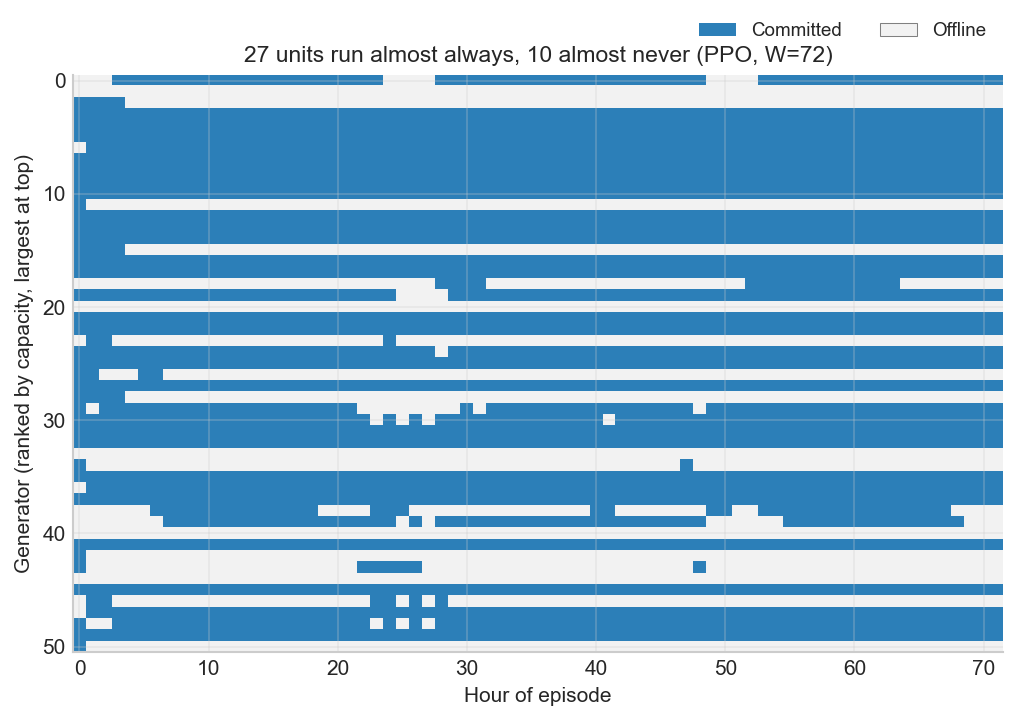

  saved b_illegal_actions


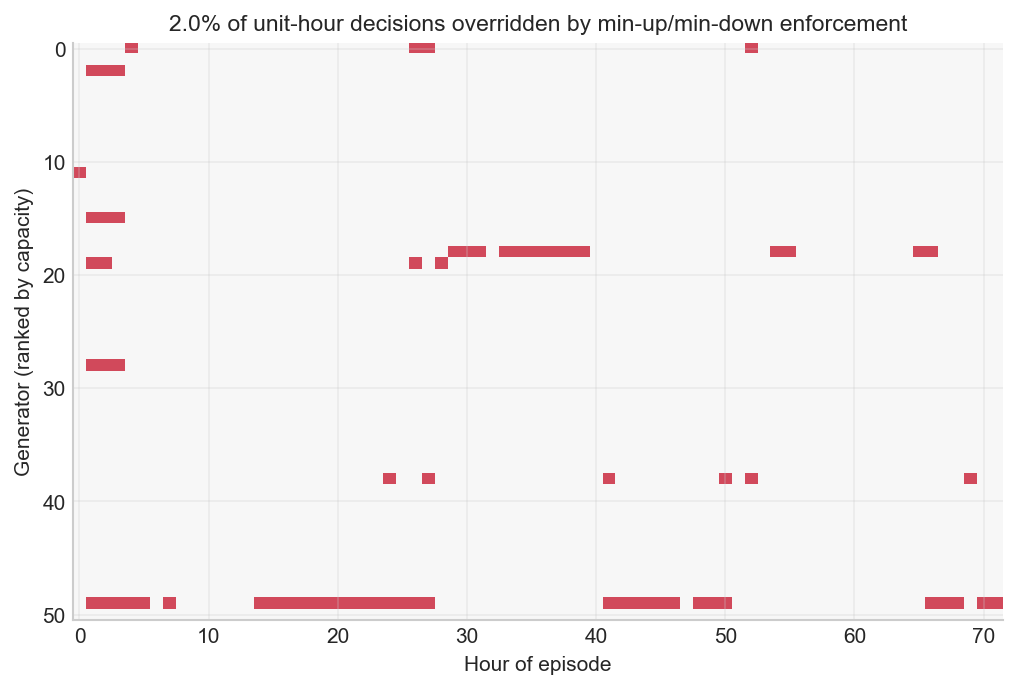

  saved c_override_per_hour


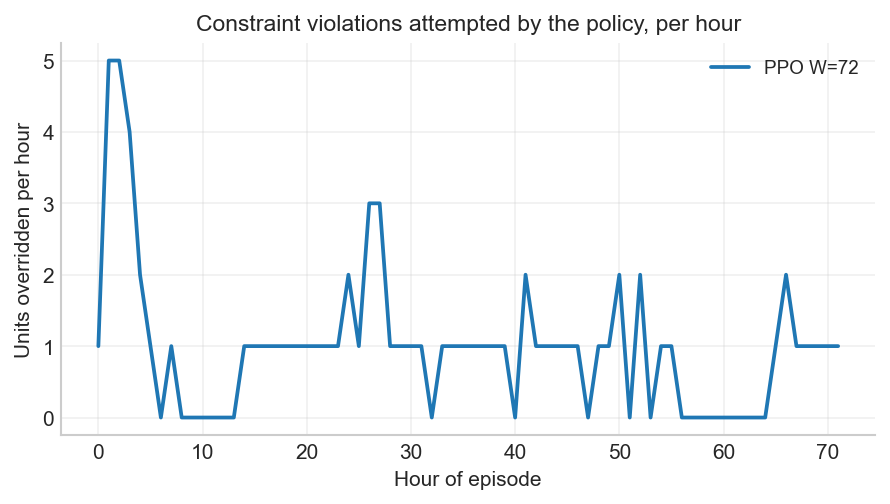

In [78]:
# =============================================================================
# Commitment visualisation + constraint-legality diagnostics
#
# Two things at once:
#   1. What the agent's on/off schedule actually looks like (heatmap over
#      51 units x 72 hours) — the figure the report is missing.
#   2. Whether the v2 state vector reduced ILLEGAL actions. If the clocks are
#      informative, the agent should attempt fewer moves that _legalise has to
#      override. This is measurable WITHOUT retraining anything.
#
# Requires: env with info["n_overrides"], info["on"], info["raw_action"]
# =============================================================================

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import ListedColormap

FIGDIR = Path("figures/commitment"); FIGDIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "legend.fontsize": 9, "axes.spines.top": False, "axes.spines.right": False,
})

def save(fig, name):
    fig.savefig(FIGDIR / f"{name}.png"); fig.savefig(FIGDIR / f"{name}.pdf")
    print(f"  saved {name}")


# -----------------------------------------------------------------------
# Collect a full trace INCLUDING the raw (pre-legalisation) action
# -----------------------------------------------------------------------
def run_episode_detailed(env_obj, policy, instance_index=0):
    """
    Returns dict with:
      on      (72, 51) what actually ran after _legalise
      raw     (72, 51) what the policy asked for
      illegal (72, 51) bool, where the two disagree
      plus per-hour scalars.
    """
    obs, _ = env_obj.reset(options={"episode_index": instance_index})
    on, raw, rows = [], [], []
    done = False
    while not done:
        a = policy(obs)
        obs, rew, done, _, info = env_obj.step(a)
        on.append(info["on"]); raw.append(info["raw_action"])
        rows.append({"hour": info["hour"], "n_online": info["n_online"],
                     "n_overrides": info["n_overrides"],
                     "over_commit": info["over_commit"],
                     "unserved": info["unserved_proxy"],
                     "net_demand": info["net_demand"],
                     "n_startups": info["n_startups"], "cost": info["cost"]})
    on = np.array(on); raw = np.array(raw)
    return {"on": on, "raw": raw, "illegal": (on != raw),
            "df": pd.DataFrame(rows)}


# -----------------------------------------------------------------------
# (a) Commitment schedule heatmap — units sorted by capacity
# -----------------------------------------------------------------------
def plot_commitment_heatmap(trace, thermal_df, name="a_commitment_schedule",
                            title_extra=""):
    order = np.argsort(-thermal_df["pmax"].to_numpy(float))
    M = trace["on"][:, order].T                      # (51 units, 72 hours)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.imshow(M, aspect="auto", interpolation="nearest",
              cmap=ListedColormap(["#f2f2f2", "#2c7fb8"]), vmin=0, vmax=1)
    ax.set_xlabel("Hour of episode")
    ax.set_ylabel("Generator (ranked by capacity, largest at top)")

    duty = M.mean(axis=1)
    always = int((duty > 0.95).sum()); never = int((duty < 0.05).sum())
    ax.set_title(f"{always} units run almost always, {never} almost never"
                 f"{title_extra}")

    handles = [plt.Rectangle((0, 0), 1, 1, fc="#2c7fb8"),
               plt.Rectangle((0, 0), 1, 1, fc="#f2f2f2", ec="grey", lw=0.5)]
    ax.legend(handles, ["Committed", "Offline"], frameon=False,
              loc="upper right", bbox_to_anchor=(1.0, 1.12), ncol=2)
    save(fig, name); plt.show() 
    #plt.close(fig)
    return duty


# -----------------------------------------------------------------------
# (b) Illegal-action map — where the environment had to override the policy
#     Dense red = the agent keeps asking for moves the constraints forbid.
# -----------------------------------------------------------------------
def plot_illegal_map(trace, thermal_df, name="b_illegal_actions"):
    order = np.argsort(-thermal_df["pmax"].to_numpy(float))
    M = trace["illegal"][:, order].T.astype(float)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.imshow(M, aspect="auto", interpolation="nearest",
              cmap=ListedColormap(["#f7f7f7", "#d1495b"]), vmin=0, vmax=1)
    ax.set_xlabel("Hour of episode"); ax.set_ylabel("Generator (ranked by capacity)")
    rate = M.mean()
    ax.set_title(f"{rate:.1%} of unit-hour decisions overridden by "
                 f"min-up/min-down enforcement")
    save(fig, name); plt.show() 
    #plt.close(fig)
    return rate


# -----------------------------------------------------------------------
# (c) Override rate over the day — is illegality concentrated early?
# -----------------------------------------------------------------------
def plot_override_profile(traces_by_label, name="c_override_per_hour"):
    fig, ax = plt.subplots(figsize=(7, 3.4))
    for label, tr in traces_by_label.items():
        ax.plot(tr["df"]["hour"], tr["df"]["n_overrides"], lw=1.8, label=label)
    ax.set_xlabel("Hour of episode")
    ax.set_ylabel("Units overridden per hour")
    ax.grid(alpha=0.3); ax.legend(frameon=False)
    ax.set_title("Constraint violations attempted by the policy, per hour")
    save(fig, name); plt.show() 
    #   plt.close(fig)


# -----------------------------------------------------------------------
# (d) THE DIAGNOSTIC — v1 vs v2 illegal-action rate, no retraining of v2
#     needed; you only need each model evaluated in its own env.
# -----------------------------------------------------------------------
def compare_legality(models_by_label, test_eps, n_instances=20,
                     spill_penalty=1000):
    """
    models_by_label: {"v1 (prev_on)": (model, "v1", 72),
                      "v2 (clocks)":  (model, "v2", 72)}
    Returns a tidy DataFrame — this is the table for the Wednesday email.
    """
    rows = []
    for label, (model, sv, W) in models_by_label.items():
        e = UCOnlyEnv(test_eps, spill_penalty=spill_penalty, random_reset=False,
                      state_version=sv, obs_window=W)
        pol = lambda o: np.asarray(model.predict(o, deterministic=True)[0]).ravel()
        ov, ill, cost, online = [], [], [], []
        for i in range(min(n_instances, len(test_eps))):
            tr = run_episode_detailed(e, pol, instance_index=i)
            ov.append(tr["df"]["n_overrides"].sum())
            ill.append(tr["illegal"].mean())
            cost.append(tr["df"]["cost"].sum())
            online.append(tr["df"]["n_online"].mean())
        rows.append({"state": label,
                     "overrides_per_episode": np.mean(ov),
                     "illegal_rate": np.mean(ill),
                     "mean_cost": np.mean(cost),
                     "mean_online": np.mean(online)})
    df = pd.DataFrame(rows)
    print(df.to_string(index=False))
    return df


# =======================================================================
# RUN
# =======================================================================
eval_env = UCOnlyEnv(test_episodes, spill_penalty=1000, random_reset=False,
                     state_version="v2", obs_window=72)
tr = run_episode_detailed(eval_env, ppo_policy, instance_index=0)

duty = plot_commitment_heatmap(tr, thermal_df, title_extra=" (PPO, W=72)")
rate = plot_illegal_map(tr, thermal_df)
plot_override_profile({"PPO W=72": tr})

c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\stable_baselines3\common\on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


  W=1: collected 100 instances


c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\stable_baselines3\common\on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


  W=4: collected 100 instances


c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\stable_baselines3\common\on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


  W=8: collected 100 instances


c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\stable_baselines3\common\on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


  W=24: collected 100 instances


c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\stable_baselines3\common\on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


  W=72: collected 100 instances
  saved a_online_per_hour
  saved b_overcommit_per_hour


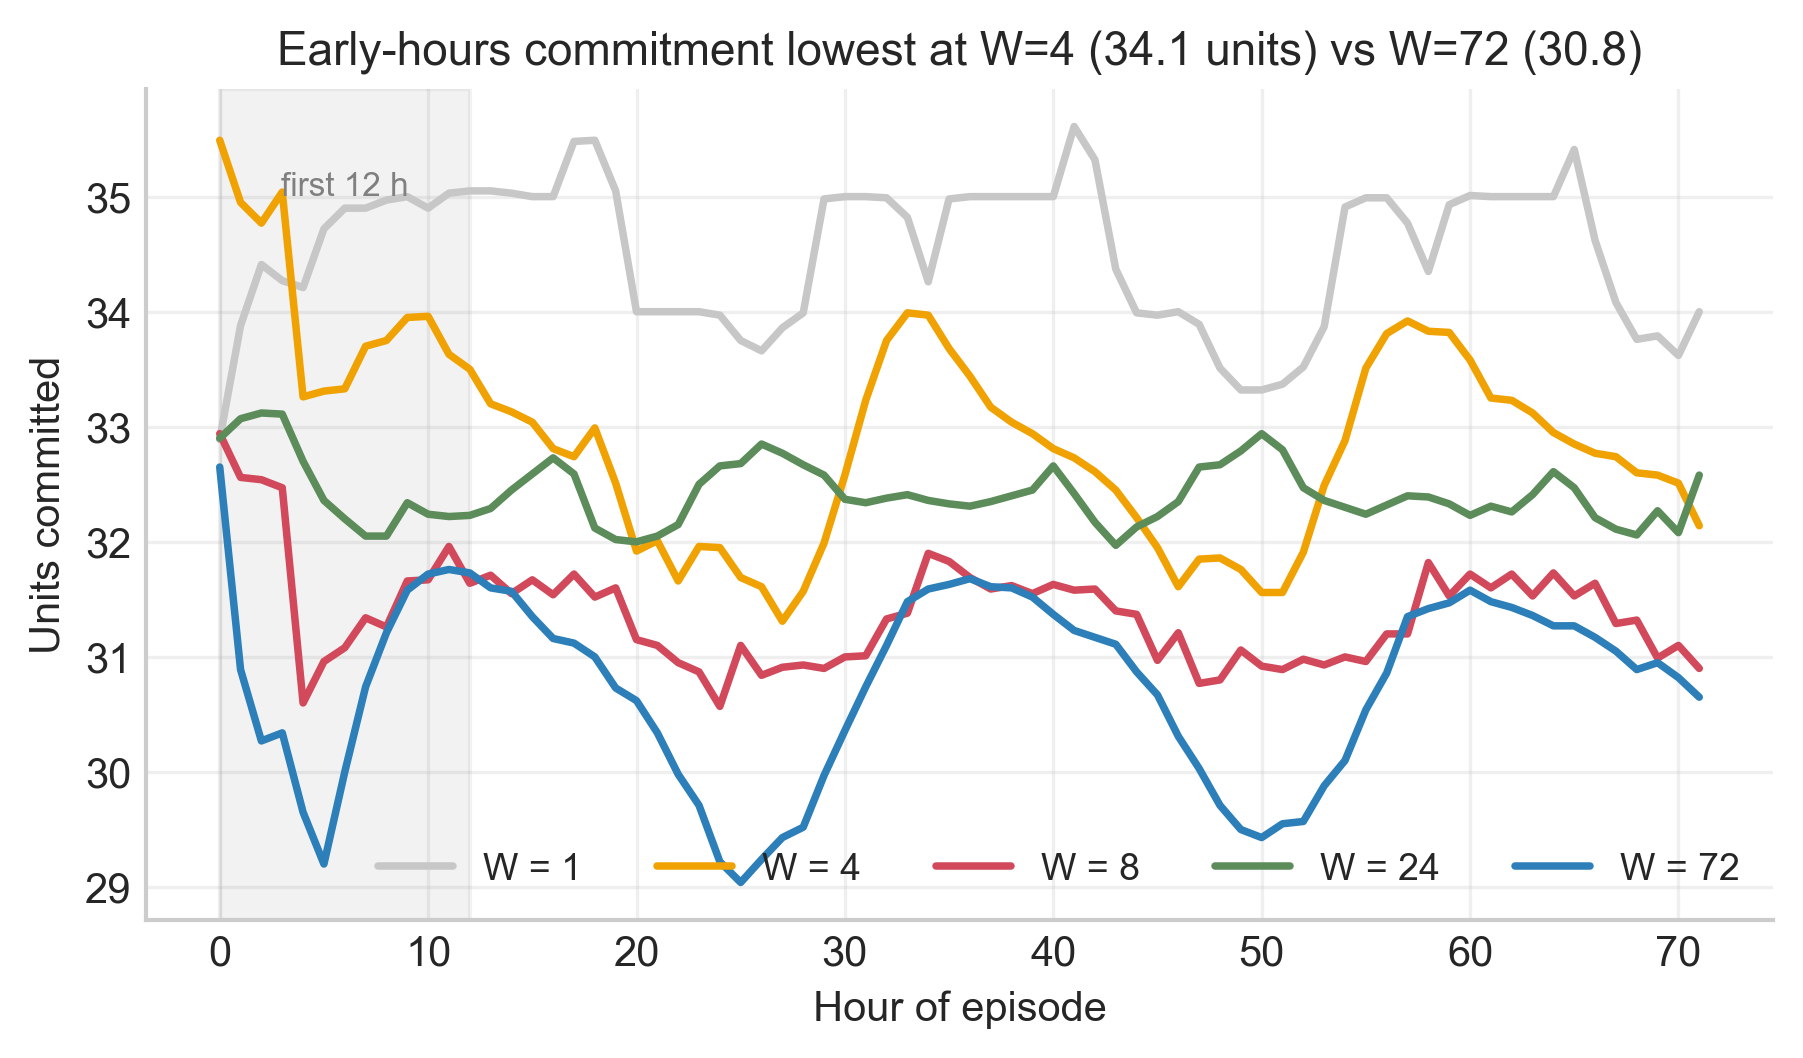

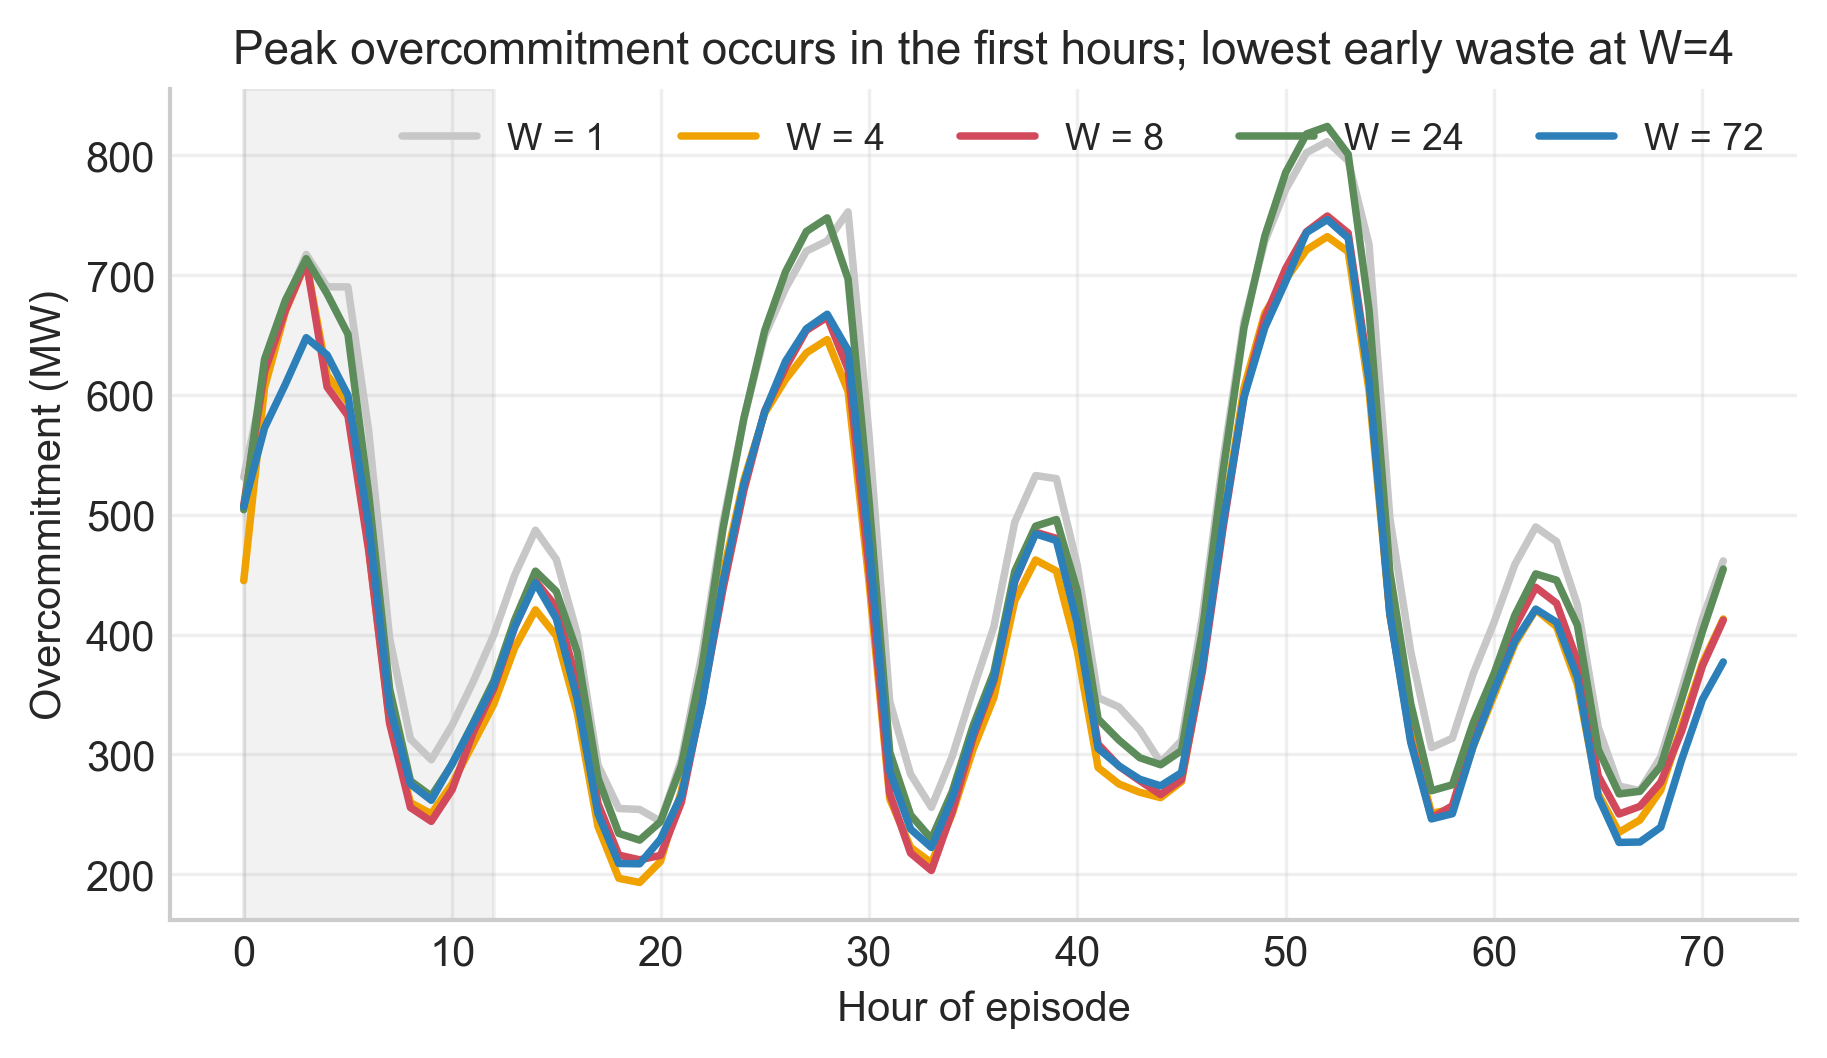

In [87]:
hourly = collect_hourly(test_episodes)          # ~1-2 menit, 5 window x 100 instance
early  = plot_online_profile(hourly, first=4, second=72)
plot_overcommit_profile(hourly)

from IPython.display import Image, display
display(Image(filename="figures/ablation/a_online_per_hour.png"))
display(Image(filename="figures/ablation/b_overcommit_per_hour.png"))

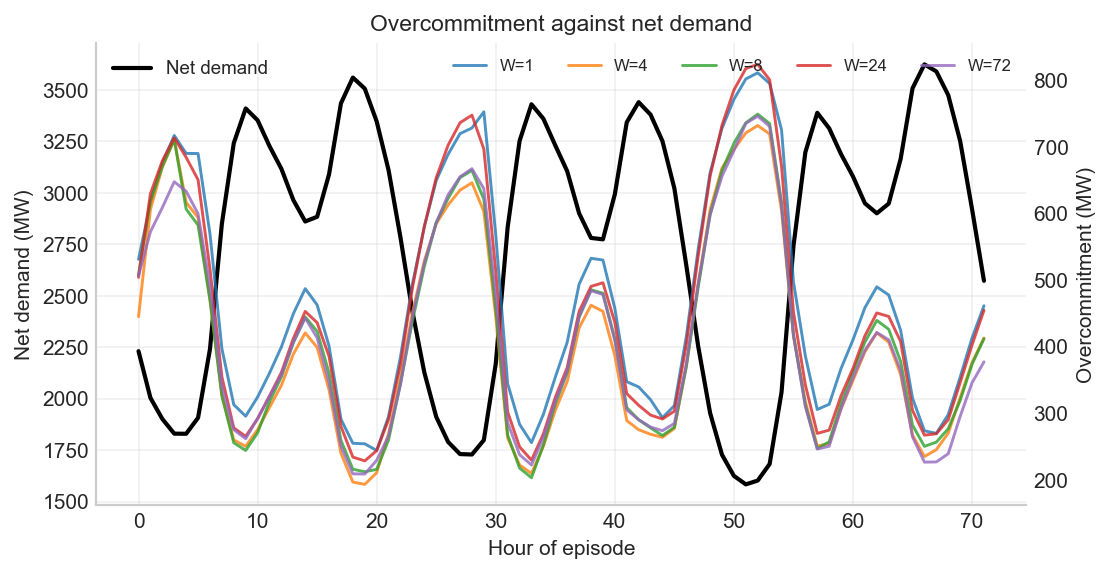

In [81]:
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(hourly[72].index, hourly[72]["net_demand"], color="black", lw=2,
         label="Net demand")
ax1.set_xlabel("Hour of episode"); ax1.set_ylabel("Net demand (MW)")

ax2 = ax1.twinx(); ax2.grid(False)
for W in [1, 4, 8, 24, 72]:
    ax2.plot(hourly[W].index, hourly[W]["over_commit"], lw=1.4, alpha=0.8,
             label=f"W={W}")
ax2.set_ylabel("Overcommitment (MW)")

ax1.legend(loc="upper left", frameon=False)
ax2.legend(loc="upper right", frameon=False, ncol=5, fontsize=8)
plt.title("Overcommitment against net demand")
plt.savefig("figures/ablation/e_overcommit_vs_demand.png", dpi=300, bbox_inches="tight")
plt.show()

In [92]:
# nilai yang dipakai saat training PPO v8
print("wrapper default:", UCGymWrapper.__init__.__defaults__)
# dan lihat sel yang memanggil train_ppo untuk baseline v8

wrapper default: (42, 'v2', 72)


c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\stable_baselines3\common\on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


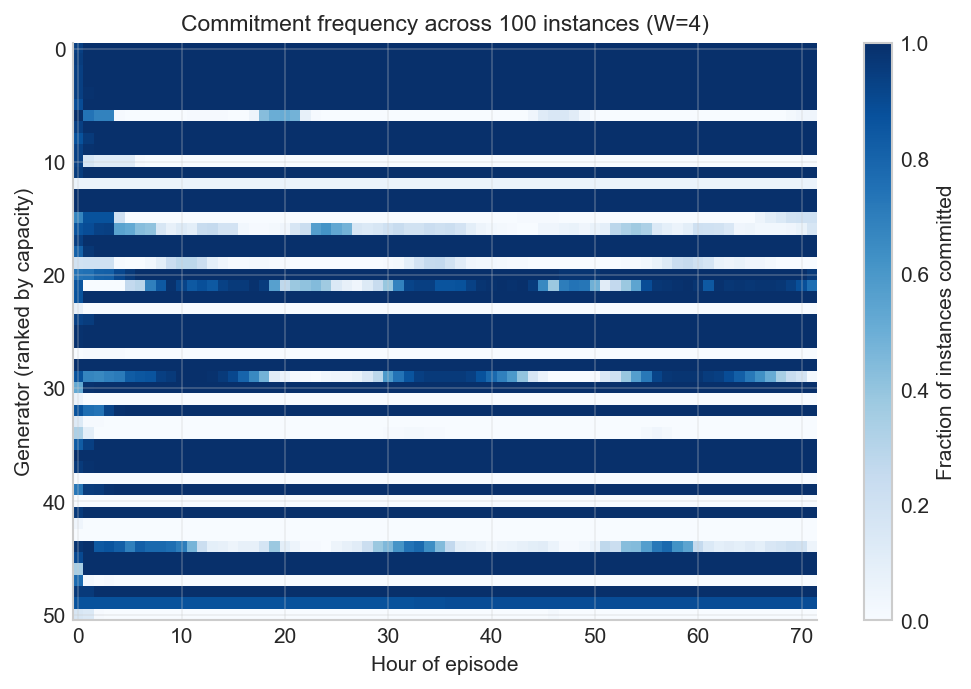

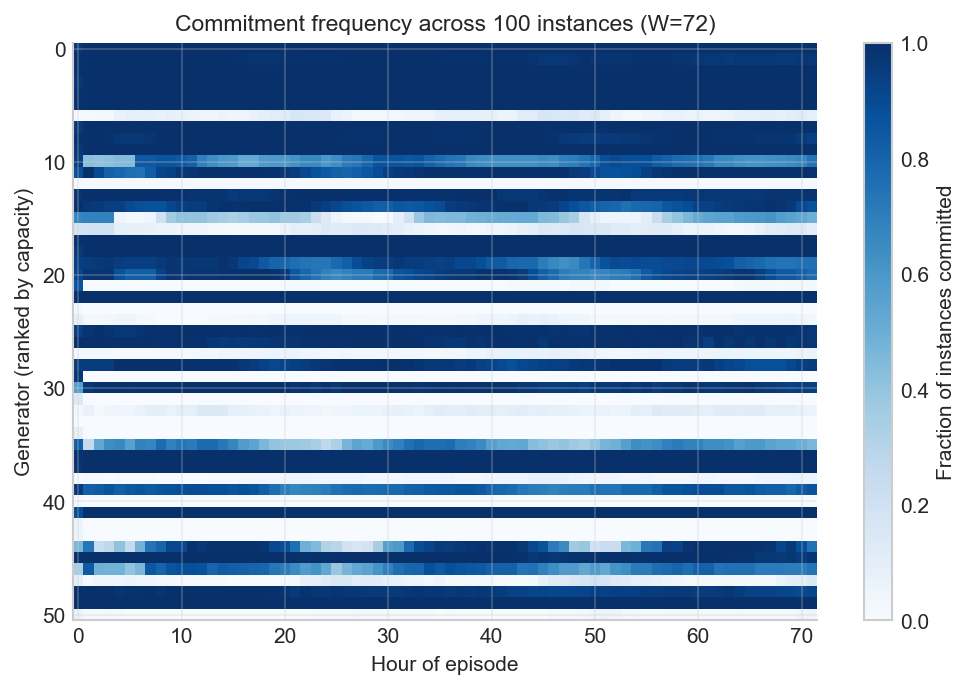

In [88]:
def plot_duty_heatmap(test_eps, W, thermal_df, n_inst=100):
    m = SB3_PPO.load(f"ablation_v9/ppo_W{W}")
    e = UCOnlyEnv(test_eps, spill_penalty=1000, random_reset=False,
                  state_version="v2", obs_window=W)
    pol = lambda o: np.asarray(m.predict(o, deterministic=True)[0]).ravel()

    stack = [run_episode_detailed(e, pol, i)["on"]
             for i in range(min(n_inst, len(test_eps)))]
    duty = np.stack(stack).mean(axis=0)              # (72, 51), nilai 0..1

    order = np.argsort(-thermal_df["pmax"].to_numpy(float))
    fig, ax = plt.subplots(figsize=(8, 5))
    im = ax.imshow(duty[:, order].T, aspect="auto", cmap="Blues",
                   vmin=0, vmax=1, interpolation="nearest")
    plt.colorbar(im, ax=ax, label="Fraction of instances committed")
    ax.set_xlabel("Hour of episode")
    ax.set_ylabel("Generator (ranked by capacity)")
    ax.set_title(f"Commitment frequency across {len(stack)} instances (W={W})")
    fig.savefig(f"figures/commitment/duty_W{W}.png", dpi=300, bbox_inches="tight")
    plt.show()

for W in [4, 72]:
    plot_duty_heatmap(test_episodes, W, thermal_df)

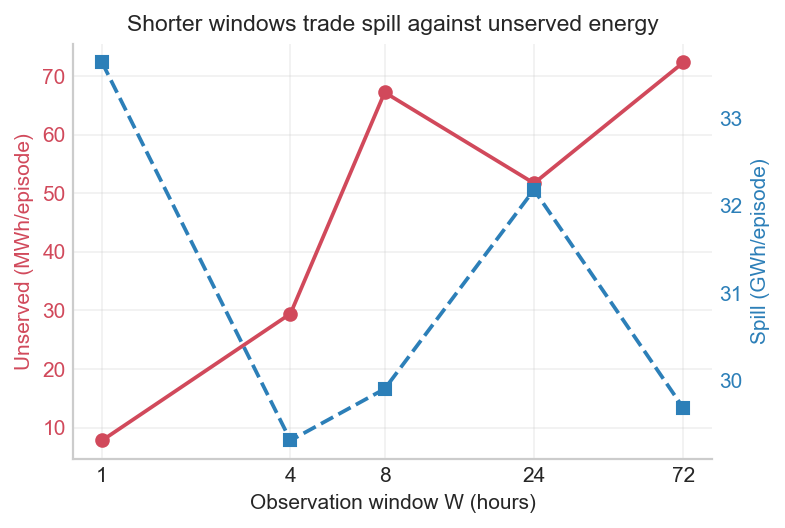

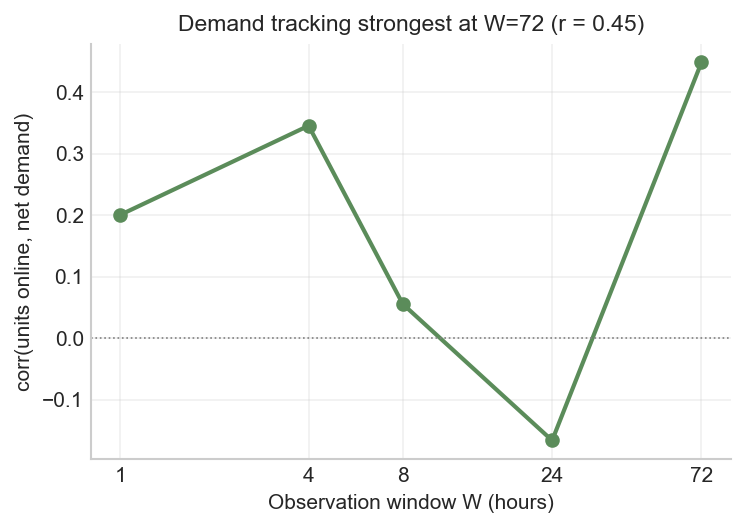

In [89]:
import pandas as pd
df_bd = pd.read_csv("ablation_v9/window_breakdown.csv")
plot_tradeoff(df_bd)
plot_responsiveness(df_bd)

In [82]:
nd = np.array([ep["demand"] - ep["wind"] - ep["solar"] for ep in test_episodes])
print("std across instances at each hour:", nd.std(axis=0).mean())
print("std across hours of the mean profile:", nd.mean(axis=0).std())

std across instances at each hour: 1706.9435700439612
std across hours of the mean profile: 629.1198332889821


c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\stable_baselines3\common\on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


  saved a_commitment_W4


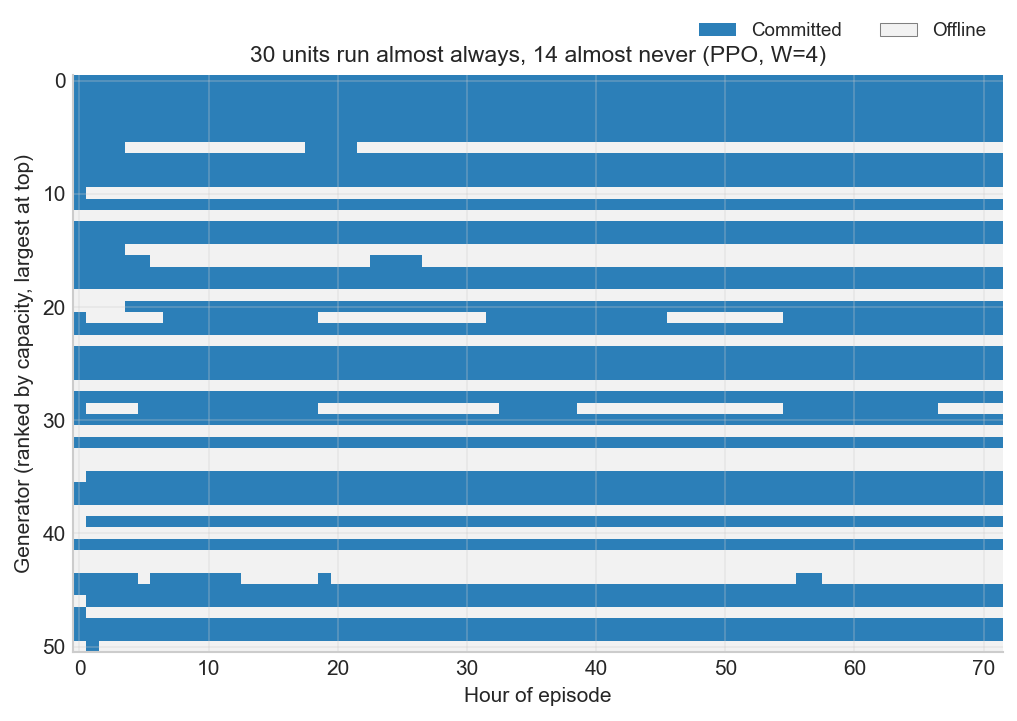

W=4: mean online 32.5, overrides 84


c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\stable_baselines3\common\on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


  saved a_commitment_W8


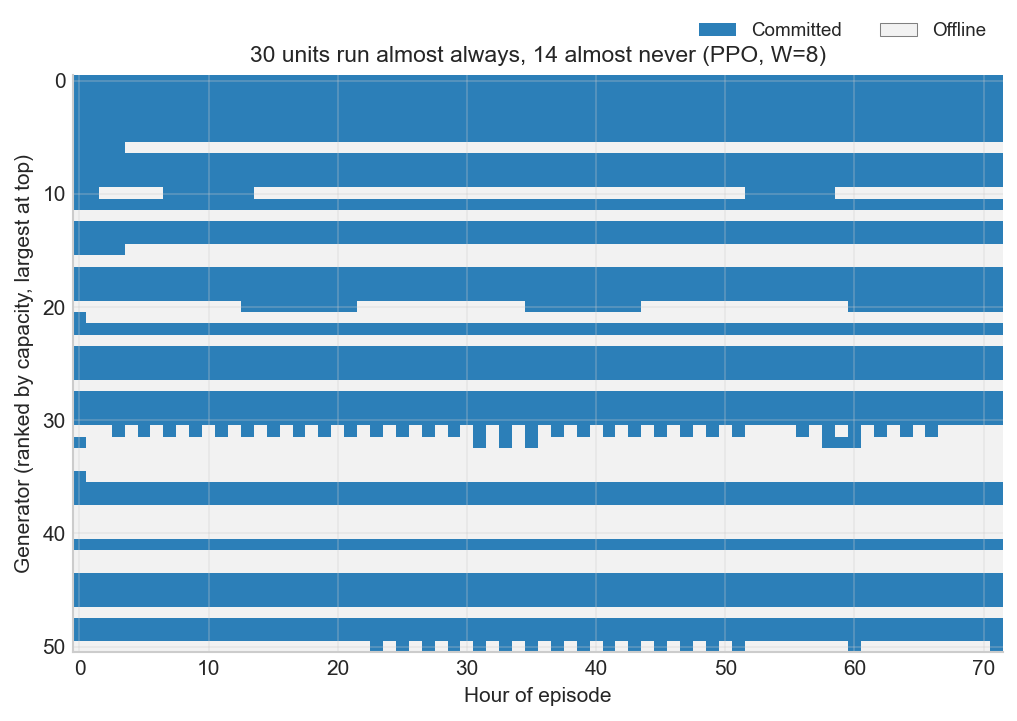

W=8: mean online 31.5, overrides 81


c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\stable_baselines3\common\on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


  saved a_commitment_W72


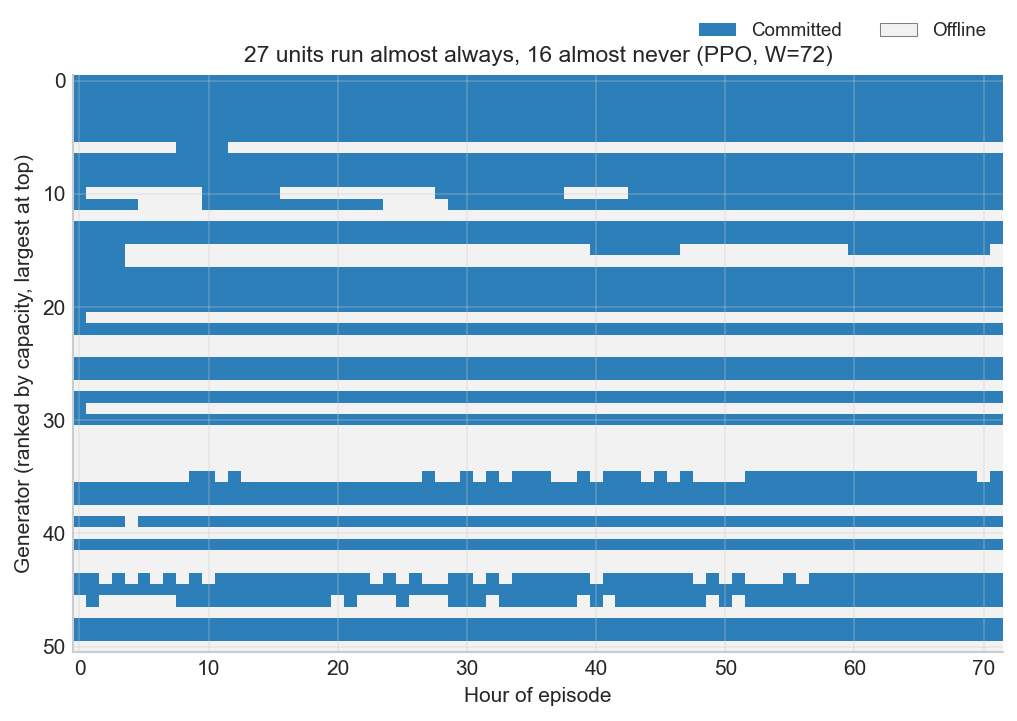

W=72: mean online 30.9, overrides 29


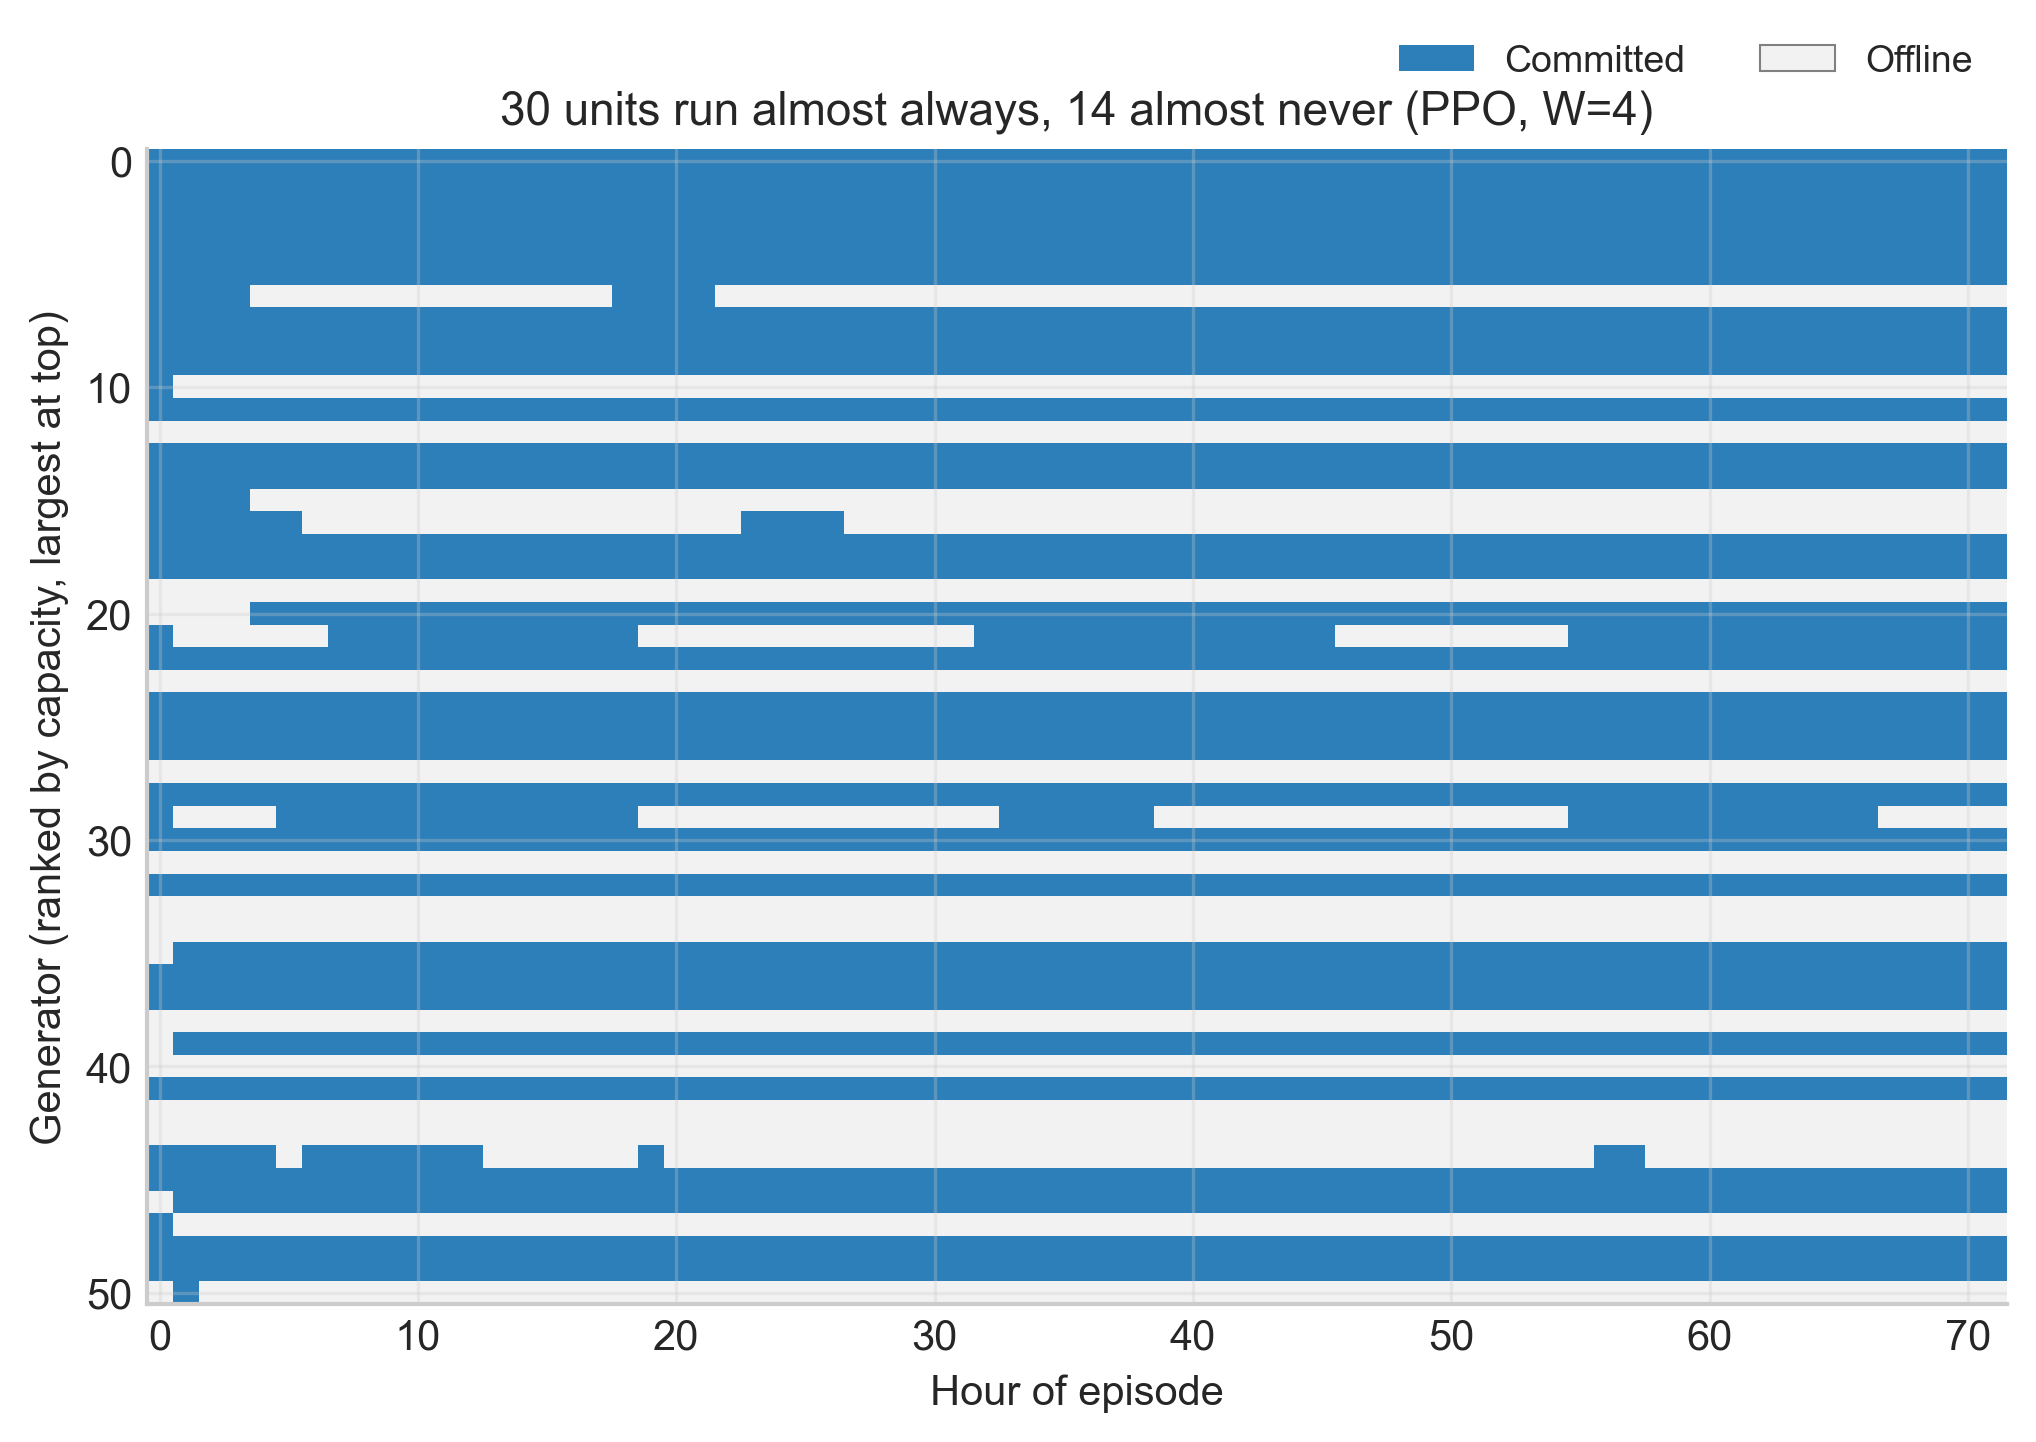

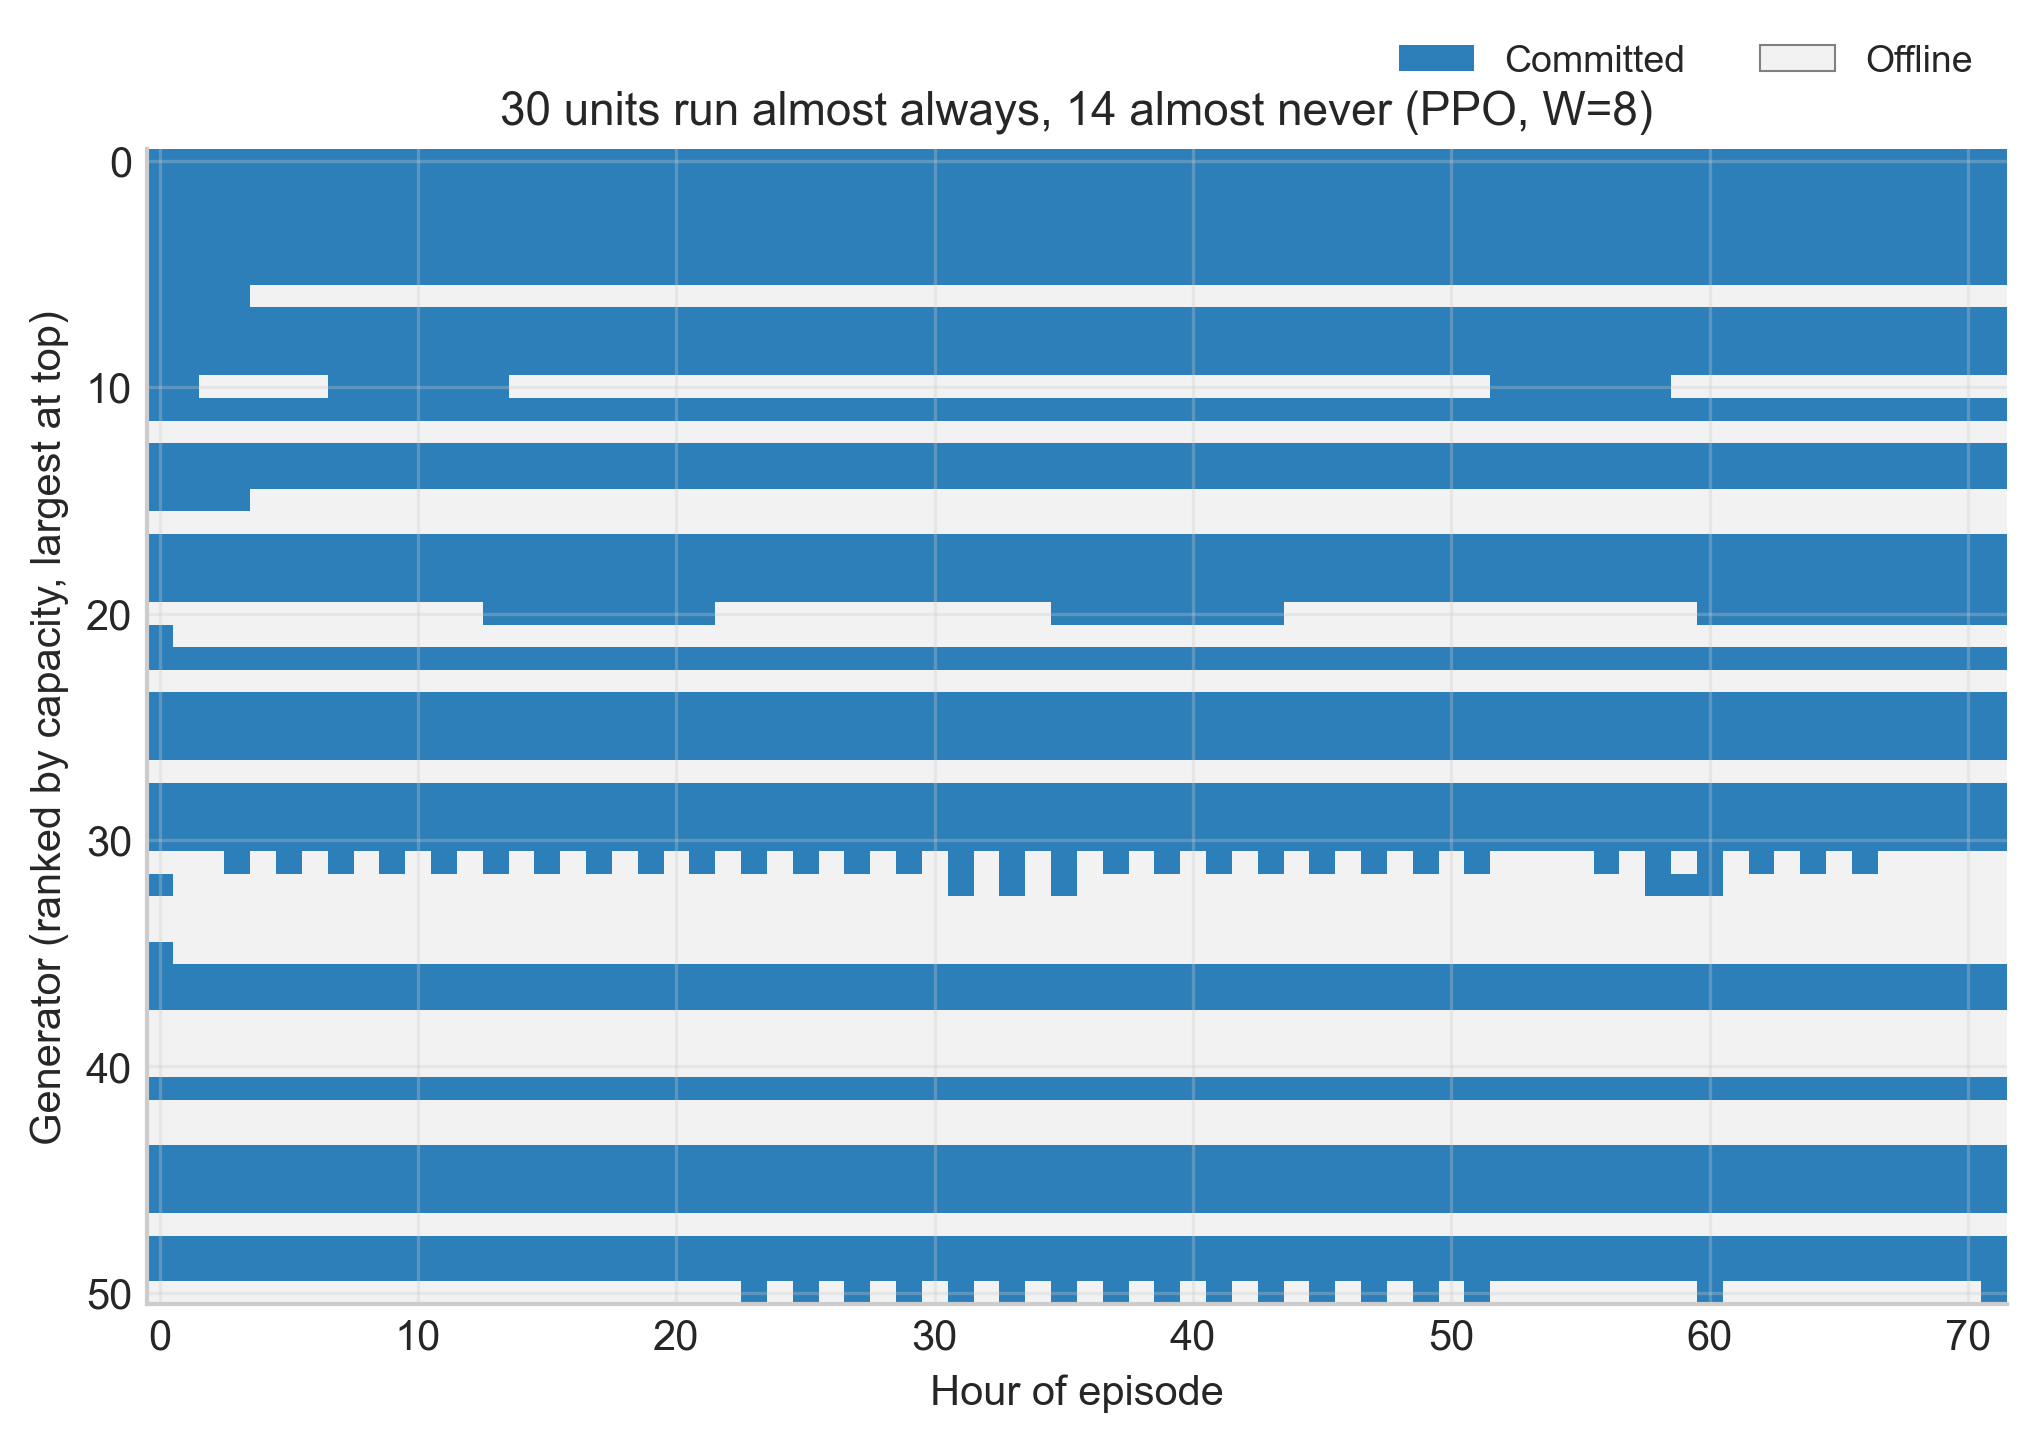

FileNotFoundError: [Errno 2] No such file or directory: 'figures/commitment/a_commitment_W24.png'

In [79]:
from IPython.display import Image, display
from stable_baselines3 import PPO as SB3_PPO

for W in [4, 8, 72]:
    m = SB3_PPO.load(f"ablation_v9/ppo_W{W}")
    e = UCOnlyEnv(test_episodes, spill_penalty=1000, random_reset=False,
                  state_version="v2", obs_window=W)
    pol = lambda o: np.asarray(m.predict(o, deterministic=True)[0]).ravel()
    tr = run_episode_detailed(e, pol, instance_index=0)
    plot_commitment_heatmap(tr, thermal_df,
                            name=f"a_commitment_W{W}",
                            title_extra=f" (PPO, W={W})")
    print(f"W={W}: mean online {tr['df']['n_online'].mean():.1f}, "
          f"overrides {tr['df']['n_overrides'].sum():.0f}")

for W in [4, 8, 24, 72]:
    display(Image(filename=f"figures/commitment/a_commitment_W{W}.png"))

Text(0, 0.5, 'demand')

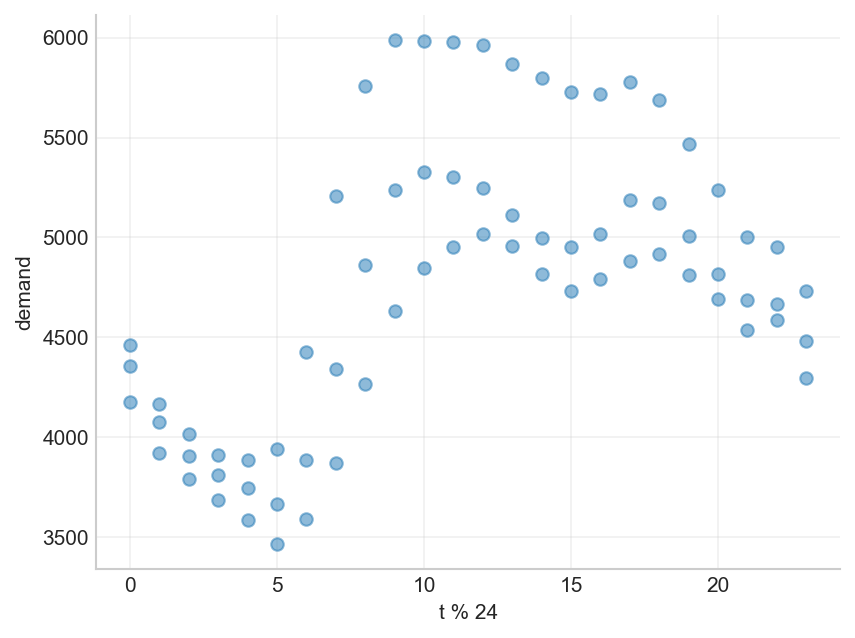

In [67]:
plt.plot(np.arange(72) % 24, train_episodes[0]["demand"], "o", alpha=0.5)
plt.xlabel("t % 24"); plt.ylabel("demand")

c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\stable_baselines3\common\on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


  W= 1 done — corr=0.200 amp=0.75
  W= 4 done — corr=0.345 amp=1.38
  W= 8 done — corr=0.055 amp=0.93
  W=24 done — corr=-0.166 amp=0.73
  W=72 done — corr=0.448 amp=1.43
 W  Responsiveness (corr)  Amplitude (units, sd) Reserve margin  Mean units online  Unserved (MWh/ep)  Spill (MWh/ep) Startup ($/ep)  Total cost ($M/ep)
 1                  0.200                   0.75       17873.3%               34.5                7.8           33642           201k               44.14
 4                  0.345                   1.38       16469.5%               32.9               29.5           29314           196k               39.06
 8                  0.055                   0.93       16570.3%               31.4               67.2           29905           205k               40.21
24                 -0.166                   0.73       17303.2%               32.4               51.7           32184           268k               42.88
72                  0.448                   1.43       16136.3% 

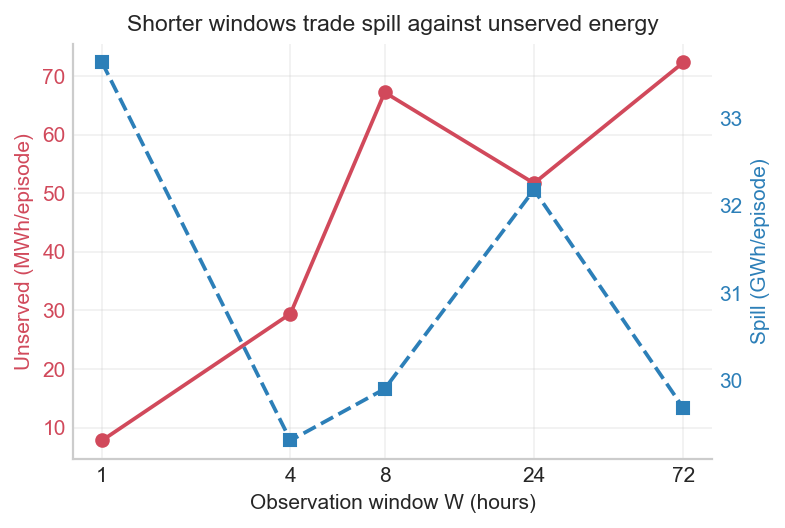

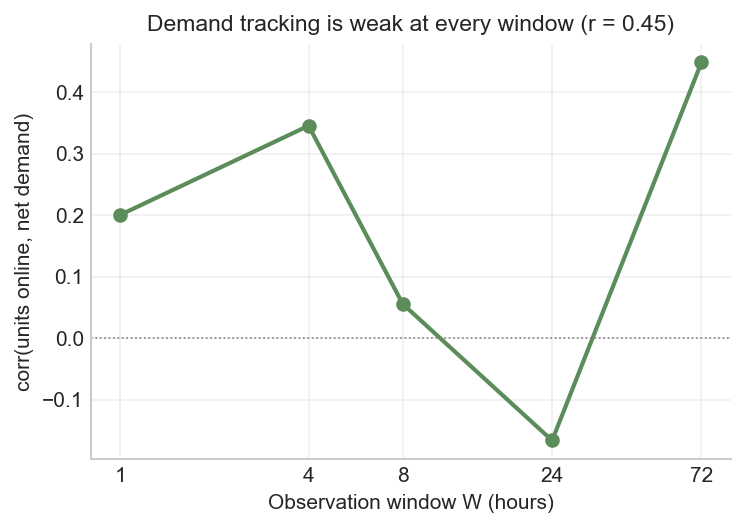

In [91]:
# =============================================================================
# Window ablation — responsiveness, unserved and spill breakdown
#
# The summary CSV only reports mean cost. This adds the metrics that actually
# test the hypothesis: does a longer forecast window make the policy track
# demand more closely, and what does it trade off to do so?
#
# Averages over all 100 test instances.
# =============================================================================

WINDOWS = [1, 4, 8, 24, 72]
MODELDIR = Path("ablation_v9")
FIGDIR = Path("figures/ablation"); FIGDIR.mkdir(parents=True, exist_ok=True)


def window_breakdown(test_eps, windows=WINDOWS, spill_penalty=1000):
    """
    Per window, averaged over every test instance:

      responsiveness  corr(units online, net demand) within an episode.
                      1.0 = commitment tracks demand perfectly.
                      ~0  = commitment ignores demand.
      amplitude       std of units online within an episode. A flat policy
                      has amplitude near zero regardless of how demand moves.
      reserve_margin  (committed Pmin capacity - required) / required.
                      How much slack the agent carries, in relative terms.
      unserved_mwh    energy the fleet could not have covered.
      spill_mwh       committed Pmin above what demand required.
      startup_cost    what the agent paid for switching.
    """
    rows = []
    for W in windows:
        model = SB3_PPO.load(MODELDIR / f"ppo_W{W}")
        e = UCOnlyEnv(test_eps, spill_penalty=spill_penalty, random_reset=False,
                      state_version="v2", obs_window=W)
        pol = lambda o: np.asarray(model.predict(o, deterministic=True)[0]).ravel()

        corr, amp, marg, uns, spl, su, cost, onl = [], [], [], [], [], [], [], []
        for i in range(len(test_eps)):
            tr = collect_uc_trace(e, pol, instance_index=i)
            n_on = tr["n_online"].to_numpy(float)
            nd   = tr["net_demand"].to_numpy(float)

            # responsiveness is undefined if the policy never moves
            if n_on.std() > 1e-9 and nd.std() > 1e-9:
                corr.append(np.corrcoef(n_on, nd)[0, 1])
            amp.append(n_on.std())

            req = np.maximum(nd, 0.0)
            oc  = tr["over_commit"].to_numpy(float)
            marg.append(np.mean(oc / np.maximum(req, 1.0)))

            uns.append(tr["unserved_proxy"].sum())
            spl.append(oc.sum())
            su.append(tr["startup_cost"].sum())
            cost.append(tr["cost"].sum())
            onl.append(n_on.mean())

        rows.append({
            "W": W,
            "responsiveness": np.mean(corr) if corr else np.nan,
            "amplitude_units": np.mean(amp),
            "reserve_margin": np.mean(marg),
            "mean_online": np.mean(onl),
            "unserved_MWh": np.mean(uns),
            "spill_MWh": np.mean(spl),
            "startup_cost_$": np.mean(su),
            "total_cost_$": np.mean(cost),
        })
        print(f"  W={W:2d} done — corr={rows[-1]['responsiveness']:.3f} "
              f"amp={rows[-1]['amplitude_units']:.2f}")

    df = pd.DataFrame(rows)
    df.to_csv(MODELDIR / "window_breakdown.csv", index=False)
    return df


def show_breakdown(df):
    """Formatted for pasting into the email."""
    out = pd.DataFrame({
        "W": df["W"],
        "Responsiveness (corr)": df["responsiveness"].round(3),
        "Amplitude (units, sd)": df["amplitude_units"].round(2),
        "Reserve margin": (df["reserve_margin"] * 100).round(1).astype(str) + "%",
        "Mean units online": df["mean_online"].round(1),
        "Unserved (MWh/ep)": df["unserved_MWh"].round(1),
        "Spill (MWh/ep)": df["spill_MWh"].round(0).astype(int),
        "Startup ($/ep)": (df["startup_cost_$"] / 1000).round(0).astype(int).astype(str) + "k",
        "Total cost ($M/ep)": (df["total_cost_$"] / 1e6).round(2),
    })
    print(out.to_string(index=False))
    return out


def plot_tradeoff(df, name="f_unserved_vs_spill"):
    """The trade-off the single cost number hides."""
    fig, ax1 = plt.subplots(figsize=(5.5, 3.6))
    ax1.plot(df["W"], df["unserved_MWh"], "o-", color="#d1495b", lw=1.8)
    ax1.set_xscale("log"); ax1.set_xticks(df["W"]); ax1.set_xticklabels(df["W"])
    ax1.set_xlabel("Observation window W (hours)")
    ax1.set_ylabel("Unserved (MWh/episode)", color="#d1495b")
    ax1.tick_params(axis="y", labelcolor="#d1495b")

    ax2 = ax1.twinx(); ax2.grid(False)
    ax2.plot(df["W"], df["spill_MWh"] / 1000, "s--", color="#2c7fb8", lw=1.8)
    ax2.set_ylabel("Spill (GWh/episode)", color="#2c7fb8")
    ax2.tick_params(axis="y", labelcolor="#2c7fb8")

    ax1.set_title("Shorter windows trade spill against unserved energy")
    fig.savefig(FIGDIR / f"{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIGDIR / f"{name}.pdf", bbox_inches="tight")
    plt.show()


def plot_responsiveness(df, name="g_responsiveness"):
    fig, ax = plt.subplots(figsize=(5.5, 3.6))
    ax.plot(df["W"], df["responsiveness"], "o-", color="#5b8c5a", lw=2)
    ax.set_xscale("log"); ax.set_xticks(df["W"]); ax.set_xticklabels(df["W"])
    ax.set_xlabel("Observation window W (hours)")
    ax.set_ylabel("corr(units online, net demand)")
    ax.axhline(0, color="grey", lw=0.8, ls=":")
    best = df.loc[df["responsiveness"].idxmax()]
    ax.set_title(f"Demand tracking is weak at every window (r = {best['responsiveness']:.2f})")
    fig.savefig(FIGDIR / f"{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIGDIR / f"{name}.pdf", bbox_inches="tight")
    plt.show()


# =======================================================================
# RUN
# =======================================================================
df_bd = window_breakdown(test_episodes)
tbl   = show_breakdown(df_bd)
plot_tradeoff(df_bd)
plot_responsiveness(df_bd)

In [ ]:
# v1 vs v2 — needs your OLD V8 model loaded as ppo_model_v1
df_legal = compare_legality(
    {"v1 (prev_on only)": (ppo_model_v1, "v1", 72),
     "v2 (constraint clocks)": (ppo_model, "v2", 72)},
    test_episodes)

## Comparison from Old vs New "state"

In [69]:
e1 = UCOnlyEnv(test_episodes, random_reset=False, state_version="v1")
print("env v1 obs_dim:", e1.obs_dim)
print("model v1 expects:", ppo_v1.observation_space.shape)

env v1 obs_dim: 179
model v1 expects: (179,)


In [68]:
from stable_baselines3 import PPO as SB3_PPO

ppo_v1 = SB3_PPO.load("saved_models_v7new/ppo_uc")   # state lama
ppo_v2 = SB3_PPO.load("saved_models_v8/ppo_uc")      # state baru

df_legal = compare_legality(
    {"v1 (prev_on only)":      (ppo_v1, "v1", 72),
     "v2 (constraint clocks)": (ppo_v2, "v2", 72)},
    test_episodes, n_instances=20, spill_penalty=1000)

df_legal.to_csv("ablation_v9/v1_vs_v2.csv", index=False)

c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\stable_baselines3\common\on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


                 state  overrides_per_episode  illegal_rate    mean_cost  mean_online
     v1 (prev_on only)                  110.2      0.030011 4.235367e+07    37.355556
v2 (constraint clocks)                   70.0      0.019063 3.539876e+07    33.352083


In [70]:
e = UCOnlyEnv(test_episodes, spill_penalty=1000, random_reset=False,
              state_version="v2", obs_window=72)
pol = lambda o: np.asarray(ppo_v2.predict(o, deterministic=True)[0]).ravel()

print("run_episode_detailed:", run_episode_detailed(e, pol, 0)["df"]["cost"].sum())
print("collect_uc_trace    :", collect_uc_trace(e, pol, instance_index=0)["cost"].sum())

run_episode_detailed: 43311270.724227995
collect_uc_trace    : 43311270.724227995


## Reward Function : R1 vs R2 vs R3

In [101]:
class UCOnlyEnv:
    def __init__(self, episodes, spill_penalty=1000.0, reward_scale=1e5,
                 random_reset=True, seed=42, lookahead=8):
        validate_compat(episodes)
        self.episodes = list(episodes)
        self.spill_penalty = spill_penalty
        self.reward_scale = reward_scale
        self.random_reset = random_reset
        self.rng = np.random.default_rng(seed)
        self.lookahead = lookahead

        th = episodes[0]["thermal_df"].reset_index(drop=True)
        self.generator_names = th["generator"].tolist()
        self.n_gen = len(th)
        self.horizon = len(episodes[0]["demand"])
        self.pmin = th["pmin"].to_numpy(float)
        self.pmax = th["pmax"].to_numpy(float)
        self.marginal_cost = th["marginal_cost"].to_numpy(float)
        self.startup_cost_arr = th["startup_cost"].to_numpy(float)
        self.min_up = th["min_up"].to_numpy(float)
        self.min_down = th["min_down"].to_numpy(float)
        self.ramp_up = th["ramp_up"].to_numpy(float)
        self.ramp_down = th["ramp_down"].to_numpy(float)
        self.cost_curve_mw = th["cost_curve_mw"].tolist()
        self.cost_curve_usd = th["cost_curve_usd"].tolist()
        self.thermal_cap = float(self.pmax.sum())

        # 1 + 51 + 72 + 51 + 4 = 179
        self.obs_dim = 1 + self.n_gen + self.horizon + self.n_gen + 4
        self.reset(options={"episode_index": 0})

    def reset(self, seed=None, options=None):
        if seed: self.rng = np.random.default_rng(seed)
        options = options or {}
        idx = int(options.get("episode_index",
                  self.rng.integers(len(self.episodes)) if self.random_reset else 0))
        self.ep_idx = idx
        ep = self.episodes[idx]
        self.demand = np.asarray(ep["demand"], float)
        self.wind   = np.asarray(ep["wind"], float)
        self.solar  = np.asarray(ep["solar"], float)
        self.net_demand = self.demand - self.wind - self.solar
        self.balance_penalty = float(ep.get("balance_penalty", 12533.0))

        th = ep["thermal_df"]
        self.current_dispatch = th["init_power"].to_numpy(float).copy()
        self.status_duration  = th["init_status"].to_numpy(float).copy()
        self.prev_on = (self.current_dispatch > 1e-6).astype(int)
        self.t = 0
        return self._obs(), {"instance_id": ep["instance_id"]}

    def _lookahead_stats(self):
        cap = max(self.thermal_cap, 1.0)
        L = self.lookahead
        t_end = min(self.t + L, self.horizon)
        window = self.net_demand[self.t:t_end]
        if len(window) < 2:
            return np.zeros(4, dtype=np.float32)
        return np.array([
            float(window.min()) / cap,
            float(window.max()) / cap,
            float(window.mean()) / cap,
            float(window[-1] - window[0]) / (cap * L),
        ], dtype=np.float32)

    def _obs(self):
        cap = max(self.thermal_cap, 1.0)
        status_norm = np.clip(self.status_duration / 10.0, -1.0, 1.0)
        lookahead = self._lookahead_stats()
        return np.concatenate([
            [self.t / max(self.horizon-1, 1)],   # 1
            self.prev_on.astype(float),           # 51
            self.net_demand / cap,                # 72
            status_norm,                          # 51
            lookahead,                            # 4
        ]).astype(np.float32)                     # = 179

    def _legalise(self, desired):
        on = np.asarray(desired, int).copy()
        cur_on = (self.current_dispatch > 1e-6) | (self.status_duration > 0)
        on[cur_on & (self.status_duration > 0) & (self.status_duration < self.min_up)] = 1
        on[(~cur_on) & (self.status_duration < 0) & (-self.status_duration < self.min_down)] = 0
        on[cur_on & (on == 0) & (self.current_dispatch > self.ramp_down + 1e-6)] = 1
        return on

    def _update_durations(self, on):
        nxt = np.zeros(self.n_gen, float)
        for i in range(self.n_gen):
            if on[i] == 1:
                nxt[i] = max(1.0, self.status_duration[i]+1.0) if self.prev_on[i]==1 else 1.0
            else:
                nxt[i] = min(-1.0, self.status_duration[i]-1.0) if self.prev_on[i]==0 else -1.0
        return nxt

    def step(self, action):
        raw = np.asarray(action, int).ravel()[:self.n_gen]
        on  = self._legalise(raw)

        nd_t     = float(self.net_demand[self.t])
        required = max(0.0, nd_t)

        total_pmin_on = float(self.pmin[on==1].sum())
        total_pmax_on = float(self.pmax[on==1].sum())

        cur_on = (self.current_dispatch > 1e-6) | (self.status_duration > 0)
        startup_cost = float(np.sum(((on==1) & (~cur_on)) * self.startup_cost_arr))
        fuel_proxy = float(np.sum(on * self.pmin * self.marginal_cost))
        unserved = max(0.0, required - total_pmax_on)
        over_commit = max(0.0, total_pmin_on - required)

        spill_cost = self.spill_penalty * over_commit

        if required > 0:
            on_indices = np.where(on == 1)[0]
            sorted_by_pmin = on_indices[np.argsort(-self.pmax[on_indices])]
            cumsum = 0.0
            needed = set()
            for idx in sorted_by_pmin:
                if cumsum < required * 1.15:
                    cumsum += self.pmax[idx]
                    needed.add(idx)
            n_excess = len(on_indices) - len(needed)
            excess_unit_penalty = n_excess * 100.0
        else:
            excess_unit_penalty = float(on.sum()) * 500.0

        lookahead_penalty = 0.0
        L = self.lookahead
        t_end = min(self.t + L, self.horizon)
        future_min_demand = float(self.net_demand[self.t:t_end].min())
        if future_min_demand < required * 0.5 and over_commit > 0:
            lookahead_penalty = over_commit * 500.0

        cost = (fuel_proxy + startup_cost
                + self.balance_penalty * unserved
                + spill_cost
                + excess_unit_penalty
                + lookahead_penalty)
        reward = -cost / self.reward_scale

        dur_next = self._update_durations(on)
        self.current_dispatch = on.astype(float) * self.pmin

        info = {
            "instance_id": self.episodes[self.ep_idx]["instance_id"],
            "hour": self.t, "net_demand": nd_t,
            "on": on.copy(), "raw_action": raw.copy(),
            "n_overrides": int(np.sum(on != raw)),
            "startup_cost": startup_cost, "fuel_proxy": fuel_proxy,
            "cost": cost, "reward": reward,
            "unserved_proxy": unserved, "over_commit": over_commit,
            "n_startups": int(((on==1) & (~cur_on)).sum()),
            "n_online": int(on.sum()),
        }
        self.prev_on = on.copy()
        self.status_duration = dur_next
        self.t += 1
        done = self.t >= self.horizon
        obs  = np.zeros(self.obs_dim, np.float32) if done else self._obs()
        return obs, reward, done, False, info

# ── Verify ──
_test = UCOnlyEnv(train_episodes, spill_penalty=1000, reward_scale=1e5,
                   random_reset=True, seed=42, lookahead=8)
print(f"obs_dim = {_test.obs_dim}")  # MUST be 179
del _test

print("UCOnlyEnv attributes check:")
e = UCOnlyEnv(train_episodes, spill_penalty=1000, reward_scale=1e5,
              random_reset=True, seed=42, lookahead=8)
print(f"  obs_dim: {e.obs_dim}")
print(f"  has startup_cost_arr: {hasattr(e, 'startup_cost_arr')}")
print(f"  has startup_cost: {hasattr(e, 'startup_cost')}")

print("\nUCEnvR3 source:")
import inspect
print(inspect.getsource(UCEnvR3.__init__))

obs_dim = 179
UCOnlyEnv attributes check:
  obs_dim: 179
  has startup_cost_arr: True
  has startup_cost: False

UCEnvR3 source:
    def __init__(self, episodes, benchmark_on_freq=None, **kwargs):
        super().__init__(episodes, **kwargs)

        # Normalise startup costs to [0, 1]
        sc = self.startup_cost_arr.copy()
        sc_norm = (sc - sc.min()) / max(sc.max() - sc.min(), 1e-9)

        # Benchmark rarity: 1 = never used in MILP, 0 = always used
        if benchmark_on_freq is not None:
            rarity = 1.0 - np.clip(benchmark_on_freq / 100.0, 0, 1)
        else:
            rarity = np.zeros(self.n_gen)

        # Combined weight: high = expensive AND rarely used in benchmark
        self.gen_penalty_weight = 0.5 * sc_norm + 0.5 * rarity

        # Scale factor: make the penalty significant relative to total cost
        # Avg episode cost ~$20M over 72h → per-hour ~$280k
        # Top generator pmin*mc ~$500-2000/h → penalty must be comparable
        self.startup_

In [102]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  CELL 1 — Reward Function Variants (R1 / R2 / R3)  →  RQ3                 ║
# ║  Copy this entire cell into your notebook AFTER the main training cells.   ║
# ║  It creates 3 separate UCOnlyEnv subclasses, trains PPO on each,           ║
# ║  then compares training curves + validation O.R.                           ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

# ---------- R1: Baseline (same as your current env — negative cost only) ----------
class UCEnvR1(UCOnlyEnv):
    """R1 — Baseline reward: negative operating cost, fixed penalties."""
    pass  # Identical to your current UCOnlyEnv — serves as the control


# ---------- R2: Curriculum reward — penalty weights shift over training ----------
class UCEnvR2(UCOnlyEnv):
    """
    R2 — Curriculum-based reward (Bengio et al., 2009 applied to reward).
    Early training: heavy unserved penalty → learn feasibility first.
    Later training: gradually increase spill + startup emphasis → learn efficiency.
    """
    def __init__(self, episodes, **kwargs):
        super().__init__(episodes, **kwargs)
        self.curriculum_progress = 0.0  # set externally by training loop [0→1]

    def step(self, action):
        obs, reward, done, trunc, info = super().step(action)

        # Recompute reward with curriculum-scheduled weights
        progress = self.curriculum_progress  # 0.0 = start, 1.0 = end

        # Phase 1 (progress 0→0.5): emphasise feasibility
        # Phase 2 (progress 0.5→1): shift toward cost efficiency
        unserved_weight = 1.0                       # always high
        spill_weight    = 0.2 + 0.8 * progress      # 0.2 → 1.0
        startup_weight  = 0.1 + 0.9 * progress      # 0.1 → 1.0

        nd_t     = float(self.net_demand[self.t - 1])
        required = max(0.0, nd_t)
        on = info["on"]

        total_pmin_on = float(self.pmin[on == 1].sum())
        total_pmax_on = float(self.pmax[on == 1].sum())
        unserved   = max(0.0, required - total_pmax_on)
        over_commit = max(0.0, total_pmin_on - required)

        cost_r2 = (info["fuel_proxy"]
                   + startup_weight  * info["startup_cost"]
                   + unserved_weight * self.balance_penalty * unserved
                   + spill_weight    * self.spill_penalty * over_commit)

        reward = -cost_r2 / self.reward_scale
        info["reward"] = reward
        info["cost"]   = cost_r2
        return obs, reward, done, trunc, info


# ---------- R3: Generator-aware reward — per-unit credit assignment ----------
class UCEnvR3(UCOnlyEnv):
    """
    R3 — Generator-aware penalty with partial credit assignment.
    Each generator's startup gets a penalty_weight based on:
      - normalised startup cost (expensive → higher penalty)
      - benchmark rarity (rarely used in MILP → higher penalty)
    This discourages committing expensive, rarely-needed generators.
    """
    def __init__(self, episodes, benchmark_on_freq=None, **kwargs):
        super().__init__(episodes, **kwargs)

        # Normalise startup costs to [0, 1]
        sc = self.startup_cost_arr.copy()
        sc_norm = (sc - sc.min()) / max(sc.max() - sc.min(), 1e-9)

        # Benchmark rarity: 1 - (% hours ON in benchmark) → 1 = never used
        if benchmark_on_freq is not None:
            rarity = 1.0 - np.clip(benchmark_on_freq / 100.0, 0, 1)
        else:
            rarity = np.zeros(self.n_gen)

        # Combined penalty weight per generator
        self.gen_penalty_weight = 0.5 * sc_norm + 0.5 * rarity  # [0, 1]

    def step(self, action):
        obs, reward, done, trunc, info = super().step(action)

        on = info["on"]
        cur_on = (self.current_dispatch > 1e-6) | (self.status_duration > 0)

        # Additional per-generator startup penalty
        new_starts = ((on == 1) & (~cur_on))
        gen_penalty = float(np.sum(
            new_starts * self.gen_penalty_weight * self.startup_cost_arr * 2.0
        ))

        # Also penalise ON generators with high rarity (shouldn't be ON often)
        on_rarity_penalty = float(np.sum(
            on * self.gen_penalty_weight * 50.0  # mild per-hour penalty
        ))

        cost_r3 = info["cost"] + gen_penalty + on_rarity_penalty
        reward = -cost_r3 / self.reward_scale
        info["reward"] = reward
        info["cost"]   = cost_r3
        info["gen_penalty"] = gen_penalty
        return obs, reward, done, trunc, info

In [103]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  PATCHED R2 & R3 — Stronger reward modifications                          ║
# ║  Replace the UCEnvR2 and UCEnvR3 classes in Cell 1 with these.             ║
# ║  The originals had penalties too small relative to base cost (~$20M),      ║
# ║  so all three variants learned nearly identical policies.                  ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

# ────────────────────────────────────────────────────────────────────
# R2 — STRONGER Curriculum: Phase 1 almost ignores startup/spill,
#       Phase 2 flips to heavily penalise them.
# ────────────────────────────────────────────────────────────────────
class UCEnvR2(UCOnlyEnv):
    """
    R2 — Curriculum reward.
    Phase 1 (progress 0→0.4): unserved penalty 3× base, spill penalty 0.1×, 
           startup weight near-zero → agent learns "just cover demand".
    Phase 2 (progress 0.4→1.0): spill penalty ramps to 2×, startup weight
           ramps to 3× → agent learns "cover demand EFFICIENTLY".
    """
    def __init__(self, episodes, **kwargs):
        super().__init__(episodes, **kwargs)
        self.curriculum_progress = 0.0

    def step(self, action):
        # Run base step to get legal actions + base info
        raw = np.asarray(action, int).ravel()[:self.n_gen]
        on  = self._legalise(raw)

        nd_t     = float(self.net_demand[self.t])
        required = max(0.0, nd_t)

        total_pmin_on = float(self.pmin[on == 1].sum())
        total_pmax_on = float(self.pmax[on == 1].sum())

        cur_on = (self.current_dispatch > 1e-6) | (self.status_duration > 0)
        startup_cost = float(np.sum(((on == 1) & (~cur_on)) * self.startup_cost_arr))
        fuel_proxy   = float(np.sum(on * self.pmin * self.marginal_cost))
        unserved     = max(0.0, required - total_pmax_on)
        over_commit  = max(0.0, total_pmin_on - required)

        p = self.curriculum_progress  # 0.0 → 1.0

        # ── Curriculum-scheduled weights ──
        # Phase 1: focus on feasibility (cover demand at any cost)
        # Phase 2: shift to efficiency (reduce spill & startups)
        if p < 0.4:
            # Early: unserved is catastrophic, spill is cheap, startups ignored
            w_unserved = self.balance_penalty * 3.0
            w_spill    = self.spill_penalty * 0.05
            w_startup  = 0.05
        else:
            # Late: ramp up spill and startup penalties
            t_norm = (p - 0.4) / 0.6  # 0→1 within phase 2
            w_unserved = self.balance_penalty * (3.0 - 2.0 * t_norm)  # 3× → 1×
            w_spill    = self.spill_penalty * (0.05 + 2.95 * t_norm)  # 0.05× → 3×
            w_startup  = 0.05 + 2.95 * t_norm                         # 0.05 → 3.0

        cost = (fuel_proxy
                + w_startup * startup_cost
                + w_unserved * unserved
                + w_spill * over_commit)

        reward = -cost / self.reward_scale

        # ── State transitions (same as base) ──
        dur_next = self._update_durations(on)
        self.current_dispatch = on.astype(float) * self.pmin

        info = {
            "instance_id": self.episodes[self.ep_idx]["instance_id"],
            "hour": self.t, "net_demand": nd_t,
            "on": on.copy(), "raw_action": raw.copy(),
            "n_overrides": int(np.sum(on != raw)),
            "startup_cost": startup_cost, "fuel_proxy": fuel_proxy,
            "cost": cost, "reward": reward,
            "unserved_proxy": unserved, "over_commit": over_commit,
            "n_startups": int(((on == 1) & (~cur_on)).sum()),
            "n_online": int(on.sum()),
        }
        self.prev_on = on.copy()
        self.status_duration = dur_next
        self.t += 1
        done = self.t >= self.horizon
        obs  = np.zeros(self.obs_dim, np.float32) if done else self._obs()
        return obs, reward, done, False, info


# ────────────────────────────────────────────────────────────────────
# R3 — STRONGER Generator-aware: expensive+rare generators get a
#       HEAVY per-hour ON penalty, not just at startup.
# ────────────────────────────────────────────────────────────────────
class UCEnvR3(UCOnlyEnv):
    """
    R3 — Generator-aware penalty with strong credit assignment.
    Each generator gets a penalty_weight = f(startup_cost, benchmark_rarity).
    
    Two components:
    1) Startup penalty: committing an expensive+rare generator costs 3× its 
       actual startup cost in the reward.
    2) Per-hour ON penalty: every hour an expensive+rare generator stays ON,
       it incurs an extra cost proportional to its penalty_weight × pmin × marginal_cost.
       This teaches the agent "don't keep expensive generators running."
    """
    def __init__(self, episodes, benchmark_on_freq=None, **kwargs):
        super().__init__(episodes, **kwargs)

        # Normalise startup costs to [0, 1]
        sc = self.startup_cost_arr.copy()
        sc_norm = (sc - sc.min()) / max(sc.max() - sc.min(), 1e-9)

        # Benchmark rarity: 1 = never used in MILP, 0 = always used
        if benchmark_on_freq is not None:
            rarity = 1.0 - np.clip(benchmark_on_freq / 100.0, 0, 1)
        else:
            rarity = np.zeros(self.n_gen)

        # Combined weight: high = expensive AND rarely used in benchmark
        self.gen_penalty_weight = 0.5 * sc_norm + 0.5 * rarity

        # Scale factor: make the penalty significant relative to total cost
        # Avg episode cost ~$20M over 72h → per-hour ~$280k
        # Top generator pmin*mc ~$500-2000/h → penalty must be comparable
        self.startup_multiplier = 3.0   # 3× actual startup cost as penalty
        self.hourly_multiplier  = 800.0 # $/h per unit of penalty_weight

    def step(self, action):
        raw = np.asarray(action, int).ravel()[:self.n_gen]
        on  = self._legalise(raw)

        nd_t     = float(self.net_demand[self.t])
        required = max(0.0, nd_t)

        total_pmin_on = float(self.pmin[on == 1].sum())
        total_pmax_on = float(self.pmax[on == 1].sum())

        cur_on = (self.current_dispatch > 1e-6) | (self.status_duration > 0)
        startup_cost = float(np.sum(((on == 1) & (~cur_on)) * self.startup_cost_arr))
        fuel_proxy   = float(np.sum(on * self.pmin * self.marginal_cost))
        unserved     = max(0.0, required - total_pmax_on)
        over_commit  = max(0.0, total_pmin_on - required)

        # ── R3-specific penalties ──
        new_starts = ((on == 1) & (~cur_on))

        # 1) Weighted startup penalty: expensive+rare generators pay extra
        weighted_startup = float(np.sum(
            new_starts * self.gen_penalty_weight * self.startup_cost_arr
            * self.startup_multiplier
        ))

        # 2) Per-hour ON penalty: every hour an expensive+rare unit is ON
        hourly_gen_penalty = float(np.sum(
            on * self.gen_penalty_weight * self.hourly_multiplier
        ))

        cost = (fuel_proxy
                + startup_cost
                + self.balance_penalty * unserved
                + self.spill_penalty * over_commit
                + weighted_startup
                + hourly_gen_penalty)

        reward = -cost / self.reward_scale

        dur_next = self._update_durations(on)
        self.current_dispatch = on.astype(float) * self.pmin

        info = {
            "instance_id": self.episodes[self.ep_idx]["instance_id"],
            "hour": self.t, "net_demand": nd_t,
            "on": on.copy(), "raw_action": raw.copy(),
            "n_overrides": int(np.sum(on != raw)),
            "startup_cost": startup_cost, "fuel_proxy": fuel_proxy,
            "cost": cost, "reward": reward,
            "unserved_proxy": unserved, "over_commit": over_commit,
            "n_startups": int(((on == 1) & (~cur_on)).sum()),
            "n_online": int(on.sum()),
            "weighted_startup": weighted_startup,
            "hourly_gen_penalty": hourly_gen_penalty,
        }
        self.prev_on = on.copy()
        self.status_duration = dur_next
        self.t += 1
        done = self.t >= self.horizon
        obs  = np.zeros(self.obs_dim, np.float32) if done else self._obs()
        return obs, reward, done, False, info

In [104]:
# ──────────────────────────────────────────────────────────────────────
# Train PPO on R1, R2, R3 and compare
# ──────────────────────────────────────────────────────────────────────

# Step 1: Extract benchmark ON frequency for R3
def extract_benchmark_on_freq(episodes, generator_names, n_instances=None):
    """Compute per-generator ON% from benchmark OutputData.json."""
    n_gen = len(generator_names)
    total_on = np.zeros(n_gen)
    total_hrs = 0
    n = min(n_instances, len(episodes)) if n_instances else len(episodes)
    for ep in episodes[:n]:
        oj = ep.get("output_json")
        if not oj:
            continue
        bo = pd.DataFrame(oj.get("Is on", {}))
        gc = [c for c in bo.columns if c.lower() != "hour"]
        if not gc:
            continue
        bon = bo[gc].to_numpy(float)
        gen_to_idx = {g: i for i, g in enumerate(generator_names)}
        for j, col in enumerate(gc):
            if col in gen_to_idx:
                total_on[gen_to_idx[col]] += bon[:, j].sum()
        total_hrs += len(bon)
    return (total_on / max(total_hrs, 1)) * 100  # % hours ON

bench_on_freq = extract_benchmark_on_freq(
    train_episodes, env.generator_names, n_instances=100
)

# Step 2: Create environments for R1, R2, R3
env_r1 = UCOnlyEnv(train_episodes, spill_penalty=1000, reward_scale=1e5,
                    random_reset=True, seed=42, lookahead=8)
env_r2 = UCEnvR2(train_episodes, spill_penalty=1000, reward_scale=1e5,
                  random_reset=True, seed=42, lookahead=8)
env_r3 = UCEnvR3(train_episodes, spill_penalty=1000, reward_scale=1e5,
                  random_reset=True, seed=42, lookahead=8)

print(f"R1 obs_dim: {env_r1.obs_dim}")  # harus 179
print(f"R2 obs_dim: {env_r2.obs_dim}")  # harus 179
print(f"R3 obs_dim: {env_r3.obs_dim}")  # harus 179

R1 obs_dim: 179
R2 obs_dim: 179
R3 obs_dim: 179


In [105]:
# Step 3: Curriculum callback for R2
class CurriculumCallback(BaseCallback):
    """Updates curriculum_progress on the underlying env during PPO training."""
    def __init__(self, total_timesteps):
        super().__init__()
        self.total_ts = total_timesteps
    def _on_step(self):
        progress = min(1.0, self.num_timesteps / self.total_ts)
        # Access the underlying env through VecEnv
        base_env = self.training_env.envs[0].env  # Monitor → UCGymWrapper
        if hasattr(base_env, 'base') and hasattr(base_env.base, 'curriculum_progress'):
            base_env.base.curriculum_progress = progress
        return True

In [106]:
# Step 4: Train PPO on each reward variant
N_EPOCHS_REWARD = 3  # reduce if time-constrained
TOTAL_TS_R = 300 * env.horizon * N_EPOCHS_REWARD

reward_results = {}

for r_name, r_env_cls, r_env_obj in [
    ("R1", UCOnlyEnv, env_r1),
    ("R2", UCEnvR2,   env_r2),
    ("R3", UCEnvR3,   env_r3),
]:
    print(f"\n{'='*60}")
    print(f"  Training PPO with reward variant: {r_name}")
    print(f"{'='*60}")

    # Wrap for SB3
    class _Wrapper(gym.Env):
        metadata = {"render_modes": []}
        def __init__(self, base_env):
            super().__init__()
            self.base = base_env
            self.observation_space = spaces.Box(-np.inf, np.inf,
                                                 shape=(base_env.obs_dim,), dtype=np.float32)
            self.action_space = spaces.MultiBinary(base_env.n_gen)
        def reset(self, *, seed=None, options=None):
            return self.base.reset(options=options)
        def step(self, action):
            return self.base.step(action)

    cb_stats = StatsCB()
    callbacks = [cb_stats]
    if r_name == "R2":
        callbacks.append(CurriculumCallback(TOTAL_TS_R))

    vec_env = DummyVecEnv([lambda env_=r_env_obj: Monitor(_Wrapper(env_))])
    model = SB3_PPO("MlpPolicy", vec_env, verbose=0,
                     n_steps=256, batch_size=64, gamma=0.95,
                     gae_lambda=0.95, learning_rate=3e-4, ent_coef=0.01,
                     clip_range=0.2, n_epochs=10, device=str(DEVICE))
    t0 = time.time()
    model.learn(total_timesteps=TOTAL_TS_R, callback=callbacks)
    elapsed = time.time() - t0
    print(f"  {r_name} done in {elapsed:.0f}s | {len(cb_stats.ep_r)} episodes")

    # Store results
    def _make_policy(m=model):
        def pol(obs):
            a, _ = m.predict(obs, deterministic=True)
            return np.asarray(a).ravel()
        return pol

    reward_results[r_name] = {
        "rewards":  cb_stats.ep_r,
        "costs":    cb_stats.ep_c,
        "startups": cb_stats.ep_su,
        "policy":   _make_policy(),
        "model":    model,
    }


  Training PPO with reward variant: R1


c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\stable_baselines3\common\on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


  [   33s]  ep 0100 | rew=-5733.44 | startup=$1,801,555
  [   66s]  ep 0200 | rew=-413.50 | startup=$1,886,295
  [   98s]  ep 0300 | rew=-324.32 | startup=$1,800,461
  [  130s]  ep 0400 | rew=-645.11 | startup=$1,789,177
  [  162s]  ep 0500 | rew=-1808.00 | startup=$1,813,031
  [  195s]  ep 0600 | rew=-444.94 | startup=$1,750,764
  [  229s]  ep 0700 | rew=-605.58 | startup=$1,855,773
  [  261s]  ep 0800 | rew=-762.52 | startup=$1,800,867
  [  295s]  ep 0900 | rew=-95.08 | startup=$1,697,371
  R1 done in 296s | 903 episodes

  Training PPO with reward variant: R2
  [   34s]  ep 0100 | rew=-12233.41 | startup=$1,833,276
  [   67s]  ep 0200 | rew=-879.46 | startup=$1,797,175
  [  100s]  ep 0300 | rew=-2119.03 | startup=$1,898,733
  [  132s]  ep 0400 | rew=-2265.07 | startup=$1,853,257
  [  164s]  ep 0500 | rew=-2257.02 | startup=$1,774,299
  [  195s]  ep 0600 | rew=-1302.86 | startup=$1,863,286
  [  226s]  ep 0700 | rew=-1126.34 | startup=$1,787,552
  [  258s]  ep 0800 | rew=-1356.75 | st

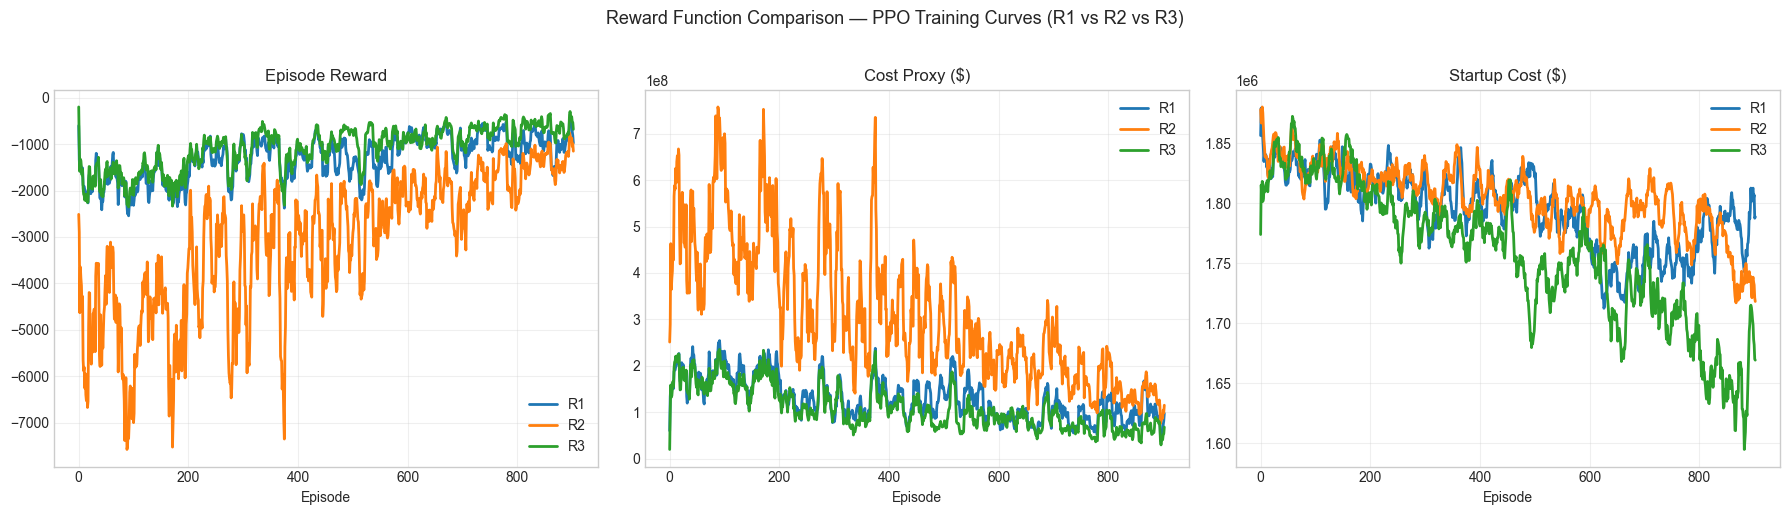

In [107]:
# Step 5: Plot R1/R2/R3 training curves side-by-side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Reward Function Comparison — PPO Training Curves (R1 vs R2 vs R3)",
             fontsize=13, y=1.02)
colors = {"R1": "tab:blue", "R2": "tab:orange", "R3": "tab:green"}
metrics = [
    ("rewards",  "Episode Reward"),
    ("costs",    "Cost Proxy ($)"),
    ("startups", "Startup Cost ($)"),
]
for ax, (key, title) in zip(axes, metrics):
    for r_name, res in reward_results.items():
        data = res[key]
        ax.plot(pd.Series(data).rolling(10, min_periods=1).mean(),
                label=r_name, color=colors[r_name], lw=2)
    ax.set_title(title)
    ax.set_xlabel("Episode")
    ax.legend()
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_19468\3857715703.py:105: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
C:\Users\HP\AppData\Local\Temp\ipykernel_19468\3857715703.py:105: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans Mono.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans Mono.
  fig.canvas.print_figure(bytes_io, **kw)


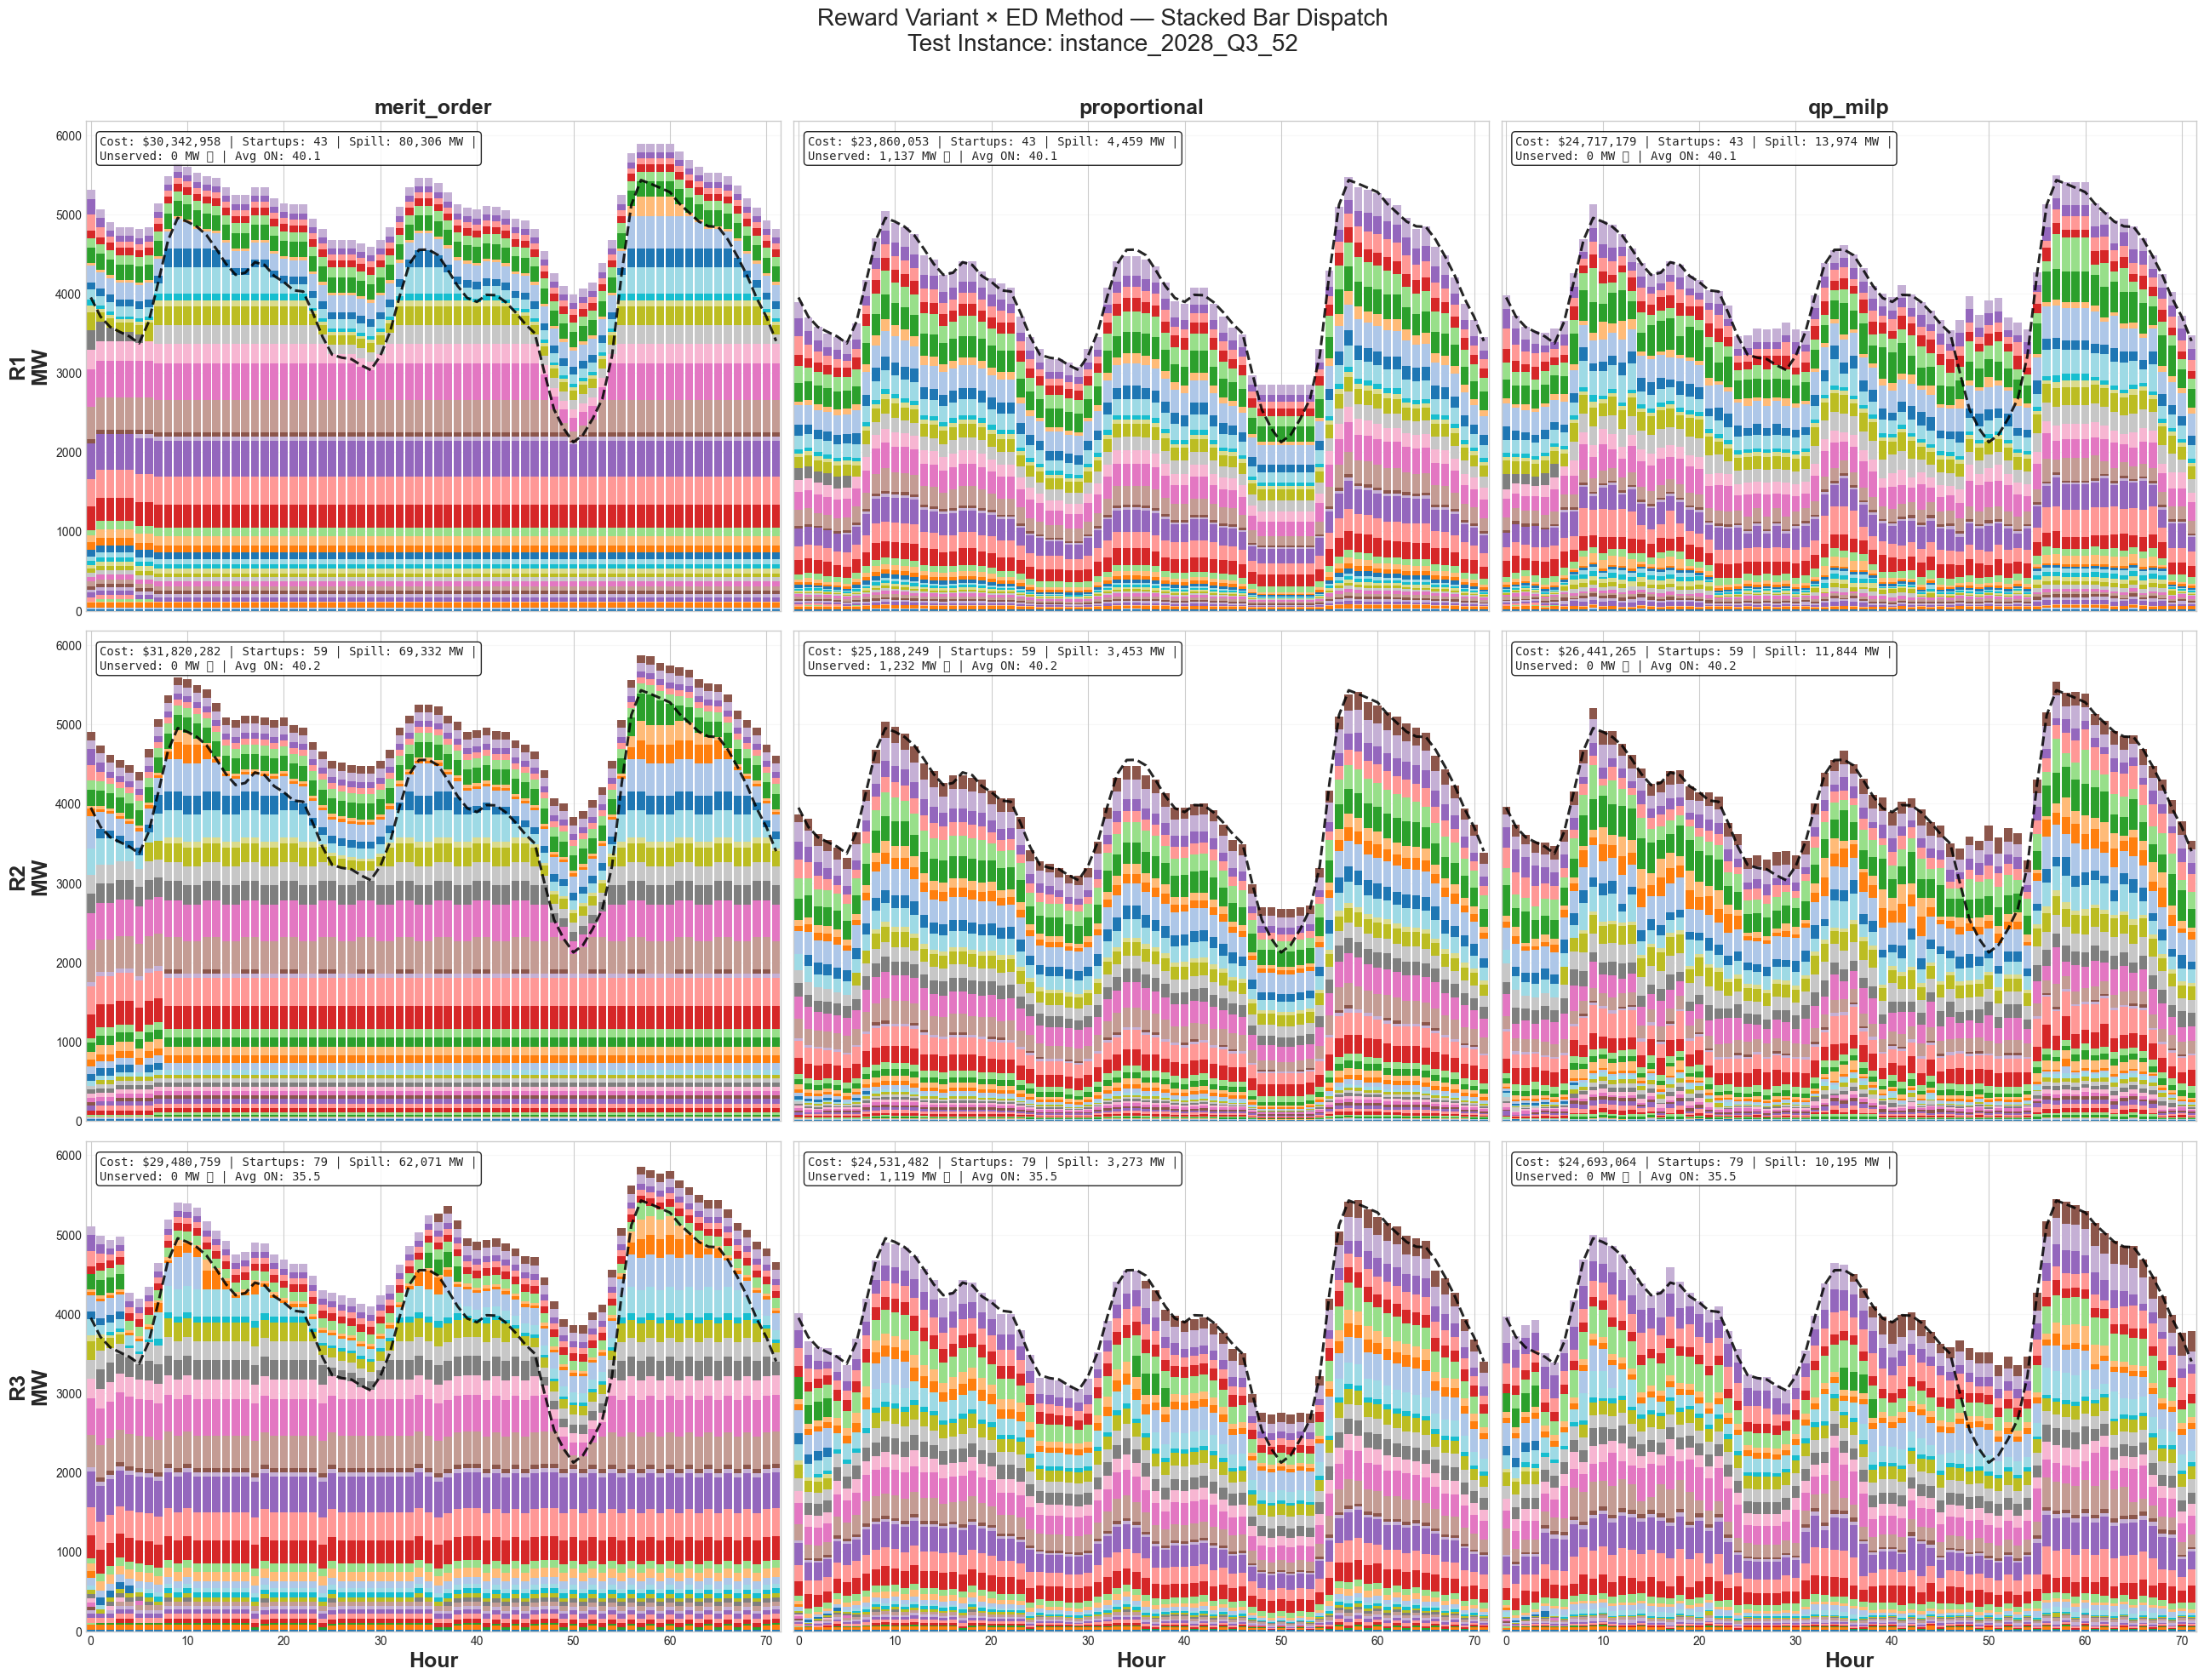

In [114]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  3×3 Stacked BAR Dispatch — Reward Variants (R1/R2/R3) × ED Methods       ║
# ║  Run AFTER Cell 1 (reward variant training) so reward_results exists       ║
# ║  Run AFTER the stacked area version so traces_rv already exists,           ║
# ║  OR set RECOLLECT = True to re-collect traces.                             ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

RECOLLECT = True  # set True if traces_rv doesn't exist yet

if RECOLLECT:
    INSTANCE_IDX_RV = 45
    USE_TEST = True
    episodes_rv = test_episodes if USE_TEST else train_episodes

    RV_POLICIES = {rname: res["policy"] for rname, res in reward_results.items()}
    traces_rv = {}
    for rv_name, rv_pol in RV_POLICIES.items():
        for ed_name, ed_fn in ED_METHODS.items():
            traces_rv[(rv_name, ed_name)] = apply_ed_to_uc(
                env, rv_pol, ed_fn, episodes_rv,
                instance_index=INSTANCE_IDX_RV, levels=ED_LEVELS,
            )

# ── Determine labels ──
rv_names = sorted(set(k[0] for k in traces_rv.keys()), key=lambda x: x)
ed_names = sorted(set(k[1] for k in traces_rv.keys()),
                  key=lambda x: ["merit_order","proportional","qp_milp"].index(x)
                  if x in ["merit_order","proportional","qp_milp"] else 99)

first_key = list(traces_rv.keys())[0]
instance_id_rv = traces_rv[first_key]["instance_id"].iloc[0]
set_label = "Test" if USE_TEST else "Train"

# ── Color palette: consistent per generator ──
cmap = plt.cm.tab20
colors = [cmap(i % 20 / 20) for i in range(env.n_gen)]

# ── 3×3 Stacked Bar Grid ──
fig, axes = plt.subplots(len(rv_names), len(ed_names),
                          figsize=(26, 6.5 * len(rv_names)),
                          sharex=True, sharey=True)
if len(rv_names) == 1:
    axes = axes[np.newaxis, :]

fig.suptitle(
    f"Reward Variant × ED Method — Stacked Bar Dispatch\n"
    f"{set_label} Instance: {instance_id_rv}",
    fontsize=20, y=1.01,
)

bar_width = 0.85  # slightly less than 1 so bars don't merge completely

for row, rv_name in enumerate(rv_names):
    for col, ed_name in enumerate(ed_names):
        ax = axes[row, col]
        tr = traces_rv[(rv_name, ed_name)]

        hours = tr["hour"].values
        dm    = np.vstack(tr["dispatch"].values)       # (72, n_gen)
        nd    = tr["net_demand"].values

        # Stacked bars — bottom-up per generator
        bottom = np.zeros(len(hours))
        for g in range(env.n_gen):
            vals = dm[:, g]
            if vals.sum() > 0:
                ax.bar(hours, vals, bottom=bottom, width=bar_width,
                       color=colors[g], edgecolor="none", linewidth=0)
                bottom += vals

        # Net demand line on top
        ax.plot(hours, np.maximum(nd, 0), color="black", lw=2.2,
                linestyle="--", alpha=0.85, label="Net Demand", zorder=5)

        # Metrics box
        cost     = tr["fuel_cost"].sum() + tr["startup_cost"].sum()
        spill    = tr["spill"].sum()
        unserved = tr["unserved"].sum()
        n_su     = int(tr["n_startups"].sum())
        on_avg   = np.vstack(tr["on"].values).sum(axis=1).mean()
        feas     = "✅" if unserved < 1.0 else "❌"

        ax.text(0.02, 0.97,
                f"Cost: ${cost:,.0f} | Startups: {n_su} | Spill: {spill:,.0f} MW |\n"
                f"Unserved: {unserved:,.0f} MW {feas} | Avg ON: {on_avg:.1f}",
                # f"Cost: ${cost:,.0f}\n"
                # f"Startups: {n_su}\n"
                # f"Spill: {spill:,.0f} MW\n"
                # f"Unserved: {unserved:,.0f} MW {feas}\n"
                # f"Avg ON: {on_avg:.1f}",
                transform=ax.transAxes, fontsize=10, va="top",
                bbox=dict(boxstyle="round", facecolor="white", alpha=0.85),
                family="monospace", zorder=6)

        # Axis labels
        if row == 0:
            ax.set_title(ed_name, fontsize=18, fontweight="bold")
        if col == 0:
            ax.set_ylabel(f"{rv_name}\nMW", fontsize=18, fontweight="bold")
        if row == len(rv_names) - 1:
            ax.set_xlabel("Hour", fontsize=18, fontweight="bold")
        ax.grid(True, alpha=0.15, axis="y")
        ax.set_xlim(-0.5, 71.5)

plt.tight_layout()
plt.show()

In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  3×3 Stacked BAR Dispatch — Reward Variants (R1/R2/R3) × ED Methods       ║
# ║  Run AFTER Cell 1 (reward variant training) so reward_results exists       ║
# ║  Run AFTER the stacked area version so traces_rv already exists,           ║
# ║  OR set RECOLLECT = True to re-collect traces.                             ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

RECOLLECT = True  # set True if traces_rv doesn't exist yet

if RECOLLECT:
    INSTANCE_IDX_RV = 15
    USE_TEST = True
    episodes_rv = test_episodes if USE_TEST else train_episodes

    RV_POLICIES = {rname: res["policy"] for rname, res in reward_results.items()}
    traces_rv = {}
    for rv_name, rv_pol in RV_POLICIES.items():
        for ed_name, ed_fn in ED_METHODS.items():
            traces_rv[(rv_name, ed_name)] = apply_ed_to_uc(
                env, rv_pol, ed_fn, episodes_rv,
                instance_index=INSTANCE_IDX_RV, levels=ED_LEVELS,
            )

# ── Determine labels ──
rv_names = sorted(set(k[0] for k in traces_rv.keys()), key=lambda x: x)
ed_names = sorted(set(k[1] for k in traces_rv.keys()),
                  key=lambda x: ["merit_order","proportional","qp_milp"].index(x)
                  if x in ["merit_order","proportional","qp_milp"] else 99)

first_key = list(traces_rv.keys())[0]
instance_id_rv = traces_rv[first_key]["instance_id"].iloc[0]
set_label = "Test" if USE_TEST else "Train"

# ── Color palette: consistent per generator ──
cmap = plt.cm.tab20
colors = [cmap(i % 20 / 20) for i in range(env.n_gen)]

# ── 3×3 Stacked Bar Grid ──
fig, axes = plt.subplots(len(rv_names), len(ed_names),
                          figsize=(26, 6.5 * len(rv_names)),
                          sharex=True, sharey=True)
if len(rv_names) == 1:
    axes = axes[np.newaxis, :]

fig.suptitle(
    f"Reward Variant × ED Method — Stacked Bar Dispatch\n"
    f"{set_label} Instance: {instance_id_rv}",
    fontsize=15, y=1.01,
)

bar_width = 0.85  # slightly less than 1 so bars don't merge completely

for row, rv_name in enumerate(rv_names):
    for col, ed_name in enumerate(ed_names):
        ax = axes[row, col]
        tr = traces_rv[(rv_name, ed_name)]

        hours = tr["hour"].values
        dm    = np.vstack(tr["dispatch"].values)       # (72, n_gen)
        nd    = tr["net_demand"].values

        # Stacked bars — bottom-up per generator
        bottom = np.zeros(len(hours))
        for g in range(env.n_gen):
            vals = dm[:, g]
            if vals.sum() > 0:
                ax.bar(hours, vals, bottom=bottom, width=bar_width,
                       color=colors[g], edgecolor="none", linewidth=0)
                bottom += vals

        # Net demand line on top
        ax.plot(hours, np.maximum(nd, 0), color="black", lw=2.2,
                linestyle="--", alpha=0.85, label="Net Demand", zorder=5)

        # Metrics box
        cost     = tr["fuel_cost"].sum() + tr["startup_cost"].sum()
        spill    = tr["spill"].sum()
        unserved = tr["unserved"].sum()
        n_su     = int(tr["n_startups"].sum())
        on_avg   = np.vstack(tr["on"].values).sum(axis=1).mean()
        feas     = "✅" if unserved < 1.0 else "❌"

        ax.text(0.02, 0.97,
                f"Cost: ${cost:,.0f}\n"
                f"Startups: {n_su}\n"
                f"Spill: {spill:,.0f} MW\n"
                f"Unserved: {unserved:,.0f} MW {feas}\n"
                f"Avg ON: {on_avg:.1f}",
                transform=ax.transAxes, fontsize=8, va="top",
                bbox=dict(boxstyle="round", facecolor="white", alpha=0.85),
                family="monospace", zorder=6)

        # Axis labels
        if row == 0:
            ax.set_title(ed_name, fontsize=12, fontweight="bold")
        if col == 0:
            ax.set_ylabel(f"{rv_name}\nMW", fontsize=11, fontweight="bold")
        if row == len(rv_names) - 1:
            ax.set_xlabel("Hour", fontsize=10)
        ax.grid(True, alpha=0.15, axis="y")
        ax.set_xlim(-0.5, 71.5)

plt.tight_layout()
plt.show()

In [ ]:
# Step 6: Validation O.R. per reward variant
print(f"\n{'='*60}")
print("  Validation O.R. — R1 vs R2 vs R3 (PPO + best ED: proportional)")
print(f"{'='*60}")

val_env = UCOnlyEnv(valid_episodes, spill_penalty=8000, reward_scale=1e5,
                     random_reset=False, seed=99, lookahead=8)
for r_name, res in reward_results.items():
    ors = []
    for vi in range(min(25, len(valid_episodes))):
        ep = valid_episodes[vi]
        tr = apply_ed_to_uc(val_env, res["policy"], dispatch_proportional,
                             valid_episodes, vi)
        rl_cost = tr["fuel_cost"].sum() + tr["startup_cost"].sum()

        # Benchmark cost
        oj = ep.get("output_json")
        bench_cost = 0.0
        gen_to_idx = {g: i for i, g in enumerate(env.generator_names)}
        if oj:
            bt = pd.DataFrame(oj.get("Thermal production (MW)", {}))
            bo = pd.DataFrame(oj.get("Is on", {}))
            gc = [c for c in bt.columns if c.lower() != "hour"]
            if gc:
                bdisp = bt[gc].to_numpy(float)
                bon   = bo[gc].to_numpy(float)
                for t in range(len(bdisp)):
                    for j, col in enumerate(gc):
                        if col in gen_to_idx:
                            idx = gen_to_idx[col]
                            mw = bdisp[t, j]
                            if mw > 1e-9:
                                mw_c = np.asarray(env.cost_curve_mw[idx], float)
                                c_c  = np.asarray(env.cost_curve_usd[idx], float)
                                bench_cost += float(np.interp(mw, mw_c, c_c))
                            if t > 0 and bon[t, j] > 0.5 and bon[t-1, j] < 0.5:
                                bench_cost += env.startup_cost_arr[idx]
        if bench_cost > 1:
            ors.append(rl_cost / bench_cost)

    q = np.percentile(ors, [25, 50, 75]) if ors else [np.nan]*3
    feas_count = sum(1 for vi in range(min(25, len(valid_episodes)))
                     for _ in [apply_ed_to_uc(val_env, res["policy"],
                               dispatch_qp_milp, valid_episodes, vi)]
                     if _["unserved"].sum() < 1.0)
    print(f"  {r_name}: O.R.(p25)={q[0]:.3f} | O.R.(p50)={q[1]:.3f} | "
          f"O.R.(p75)={q[2]:.3f}")

In [ ]:
# Step 6: Validation — R1 vs R2 vs R3 (PPO + proportional)
print(f"\n{'='*80}")
print("  Validation O.R. — R1 vs R2 vs R3 (PPO + proportional, 25 instances)")
print(f"{'='*80}")

val_env = UCOnlyEnv(valid_episodes, spill_penalty=8000, reward_scale=1e5,
                     random_reset=False, seed=99, lookahead=8)

# Define expensive generators (top 10 by startup cost)
sorted_by_startup = np.argsort(-env.startup_cost_arr)
expensive_gens = set(sorted_by_startup[:10])

gen_to_idx = {g: i for i, g in enumerate(env.generator_names)}

reward_comparison = []

for r_name, res in reward_results.items():
    ors, feas_list, spill_list, startup_list = [], [], [], []
    online_list, expensive_on_list = [], []

    for vi in range(min(25, len(valid_episodes))):
        ep = valid_episodes[vi]
        tr = apply_ed_to_uc(val_env, res["policy"], dispatch_proportional,
                             valid_episodes, vi)

        rl_cost = tr["fuel_cost"].sum() + tr["startup_cost"].sum()
        total_demand = tr["required_mw"].sum()

        # Benchmark cost
        oj = ep.get("output_json")
        bench_cost = 0.0
        if oj:
            bt = pd.DataFrame(oj.get("Thermal production (MW)", {}))
            bo = pd.DataFrame(oj.get("Is on", {}))
            gc = [c for c in bt.columns if c.lower() != "hour"]
            if gc:
                bdisp = bt[gc].to_numpy(float)
                bon   = bo[gc].to_numpy(float)
                for t in range(len(bdisp)):
                    for j, col in enumerate(gc):
                        if col in gen_to_idx:
                            idx = gen_to_idx[col]
                            mw = bdisp[t, j]
                            if mw > 1e-9:
                                mw_c = np.asarray(env.cost_curve_mw[idx], float)
                                c_c  = np.asarray(env.cost_curve_usd[idx], float)
                                bench_cost += float(np.interp(mw, mw_c, c_c))
                            if t > 0 and bon[t, j] > 0.5 and bon[t-1, j] < 0.5:
                                bench_cost += env.startup_cost_arr[idx]

        if bench_cost > 1:
            ors.append(rl_cost / bench_cost)

        # Feasibility
        feas_pct = max(0, (1 - tr["unserved"].sum() / max(total_demand, 1e-6))) * 100
        feas_list.append(feas_pct)

        # Spill
        spill_list.append(tr["spill"].sum())

        # Startup cost
        startup_list.append(tr["startup_cost"].sum())

        # Mean online
        online_list.append(tr["n_online"].mean())

        # Expensive generator ON frequency
        on_mat = np.vstack(tr["on"].values)
        exp_on_pct = np.mean([on_mat[:, i].mean() * 100 for i in expensive_gens])
        expensive_on_list.append(exp_on_pct)

    q = np.percentile(ors, [25, 50, 75]) if ors else [np.nan]*3

    reward_comparison.append({
        "Reward":             r_name,
        "Median OR":          round(q[1], 3),
        "Feasibility (%)":    round(np.mean(feas_list), 2),
        "Startup Cost ($)":   round(np.mean(startup_list), 0),
        "Spill (MW)":         round(np.mean(spill_list), 0),
        "Mean Online":        round(np.mean(online_list), 1),
        "Expensive-unit ON%": round(np.mean(expensive_on_list), 1),
        "Interpretation":     {"R1": "Baseline",
                               "R2": "Curriculum effect",
                               "R3": "Improved credit assignment"}.get(r_name, ""),
    })

    print(f"  {r_name}: O.R.(p25)={q[0]:.3f} | O.R.(p50)={q[1]:.3f} | "
          f"O.R.(p75)={q[2]:.3f} | Feas={np.mean(feas_list):.2f}% | "
          f"Spill={np.mean(spill_list):,.0f}MW | "
          f"Startups=${np.mean(startup_list):,.0f} | "
          f"Online={np.mean(online_list):.1f} | "
          f"Expensive ON={np.mean(expensive_on_list):.1f}%")

# ── Table display ──
reward_comp_df = pd.DataFrame(reward_comparison)
print(f"\n")
display(reward_comp_df.set_index("Reward"))

# ── Bar chart comparison ──
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Reward Function Comparison — R1 vs R2 vs R3 (PPO + proportional, 25 val instances)",
             fontsize=13)

metrics_plot = [
    ("Median OR", "Median O.R. (lower=better)", "tab:blue", True),
    ("Feasibility (%)", "Feasibility (%)", "tab:green", False),
    ("Startup Cost ($)", "Avg Startup Cost ($)", "tab:red", True),
    ("Spill (MW)", "Avg Spill (MW)", "tab:orange", True),
    ("Mean Online", "Avg Generators Online", "tab:purple", False),
    ("Expensive-unit ON%", "Expensive Generator ON%", "tab:brown", True),
]

r_names = reward_comp_df["Reward"].values if "Reward" in reward_comp_df.columns else reward_comp_df.index.values
# r_colors = ["tab:blue", "tab:orange", "tab:green"]
r_colors = ["#7E6BC4", "#DB7093", "#4682B4"]

for ax, (col, title, _, lower_better) in zip(axes.flat, metrics_plot):
    vals = reward_comp_df[col].values
    bars = ax.bar(range(len(r_names)), vals, color=r_colors[:len(r_names)], alpha=0.8)
    for bar, v in zip(bars, vals):
        fmt = f"${v:,.0f}" if "Cost" in col else f"{v:.1f}%" if "%" in col else f"{v:,.0f}" if "MW" in col else f"{v:.2f}"
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()*1.02,
                fmt, ha="center", fontsize=10, fontweight="bold")
    ax.set_xticks(range(len(r_names)))
    ax.set_xticklabels(r_names)
    ax.set_title(title)
    ax.grid(True, alpha=0.2, axis="y")

plt.tight_layout()
plt.show()

In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  CELL 2 — Benchmark Generator ON% Extraction + Side-by-Side Comparison     ║
# ║  Extracts per-generator usage from MILP benchmark and compares with RL     ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

def extract_benchmark_gen_usage(episodes, generator_names, n_instances=50):
    """
    Extract per-generator ON frequency (%) from benchmark OutputData.json.
    Returns: dict with 'on_freq' (n_gen,), 'hourly_freq' (n_gen, 72)
    """
    n_gen = len(generator_names)
    gen_to_idx = {g: i for i, g in enumerate(generator_names)}
    total_on = np.zeros(n_gen)
    hourly_on = np.zeros((n_gen, 72))
    n_valid = 0

    for ep in episodes[:n_instances]:
        oj = ep.get("output_json")
        if not oj:
            continue
        bo = pd.DataFrame(oj.get("Is on", {}))
        gc = [c for c in bo.columns if c.lower() != "hour"]
        if not gc:
            continue
        bon = bo[gc].to_numpy(float)
        n_hours = min(len(bon), 72)
        for j, col in enumerate(gc):
            if col in gen_to_idx:
                idx = gen_to_idx[col]
                total_on[idx] += bon[:n_hours, j].sum()
                hourly_on[idx, :n_hours] += bon[:n_hours, j]
        n_valid += 1

    if n_valid == 0:
        print("⚠️  No benchmark data found in episodes!")
        return {"on_freq": np.zeros(n_gen), "hourly_freq": np.zeros((n_gen, 72)),
                "n_instances": 0}

    on_freq = total_on / (n_valid * 72) * 100  # % hours ON
    hourly_freq = hourly_on / n_valid * 100     # % instances ON per hour
    return {"on_freq": on_freq, "hourly_freq": hourly_freq, "n_instances": n_valid}


# Extract benchmark usage from test episodes
bench_usage = extract_benchmark_gen_usage(
    test_episodes, env.generator_names, n_instances=50
)

# Collect RL agent usage from test episodes (reuse existing function)
print("Collecting RL generator usage on test set...")
test_env_usage = UCOnlyEnv(test_episodes, spill_penalty=8000, reward_scale=1e5,
                            random_reset=False, seed=99, lookahead=8)
q_gen_freq_test   = collect_gen_usage(test_env_usage, lambda o: q_policy(o, 0.0),
                                       test_episodes, n_instances=50)
dqn_gen_freq_test = collect_gen_usage(test_env_usage, dqn_policy,
                                       test_episodes, n_instances=50)
ppo_gen_freq_test = collect_gen_usage(test_env_usage, ppo_policy,
                                       test_episodes, n_instances=50)

# ── Side-by-side bar chart: RL agents vs Benchmark ──
fig, axes = plt.subplots(3, 1, figsize=(18, 15))
fig.suptitle("Per-Generator ON Frequency: RL Agent vs MILP Benchmark (50 test instances)",
             fontsize=14, y=1.01)

gen_names_short = [g[:12] for g in env.generator_names]
x = np.arange(env.n_gen)
w = 0.35

for ax, (rl_freq, rl_name) in zip(axes, [
    (q_gen_freq_test,   "Q-Learning"),
    (dqn_gen_freq_test, "DQN"),
    (ppo_gen_freq_test, "PPO"),
]):
    ax.bar(x - w/2, bench_usage["on_freq"], w, label="MILP Benchmark",
           color="tab:gray", alpha=0.7, edgecolor="black", linewidth=0.5)
    ax.bar(x + w/2, rl_freq, w, label=rl_name,
           color="tab:blue" if "Q" in rl_name else "tab:orange" if "DQN" in rl_name else "tab:green",
           alpha=0.7, edgecolor="black", linewidth=0.5)
    ax.set_ylabel("ON Frequency (%)")
    ax.set_title(f"{rl_name} vs Benchmark")
    ax.set_xticks(x)
    ax.set_xticklabels(gen_names_short, rotation=90, fontsize=7)
    ax.legend(loc="upper right")
    ax.grid(True, alpha=0.2, axis="y")
    ax.set_ylim(0, 105)

plt.tight_layout()
plt.show()

# ── Difference analysis: which generators are over/under-used? ──
print(f"\n{'='*75}")
print("  Generator Usage Difference: RL − Benchmark (top 10 overused / underused)")
print(f"{'='*75}")
for rl_freq, rl_name in [
    (ppo_gen_freq_test, "PPO"),
    (dqn_gen_freq_test, "DQN"),
    (q_gen_freq_test,   "Q-Learning"),
]:
    diff = rl_freq - bench_usage["on_freq"]
    sorted_idx = np.argsort(diff)
    print(f"\n  {rl_name}:")
    print(f"    Most OVERUSED  (RL uses more than MILP):")
    for i in sorted_idx[-5:][::-1]:
        print(f"      {env.generator_names[i]:20s}: RL={rl_freq[i]:5.1f}%  "
              f"Bench={bench_usage['on_freq'][i]:5.1f}%  Δ={diff[i]:+5.1f}%  "
              f"Pmax={env.pmax[i]:.0f}MW  Startup=${env.startup_cost_arr[i]:,.0f}")
    print(f"    Most UNDERUSED (RL uses less than MILP):")
    for i in sorted_idx[:5]:
        print(f"      {env.generator_names[i]:20s}: RL={rl_freq[i]:5.1f}%  "
              f"Bench={bench_usage['on_freq'][i]:5.1f}%  Δ={diff[i]:+5.1f}%  "
              f"Pmax={env.pmax[i]:.0f}MW  Startup=${env.startup_cost_arr[i]:,.0f}")


# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  CELL 3 — Net Demand vs Aggregate Pmin Overlay (Forced Spill Visual)       ║
# ║  Shows WHERE and WHY forced spill occurs per agent                         ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

def plot_netdemand_vs_pmin_overlay(traces_dict, env_obj, instance_idx=0,
                                    episodes=None, ed_method="merit_order"):
    """
    Overlay plot: net demand curve vs sum(Pmin of ON generators) per hour.
    When Pmin curve > demand curve → forced spill (shaded red).
    When Pmin curve < demand but total dispatch > demand → agent spill (shaded orange).
    """
    n_agents = len(traces_dict)
    fig, axes = plt.subplots(n_agents, 1, figsize=(18, 5 * n_agents), sharex=True)
    if n_agents == 1:
        axes = [axes]

    inst_id = ""
    for ax, (agent_name, tr) in zip(axes, traces_dict.items()):
        hours = tr["hour"].values
        nd    = tr["net_demand"].values
        on_mat = np.vstack(tr["on"].values)
        dispatch_mat = np.vstack(tr["dispatch"].values)

        # Aggregate Pmin of committed generators
        pmin_on = (on_mat * env_obj.pmin).sum(axis=1)
        # Aggregate dispatch
        total_dispatch = dispatch_mat.sum(axis=1)

        inst_id = tr["instance_id"].iloc[0]

        # Plot curves
        ax.plot(hours, nd, lw=2.5, color="tab:blue", label="Net Demand", zorder=3)
        ax.plot(hours, pmin_on, lw=2, color="tab:red", linestyle="--",
                label="Σ Pmin (ON units)", zorder=3)
        ax.plot(hours, total_dispatch, lw=1.5, color="tab:green", alpha=0.7,
                label="Total Dispatch", zorder=2)

        # Shade forced spill: where Pmin > demand
        forced_mask = pmin_on > np.maximum(nd, 0)
        ax.fill_between(hours, nd, pmin_on, where=forced_mask,
                         alpha=0.3, color="red", label="Forced Spill (Pmin > Demand)")

        # Shade agent spill: dispatch > demand but Pmin < demand
        agent_mask = (total_dispatch > np.maximum(nd, 0)) & (~forced_mask)
        ax.fill_between(hours, np.maximum(nd, 0), total_dispatch, where=agent_mask,
                         alpha=0.2, color="orange", label="Agent Spill (over-dispatch)")

        ax.set_ylabel("MW", fontsize=11)
        ax.set_title(f"{agent_name}", fontsize=12)
        ax.legend(loc="upper right", fontsize=9)
        ax.grid(True, alpha=0.3)

        # Annotate forced spill hours count
        n_forced = int(forced_mask.sum())
        n_agent  = int(agent_mask.sum())
        ax.text(0.02, 0.95,
                f"Forced spill: {n_forced}/72h | Agent spill: {n_agent}/72h",
                transform=ax.transAxes, fontsize=10, va="top",
                bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.7))

    axes[-1].set_xlabel("Hour", fontsize=11)
    fig.suptitle(f"Net Demand vs Σ Pmin of Committed Generators\n"
                 f"Instance: {inst_id}",
                 fontsize=14, y=1.01)
    plt.tight_layout()
    plt.show()


# Run on a test instance (use traces_3x3 from your existing 3×3 run)
# If you want to use a specific instance, change INSTANCE_IDX
INSTANCE_IDX_SPILL = 0
spill_traces = {}
for uc_name, uc_pol in UC_POLICIES.items():
    tr = apply_ed_to_uc(env, uc_pol, dispatch_merit_order,
                         test_episodes, INSTANCE_IDX_SPILL)
    spill_traces[uc_name] = tr

plot_netdemand_vs_pmin_overlay(spill_traces, env)


# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  CELL 4 — Startup Cost Concentration Analysis                              ║
# ║  Which generators account for most startup costs?                          ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

def analyze_startup_concentration(traces_3x3_or_multidf, env_obj,
                                    uc_agent="PPO", ed_method="qp_milp",
                                    test_episodes=None, uc_policy=None,
                                    n_instances=50):
    """
    Analyze which generators account for the most startup costs.
    Works with either:
      - traces_3x3 dict (single instance)
      - multi-instance rollout
    """
    n_gen = env_obj.n_gen
    gen_names = list(env_obj.generator_names)
    startup_costs_per_gen = np.zeros(n_gen)
    startup_counts_per_gen = np.zeros(n_gen, int)

    if test_episodes is not None and uc_policy is not None:
        # Multi-instance
        for vi in range(min(n_instances, len(test_episodes))):
            tr = apply_ed_to_uc(env_obj, uc_policy, dispatch_qp_milp,
                                 test_episodes, vi)
            on_mat = np.vstack(tr["on"].values)
            for t in range(1, len(on_mat)):
                for i in range(n_gen):
                    if on_mat[t, i] == 1 and on_mat[t-1, i] == 0:
                        startup_costs_per_gen[i] += env_obj.startup_cost_arr[i]
                        startup_counts_per_gen[i] += 1
    else:
        # Single instance from traces_3x3
        tr = traces_3x3_or_multidf
        on_mat = np.vstack(tr["on"].values)
        for t in range(1, len(on_mat)):
            for i in range(n_gen):
                if on_mat[t, i] == 1 and on_mat[t-1, i] == 0:
                    startup_costs_per_gen[i] += env_obj.startup_cost_arr[i]
                    startup_counts_per_gen[i] += 1

    total_startup = startup_costs_per_gen.sum()
    sorted_idx = np.argsort(-startup_costs_per_gen)

    # Print top contributors
    print(f"\n{'='*80}")
    print(f"  Startup Cost Concentration — {uc_agent} + {ed_method}")
    print(f"  Total startup cost: ${total_startup:,.0f}")
    print(f"{'='*80}")
    print(f"  {'Rank':>4s}  {'Generator':20s}  {'Count':>6s}  {'Cost ($)':>12s}  "
          f"{'Cumul%':>7s}  {'Unit Cost ($)':>12s}  {'Pmax (MW)':>10s}")
    print(f"  {'─'*80}")

    cumul = 0
    top_data = []
    for rank, idx in enumerate(sorted_idx[:15]):
        cumul += startup_costs_per_gen[idx]
        pct = cumul / max(total_startup, 1) * 100
        print(f"  {rank+1:4d}  {gen_names[idx]:20s}  {startup_counts_per_gen[idx]:6d}  "
              f"${startup_costs_per_gen[idx]:>11,.0f}  {pct:6.1f}%  "
              f"${env_obj.startup_cost_arr[idx]:>11,.0f}  {env_obj.pmax[idx]:>9.0f}")
        top_data.append({
            "generator": gen_names[idx],
            "count": int(startup_counts_per_gen[idx]),
            "total_cost": startup_costs_per_gen[idx],
            "unit_cost": env_obj.startup_cost_arr[idx],
            "pmax": env_obj.pmax[idx],
            "cumul_pct": pct,
        })

    # Find where top-5 cumulative% lands
    top5_pct = sum(startup_costs_per_gen[sorted_idx[i]] for i in range(5)) / max(total_startup, 1) * 100
    print(f"\n  → Top 5 generators account for {top5_pct:.1f}% of total startup cost")

    # Bar chart
    fig, ax = plt.subplots(figsize=(14, 6))
    top_n = 15
    top_names = [gen_names[sorted_idx[i]][:15] for i in range(top_n)]
    top_costs = [startup_costs_per_gen[sorted_idx[i]] for i in range(top_n)]

    bars = ax.bar(range(top_n), top_costs, color="tab:red", alpha=0.7,
                  edgecolor="black", linewidth=0.5)

    # Add cumulative line
    ax2 = ax.twinx()
    cumul_pct = np.cumsum(top_costs) / max(total_startup, 1) * 100
    ax2.plot(range(top_n), cumul_pct, "o-", color="tab:blue", lw=2, markersize=6)
    ax2.set_ylabel("Cumulative %", color="tab:blue", fontsize=11)
    ax2.axhline(80, ls="--", color="tab:blue", alpha=0.3, label="80%")
    ax2.set_ylim(0, 105)

    ax.set_xticks(range(top_n))
    ax.set_xticklabels(top_names, rotation=45, ha="right", fontsize=9)
    ax.set_ylabel("Total Startup Cost ($)", fontsize=11)
    ax.set_title(f"Startup Cost Concentration — {uc_agent} (top 15 generators)", fontsize=13)
    ax.grid(True, alpha=0.2, axis="y")
    plt.tight_layout()
    plt.show()

    return pd.DataFrame(top_data)


# Run for each agent on 50 test instances
test_env_sc = UCOnlyEnv(test_episodes, spill_penalty=8000, reward_scale=1e5,
                         random_reset=False, seed=99, lookahead=8)
for uc_name, uc_pol in UC_POLICIES.items():
    analyze_startup_concentration(
        None, test_env_sc, uc_agent=uc_name, ed_method="qp_milp",
        test_episodes=test_episodes, uc_policy=uc_pol, n_instances=50
    )


# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  CELL 5 — Computation Time Comparison (RL Inference vs MILP Benchmark)     ║
# ║  Measures wall-clock time per 72h schedule for each RL agent               ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

def benchmark_inference_time(uc_policies, ed_methods, env_obj, episodes,
                              n_instances=10, n_warmup=2):
    """
    Measure wall-clock inference time for each UC agent + ED method.
    Includes UC decision time + ED solving time separately.
    """
    timing_results = []

    for uc_name, uc_pol in uc_policies.items():
        for ed_name, ed_fn in ed_methods.items():
            times_uc = []
            times_ed = []
            times_total = []

            for vi in range(min(n_instances + n_warmup, len(episodes))):
                obs = _reset(env_obj, vi)
                ep = episodes[vi]
                n_gen = env_obj.n_gen
                current_dispatch = ep["thermal_df"]["init_power"].to_numpy(float).copy()
                status_duration  = ep["thermal_df"]["init_status"].to_numpy(float).copy()

                t_total_start = time.time()
                t_uc_total = 0
                t_ed_total = 0
                done = False

                while not done:
                    # Time UC decision
                    t0 = time.perf_counter()
                    a = uc_pol(obs)
                    t_uc_total += time.perf_counter() - t0

                    obs, rew, done, info = _step(env_obj, a)
                    on = info["on"]

                    # Time ED solving
                    nd_t = float(ep["net_demand"][info["hour"]])
                    required = max(0.0, nd_t)
                    t0 = time.perf_counter()
                    ed_fn(required, on, env_obj.pmin, env_obj.pmax,
                          env_obj.marginal_cost, current_dispatch,
                          env_obj.ramp_up, env_obj.ramp_down, status_duration)
                    t_ed_total += time.perf_counter() - t0

                    # Update dispatch for next step
                    current_dispatch = on.astype(float) * env_obj.pmin

                t_total = time.time() - t_total_start

                if vi >= n_warmup:  # skip warmup runs
                    times_uc.append(t_uc_total)
                    times_ed.append(t_ed_total)
                    times_total.append(t_total)

            timing_results.append({
                "UC Agent": uc_name,
                "ED Method": ed_name,
                "UC Time (ms)": np.mean(times_uc) * 1000,
                "ED Time (ms)": np.mean(times_ed) * 1000,
                "Total Time (ms)": np.mean(times_total) * 1000,
                "Total Time (s)": np.mean(times_total),
                "UC std (ms)": np.std(times_uc) * 1000,
                "ED std (ms)": np.std(times_ed) * 1000,
            })

    return pd.DataFrame(timing_results)


# Run timing benchmark
print("Benchmarking inference times (10 instances, 2 warmup)...")
timing_df = benchmark_inference_time(
    UC_POLICIES, ED_METHODS, env, test_episodes,
    n_instances=10, n_warmup=2
)

# Display results
print(f"\n{'='*90}")
print("  Inference Time per 72-hour Schedule (averaged over 10 instances)")
print(f"{'='*90}")
print(timing_df[["UC Agent", "ED Method", "UC Time (ms)", "ED Time (ms)",
                  "Total Time (ms)"]].to_string(index=False, float_format="%.1f"))

# Compare with MILP reference
print(f"\n  Reference: Za'ter et al. (2026) MILP solver: ~60-300 seconds per instance")
print(f"  RL speedup vs MILP (conservative 60s): "
      f"{60 / timing_df['Total Time (s)'].mean():.0f}× faster")

# Visual
fig, ax = plt.subplots(figsize=(12, 5))
combos = [f"{r['UC Agent']}\n+{r['ED Method']}" for _, r in timing_df.iterrows()]
uc_times = timing_df["UC Time (ms)"].values
ed_times = timing_df["ED Time (ms)"].values

ax.bar(range(len(combos)), uc_times, label="UC Decision", color="tab:blue", alpha=0.7)
ax.bar(range(len(combos)), ed_times, bottom=uc_times, label="ED Solving",
       color="tab:orange", alpha=0.7)
ax.set_xticks(range(len(combos)))
ax.set_xticklabels(combos, fontsize=8)
ax.set_ylabel("Time (ms)")
ax.set_title("Inference Time Breakdown: UC Decision + ED Solving\n"
             "(per 72-hour schedule, avg over 10 instances)")
ax.legend()
ax.grid(True, alpha=0.2, axis="y")

# Add MILP reference line (60 seconds = 60000 ms)
ax.axhline(60000, ls="--", color="red", alpha=0.5, label="MILP ~60s (lower bound)")
ax.text(len(combos)-1, 61000, "MILP ~60s", color="red", fontsize=9, ha="right")

plt.tight_layout()
plt.show()


# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  CELL 6 — Validation Set Results (25 instances from 2029 Q4)               ║
# ║  Shows hyperparameter selection is methodologically sound                   ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

def evaluate_validation_set(uc_policies, ed_methods, valid_episodes, env_obj,
                              generator_names, cost_curve_mw, cost_curve_usd,
                              startup_cost_arr):
    """
    Evaluate all UC×ED combos on the validation set (25 instances).
    Reports O.R., feasibility, and cost breakdown.
    """
    results = []
    gen_to_idx = {g: i for i, g in enumerate(generator_names)}

    for vi in range(len(valid_episodes)):
        ep = valid_episodes[vi]

        # Benchmark cost
        oj = ep.get("output_json")
        bench_cost = 0.0
        if oj:
            bt = pd.DataFrame(oj.get("Thermal production (MW)", {}))
            bo = pd.DataFrame(oj.get("Is on", {}))
            gc = [c for c in bt.columns if c.lower() != "hour"]
            if gc:
                bdisp = bt[gc].to_numpy(float)
                bon   = bo[gc].to_numpy(float)
                for t in range(len(bdisp)):
                    for j, col in enumerate(gc):
                        if col in gen_to_idx:
                            idx = gen_to_idx[col]
                            mw = bdisp[t, j]
                            if mw > 1e-9:
                                mw_c = np.asarray(cost_curve_mw[idx], float)
                                c_c  = np.asarray(cost_curve_usd[idx], float)
                                bench_cost += float(np.interp(mw, mw_c, c_c))
                            if t > 0 and bon[t, j] > 0.5 and bon[t-1, j] < 0.5:
                                bench_cost += startup_cost_arr[idx]

        for uc_name, uc_pol in uc_policies.items():
            for ed_name, ed_fn in ed_methods.items():
                tr = apply_ed_to_uc(env_obj, uc_pol, ed_fn, valid_episodes, vi)
                rl_cost = tr["fuel_cost"].sum() + tr["startup_cost"].sum()
                OR = rl_cost / bench_cost if bench_cost > 1 else np.nan

                results.append({
                    "instance":   ep["instance_id"],
                    "uc_agent":   uc_name,
                    "ed_method":  ed_name,
                    "rl_cost":    rl_cost,
                    "bench_cost": bench_cost,
                    "OR":         OR,
                    "unserved":   tr["unserved"].sum(),
                    "spill":      tr["spill"].sum(),
                    "feasible":   tr["unserved"].sum() < 1.0,
                    "n_startups": tr["n_startups"].sum(),
                })

    return pd.DataFrame(results)


# Create validation environment
val_env = UCOnlyEnv(valid_episodes, spill_penalty=8000, reward_scale=1e5,
                     random_reset=False, seed=99, lookahead=8)

print("Evaluating on 25 validation instances (2029 Q4)...")
val_df = evaluate_validation_set(
    UC_POLICIES, ED_METHODS, valid_episodes, val_env,
    env.generator_names, env.cost_curve_mw, env.cost_curve_usd,
    env.startup_cost_arr
)

# Summary table
print(f"\n{'='*80}")
print("  VALIDATION SET RESULTS — 25 instances (2029 Q4)")
print(f"{'='*80}")
print(f"  {'UC Agent':12s} + {'ED Method':14s} | "
      f"{'O.R.(p25)':>9s} {'O.R.(p50)':>9s} {'O.R.(p75)':>9s} | "
      f"{'Feas%':>5s} | {'Avg Spill':>10s} | {'Avg Startups':>12s}")
print(f"  {'─'*80}")

for uc in ["Q-Learning", "DQN", "PPO"]:
    for ed in ["merit_order", "proportional", "qp_milp"]:
        sub = val_df[(val_df.uc_agent == uc) & (val_df.ed_method == ed)]
        sub_valid = sub.dropna(subset=["OR"])
        if len(sub_valid) == 0:
            continue
        q = sub_valid["OR"].quantile([0.25, 0.5, 0.75])
        f = sub["feasible"].mean() * 100
        avg_spill = sub["spill"].mean()
        avg_su = sub["n_startups"].mean()
        print(f"  {uc:12s} + {ed:14s} | "
              f"{q.iloc[0]:9.3f} {q.iloc[1]:9.3f} {q.iloc[2]:9.3f} | "
              f"{f:5.0f}% | {avg_spill:10.0f} | {avg_su:12.1f}")

# Comparison: validation vs test
print(f"\n{'='*80}")
print("  VALIDATION vs TEST — Best combo comparison")
print(f"{'='*80}")
# Find best combo on validation
best_val = val_df.groupby(["uc_agent", "ed_method"])["OR"].median().idxmin()
bv_uc, bv_ed = best_val
val_median = val_df[(val_df.uc_agent == bv_uc) & (val_df.ed_method == bv_ed)]["OR"].median()
val_feas = val_df[(val_df.uc_agent == bv_uc) & (val_df.ed_method == bv_ed)]["feasible"].mean() * 100

# Get corresponding test result
test_sub = res_df[(res_df.uc_agent == bv_uc) & (res_df.ed_method == bv_ed)]
test_median = test_sub["OR"].median() if len(test_sub) > 0 else np.nan
test_feas = test_sub["feasible"].mean() * 100 if len(test_sub) > 0 else np.nan

print(f"  Best combo: {bv_uc} + {bv_ed}")
print(f"  Validation (25 inst): O.R. median = {val_median:.3f}, Feasibility = {val_feas:.0f}%")
print(f"  Test       (50 inst): O.R. median = {test_median:.3f}, Feasibility = {test_feas:.0f}%")
print(f"  Gap: {abs(test_median - val_median):.3f} O.R. — "
      f"{'✅ Consistent' if abs(test_median - val_median) < 0.3 else '⚠️ Significant gap'}")

# Boxplot: validation O.R. distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle("Validation vs Test — O.R. Distribution", fontsize=13)

for ax, (df, title, n) in zip(axes, [
    (val_df, "Validation Set (25 instances, 2029 Q4)", 25),
    (res_df, "Test Set (50 instances)", 50),
]):
    data_to_plot = []
    labels = []
    for uc in ["Q-Learning", "DQN", "PPO"]:
        sub = df[(df.uc_agent == uc) & (df.ed_method == "qp_milp")].dropna(subset=["OR"])
        data_to_plot.append(sub["OR"].values)
        labels.append(uc)
    bp = ax.boxplot(data_to_plot, labels=labels, patch_artist=True)
    colors_bp = ["tab:blue", "tab:orange", "tab:green"]
    for patch, color in zip(bp["boxes"], colors_bp):
        patch.set_facecolor(color)
        patch.set_alpha(0.5)
    ax.axhline(1.0, ls="--", color="red", alpha=0.5, label="MILP Benchmark (1.0)")
    ax.set_ylabel("Optimality Ratio")
    ax.set_title(f"{title}")
    ax.legend(loc="upper right")
    ax.grid(True, alpha=0.2, axis="y")

plt.tight_layout()
plt.show()

In [ ]:
def evaluate_validation_set(uc_policies, ed_methods, valid_episodes, env_obj,
                              generator_names, cost_curve_mw, cost_curve_usd,
                              startup_cost_arr):
    results = []
    gen_to_idx = {g: i for i, g in enumerate(generator_names)}

    for vi in range(len(valid_episodes)):
        ep = valid_episodes[vi]

        oj = ep.get("output_json")
        bench_cost = 0.0
        if oj:
            bt = pd.DataFrame(oj.get("Thermal production (MW)", {}))
            bo = pd.DataFrame(oj.get("Is on", {}))
            gc = [c for c in bt.columns if c.lower() != "hour"]
            if gc:
                bdisp = bt[gc].to_numpy(float)
                bon   = bo[gc].to_numpy(float)
                for t in range(len(bdisp)):
                    for j, col in enumerate(gc):
                        if col in gen_to_idx:
                            idx = gen_to_idx[col]
                            mw = bdisp[t, j]
                            if mw > 1e-9:
                                mw_c = np.asarray(cost_curve_mw[idx], float)
                                c_c  = np.asarray(cost_curve_usd[idx], float)
                                bench_cost += float(np.interp(mw, mw_c, c_c))
                            if t > 0 and bon[t, j] > 0.5 and bon[t-1, j] < 0.5:
                                bench_cost += startup_cost_arr[idx]

        for uc_name, uc_pol in uc_policies.items():
            for ed_name, ed_fn in ed_methods.items():
                tr = apply_ed_to_uc(env_obj, uc_pol, ed_fn, valid_episodes, vi)
                rl_cost = tr["fuel_cost"].sum() + tr["startup_cost"].sum()
                OR = rl_cost / bench_cost if bench_cost > 1 else np.nan
                total_demand = tr["required_mw"].sum()

                results.append({
                    "instance":        ep["instance_id"],
                    "uc_agent":        uc_name,
                    "ed_method":       ed_name,
                    "fuel_startup":    rl_cost,
                    "total_cost":      tr["cost"].sum(),
                    "unserved":        tr["unserved"].sum(),
                    "spill":           tr["spill"].sum(),
                    "feasible":        tr["unserved"].sum() < 1.0,
                    "feasibility_pct": max(0, (1 - tr["unserved"].sum() / max(total_demand, 1e-6))) * 100,
                    "OR":              OR,
                    "n_startups":      tr["n_startups"].sum(),
                    "spill_pct":       (tr["spill"].sum() / max(total_demand, 1e-6)) * 100,
                    "total_demand":    total_demand,
                })

    return pd.DataFrame(results)


val_env = UCOnlyEnv(valid_episodes, spill_penalty=8000, reward_scale=1e5,
                     random_reset=False, seed=99, lookahead=8)

print("Evaluating on 25 validation instances (2029 Q4)...")
val_df = evaluate_validation_set(
    UC_POLICIES, ED_METHODS, valid_episodes, val_env,
    env.generator_names, env.cost_curve_mw, env.cost_curve_usd,
    env.startup_cost_arr
)

# ── Print: same format as test set ──
print(f"\n{'='*110}")
print("  VALIDATION SET RESULTS — 25 instances (2029 Q4)")
print(f"{'='*110}")
for uc in ["Q-Learning","DQN","PPO"]:
    for ed in ["merit_order","proportional","qp_milp"]:
        sub = val_df[(val_df.uc_agent==uc) & (val_df.ed_method==ed)].dropna(subset=["OR"])
        q   = sub["OR"].quantile([0.25,0.5,0.75])
        f   = sub["feasibility_pct"].mean()
        sp  = sub["spill"].mean()
        sp_pct = sub["spill_pct"].mean()
        print(f"  {uc:12s} + {ed:14s} | "
              f"O.R.(25)={q.iloc[0]:.3f} | O.R.(50)={q.iloc[1]:.3f} | "
              f"O.R.(75)={q.iloc[2]:.3f} | Feas={f:.2f}% | "
              f"Spill={sp:>10,.0f}MW ({sp_pct:.1f}%)")
print(f" {'Za\'ter M6 (ref)':28s} | "
      f"O.R.(25)=1.000 | O.R.(50)=1.001 | O.R.(75)=1.002 | Feas=100%  | Spill=0MW (0.0%)")

# ── Validation vs Test comparison ──
print(f"\n{'='*80}")
print("  VALIDATION vs TEST — Best combo comparison")
print(f"{'='*80}")
best_val = val_df.groupby(["uc_agent", "ed_method"])["OR"].median().idxmin()
bv_uc, bv_ed = best_val
val_median = val_df[(val_df.uc_agent==bv_uc) & (val_df.ed_method==bv_ed)]["OR"].median()
val_feas   = val_df[(val_df.uc_agent==bv_uc) & (val_df.ed_method==bv_ed)]["feasibility_pct"].mean()

test_sub    = res_df[(res_df.uc_agent==bv_uc) & (res_df.ed_method==bv_ed)]
test_median = test_sub["OR"].median() if len(test_sub) > 0 else np.nan
test_feas   = test_sub["feasibility_pct"].mean() if len(test_sub) > 0 else np.nan

print(f"  Best combo: {bv_uc} + {bv_ed}")
print(f"  Validation (25 inst): O.R. median = {val_median:.3f}, Feasibility = {val_feas:.2f}%")
print(f"  Test       (50 inst): O.R. median = {test_median:.3f}, Feasibility = {test_feas:.2f}%")
print(f"  Gap: {abs(test_median - val_median):.3f} O.R. — "
      f"{'✅ Consistent' if abs(test_median - val_median) < 0.3 else '⚠️ Significant gap'}")

# Additional Test 

In [99]:
# =============================================================================
# V3 STATE — one cell, complete. Paste after your UCOnlyEnv / UCGymWrapper cell.
# Nothing existing is modified; v1 and v2 keep working exactly as before.
# =============================================================================
import numpy as np
import gymnasium as gym
from gymnasium import spaces


class UCOnlyEnvV3(UCOnlyEnv):
    """
    v2 state + four global scalars + one per-unit vector.

      balance[0]  sum(Pmin of committed) / net_demand   -> >1 means forced spill
      balance[1]  sum(Pmax of committed) / net_demand   -> headroom
      balance[2]  spill last hour / net_demand
      balance[3]  unserved last hour / net_demand
      starts(51)  starts so far this episode, normalised per unit

    obs_dim = 3 + W + 4 + 3n + 4 + n
    """

    def __init__(self, *args, **kwargs):
        kwargs["state_version"] = "v2"
        self._v3_ready = False
        self.starts_so_far = None
        self.prev_spill = 0.0
        self.prev_unserved = 0.0
        super().__init__(*args, **kwargs)          # runs a v2 reset internally

        self._max_starts = np.maximum(
            self.horizon / np.maximum(self.min_up + self.min_down, 1.0), 1.0)
        self._v3_ready = True
        self.state_version = "v3"
        self.obs_dim = 3 + self.obs_window + 4 + 3 * self.n_gen + 4 + self.n_gen
        self.reset(options={"episode_index": 0})   # re-reset, now as v3

    @property
    def obs_layout(self):
        n, W, o = self.n_gen, self.obs_window, 0
        lay = {}
        for key, size in [("time", 3), ("window", W), ("lookahead", 4),
                          ("on_off", n), ("can_start", n), ("can_stop", n),
                          ("balance", 4), ("starts", n)]:
            lay[key] = (o, o + size); o += size
        return lay

    def reset(self, seed=None, options=None):
        self.starts_so_far = np.zeros(self.n_gen, float)
        self.prev_spill = 0.0
        self.prev_unserved = 0.0
        self.state_version = "v2"
        obs, info = super().reset(seed=seed, options=options)
        if not self._v3_ready:
            return obs, info
        self.state_version = "v3"
        return self._obs(), info

    def _balance_features(self):
        denom = max(float(self.net_demand[self.t]), 1.0)
        on_m = (self.current_dispatch > 1e-6) | (self.status_duration > 0)
        return np.array([
            np.clip(float(self.pmin[on_m].sum()) / denom, 0.0, 3.0),
            np.clip(float(self.pmax[on_m].sum()) / denom, 0.0, 3.0),
            np.clip(self.prev_spill / denom, 0.0, 3.0),
            np.clip(self.prev_unserved / denom, 0.0, 3.0),
        ], dtype=np.float32)

    def _obs(self):
        if not self._v3_ready:
            return super()._obs()
        self.state_version = "v2"
        base = super()._obs()
        self.state_version = "v3"
        return np.concatenate([
            base,
            self._balance_features(),
            np.clip(self.starts_so_far / self._max_starts, 0.0, 1.0),
        ]).astype(np.float32)

    def step(self, action):
        cur_on = (self.current_dispatch > 1e-6) | (self.status_duration > 0)
        self.state_version = "v2"
        obs, rew, done, trunc, info = super().step(action)
        self.state_version = "v3"
        self.starts_so_far = self.starts_so_far + \
            ((info["on"] == 1) & (~cur_on)).astype(float)
        self.prev_spill = info["over_commit"]
        self.prev_unserved = info["unserved_proxy"]
        obs = np.zeros(self.obs_dim, np.float32) if done else self._obs()
        return obs, rew, done, trunc, info


class UCGymWrapperV3(gym.Env):
    metadata = {"render_modes": []}

    def __init__(self, episodes, seed=42, obs_window=72, spill_penalty=1000):
        super().__init__()
        self.base = UCOnlyEnvV3(episodes, spill_penalty=spill_penalty,
                                reward_scale=1e5, random_reset=True, seed=seed,
                                lookahead=8, obs_window=obs_window)
        self.observation_space = spaces.Box(
            -np.inf, np.inf, shape=(self.base.obs_dim,), dtype=np.float32)
        self.action_space = spaces.MultiBinary(self.base.n_gen)

    def reset(self, *, seed=None, options=None):
        if seed: super().reset(seed=seed)
        return self.base.reset(options=options)

    def step(self, action):
        return self.base.step(action)


# ----------------------------- smoke test -----------------------------
_e = UCOnlyEnvV3(train_episodes, spill_penalty=1000, obs_window=72)
_o, _ = _e.reset(options={"episode_index": 0})
assert _o.shape[0] == _e.obs_dim, (_o.shape, _e.obs_dim)
for _ in range(5):
    _o, _r, _d, _, _i = _e.step(np.random.randint(0, 2, _e.n_gen))
print("v3 OK | obs_dim:", _e.obs_dim, "| all finite:", bool(np.all(np.isfinite(_o))))
print("balance feats [pmin_ratio, pmax_ratio, spill, unserved]:",
      np.round(_o[slice(*_e.obs_layout["balance"])], 3))
print("starts range:", _o[slice(*_e.obs_layout["starts"])].min(),
      "-", _o[slice(*_e.obs_layout["starts"])].max())

v3 OK | obs_dim: 287 | all finite: True
balance feats [pmin_ratio, pmax_ratio, spill, unserved]: [2.563 3.    1.755 0.   ]
starts range: 0.0 - 0.19444445


In [101]:
# =============================================================================
# TRAIN v2 and v3, then compare. Run AFTER the v3 cell.
#
# Both use spill_penalty = 1000 so the comparison is clean and consistent with
# Q-learning and DQN. Roughly 40-60 min total.
# =============================================================================
import time, numpy as np, pandas as pd
from pathlib import Path
from stable_baselines3 import PPO as SB3_PPO
from stable_baselines3.common.vec_env import DummyVecEnv
from stable_baselines3.common.monitor import Monitor

SAVEDIR = Path("saved_models_v9"); SAVEDIR.mkdir(exist_ok=True)
TOTAL_TS = 300 * 72 * 5          # same budget as your V8 baseline
PPO_KW = dict(n_steps=256, batch_size=64, gamma=0.99, gae_lambda=0.95,
              learning_rate=3e-4, ent_coef=0.01, clip_range=0.2,
              n_epochs=10, seed=42, verbose=0, device=str(DEVICE))


def _train(make_env, tag):
    cb = StatsCB(tag=tag) if "tag" in StatsCB.__init__.__code__.co_varnames \
         else StatsCB()
    venv = DummyVecEnv([lambda: Monitor(make_env())])
    model = SB3_PPO("MlpPolicy", venv, **PPO_KW)
    print(f"Training PPO [{tag}] — {TOTAL_TS:,} steps "
          f"(obs_dim={venv.observation_space.shape[0]})...")
    t0 = time.time()
    model.learn(total_timesteps=TOTAL_TS, callback=cb)
    print(f"  done in {time.time()-t0:.0f}s | {len(cb.ep_r)} episodes")
    model.save(SAVEDIR / f"ppo_{tag}")
    return model, cb


# ppo_v2, cb_v2 = _train(
#     lambda: UCGymWrapper(train_episodes, seed=42, state_version="v2",
#                          obs_window=72, spill_penalty=1000), "v2")

ppo_v3, cb_v3 = _train(
    lambda: UCGymWrapperV3(train_episodes, seed=42, obs_window=72,
                           spill_penalty=1000), "v3")


# ----------------------------------------------------------------------
# Evaluate both on the same test instances, same metrics as before
# ----------------------------------------------------------------------
def evaluate(model, env_obj, n_inst=None):
    pol = lambda o: np.asarray(model.predict(o, deterministic=True)[0]).ravel()
    n = n_inst or len(test_episodes)
    corr, amp, uns, spl, su, cost, onl, ovr = [], [], [], [], [], [], [], []
    for i in range(n):
        tr = collect_uc_trace(env_obj, pol, instance_index=i)
        n_on = tr["n_online"].to_numpy(float)
        nd = tr["net_demand"].to_numpy(float)
        if n_on.std() > 1e-9 and nd.std() > 1e-9:
            corr.append(np.corrcoef(n_on, nd)[0, 1])
        amp.append(n_on.std())
        uns.append(tr["unserved_proxy"].sum())
        spl.append(tr["over_commit"].sum())
        su.append(tr["startup_cost"].sum())
        cost.append(tr["cost"].sum())
        onl.append(n_on.mean())
        ovr.append(tr["n_overrides"].sum())
    return {"responsiveness": np.mean(corr), "amplitude": np.mean(amp),
            "mean_online": np.mean(onl), "unserved_MWh": np.mean(uns),
            "spill_MWh": np.mean(spl), "startup_$": np.mean(su),
            "cost_$M": np.mean(cost) / 1e6, "overrides": np.mean(ovr)}


res = pd.DataFrame([
    {"state": "v2 (clocks)", **evaluate(ppo_v2, UCOnlyEnv(
        test_episodes, spill_penalty=1000, random_reset=False,
        state_version="v2", obs_window=72))},
    {"state": "v3 (+balance)", **evaluate(ppo_v3, UCOnlyEnvV3(
        test_episodes, spill_penalty=1000, random_reset=False,
        obs_window=72))},
]).set_index("state").round(3)

print()
print(res.to_string())
res.to_csv(SAVEDIR / "v2_vs_v3.csv")

print("\nWatch responsiveness (v2 was 0.448) and amplitude (v2 was 1.43).")

Training PPO [v3] — 108,000 steps (obs_dim=287)...
  [   40s] v3 ep 0100 | rew=-2521.35 | startup=$1,803,442
  [   76s] v3 ep 0200 | rew=-1553.88 | startup=$1,837,109
  [  111s] v3 ep 0300 | rew=-250.80 | startup=$1,759,698
  [  146s] v3 ep 0400 | rew=-2059.37 | startup=$1,749,859
  [  182s] v3 ep 0500 | rew=-876.80 | startup=$1,823,927
  [  217s] v3 ep 0600 | rew=-2368.94 | startup=$1,777,686
  [  252s] v3 ep 0700 | rew=-968.22 | startup=$1,807,370
  [  288s] v3 ep 0800 | rew=-2403.08 | startup=$1,789,313
  [  325s] v3 ep 0900 | rew=-1824.08 | startup=$1,757,391
  [  362s] v3 ep 1000 | rew=-290.95 | startup=$1,826,902
  [  402s] v3 ep 1100 | rew=-1426.70 | startup=$1,793,858
  [  444s] v3 ep 1200 | rew=-344.84 | startup=$1,789,724
  [  483s] v3 ep 1300 | rew=-1410.82 | startup=$1,788,038
  [  521s] v3 ep 1400 | rew=-712.79 | startup=$1,740,290
  [  561s] v3 ep 1500 | rew=-529.20 | startup=$1,744,014
  done in 560s | 1500 episodes

               responsiveness  amplitude  mean_online 

In [102]:
tr = collect_uc_trace(UCOnlyEnv(test_episodes, spill_penalty=1000,
      random_reset=False, state_version="v2", obs_window=72),
      lambda o: np.asarray(ppo_v2.predict(o, deterministic=True)[0]).ravel(), 0)
print(tr["n_online"].std(), tr["n_online"].nunique())

1.086893752014894 5


In [113]:
e = UCOnlyEnvV3(test_episodes, spill_penalty=3000, random_reset=False, obs_window=72)
o, _ = e.reset(options={"episode_index": 0})
bal = o[slice(*e.obs_layout["balance"])]
print("pmin_floor_ratio:", bal[0])

# bandingkan dengan hitungan manual
on_m = (e.current_dispatch > 1e-6) | (e.status_duration > 0)
print("manual:", e.pmin[on_m].sum() / max(e.net_demand[e.t], 1.0))

pmin_floor_ratio: 0.28142
manual: 0.281419995774108


In [106]:
ppo_v4, cb_v4 = _train(
    lambda: UCGymWrapperV3(train_episodes, seed=42, obs_window=72,
                           spill_penalty=3000), "v4_sp3000")

Training PPO [v4_sp3000] — 108,000 steps (obs_dim=287)...
  [  103s] v4_sp3000 ep 0100 | rew=-2964.58 | startup=$1,845,897
  [  254s] v4_sp3000 ep 0200 | rew=-1719.64 | startup=$1,854,176
  [  420s] v4_sp3000 ep 0300 | rew=-657.29 | startup=$1,776,706
  [  495s] v4_sp3000 ep 0400 | rew=-3042.65 | startup=$1,772,981
  [  566s] v4_sp3000 ep 0500 | rew=-1202.41 | startup=$1,834,598
  [  624s] v4_sp3000 ep 0600 | rew=-2210.76 | startup=$1,802,547
  [  676s] v4_sp3000 ep 0700 | rew=-884.73 | startup=$1,828,834
  [  733s] v4_sp3000 ep 0800 | rew=-2412.00 | startup=$1,820,634
  [  785s] v4_sp3000 ep 0900 | rew=-2558.96 | startup=$1,727,879
  [  834s] v4_sp3000 ep 1000 | rew=-554.39 | startup=$1,842,455
  [  885s] v4_sp3000 ep 1100 | rew=-1432.22 | startup=$1,823,986
  [  935s] v4_sp3000 ep 1200 | rew=-620.82 | startup=$1,718,394
  [  987s] v4_sp3000 ep 1300 | rew=-2199.17 | startup=$1,752,142
  [ 1039s] v4_sp3000 ep 1400 | rew=-1717.88 | startup=$1,858,093
  [ 1091s] v4_sp3000 ep 1500 | rew=-

In [107]:
EVAL_SP = 1000

res = pd.DataFrame([
    {"state": "v2, trained sp=1000", **evaluate(ppo_v2, UCOnlyEnv(
        test_episodes, spill_penalty=EVAL_SP, random_reset=False,
        state_version="v2", obs_window=72))},
    {"state": "v3, trained sp=1000", **evaluate(ppo_v3, UCOnlyEnvV3(
        test_episodes, spill_penalty=EVAL_SP, random_reset=False,
        obs_window=72))},
    {"state": "v4, trained sp=3000", **evaluate(ppo_v4, UCOnlyEnvV3(
        test_episodes, spill_penalty=EVAL_SP, random_reset=False,
        obs_window=72))},
]).set_index("state").round(3)
print(res.to_string())

                     responsiveness  amplitude  mean_online  unserved_MWh  spill_MWh   startup_$  cost_$M  overrides
state                                                                                                               
v2, trained sp=1000           0.000      1.162       33.530       720.729  21270.325  277913.821   37.382      95.59
v3, trained sp=1000           0.295      1.651       25.439      2043.544  15625.402  238704.764   47.133      73.18
v4, trained sp=3000           0.829      3.451       26.351       471.825   6026.624  448387.322   14.832     120.01


In [110]:
class UCGymWrapper(gym.Env):
    metadata = {"render_modes": []}
    def __init__(self, episodes, seed=42, state_version="v2", obs_window=72, spill_penalty=1000):
        super().__init__()
        self.base = UCOnlyEnv(episodes, spill_penalty=spill_penalty, reward_scale=1e5,
                              random_reset=True, seed=seed, lookahead=8,
                              state_version=state_version, obs_window=obs_window)
        self.observation_space = spaces.Box(-np.inf, np.inf,
                                            shape=(self.base.obs_dim,), dtype=np.float32)
        self.action_space = spaces.MultiBinary(self.base.n_gen)
    def reset(self, *, seed=None, options=None):
        if seed: super().reset(seed=seed)
        return self.base.reset(options=options)
    def step(self, action): return self.base.step(action)
    
ppo_v2b, cb_v2b = _train(
    lambda: UCGymWrapper(train_episodes, seed=42, state_version="v2",
                         obs_window=72, spill_penalty=3000), "v2_sp3000")

c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\stable_baselines3\common\on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


Training PPO [v2_sp3000] — 108,000 steps (obs_dim=232)...
  [   35s] v2_sp3000 ep 0100 | rew=-6086.16 | startup=$1,773,387
  [   68s] v2_sp3000 ep 0200 | rew=-977.06 | startup=$1,865,437
  [  106s] v2_sp3000 ep 0300 | rew=-751.13 | startup=$1,768,882
  [  143s] v2_sp3000 ep 0400 | rew=-999.01 | startup=$1,813,845
  [  180s] v2_sp3000 ep 0500 | rew=-1771.68 | startup=$1,840,584
  [  224s] v2_sp3000 ep 0600 | rew=-868.24 | startup=$1,788,393
  [  262s] v2_sp3000 ep 0700 | rew=-1439.90 | startup=$1,841,251
  [  298s] v2_sp3000 ep 0800 | rew=-861.98 | startup=$1,801,140
  [  340s] v2_sp3000 ep 0900 | rew=-564.36 | startup=$1,692,286
  [  378s] v2_sp3000 ep 1000 | rew=-1208.80 | startup=$1,723,230
  [  416s] v2_sp3000 ep 1100 | rew=-1026.94 | startup=$1,847,473
  [  453s] v2_sp3000 ep 1200 | rew=-715.45 | startup=$1,723,709
  [  496s] v2_sp3000 ep 1300 | rew=-650.80 | startup=$1,803,861
  [  539s] v2_sp3000 ep 1400 | rew=-3144.57 | startup=$1,848,555
  [  576s] v2_sp3000 ep 1500 | rew=-2623

In [112]:
EVAL_SP = 1000

res = pd.DataFrame([
    {"state": "v2, trained sp=1000", **evaluate(ppo_v2, UCOnlyEnv(
        test_episodes, spill_penalty=EVAL_SP, random_reset=False,
        state_version="v2", obs_window=72))},
    {"state": "v3, trained sp=1000", **evaluate(ppo_v3, UCOnlyEnvV3(
        test_episodes, spill_penalty=EVAL_SP, random_reset=False,
        obs_window=72))},
    {"state": "v3b, trained sp=3000", **evaluate(ppo_v4, UCOnlyEnvV3(
        test_episodes, spill_penalty=EVAL_SP, random_reset=False,
        obs_window=72))},
    {"state": "v2b, trained sp=3000", **evaluate(ppo_v2b, UCOnlyEnv(
            test_episodes, spill_penalty=EVAL_SP, random_reset=False,
            obs_window=72))},
]).set_index("state").round(3)
print(res.to_string())

                      responsiveness  amplitude  mean_online  unserved_MWh  spill_MWh   startup_$  cost_$M  overrides
state                                                                                                                
v2, trained sp=1000            0.000      1.162       33.530       720.729  21270.325  277913.821   37.382      95.59
v3, trained sp=1000            0.295      1.651       25.439      2043.544  15625.402  238704.764   47.133      73.18
v3b, trained sp=3000           0.829      3.451       26.351       471.825   6026.624  448387.322   14.832     120.01
v2b, trained sp=3000           0.275      1.228       34.666         7.374  30408.663  275824.098   39.773      63.13


In [119]:
# --- tiap entri: (model, env yang cocok) ---
def make_env(state, sp):
    if state == "v3":
        return UCOnlyEnvV3(test_episodes, spill_penalty=sp, reward_scale=1e5,
                           random_reset=False, seed=99, obs_window=72)
    return UCOnlyEnv(test_episodes, spill_penalty=sp, reward_scale=1e5,
                     random_reset=False, seed=99,
                     state_version=state, obs_window=72)

def as_policy(model):
    return lambda o: np.asarray(model.predict(o, deterministic=True)[0]).ravel()

UC_MODELS = {
    "PPO v2 sp1000":  (as_policy(ppo_v2),  make_env("v2", 1000)),
    "PPO v2 sp3000":  (as_policy(ppo_v2b),  make_env("v2", 3000)),
    "PPO v3 sp1000":  (as_policy(ppo_v3),  make_env("v3", 1000)),
    "PPO v3 sp3000":  (as_policy(ppo_v4), make_env("v3", 3000)),
}

In [120]:
INSTANCE_IDX = 0
traces_3x3 = {}
for uc_name, (uc_pol, uc_env) in UC_MODELS.items():
    for ed_name, ed_fn in ED_METHODS.items():
        tr = apply_ed_to_uc(uc_env, uc_pol, ed_fn, test_episodes, INSTANCE_IDX)
        traces_3x3[(uc_name, ed_name)] = tr
        cost = tr["fuel_cost"].sum() + tr["startup_cost"].sum()
        print(f"  {uc_name:15s} + {ed_name:14s} | cost=${cost:>12,.0f} | "
              f"unserved={tr['unserved'].sum():>8,.0f} | spill={tr['spill'].sum():>8,.0f}")

  PPO v2 sp1000   + merit_order    | cost=$  22,233,074 | unserved=       0 | spill=  84,971
  PPO v2 sp1000   + proportional   | cost=$  17,726,055 | unserved=     217 | spill=  35,190
  PPO v2 sp1000   + qp_milp        | cost=$  18,931,691 | unserved=       0 | spill=  49,958
  PPO v2 sp3000   + merit_order    | cost=$  24,223,323 | unserved=       0 | spill= 114,177
  PPO v2 sp3000   + proportional   | cost=$  18,434,057 | unserved=     275 | spill=  50,545
  PPO v2 sp3000   + qp_milp        | cost=$  19,888,230 | unserved=       0 | spill=  68,381
  PPO v3 sp1000   + merit_order    | cost=$  18,097,367 | unserved=       0 | spill=  55,317
  PPO v3 sp1000   + proportional   | cost=$  14,799,647 | unserved=     406 | spill=  20,719
  PPO v3 sp1000   + qp_milp        | cost=$  16,490,183 | unserved=       0 | spill=  42,022
  PPO v3 sp3000   + merit_order    | cost=$  18,107,814 | unserved=       0 | spill=  47,556
  PPO v3 sp3000   + proportional   | cost=$  14,407,626 | unserved=   

  v2 sp1000    | $23.11M | spill=  24,875 | unsrv=    377
  v2 sp3000    | $22.59M | spill=  33,083 | unsrv=    353
  v3 sp1000    | $19.94M | spill=  13,817 | unsrv=  3,967
  v3 sp3000    | $19.78M | spill=   4,761 | unsrv=    822


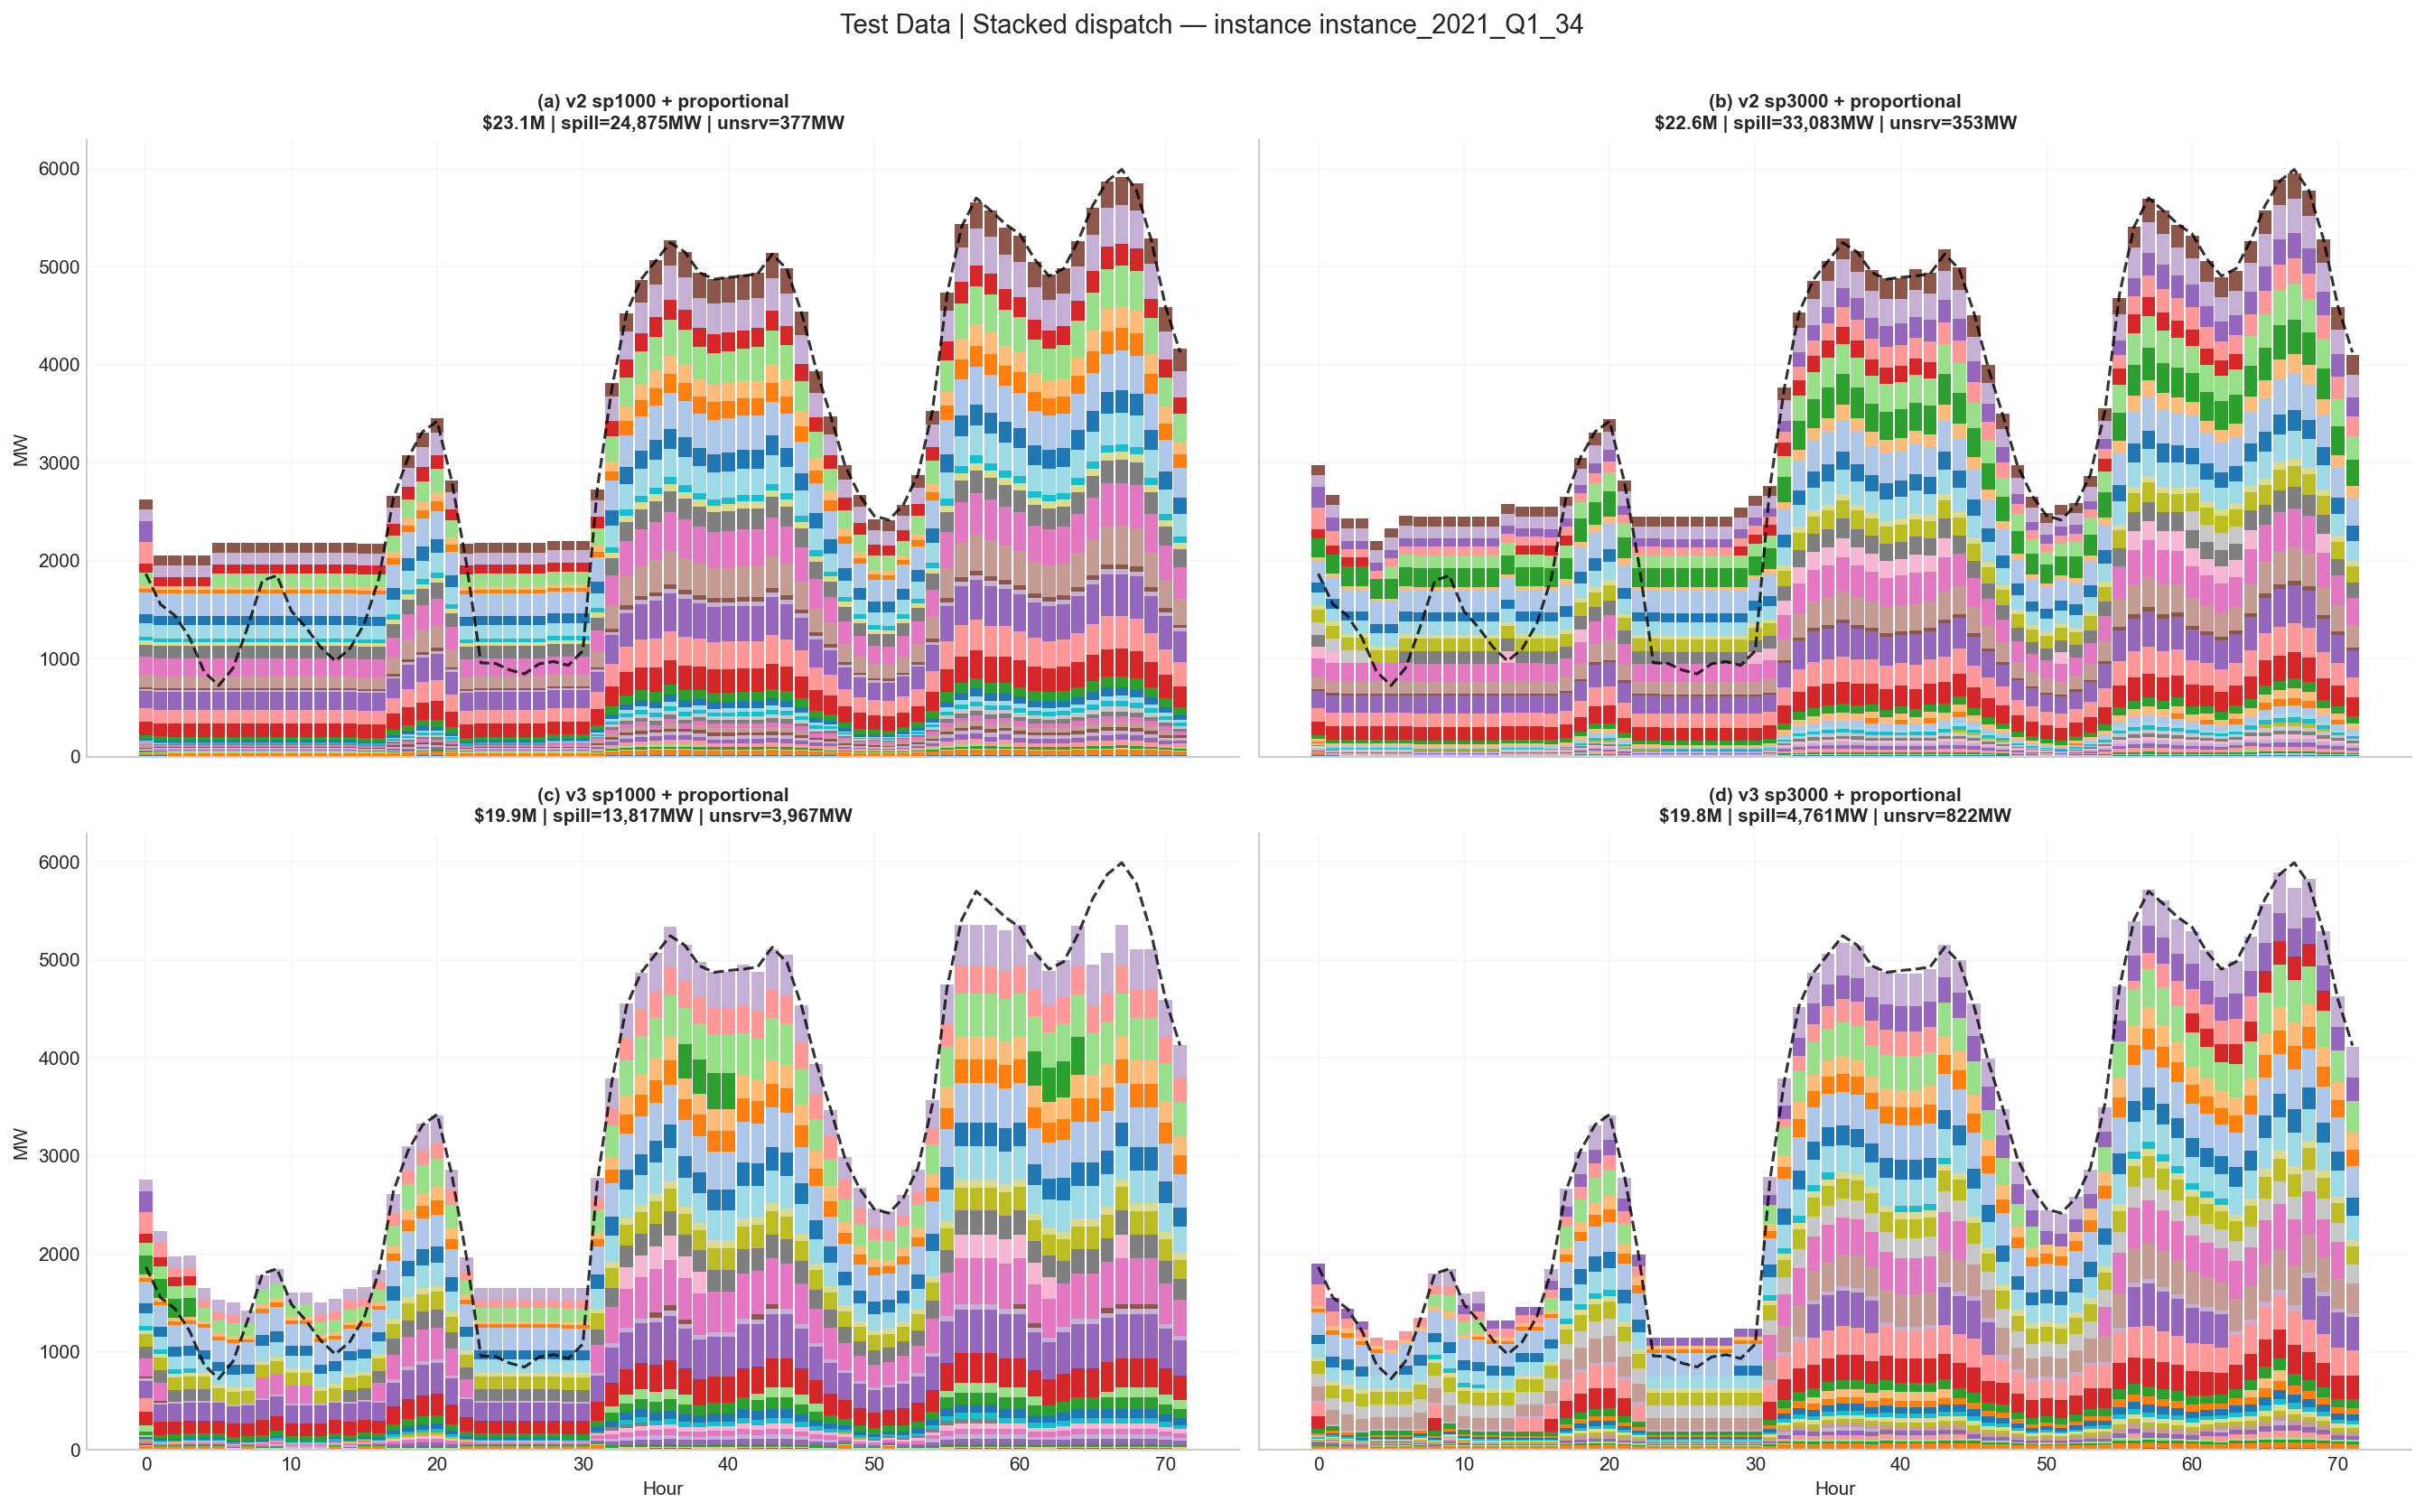

In [124]:
def plot_grid_dispatch(traces, env_obj, nrows=2, ncols=2,
                       instance_id="", data_label="Test Data"):
    """Generalised version of plot_3x3_dispatch — any set of (name, ed) keys."""
    keys = list(traces.keys())
    labels = "abcdefghijkl"
    fig, axes = plt.subplots(nrows, ncols, figsize=(9*ncols, 5.5*nrows),
                             sharex=True, sharey=True, squeeze=False)
    fig.suptitle(f"{data_label} | Stacked dispatch — instance {instance_id}",
                 fontsize=14, y=1.01)

    for idx, (ax, key) in enumerate(zip(axes.ravel(), keys)):
        tr = traces[key]
        hours = tr["hour"].values
        dm = np.vstack(tr["dispatch"].values)          # (72, 51)
        n_h, n_g = dm.shape

        cmap = plt.cm.tab20
        colors = [cmap(i % 20 / 20) for i in range(n_g)]
        bottom = np.zeros(n_h)
        for i in range(n_g):
            ax.bar(hours, dm[:, i], bottom=bottom, width=0.9,
                   color=colors[i], edgecolor="none")
            bottom += dm[:, i]

        ax.plot(hours, tr["net_demand"].values, "k--", lw=1.5, alpha=0.8)

        cost = tr["fuel_cost"].sum() + tr["startup_cost"].sum()
        ax.set_title(f"({labels[idx]}) {key[0]} + {key[1]}\n"
                     f"${cost/1e6:.1f}M | spill={tr['spill'].sum():,.0f}MW | "
                     f"unsrv={tr['unserved'].sum():,.0f}MW",
                     fontsize=10, fontweight="bold")
        ax.grid(True, alpha=0.15)

    for ax in axes.ravel()[len(keys):]:
        ax.axis("off")
    for ax in axes[:, 0]: ax.set_ylabel("MW")
    for ax in axes[-1, :]: ax.set_xlabel("Hour")
    plt.tight_layout()
    plt.savefig("figures/dispatch/stacked_state_comparison.png",
                dpi=300, bbox_inches="tight")
    plt.show()


# ---- bangun trace untuk empat model ----
def make_test_env(state, sp):
    if state == "v3":
        return UCOnlyEnvV3(test_episodes, spill_penalty=sp, reward_scale=1e5,
                           random_reset=False, seed=99, obs_window=72)
    return UCOnlyEnv(test_episodes, spill_penalty=sp, reward_scale=1e5,
                     random_reset=False, seed=99,
                     state_version=state, obs_window=72)

def as_policy(m):
    return lambda o: np.asarray(m.predict(o, deterministic=True)[0]).ravel()

MODELS = {
    "v2 sp1000": (as_policy(ppo_v2),  make_test_env("v2", 1000)),
    "v2 sp3000": (as_policy(ppo_v2b), make_test_env("v2", 3000)),
    "v3 sp1000": (as_policy(ppo_v3),  make_test_env("v3", 1000)),
    "v3 sp3000": (as_policy(ppo_v4), make_test_env("v3", 3000)),
}

ED_NAME = "proportional"          # satu ED saja, biar yang dibandingkan state-nya
INSTANCE_IDX = 1

Path("figures/dispatch").mkdir(parents=True, exist_ok=True)
traces_state = {}
for name, (pol, env_m) in MODELS.items():
    tr = apply_ed_to_uc(env_m, pol, ED_METHODS[ED_NAME], test_episodes, INSTANCE_IDX)
    traces_state[(name, ED_NAME)] = tr
    print(f"  {name:12s} | ${(tr['fuel_cost'].sum()+tr['startup_cost'].sum())/1e6:.2f}M | "
          f"spill={tr['spill'].sum():>8,.0f} | unsrv={tr['unserved'].sum():>7,.0f}")

plot_grid_dispatch(traces_state, env, nrows=2, ncols=2,
                   instance_id=test_episodes[INSTANCE_IDX]["instance_id"])

In [125]:
tr = traces_state[("v3 sp3000", "proportional")]
h = tr[tr["unserved"] > 0]
print(len(h), "jam dengan unserved")
print(h[["hour","required_mw","unserved","spill"]].head(10))

29 jam dengan unserved
    hour  required_mw   unserved  spill
1      1  1556.289551   2.459551    0.0
8      8  1797.926085   1.626085    0.0
9      9  1849.735960   2.727960    0.0
18    18  3052.902409   9.422409    0.0
19    19  3317.234520   3.754520    0.0
20    20  3424.283711  14.423711    0.0
21    21  2813.358420  38.928420    0.0
33    33  4530.796114  13.586114    0.0
34    34  4871.344729   6.104729    0.0
36    36  5246.207680  70.599680    0.0


## 18. Save Models & Results

In [ ]:
SAVE_DIR = Path("saved_models_v7new"); SAVE_DIR.mkdir(exist_ok=True)

with open(SAVE_DIR/"q_factored.pkl","wb") as f:
    pickle.dump({"Q_tables":[dict(q) for q in Q_tables],
                 "OBS_LO":OBS_LO,"OBS_HI":OBS_HI}, f)

torch.save({"state_dict":pol_net.state_dict(),
            "state_dim":STATE_DIM,"n_gen":env.n_gen},
           SAVE_DIR/"branching_dqn.pt")

ppo_model.save(SAVE_DIR/"ppo_uc")
# res_df.to_csv(SAVE_DIR/"results_3x3_50instances.csv", index=False)

print("Saved:")
for f in sorted(SAVE_DIR.iterdir()):
    print(f"  {f.name:40s} {f.stat().st_size/1024:.0f} KB")

Saved:
  branching_dqn.pt                         831 KB
  ppo_uc.zip                               445 KB
  q_factored.pkl                           91791 KB
  results_3x3_50instances.csv              59 KB


In [ ]:
SAVE_DIR = Path("saved_models_v7new"); SAVE_DIR.mkdir(exist_ok=True)

with open(SAVE_DIR/"q_factored.pkl","wb") as f:
    pickle.dump({"Q_tables":[dict(q) for q in Q_tables],
                 "OBS_LO":OBS_LO,"OBS_HI":OBS_HI}, f)

torch.save({"state_dict":pol_net.state_dict(),
            "state_dim":STATE_DIM,"n_gen":env.n_gen},
           SAVE_DIR/"branching_dqn.pt")

ppo_model.save(SAVE_DIR/"ppo_uc")
# res_df.to_csv(SAVE_DIR/"results_3x3_50instances.csv", index=False)

print("Saved:")
for f in sorted(SAVE_DIR.iterdir()):
    print(f"  {f.name:40s} {f.stat().st_size/1024:.0f} KB")

Saved:
  branching_dqn.pt                         831 KB
  ppo_uc.zip                               445 KB
  q_factored.pkl                           91791 KB
  results_3x3_50instances.csv              59 KB
